# 🏠 Predicting Property Prices in a Specific Location Using Machine Learning
### Capstone Project – 1 &nbsp;|&nbsp; Jupyter Notebook
---
# 1. Project Overview & Objectives

## 1.1 Project Title and Problem Statement

**Title:** *Predicting Property Prices in a Specific Location Using Machine Learning*

**Problem statement:** Given the physical, structural, quality and sale-related characteristics of a residential property, build a supervised **regression** model that predicts its sale price (`PropPrice`, in dollars) as accurately as possible, and identify which characteristics are most strongly associated with price.

| Item | Detail |
|---|---|
| Learning type | Supervised learning – regression |
| Target variable | `PropPrice` (sale price in dollars) |
| Success criterion | R² between 75 % and 85 % (above 85 % is better): the assignment's benchmark, not a statistically derived acceptance threshold |
| Secondary metrics | MAE and RMSE (reported in dollars) |
| Constraint from the brief | Do **not** drop any column except `PropertyID` Predictors are kept in every pipeline. A penalised model (Lasso) may shrink coefficients to zero by itself; that is model behaviour, not manual dropping.|
| Selection rule | Models are chosen by cross-validation on training data only; the test set is used for one final evaluation |

## 1.2 Business Problem

Pricing a property correctly matters to every party in a transaction:

* **Sellers** risk leaving money on the table (under-pricing) or leaving the property unsold (over-pricing).
* **Buyers** need to know whether an asking price is fair.
* **Agents and lenders** need a consistent, data-driven benchmark that complements human judgement.

A reliable model also helps explain *why* a property is priced as it is – for example how a higher quality finish, a larger living area or a particular neighbourhood is associated with value – which is useful for renovation and investment decisions. The model supports a valuation; it does not replace one.


## 1.3 Project Objectives

The project addresses eight objectives derived from the assignment brief. Each objective is linked to the corresponding analysis and evaluated using the evidence produced in the notebook.

| No. | Objective | Addressed in |
|---|---|---|
| 1 | Understand, validate and clean the property dataset | Section 3 |
| 2 | Handle missing values and distinguish structural absence from missing information | Sections 3 and 9 |
| 3 | Apply appropriate encoding and scaling to categorical and numerical predictors | Sections 3 and 9 |
| 4 | Conduct exploratory data analysis to identify characteristics associated with property prices | Sections 4–8 and 12 |
| 5 | Evaluate dimensionality reduction using PCA | Section 9 |
| 6 | Develop regression models to predict `PropPrice` | Section 10 |
| 7 | Compare, tune and evaluate regression models using cross-validation and held-out testing | Sections 10 and 11 |
| 8 | Present findings, interpret model predictions and communicate limitations | Sections 11 and 12 and the accompanying Word report |

**Scope.** All 79 original predictors are retained in the modelling framework, except the identifier `PropertyID`, in accordance with the assignment constraint. Regularisation may assign zero coefficients without manually removing source columns.

**Evidence standard.** Model-selection decisions are based on training-only validation. Held-out results are reported separately, with historical test-set exposure disclosed in Section 11.



## 1.4 Success Criteria

Model performance is evaluated using R², MAE and RMSE, with dollar-scale errors reported for practical interpretation.

| Criterion | Evaluation standard |
|---|---|
| Predictive accuracy | R² of 0.75–0.85 is the assignment benchmark; higher values are desirable |
| Primary generalisation estimate | Training-only cross-validation, with fold variability |
| Secondary evaluation | Held-out test performance, with bootstrap confidence intervals |
| Model comparison | Cross-validation performance, uncertainty, stability and model complexity |
| Data leakage | Learned preprocessing steps must be fitted inside the relevant training folds |
| Uncertainty | Prediction-interval coverage reported overall and by relevant subgroups |
| Reproducibility | Consistent data fingerprint, recorded dependencies, fixed seeds and successful full execution |
| Model portability | A saved pipeline must be reloadable and capable of producing consistent predictions in a fresh process |
| Reporting consistency | Every numerical claim must agree with the final executed outputs |

**Historical evaluation limitation.** An earlier Gradient Boosting model was evaluated on the held-out data before the final Lasso pipeline was selected. Consequently, the test set is not historically untouched. Training-only cross-validation is therefore treated as the primary estimate of expected generalisation, while the held-out result provides supplementary evidence.

**Interpretation.** Meeting the assignment's R² benchmark does not establish reliable performance across every price range, neighbourhood or future market.


## 1.5 Dataset and Citation

The data describe **one row per residential property sale** in Ames, Iowa, compiled by De Cock (2011), with the columns renamed. The file has `PropertyID`, 79 predictors and the target `PropPrice`; its exact shape is verified in Section 3. De Cock's full dataset holds more sales than this file, so the file is an extract, and the brief does not say how it was chosen.

**What was and was not supplied.** The brief lists `train.csv`, `test.csv`, `data_description.txt` and `sample_submission.csv`, but only one file was provided: the property data CSV. Two consequences:

* there is no ready-made test set, so the train / test split is made by us (Section 3);
* there is no metadata sheet, so the ordinal / nominal / binary classification is built by us and its order assumptions are stated openly (Section 3).

**Known issues to check.** The brief's data dictionary appears to contain errors. Each one is verified against the data and corrected in Section 3.2, not assumed:

* the seven columns `BasementType` to `BasementCond` appear to describe the **garage**. The brief's own names for some of them do not match the CSV, so Section 3.2 compares every name in the brief with the CSV columns in code;
* `Roof1Material` and `Roof2Material` appear to hold exterior-covering categories, and their spellings differ between the two columns;
* the brief's descriptions of `BsmntFinSty1` and `BsmntFinRat1` need checking against what the columns actually contain;
* `PropertyClass` and `SaleMon` are stored as numbers but are codes;
* the raw file uses the text `NA` for "feature absent" in many columns, so it must be read in a way that stops pandas silently turning it into a missing value.

**Reference**

De Cock, D. (2011). *Ames, Iowa: Alternative to the Boston Housing Data as an End of Semester Regression Project.* Journal of Statistics Education, 19(3). https://doi.org/10.1080/10691898.2011.11889627


## 1.6 Project Workflow

The methodology follows twelve sections, beginning with problem definition and data validation and ending with model interpretation, limitations and reporting.

The train/test split is created before exploratory analysis. Model selection and preprocessing comparisons are conducted using training data. The final estimator is evaluated on the held-out test partition, with historical exposure disclosed separately.

The workflow is organised as follows:

1. Project overview and objectives
2. Setup and configuration
3. Data understanding, quality and cleaning
4. Univariate analysis
5. Outliers, anomalies and influential observations
6. Distributional analysis of predictors
7. Bivariate associations with the target
8. Multicollinearity and redundancy
9. Preprocessing, encoding, scaling and PCA
10. Model building, comparison and tuning
11. Final held-out evaluation and uncertainty analysis
12. Explainability, error analysis, limitations and conclusion

The diagram describes the analytical process rather than presenting results. Numerical findings are reported in their respective sections and consolidated in the final conclusion.


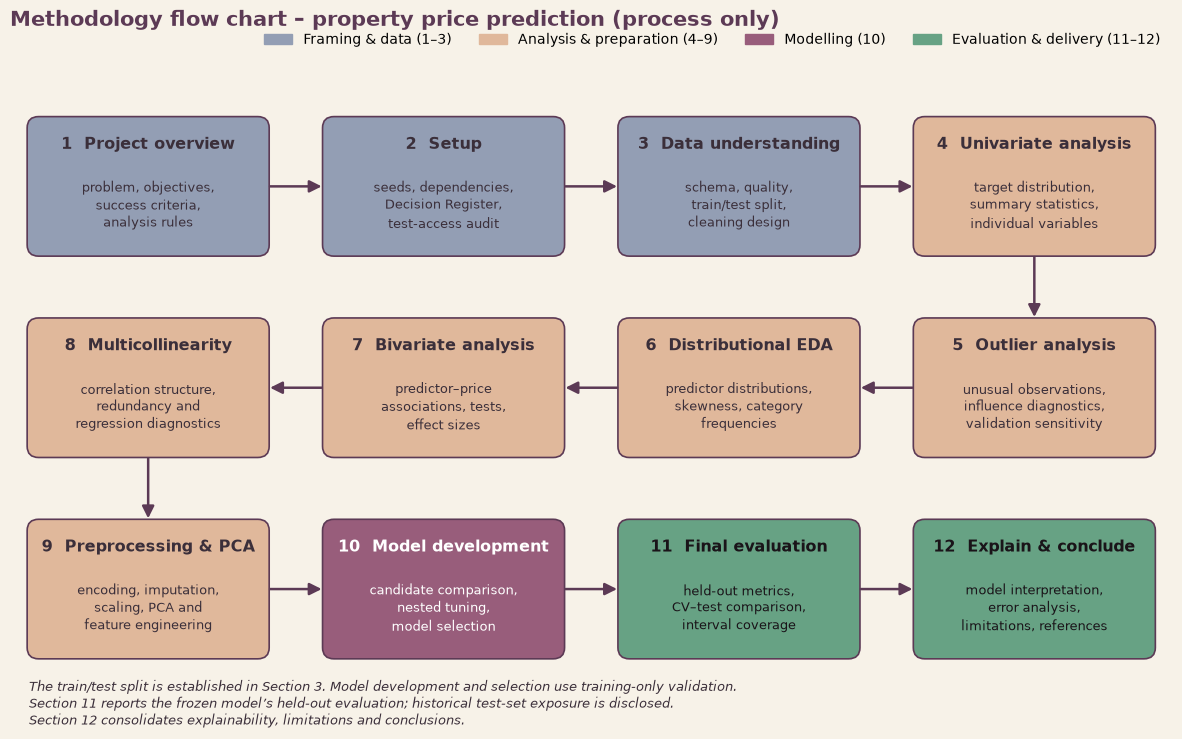

In [1]:
# ── Methodology flow chart (process only – no results) ────────
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from matplotlib.patches import FancyBboxPatch, FancyArrowPatch
from pathlib import Path

# Project colours. The full palette is defined formally in Section 2.4; the hex codes are repeated
# here only because this figure is drawn before the Setup section has run.
PHASE_COLOUR = {'data': '#939EB4', 'prep': '#E0B89B', 'model': '#985D7B', 'eval': '#67A284'}
PHASE_TEXT   = {'data': '#3B2F3A', 'prep': '#3B2F3A', 'model': 'white',   'eval': '#1A1419'}
EDGE, BG = '#5C3A55', '#F7F2E8'


steps = [
    ('1  Project overview',
     'problem, objectives,\nsuccess criteria,\nanalysis rules', 'data'),

    ('2  Setup',
     'seeds, dependencies,\nDecision Register,\ntest-access audit', 'data'),

    ('3  Data understanding',
     'schema, quality,\ntrain/test split,\ncleaning design', 'data'),

    ('4  Univariate analysis',
     'target distribution,\nsummary statistics,\nindividual variables', 'prep'),

    ('5  Outlier analysis',
     'unusual observations,\ninfluence diagnostics,\nvalidation sensitivity', 'prep'),

    ('6  Distributional EDA',
     'predictor distributions,\nskewness, category\nfrequencies', 'prep'),

    ('7  Bivariate analysis',
     'predictor–price\nassociations, tests,\neffect sizes', 'prep'),

    ('8  Multicollinearity',
     'correlation structure,\nredundancy and\nregression diagnostics', 'prep'),

    ('9  Preprocessing & PCA',
     'encoding, imputation,\nscaling, PCA and\nfeature engineering', 'prep'),

    ('10  Model development',
     'candidate comparison,\nnested tuning,\nmodel selection', 'model'),

    ('11  Final evaluation',
     'held-out metrics,\nCV–test comparison,\ninterval coverage', 'eval'),

    ('12  Explain & conclude',
     'model interpretation,\nerror analysis,\nlimitations, references', 'eval')
]

# snake layout: row 1 left→right, row 2 right→left, row 3 left→right
pos = [(c, 2) for c in range(4)] + [(3 - c, 1) for c in range(4)] + [(c, 0) for c in range(4)]
W, H, GX, GY = 2.5, 1.45, 3.1, 2.15

fig, ax = plt.subplots(figsize=(15, 9), facecolor=BG); ax.set_facecolor(BG)
ax.set_xlim(-0.2, 3 * GX + W + 0.2); ax.set_ylim(-0.75, 2 * GY + H + 0.9); ax.axis('off')
ax.set_title('Methodology flow chart – property price prediction (process only)', loc='left',
             fontsize=15, fontweight='bold', color=EDGE)

boxes = []
for (title, detail, phase), (cx, cy) in zip(steps, pos):
    x, y = cx * GX, cy * GY
    ax.add_patch(FancyBboxPatch((x, y), W, H, boxstyle='round,pad=0.02,rounding_size=0.12',
                                fc=PHASE_COLOUR[phase], ec=EDGE, lw=1.2))
    ax.text(x + W / 2, y + H - 0.28, title, ha='center', va='center', fontsize=11.5, fontweight='bold', color=PHASE_TEXT[phase])
    ax.text(x + W / 2, y + H / 2 - 0.2, detail, ha='center', va='center', fontsize=9.3, color=PHASE_TEXT[phase], linespacing=1.35)
    boxes.append((x, y))

def arrow(p, q):
    ax.add_patch(FancyArrowPatch(p, q, arrowstyle='-|>', mutation_scale=18, lw=1.8, color=EDGE, shrinkA=2, shrinkB=2))

for k in range(len(boxes) - 1):
    (x0, y0), (x1, y1) = boxes[k], boxes[k + 1]
    if y0 != y1:                                   # step down to the next row
        arrow((x0 + W / 2, y0), (x1 + W / 2, y1 + H))
    elif x1 > x0:                                  # left → right
        arrow((x0 + W, y0 + H / 2), (x1, y1 + H / 2))
    else:                                          # right → left
        arrow((x0, y0 + H / 2), (x1 + W, y1 + H / 2))

ax.legend(handles=[mpatches.Patch(color=PHASE_COLOUR[k], label=v) for k, v in
                   [('data', 'Framing & data (1–3)'), ('prep', 'Analysis & preparation (4–9)'),
                    ('model', 'Modelling (10)'), ('eval', 'Evaluation & delivery (11–12)')]],
          loc='upper right', ncol=4, frameon=False, bbox_to_anchor=(1.0, 1.02))

ax.text(
    0, -0.5,
    'The train/test split is established in Section 3. Model development and selection use training-only validation.\n'
    'Section 11 reports the frozen model’s held-out evaluation; historical test-set exposure is disclosed.\n'
    'Section 12 consolidates explainability, limitations and conclusions.',
    fontsize=9.5,
    color='#3B2F3A',
    va='center',
    style='italic'
)

Path('figures').mkdir(exist_ok=True)
fig.savefig(Path('figures') / '00_methodology_flowchart.png', dpi=150, bbox_inches='tight', facecolor=BG)
plt.show()


**Reading.** The workflow separates data preparation, exploratory analysis, model development and final evaluation. The train/test split is established in Section 3, while model comparison and selection occur in Section 10 using training-only validation.

Section 11 evaluates the frozen model and investigates predictive uncertainty and error patterns. Section 12 explains the selected model, examines feature stability, documents limitations and consolidates the conclusions.

The held-out partition was also evaluated in an earlier notebook version. This historical exposure is disclosed and prevents treating the final test score as a fully independent estimate.


## 1.7 Analysis Rules

The following ten principles govern data preparation, exploratory analysis, statistical testing, model development, evaluation and reporting. They establish a consistent framework for methodological transparency, reproducibility and evidence-based decision-making.

The analysis distinguishes between **exploratory findings**, **training-only validation evidence**, **held-out evaluation** and **post-hoc diagnostics**. Although several procedures were established before their respective analyses, others were refined after examining intermediate results. Therefore, the complete workflow is **not presented as prospectively preregistered**.

All material methodological decisions, including subsequent amendments, are documented in the **Decision Register (Section 2.7)**. Test-set access during the current execution is recorded separately from historical exposure. An earlier notebook version evaluated Gradient Boosting on the held-out partition; consequently, the final test set cannot be described as historically untouched.

| # | Rule | In practice |
|---|---|---|
| 1 | **Training-only learning and leakage prevention** | Exploratory statistics and model-development decisions use training observations. Every fitted preprocessing operation—including imputation, scaling, encoding, outlier treatment, PCA and feature selection—is learned within the relevant training folds through pipelines. The held-out test set is excluded from model fitting, tuning and feature-selection decisions in the current workflow. |
| 2 | **Transparent test-set access** | Test predictors may be inspected for documented split diagnostics, while target-bearing evaluations are recorded separately. The current execution's test-access log (Section 2.7) records its own accesses; it does not represent the complete historical record. An earlier Gradient Boosting evaluation achieved R² = 0.912 on the holdout. This prior exposure is explicitly disclosed, and the final test result is treated as supplementary rather than fully independent validation evidence. Post-hoc test diagnostics do not determine model selection. |
| 3 | **Four elements per analytical subsection** | Each substantive analysis follows **Research question → Method/test → Evidence → Decision**. Evidence includes relevant statistics, effect sizes, uncertainty estimates and visualisations. Decisions explain whether the findings justify an action or support retaining the existing approach. Material decisions and amendments are documented in the Decision Register. |
| 4 | **Statistical significance is not a feature-selection rule** | Hypothesis tests support interpretation and assessment of assumptions; statistical significance alone does not justify including or excluding predictors. Feature-treatment decisions require domain reasoning and training-only validation evidence. Because the assignment prohibits manually dropping predictors other than `PropertyID`, reduced-feature approaches are evaluated as diagnostic ablations rather than silently replacing the required full-feature model. |
| 5 | **Statistical methods must match the data** | Distributional assumptions are evaluated in the appropriate context. Target-distribution diagnostics are distinguished from regression-residual diagnostics. Welch ANOVA and Games–Howell comparisons are used where unequal variances warrant them. Effect sizes, confidence intervals and multiple-testing adjustments accompany hypothesis tests where appropriate. In-sample diagnostics are not presented as evidence of out-of-sample predictive performance. |
| 6 | **Model comparison prioritises generalisation and practical differences** | Candidate models are evaluated using training-only cross-validation, with dollar-scale RMSE and MAE as practical error measures alongside R². Hyperparameter tuning is separated from performance estimation using nested or otherwise appropriately isolated validation. Small numerical differences are not automatically interpreted as meaningful superiority. Final selection considers predictive performance, uncertainty, stability, interpretability and model complexity. Any prespecified adoption rule and its limitations are disclosed. |
| 7 | **Generalisation claims are limited to validated settings** | Repeated and nested cross-validation provide the principal evidence of expected performance under the evaluated random-split setting. Unseen-neighbourhood performance and forward-in-time prediction require separate grouped or chronological validation. Where these stress tests have not been executed, geographic transfer and future-market performance remain limitations rather than demonstrated capabilities. |
| 8 | **Target scales and uncertainty are explicitly labelled** | Log-scale and original dollar-scale predictions and metrics are distinguished throughout. Back-transformation uses the documented estimator and any applicable bias correction, including smearing where justified. Headline performance estimates are accompanied by uncertainty measures where calculated. Prediction intervals are evaluated against their stated nominal coverage, including subgroup coverage; overall calibration is not assumed to guarantee reliable coverage for expensive or unusual properties. |
| 9 | **Interpretations must not exceed the evidence** | Correlations, regression coefficients, permutation importance and partial-dependence analyses describe predictive associations, not causal effects. Exploratory results, confirmatory validation and post-hoc explanations are identified appropriately. Historical test exposure, post-hoc methodological amendments, subgroup instability and other material limitations are reported transparently. Conclusions are based on executed results rather than anticipated outcomes. |
| 10 | **Figures, tables and narrative must be internally consistent** | Every figure is checked for correct titles, units, axis labels, legends, readable text and truncation. Numerical interpretations, summary tables, decision records and conclusions must agree with the executed outputs. Draft placeholders, unsupported claims and outdated cross-references are corrected before submission. |

**Evaluation hierarchy.** The final model is selected using training-only evidence from Section 10. Section 11 provides the held-out evaluation and post-hoc error diagnostics, while Section 12 consolidates explainability, limitations and conclusions. Because the holdout was previously evaluated, **cross-validation remains the primary basis for expected generalisation performance**.

**Reproducibility standard.** The final submission must preserve the dataset fingerprint, random seeds, software dependencies, executed outputs and documented decisions. Independent model portability is claimed only after the complete fitted pipeline has been successfully saved, reloaded and tested in a fresh Python process.



## 1.8 Deliverables Checklist

The following table distinguishes the analytical work documented in this notebook from the separate files and execution checks required for final submission.


| Deliverable | Contents | Status |
|---|---|---|
| Jupyter notebook | Data preparation, EDA, statistical analysis, modelling, evaluation, explainability and conclusions | **Completed.** Fresh-kernel execution confirmed; final reproducibility audit passed (11/11 checks). |
| Project Summary Report | Nine-part Word report following the assignment requirements | **Pending.** To be prepared from the final executed notebook. |
| Saved model and importable module | Fitted Lasso pipeline, custom preprocessing transformers and independent-process prediction verification | **Completed and verified.** Model saved as `artifacts/final_lasso_pipeline.joblib`; custom module `property_pipeline.py` successfully imported; prediction differences were zero. |
| `requirements.txt` | Software dependencies and versions used in the analysis | Export workflow included in Section 2.9; generated file must be verified separately. |
| Run instructions | Steps to reproduce the notebook and load the saved model | Generation workflow included in Section 2.9; generated instructions must be verified separately. |
| Figures and supporting artifacts | Saved charts, analytical results and model-related outputs | Figure registry verified; individual exported files should be checked before submission. |
| Reproducibility verification | Dataset fingerprint, model portability, training alignment and validation artifacts | **Completed.** All 11 final audit checks passed. |


### Mapping of the Word Report to the Notebook

| Report requirement | Notebook source |
|---|---|
| Introduction | Sections 1.1–1.5 |
| Objectives | Section 1.3 |
| Flow chart | Section 1.6 |
| Python code | Sections 2–12 |
| Output screenshots | Verified executed notebook outputs |
| EDA report with graphs | Sections 4–8 |
| Learning outcomes | Final Learning Outcomes section |
| Conclusion | Section 12 |
| Citations | Final References section |

**Submission requirement.** A complete notebook export does not independently verify that the Word report, saved model or other generated artifacts have been submitted. Their completion must be confirmed separately


## 1.9 Notebook Roadmap

| Section | Title | Main purpose |
|---|---|---|
| 1 | Project Overview & Objectives | Define the prediction problem, assignment requirements and evaluation criteria |
| 2 | Setup & Configuration | Establish reproducibility, utilities, data provenance and audit records |
| 3 | Data Understanding, Quality & Cleaning | Inspect the dataset, establish the split and design missing-value and encoding treatment |
| 4 | Univariate Analysis | Examine individual variable distributions and the target |
| 5 | Outliers, Anomalies and Influential Points | Identify unusual observations and assess their treatment |
| 6 | Univariate and Distributional EDA of Predictors | Examine predictor distributions, skewness and category structure |
| 7 | Bivariate Associations with the Target | Assess predictor–price relationships using appropriate statistical methods |
| 8 | Multicollinearity and Redundancy | Examine correlated predictors and potential redundancy |
| 9 | Preprocessing Pipeline, Encoding, Scaling and PCA | Compare preprocessing strategies using validation evidence |
| 10 | Model Building, Comparison and Tuning | Compare candidate algorithms, tune hyperparameters and select the final model |
| 11 | Final Evaluation on the Held-Out Test Set | Report final metrics, uncertainty, residual patterns and prediction-interval coverage |
| 12 | Explainability, Error Analysis and Conclusion | Interpret the selected model, evaluate feature stability, document limitations and summarise findings |

**Evaluation sequence.** Section 10 selects the model using training-only evidence. Section 11 evaluates the frozen model. Section 12 provides post-hoc interpretation without changing the selected estimator.

**Deployment scope.** Independent model saving and reloading must be demonstrated before claiming that the model is portable or deployment-ready.


### What Section 1 Established

- The project predicts residential property sale prices using supervised regression.
- The assignment benchmark is R² of 0.75–0.85, with higher performance desirable.
- The supplied data require a reproducible train/test split and a documented predictor-metadata scheme.
- All original predictors are retained except the property identifier.
- Exploratory analysis and model development are separated from final held-out evaluation.
- Cross-validation is the principal generalisation evidence because the held-out data were evaluated in an earlier notebook version.
- Methodological decisions, including later amendments, are documented in the Decision Register.

**Next → Section 2: Setup & Configuration.** The next section establishes the software environment, random seeds, file provenance, reusable functions and audit infrastructure.


---
# 2. Setup & Configuration

This section is infrastructure. It makes the rest of the notebook reproducible, auditable and runnable in both Google Colab and VS Code. **No data values are read here**; the data file is only fingerprinted.

## 2.1 Libraries and Versions

**Research question.** Will this notebook run on the reader's machine, and which package versions produced the results?

**Method.** Versions are checked from package metadata *before* anything heavy is imported. Core packages have a minimum version; XGBoost and SHAP are optional because only Sections 10 and 11 use them.

**Decision.** If a core package is missing or too old, the cell stops and prints the `pip install` line to run. Warnings are **not** suppressed globally (decision D08).

In [2]:
# ── Environment check (before anything heavy is imported) ─────
import sys, platform
from importlib import metadata
from packaging.version import Version, InvalidVersion

MIN_PYTHON = (3, 10)
if sys.version_info < MIN_PYTHON:
    raise RuntimeError(f'Python {MIN_PYTHON[0]}.{MIN_PYTHON[1]}+ is required; this kernel runs {platform.python_version()}.')

# distribution name → (minimum version, what it is used for)
CORE_PACKAGES = {
    'numpy'        : ((1, 24), 'arrays and random numbers'),
    'pandas'       : ((2, 0),  'tables'),
    'scipy'        : ((1, 10), 'statistical tests'),
    'statsmodels'  : ((0, 14), 'OLS, diagnostics, multiple-testing corrections'),
    'scikit-learn' : ((1, 3),  'pipelines, models, cross-validation'),
    'matplotlib'   : ((3, 7),  'figures'),
    'seaborn'      : ((0, 12), 'figure themes and statistical plots'),
    'jinja2'       : ((3, 0),  'styled tables (pandas Styler)'),
    'joblib'       : ((1, 2),  'saving and loading the final pipeline'),
    'ipython'      : ((7, 0),  'rich notebook display'),
}
OPTIONAL_PACKAGES = {'xgboost': 'XGBoost model (Section 10)', 'shap': 'SHAP explanations (Section 11)'}

def installed_version(dist):
    try:
        return metadata.version(dist)
    except metadata.PackageNotFoundError:
        return None

def meets_minimum(version, min_tuple):
    """True if the installed version is at least min_tuple, comparing full Version objects.
    A pre-release such as 1.3rc1 does NOT meet a minimum of 1.3; an unparseable version never does."""
    try:
        return Version(version) >= Version('.'.join(map(str, min_tuple)))
    except InvalidVersion:
        return False

rows, problems = [], []
for dist, (min_v, role) in CORE_PACKAGES.items():
    v = installed_version(dist)
    if v is None:
        status = 'MISSING'; problems.append(dist)
    elif not meets_minimum(v, min_v):
        status = f'too old (needs ≥ {".".join(map(str, min_v))})'; problems.append(dist)
    else:
        status = 'ok'
    rows.append({'Package': dist, 'Installed': v or '—', 'Needed': '≥ ' + '.'.join(map(str, min_v)), 'Used for': role, 'Status': status})
for dist, role in OPTIONAL_PACKAGES.items():
    v = installed_version(dist)
    rows.append({'Package': dist, 'Installed': v or '—', 'Needed': 'optional', 'Used for': role,
                 'Status': 'ok' if v else 'not installed (only needed for that section)'})
if problems:
    raise ImportError('Install or upgrade: ' + ', '.join(problems) + '\nRun:  pip install --upgrade ' + ' '.join(problems))

# ── Imports ───────────────────────────────────────────────────
import os, json, random, hashlib, textwrap
from datetime import datetime
from pathlib import Path

import numpy as np
import pandas as pd
import scipy
from scipy import stats
import matplotlib
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from matplotlib.colors import LinearSegmentedColormap
import seaborn as sns
import sklearn
from IPython.display import display

print(f'Python {platform.python_version()}  |  {platform.system()} {platform.machine()}')
display(pd.DataFrame(rows).style.hide(axis='index'))
print('✅ Environment check passed.')

Python 3.14.3  |  Darwin arm64


Package,Installed,Needed,Used for,Status
numpy,2.5.0,≥ 1.24,arrays and random numbers,ok
pandas,3.0.3,≥ 2.0,tables,ok
scipy,1.18.0,≥ 1.10,statistical tests,ok
statsmodels,0.14.6,≥ 0.14,"OLS, diagnostics, multiple-testing corrections",ok
scikit-learn,1.9.0,≥ 1.3,"pipelines, models, cross-validation",ok
matplotlib,3.11.0,≥ 3.7,figures,ok
seaborn,0.13.2,≥ 0.12,figure themes and statistical plots,ok
jinja2,3.1.6,≥ 3.0,styled tables (pandas Styler),ok
joblib,1.6.0,≥ 1.2,saving and loading the final pipeline,ok
ipython,9.14.1,≥ 7.0,rich notebook display,ok


✅ Environment check passed.


**Reading.** Every core package should show `ok`. An optional package marked "not installed" is not an error; it only matters when its section is reached. These versions are what produced this run's numbers and are exported to `requirements.txt` in Section 2.9.

## 2.2 Reproducibility: Seeds and Run Environment

**Research question.** Can another run, on another machine, reproduce the numbers?

**Method.** One **named seed per purpose** (split, folds, repeated CV, tuning, bootstrap, permutation, leakage audit), so unrelated random choices are not coupled. The tuning seed deliberately differs from the scoring seed. The cell also detects whether it runs in Colab or VS Code.

**Decision.** Seeds live in `SEEDS`. Re-running on the same machine, data and package versions is expected
to reproduce the numbers. Across operating systems, CPUs or library
builds, and with parallel jobs, small numerical differences are
possible, so results are compared within a stated tolerance. The final
Restart & Run All checks this (D06).

In [3]:
# ── Named seeds: one per purpose ──────────────────────────────
SEEDS = {
    'global'        : 42,      # python / numpy defaults
    'split'         : 205,      # train / test split (Section 3)
    'cv'            : 17,      # cross-validation folds
    'repeated_cv'   : 2026,    # repeated K-fold (Section 10)
    'tuning'        : 7,       # hyper-parameter search splits, kept different from the scoring folds
    'bootstrap'     : 123,     # bootstrap confidence intervals
    'permutation'   : 99,      # permutation importance and tests
    'shuffle_audit' : 314,     # target-shuffle leakage audit (Section 12)
}
RANDOM_STATE = SEEDS['global']

def set_global_seed(seed=RANDOM_STATE):
    random.seed(seed)
    np.random.seed(seed)
    os.environ['PYTHONHASHSEED'] = str(seed)   # only affects child processes; the running interpreter's hash seed is fixed at start-up

def make_rng(name):
    """A fresh numpy Generator for a named purpose, e.g. make_rng('bootstrap')."""
    return np.random.default_rng(SEEDS[name])

set_global_seed()

# ── Where is this notebook running? ───────────────────────────
IN_COLAB  = 'google.colab' in sys.modules
IN_VSCODE = os.environ.get('TERM_PROGRAM') == 'vscode' or any(k.startswith('VSCODE_') for k in os.environ)
RUN_ENV   = 'Google Colab' if IN_COLAB else 'VS Code' if IN_VSCODE else 'Jupyter / other'
N_JOBS    = -1                                    # use all cores where a model supports it
RUN_STAMP = datetime.now().strftime('%Y-%m-%d %H:%M')

print(f'Run environment : {RUN_ENV}   |   started {RUN_STAMP}')
display(pd.DataFrame({'Purpose': ['global', 'split', 'cv', 'repeated_cv', 'tuning', 'bootstrap', 'permutation', 'shuffle_audit'],
                      'Seed': [SEEDS[k] for k in ['global', 'split', 'cv', 'repeated_cv', 'tuning', 'bootstrap', 'permutation', 'shuffle_audit']]}).style.hide(axis='index'))

Run environment : VS Code   |   started 2026-10-15 15:34


Purpose,Seed
global,42
split,205
cv,17
repeated_cv,2026
tuning,7
bootstrap,123
permutation,99
shuffle_audit,314


## 2.3 Paths, Data File and Output Folders

**Research question.** How do we find the data file in both Colab and VS Code, and know it is the same file in every run?

**Method.** The data CSV is found by (1) the `PROPERTY_DATA_PATH` environment variable if set, otherwise (2) a search of the notebook folder, `./data`, the parent folder and the usual Colab folders. If several copies match, their contents are compared. The file is fingerprinted with **SHA-256**. The cell also creates the output folders and defines `save_fig()`, which records every figure in a registry for the Word report.

**Decision.** The fingerprint, not the file name, identifies the data, because uploads rename files (D07). The file is **not read** here; Section 3 reads it and checks the fingerprint again.

In [4]:
# ── Output folders ────────────────────────────────────────────
PROJECT_DIR = Path.cwd()
FIG_DIR, ARTIFACT_DIR, REPORT_DIR = PROJECT_DIR / 'figures', PROJECT_DIR / 'artifacts', PROJECT_DIR / 'report_assets'
for _d in (FIG_DIR, ARTIFACT_DIR, REPORT_DIR):
    _d.mkdir(exist_ok=True)

# ── Locate the data file (works in Colab and in VS Code) ──────
DATA_GLOB   = 'Property_data*.csv'
SEARCH_DIRS = [PROJECT_DIR, PROJECT_DIR / 'data', PROJECT_DIR.parent, Path('/content'), Path('/content/drive/MyDrive')]

def sha256_of(path, chunk=1 << 20):
    h = hashlib.sha256()
    with open(path, 'rb') as fh:
        for block in iter(lambda: fh.read(chunk), b''):
            h.update(block)
    return h.hexdigest()

def find_data_file():
    # 1) an explicit override always wins: set PROPERTY_DATA_PATH to the CSV
    override = os.environ.get('PROPERTY_DATA_PATH')
    if override:
        p = Path(override).expanduser()
        if not p.is_file():
            raise FileNotFoundError(f'PROPERTY_DATA_PATH points to {p}, but no file exists there.')
        return p
    # 2) otherwise look next to the notebook, in ./data, one folder up, and in the usual Colab folders
    hits, seen = [], set()
    for d in SEARCH_DIRS:
        if d.is_dir():
            for f in sorted(d.glob(DATA_GLOB)):
                if f.resolve() not in seen:
                    seen.add(f.resolve()); hits.append(f)
    if not hits:
        raise FileNotFoundError(
            f'No file matching {DATA_GLOB!r} was found in: ' + ', '.join(str(d) for d in SEARCH_DIRS) + '.\n'
            '  • VS Code: put the CSV in the same folder as this notebook, or set PROPERTY_DATA_PATH.\n'
            '  • Colab: upload the CSV with the Files panel (it lands in /content).')
    if len(hits) > 1:
        hashes = {h: sha256_of(h) for h in hits}
        if len(set(hashes.values())) > 1:
            raise RuntimeError('Several matching CSV files with DIFFERENT contents were found:\n'
                               + '\n'.join(f'  {h}  (SHA-256 {s[:12]}…)' for h, s in hashes.items())
                               + '\nSet PROPERTY_DATA_PATH to the file you want to use.')
        print(f'ℹ️ {len(hits)} identical copies found; using {hits[0]}')
    return hits[0]

DATA_PATH   = find_data_file()
DATA_BYTES  = DATA_PATH.stat().st_size
DATA_SHA256 = sha256_of(DATA_PATH)
print('Data file :', DATA_PATH.name)
print(f'Size      : {DATA_BYTES:,} bytes')
print('SHA-256   :', DATA_SHA256)
print('(The file is only fingerprinted here. It is read, and its content checked, in Section 3.)')

# ── Figure saving, with a registry for the report ─────────────
FIG_REGISTRY = {}

def _figure_title(fig):
    for ax in fig.axes:
        for loc in ('left', 'center'):
            t = ax.get_title(loc=loc)
            if t:
                return t
    return ''

def save_fig(fig, name, section=None, dpi=150):
    """Save a figure to figures/<name>.png and record it in FIG_REGISTRY (re-running overwrites, never duplicates)."""
    path = FIG_DIR / f'{name}.png'
    fig.savefig(path, dpi=dpi, bbox_inches='tight')
    FIG_REGISTRY[name] = {'Figure': name, 'Section': section or '', 'Title': _figure_title(fig), 'KB': round(path.stat().st_size / 1024)}
    return path

def register_existing_figure(name, section, title):
    path = FIG_DIR / f'{name}.png'
    if not path.is_file():
        raise FileNotFoundError(f'{path} does not exist; run the cell that draws it first.')
    FIG_REGISTRY[name] = {'Figure': name, 'Section': section, 'Title': title, 'KB': round(path.stat().st_size / 1024)}

register_existing_figure('00_methodology_flowchart', '1', 'Methodology flow chart – property price prediction (process only)')
print(f'Folders: {FIG_DIR.name}/  {ARTIFACT_DIR.name}/  {REPORT_DIR.name}/   |   figures registered so far: {len(FIG_REGISTRY)}')

Data file : Property_data (1) (1).csv
Size      : 462,245 bytes
SHA-256   : fec7e9f5edadfae5f99133e93d4802f825aee24c281d246a5cdfe0d3eab81203
(The file is only fingerprinted here. It is read, and its content checked, in Section 3.)
Folders: figures/  artifacts/  report_assets/   |   figures registered so far: 1


## 2.4 Colour Palette and Plot Theme

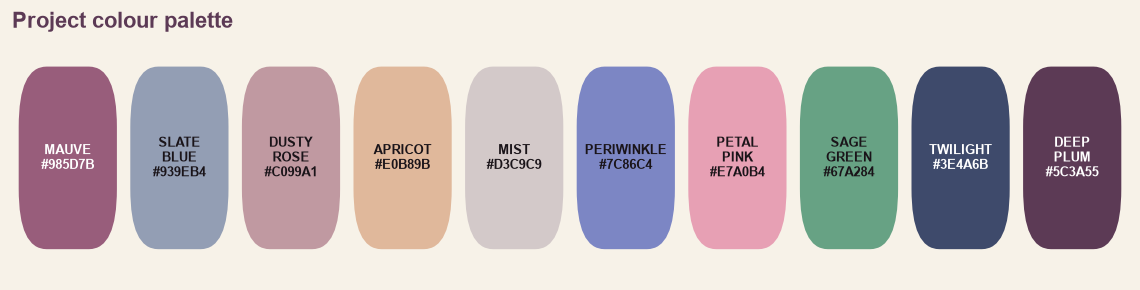

✅ Palette and plot theme configured.


In [5]:
# ── Colour palette (pressed-leaf reference image + complements) ─
# 5 swatches taken straight from the image
MAUVE        = '#985D7B'
SLATE_BLUE   = '#939EB4'
DUSTY_ROSE   = '#C099A1'
APRICOT      = '#E0B89B'
MIST         = '#D3C9C9'
# 2 colours sampled from the leaves
PERIWINKLE   = '#7C86C4'
PETAL_PINK   = '#E7A0B4'
# 3 complementary colours
SAGE_GREEN   = '#67A284'   # complement of MAUVE
TWILIGHT     = '#3E4A6B'   # complement of APRICOT (deepened for contrast)
DEEP_PLUM    = '#5C3A55'   # dark anchor (from the violet leaf strips)

# Neutrals
CREAM = '#F7F2E8'          # page/background colour of the reference image
INK   = '#3B2F3A'          # text colour
GRID  = '#E6DED5'

# Main working palettes
CATEGORY_PALETTE = [MAUVE, SLATE_BLUE, APRICOT, SAGE_GREEN, DUSTY_ROSE, TWILIGHT, PERIWINKLE, PETAL_PINK]
PALETTE = [DEEP_PLUM, MAUVE, PERIWINKLE, SAGE_GREEN, APRICOT, SLATE_BLUE,
           DUSTY_ROSE, TWILIGHT, PETAL_PINK, MIST]

# ── Display options and global plot style ─────────────────────
pd.set_option('display.max_columns', 100)
pd.set_option('display.max_rows', 120)
pd.set_option('display.width', 200)

sns.set_theme(style='whitegrid', palette=CATEGORY_PALETTE, font_scale=1.05)
plt.rcParams.update({
    'figure.facecolor'  : CREAM,
    'axes.facecolor'    : CREAM,
    'savefig.facecolor' : CREAM,
    'axes.edgecolor'    : MIST,
    'axes.titlesize'    : 13,
    'axes.titleweight'  : 'bold',
    'axes.labelsize'    : 11,
    'xtick.labelsize'   : 10,
    'ytick.labelsize'   : 10,
    'text.color'        : INK,
    'axes.labelcolor'   : INK,
    'xtick.color'       : INK,
    'ytick.color'       : INK,
    'axes.titlecolor'   : DEEP_PLUM,
    'grid.color'        : GRID,
    'figure.figsize'    : (12, 5),
    'figure.dpi'        : 120,
    'axes.spines.top'   : False,
    'axes.spines.right' : False,
})

# ── Custom colormaps (defined once, reused everywhere) ─────────
bloom_div  = LinearSegmentedColormap.from_list('bloom_div',  [SAGE_GREEN, '#F1ECE4', MAUVE], N=256)
bloom_seq  = LinearSegmentedColormap.from_list('bloom_seq',  [CREAM, PETAL_PINK, MAUVE, DEEP_PLUM], N=256)
bloom_cool = LinearSegmentedColormap.from_list('bloom_cool', [CREAM, SLATE_BLUE, PERIWINKLE, TWILIGHT], N=256)
bloom_warm = LinearSegmentedColormap.from_list('bloom_warm', [CREAM, APRICOT, DUSTY_ROSE, MAUVE], N=256)
bloom_rev  = bloom_seq.reversed()

# ── Show the palette ──────────────────────────────────────────
names = ['MAUVE', 'SLATE_BLUE', 'DUSTY_ROSE', 'APRICOT', 'MIST', 'PERIWINKLE', 'PETAL_PINK', 'SAGE_GREEN', 'TWILIGHT', 'DEEP_PLUM']
cols  = [MAUVE, SLATE_BLUE, DUSTY_ROSE, APRICOT, MIST, PERIWINKLE, PETAL_PINK, SAGE_GREEN, TWILIGHT, DEEP_PLUM]

def _rel_lum(hex_):
    ch = [int(hex_[i:i + 2], 16) / 255 for i in (1, 3, 5)]
    ch = [c / 12.92 if c <= 0.03928 else ((c + 0.055) / 1.055) ** 2.4 for c in ch]
    return 0.2126 * ch[0] + 0.7152 * ch[1] + 0.0722 * ch[2]

def contrast(a, b):
    """WCAG contrast ratio between two hex colours (4.5 or more is the usual minimum for normal text)."""
    hi, lo = sorted((_rel_lum(a), _rel_lum(b)), reverse=True)
    return (hi + 0.05) / (lo + 0.05)

def best_text(fill, dark='#1A1419', light='#FFFFFF'):
    """Whichever of the dark / light text colours has more contrast against the fill."""
    return dark if contrast(dark, fill) >= contrast(light, fill) else light

fig, ax = plt.subplots(figsize=(12, 2.6))
for i, (n, c) in enumerate(zip(names, cols)):
    ax.add_patch(mpatches.FancyBboxPatch((i + 0.06, 0.12), 0.88, 0.76,
                 boxstyle='round,pad=0,rounding_size=0.25', fc=c, ec='none'))
    label = n.replace('_', '\n') + '\n' + c            # built outside an f-string: backslashes inside f-string braces fail on Python < 3.12
    ax.text(i + 0.5, 0.5, label, ha='center', va='center', fontsize=8,
            color=best_text(c), fontweight='bold')
ax.set_xlim(0, len(cols)); ax.set_ylim(0, 1); ax.axis('off')
ax.set_title('Project colour palette', loc='left')
save_fig(fig, '01_palette', section='2'); plt.show()
print('✅ Palette and plot theme configured.')

## 2.5 Helper Functions

**Research question.** Which small, reusable tools will every later section need, and can they be trusted?

**Method.** Helpers are defined once and tested in 2.8 against values worked out by hand.

| Group | Helpers | Convention |
|---|---|---|
| Metrics | `regression_metrics` | R², adjusted R², MAE, MSE, RMSE, MAPE, median AE, RMSLE; units follow the inputs (dollars or log) |
| Log target | `to_log`, `duan_smearing`, `to_dollars` | Naive back-transform estimates a *median* price; smearing moves it approximately towards the *mean* if residual spread is similar across properties (D10) |
| Uncertainty | `bootstrap_ci`, `fisher_z_ci` | Bootstrap resamples rows jointly; Fisher-z is for Pearson only |
| Effect sizes | `cohens_d`, `hedges_g`, `eta_squared`, `epsilon_squared_kw`, `cramers_v`, `effect_label` | Labels are **conventions**, printed beside the number (D09) |
| Formatting | `fmt_money`, `fmt_pct`, `fmt_p`, `fmt_ci`, `show_table` | One table style across the notebook |

**Decision.** Analysis helpers stay in the notebook so they appear in the report. Code the saved pipeline needs goes into an importable module later (D11).

In [6]:
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error, median_absolute_error

# ══ Metrics ═══════════════════════════════════════════════════
def regression_metrics(y_true, y_pred, n_features=None):
    """R², adjusted R², MAE, MSE, RMSE, MAPE, median AE and RMSLE for one set of predictions.
    Units follow the inputs: pass dollars for dollar metrics, log values for log-scale metrics.
    Adjusted R² needs n_features; for penalised or tree models it is only indicative."""
    yt, yp = np.asarray(y_true, dtype=float), np.asarray(y_pred, dtype=float)
    if yt.ndim != 1 or yt.shape != yp.shape:
        raise ValueError(f'y_true and y_pred must be 1-D arrays of equal length (got {yt.shape} and {yp.shape}).')
    if not (np.isfinite(yt).all() and np.isfinite(yp).all()):
        raise ValueError('y_true / y_pred contain NaN or infinite values.')
    n, r2, mse = len(yt), r2_score(yt, yp), mean_squared_error(yt, yp)
    adj   = np.nan if (n_features is None or n - n_features - 1 <= 0) else 1 - (1 - r2) * (n - 1) / (n - n_features - 1)
    mape  = np.mean(np.abs((yt - yp) / yt)) * 100 if (yt != 0).all() else np.nan
    rmsle = np.sqrt(np.mean((np.log1p(yt) - np.log1p(yp)) ** 2)) if (yt >= 0).all() and (yp >= 0).all() else np.nan
    return {'R²': r2, 'Adj. R²': adj, 'MAE': mean_absolute_error(yt, yp), 'MSE': mse, 'RMSE': float(np.sqrt(mse)),
            'MAPE (%)': mape, 'Median AE': median_absolute_error(yt, yp), 'RMSLE': rmsle}

# ══ Log target and back-transformation ════════════════════════
def to_log(y, kind='log'):
    """Natural log of the target. 'log' needs y > 0; 'log1p' needs y > -1. NaN and infinite values are rejected."""
    if kind not in ('log', 'log1p'):
        _bad_kind()
    y = np.asarray(y, dtype=float)
    if not np.isfinite(y).all():
        raise ValueError('y contains NaN or infinite values.')
    if kind == 'log' and not (y > 0).all():
        raise ValueError("kind='log' needs every value to be greater than 0.")
    if kind == 'log1p' and not (y > -1).all():
        raise ValueError("kind='log1p' needs every value to be greater than -1.")
    return np.log(y) if kind == 'log' else np.log1p(y)

def duan_smearing(residuals_log):
    """Smearing factor for the exp() back-transformation: mean(exp(residual)), residual = actual_log − predicted_log.
    Compute it from out-of-fold training residuals, never from test residuals.
    Limitation: one global factor assumes the retransformation bias is similar for every property. If the residual spread
    changes with predicted price, the factor is too high for some properties and too low for others (checked in Section 10)."""
    r = np.asarray(residuals_log, dtype=float)
    if r.size == 0 or not np.isfinite(r).all():
        raise ValueError('residuals_log must be a non-empty array without NaN or infinite values.')
    return float(np.mean(np.exp(r)))

def to_dollars(pred_log, smear=1.0, kind='log'):
    """Back-transform log-scale predictions to dollars. smear=1.0 is the naive back-transform, which estimates the
    median price; a smearing factor above 1 moves it approximately towards the mean price (assuming similar residual spread across properties). smear must be one finite, positive number."""
    if kind not in ('log', 'log1p'):
        _bad_kind()
    if np.ndim(smear) != 0 or not np.isfinite(smear) or smear <= 0:
        raise ValueError('smear must be a single finite number greater than 0.')
    z = np.asarray(pred_log, dtype=float)
    if not np.isfinite(z).all():
        raise ValueError('pred_log contains NaN or infinite values.')
    with np.errstate(over='ignore'):
        out = smear * np.exp(z) if kind == 'log' else smear * np.exp(z) - 1.0
    if not np.isfinite(out).all():
        raise ValueError('Back-transformation overflowed: some log predictions are implausibly large.')
    return out

def _bad_kind():
    raise ValueError("kind must be 'log' or 'log1p'")

# ══ Uncertainty ═══════════════════════════════════════════════
def bootstrap_ci(stat_fn, *arrays, n_boot=2000, alpha=0.05, seed=None, on_invalid='raise', max_invalid_frac=0.05):
    """Percentile bootstrap CI. Rows are resampled jointly across all arrays, so paired statistics
    (R², MAE, a correlation) keep their pairing. Returns estimate, lower, upper, bootstrap SE and n_invalid.
    on_invalid: 'raise' (default) stops on any NaN/infinite resample statistic; 'drop' discards them, reports
    n_invalid, and still raises if more than max_invalid_frac of the resamples are invalid."""
    if not callable(stat_fn) or not arrays:
        raise ValueError('Pass a callable stat_fn and at least one array.')
    if not (0 < alpha < 1):
        raise ValueError('alpha must be between 0 and 1 (exclusive).')
    if not (isinstance(n_boot, (int, np.integer)) and n_boot >= 2):
        raise ValueError('n_boot must be an integer of at least 2.')
    if on_invalid not in ('raise', 'drop'):
        raise ValueError("on_invalid must be 'raise' or 'drop'.")
    arrays = [np.asarray(a) for a in arrays]
    n = len(arrays[0])
    if n == 0:
        raise ValueError('Arrays must not be empty.')
    if any(len(a) != n for a in arrays):
        raise ValueError('All arrays must have the same length.')
    estimate = float(stat_fn(*arrays))
    if not np.isfinite(estimate):
        raise ValueError('The statistic is not finite on the original data.')
    rng = np.random.default_rng(SEEDS['bootstrap'] if seed is None else seed)
    idx = rng.integers(0, n, size=(n_boot, n))
    boots = np.array([stat_fn(*[a[i] for a in arrays]) for i in idx], dtype=float)
    valid = np.isfinite(boots)
    n_invalid = int((~valid).sum())
    if n_invalid and (on_invalid == 'raise' or n_invalid / n_boot > max_invalid_frac):
        raise ValueError(f'{n_invalid} of {n_boot} bootstrap statistics were NaN or infinite '
                         f"(policy: on_invalid='{on_invalid}', max_invalid_frac={max_invalid_frac}).")
    boots = boots[valid]
    lo, hi = np.percentile(boots, [100 * alpha / 2, 100 * (1 - alpha / 2)])
    return {'estimate': estimate, 'lo': float(lo), 'hi': float(hi), 'se': float(np.std(boots, ddof=1)),
            'n_boot': n_boot, 'n_invalid': n_invalid}

def fisher_z_ci(r, n, alpha=0.05):
    """Fisher-z confidence interval for a PEARSON correlation (assumes roughly bivariate-normal data).
    For Spearman or skewed data use bootstrap_ci instead."""
    if n <= 3:
        raise ValueError('n must be greater than 3.')
    if not (-1 < r < 1):
        raise ValueError('r must be strictly between -1 and 1.')
    z, se = np.arctanh(r), 1 / np.sqrt(n - 3)
    crit = stats.norm.ppf(1 - alpha / 2)
    return float(np.tanh(z - crit * se)), float(np.tanh(z + crit * se))

# ══ Effect sizes ══════════════════════════════════════════════
def cohens_d(x, y):
    """Standardised mean difference using the pooled SD (positive when mean(x) > mean(y))."""
    x, y = np.asarray(x, float), np.asarray(y, float)
    n1, n2 = len(x), len(y)
    if n1 < 2 or n2 < 2:
        raise ValueError('Each group needs at least 2 observations.')
    if not (np.isfinite(x).all() and np.isfinite(y).all()):
        raise ValueError('x and y must not contain NaN or infinite values.')
    sp = np.sqrt(((n1 - 1) * x.var(ddof=1) + (n2 - 1) * y.var(ddof=1)) / (n1 + n2 - 2))
    return float((x.mean() - y.mean()) / sp) if sp > 0 else np.nan

def hedges_g(x, y):
    """Cohen's d with the small-sample correction."""
    n = len(x) + len(y)
    return cohens_d(x, y) * (1 - 3 / (4 * n - 9))

def eta_squared(*groups):
    """Share of total variance explained by group membership (one-way ANOVA effect size)."""
    groups = [np.asarray(g, float) for g in groups]
    allv = np.concatenate(groups); gm = allv.mean()
    ssb = sum(len(g) * (g.mean() - gm) ** 2 for g in groups)
    sst = ((allv - gm) ** 2).sum()
    return float(ssb / sst) if sst > 0 else np.nan

def epsilon_squared_kw(H, n):
    """Epsilon-squared for a Kruskal–Wallis test: H / (n − 1) = H(n + 1) / (n² − 1).
    Source: Tomczak & Tomczak (2014), Trends in Sport Sciences 21(1), 19–25; after Kelley (1935).
    Not the same as eta_squared_h(), which also uses the number of groups."""
    if n < 2:
        raise ValueError('n must be at least 2')
    return float(H / (n - 1))

def eta_squared_h(H, n, k):
    """Eta-squared based on H: (H − k + 1) / (n − k). Source: Tomczak & Tomczak (2014).
    n = total observations, k = number of groups."""
    if k < 2 or n <= k:
        raise ValueError('need k >= 2 groups and n > k')
    return float((H - k + 1) / (n - k))

def cramers_v(table):
    """Cramér's V for a contingency table (uncorrected chi-square). df_star = min(rows, columns) − 1."""
    t = np.asarray(table, float)
    if t.ndim != 2 or min(t.shape) < 2:
        raise ValueError('table must be 2-D with at least 2 rows and 2 columns.')
    if not np.isfinite(t).all() or (t < 0).any():
        raise ValueError('table must contain finite, non-negative counts.')
    chi2, p, dof, _ = stats.chi2_contingency(t, correction=False)
    k = min(t.shape) - 1
    return {'V': float(np.sqrt(chi2 / (t.sum() * k))), 'chi2': float(chi2), 'p': float(p), 'dof': int(dof), 'df_star': k}

def cramers_v_corrected(table):
    """Bias-corrected Cramér's V (Bergsma 2013). The uncorrected V is biased upwards for sparse tables
    (many rare categories), so report this beside cramers_v() in Section 6."""
    t = np.asarray(table, float)
    if t.ndim != 2 or min(t.shape) < 2:
        raise ValueError('table must be 2-D with at least 2 rows and 2 columns.')
    if not np.isfinite(t).all() or (t < 0).any():
        raise ValueError('table must contain finite, non-negative counts.')
    n = t.sum()
    if n <= 1:
        raise ValueError('table must contain more than one observation.')
    r, c = t.shape
    chi2 = stats.chi2_contingency(t, correction=False)[0]
    phi2 = max(0.0, chi2 / n - (r - 1) * (c - 1) / (n - 1))
    r_adj, c_adj = r - (r - 1) ** 2 / (n - 1), c - (c - 1) ** 2 / (n - 1)
    d = min(r_adj - 1, c_adj - 1)
    return float(np.sqrt(phi2 / d)) if d > 0 else np.nan

# Labels are CONVENTIONS (Cohen-style rules of thumb), not facts about the data. Always print the number next to the label.
EFFECT_CUTS = {'d': (0.2, 0.5, 0.8), 'g': (0.2, 0.5, 0.8), 'r': (0.1, 0.3, 0.5),
               'eta2': (0.01, 0.06, 0.14), 'epsilon2': (0.01, 0.06, 0.14)}

def effect_label(value, kind, df_star=1):
    """'negligible' / 'small' / 'medium' / 'large'. For Cramér's V (kind='v') the cut-offs are 0.1, 0.3, 0.5
    divided by √df_star, following Cohen's df-adjusted conventions."""
    if value is None or np.isnan(value):
        return 'n/a'
    if kind == 'v':
        cuts = tuple(c / np.sqrt(df_star) for c in (0.1, 0.3, 0.5))
    elif kind in EFFECT_CUTS:
        cuts = EFFECT_CUTS[kind]
    else:
        raise ValueError(f'Unknown effect-size kind {kind!r}; choose from {sorted(EFFECT_CUTS) + ["v"]}.')
    v = abs(value)
    return 'negligible' if v < cuts[0] else 'small' if v < cuts[1] else 'medium' if v < cuts[2] else 'large'

# ══ Formatting and tables ═════════════════════════════════════
def fmt_money(x, decimals=0):
    return 'n/a' if x is None or np.isnan(x) else f'{"-" if x < 0 else ""}${abs(x):,.{decimals}f}'

def fmt_pct(x, decimals=1):
    return 'n/a' if x is None or np.isnan(x) else f'{x:.{decimals}f} %'

def fmt_p(p):
    return 'p = n/a' if p is None or np.isnan(p) else 'p < 0.001' if p < 0.001 else f'p = {p:.3f}'

def fmt_ci(est, lo, hi, fmt='{:.3f}', level=95):
    return f'{fmt.format(est)} ({level} % CI {fmt.format(lo)} to {fmt.format(hi)})'

def show_table(df, formats=None, index=False, caption=None):
    """Display a DataFrame in the project's table style."""
    sty = df.style
    if not index:
        sty = sty.hide(axis='index')
    if formats:
        sty = sty.format(formats)
    if caption:
        sty = sty.set_caption(caption)
    display(sty)

print('✅ Helper functions defined: metrics, log / back-transform, bootstrap and Fisher-z CIs, effect sizes, formatting.')

✅ Helper functions defined: metrics, log / back-transform, bootstrap and Fisher-z CIs, effect sizes, formatting.


## 2.6 Decision Register and Test-Access Log

**Research question.** How do we make every analytical decision, and every look at the test rows, visible and auditable?

**Method.**
* **`DECISIONS`** (Decision Register) holds one row per decision with its four elements: question, method, evidence, decision, plus whether it *changes the workflow*, is *deliberately unchanged* or is *documentation only*. Re-running a cell updates its row and never duplicates it.
* **`TEST_LOG`** records every opening of the test rows as one of three kinds: `split diagnostics`, `final evaluation` or `post-hoc check`. A second final evaluation raises an error.
* **`TestVault`** will hold the test rows after the split in Section 3. The only way in is `.open()`, which writes to the log. This is access tracking, not a technical lock: it makes every access deliberate and visible.

**Decision.** From Section 3 onward the test rows exist only inside a `TestVault` (D01).

In [7]:
# ══ Decision Register ═════════════════════════════════════════
class DecisionRegister:
    """One row per analytical decision: question, method, evidence, decision, and what it does to the workflow.
    Re-running a cell updates its row instead of adding a duplicate."""
    EFFECTS = ('Changes the workflow', 'Deliberately unchanged', 'Documentation only')
    COLUMNS = ['ID', 'Section', 'Question', 'Method', 'Evidence', 'Decision', 'Effect']

    def __init__(self):
        self._rows = {}

    def add(self, section, question, method, evidence, decision, effect):
        if effect not in self.EFFECTS:
            raise ValueError(f'effect must be one of {self.EFFECTS}')
        for name, val in {'question': question, 'method': method, 'evidence': evidence, 'decision': decision}.items():
            if not str(val).strip():
                raise ValueError(f'{name} must not be empty: every decision needs all four elements.')
        key = (str(section), question)
        rid = self._rows[key]['ID'] if key in self._rows else f'D{len(self._rows) + 1:02d}'
        self._rows[key] = {'ID': rid, 'Section': str(section), 'Question': question, 'Method': method,
                           'Evidence': evidence, 'Decision': decision, 'Effect': effect}
        return rid

    def to_frame(self, section=None):
        df = pd.DataFrame(list(self._rows.values()), columns=self.COLUMNS)
        if section is not None:
            s = str(section)
            df = df[df['Section'].map(lambda v: v == s or v.startswith(s + '.'))]
        return df.reset_index(drop=True)

    def show(self, section=None):
        df = self.to_frame(section)
        if df.empty:
            print('No decisions registered yet.'); return
        display(df.style.hide(axis='index')
                  .set_properties(**{'text-align': 'left', 'white-space': 'normal', 'vertical-align': 'top'})
                  .set_table_styles([{'selector': 'th', 'props': [('text-align', 'left')]}]))

    def __len__(self):
        return len(self._rows)


# ══ Test-access log and the test-access vault ════════════════
class TestAccessLog:
    """Every look at the test rows is written here. 'final evaluation' may happen once; everything else is a
    'split diagnostics' (features or distributions compared at split time) or a 'post-hoc check', and none of
    them may feed a modelling decision."""
    __test__ = False                                  # stop pytest from collecting this class
    KINDS = ('split diagnostics', 'final evaluation', 'post-hoc check')

    def __init__(self):
        self._rows = []

    def record(self, section, kind, purpose, used_target):
        if kind not in self.KINDS:
            raise ValueError(f'kind must be one of {self.KINDS}')
        if kind == 'split diagnostics' and used_target:
            raise ValueError("'split diagnostics' may use test predictors only; log target access as 'final evaluation' or 'post-hoc check'.")
        if kind == 'final evaluation' and not used_target:
            raise ValueError("'final evaluation' must use the test target; it cannot be logged through open_features().")
        if kind == 'final evaluation' and any(r['Kind'] == 'final evaluation' for r in self._rows):
            raise RuntimeError('The test set has already been used for the final evaluation. '
                               'Any further look must be recorded as a post-hoc check and must not feed a decision.')
        self._rows.append({'#': len(self._rows) + 1, 'Section': str(section), 'Kind': kind, 'Purpose': purpose,
                           'Used test target': 'yes' if used_target else 'no',
                           'Time': datetime.now().strftime('%H:%M:%S')})

    def to_frame(self):
        return pd.DataFrame(self._rows, columns=['#', 'Section', 'Kind', 'Purpose', 'Used test target', 'Time'])

    def show(self):
        df = self.to_frame()
        if df.empty:
            print('Test-access log: no test rows have been opened yet.'); return
        display(df.style.hide(axis='index').set_properties(**{'text-align': 'left'}))

    def count(self, kind=None):
        return sum(1 for r in self._rows if kind is None or r['Kind'] == kind)


class TestVault:
    """Holds the test rows behind a logged access path: open() / open_features() record every call.
    This is access tracking, not a technical lock (_X and _y can still be read directly): it makes every access deliberate and visible."""
    __test__ = False

    def __init__(self, X_test, y_test, log):
        self._X, self._y, self._log = X_test.copy(), y_test.copy(), log

    def open(self, section, kind, purpose):
        self._log.record(section, kind, purpose, used_target=True)
        return self._X.copy(), self._y.copy()

    def open_features(self, section, kind, purpose):
        self._log.record(section, kind, purpose, used_target=False)
        return self._X.copy()

    def __len__(self):
        return len(self._X)

    def __repr__(self):
        return f'TestVault(rows={len(self._X)}) – access is logged; open with .open(section, kind, purpose)'


DECISIONS = DecisionRegister()
TEST_LOG  = TestAccessLog()
print('✅ DECISIONS (Decision Register) and TEST_LOG (test-access log) created.')
TEST_LOG.show()

✅ DECISIONS (Decision Register) and TEST_LOG (test-access log) created.
Test-access log: no test rows have been opened yet.


## 2.7 Entering the Decisions of Sections 1 and 2

The five protocol decisions of Section 1 and the setup decisions of Section 2 are entered in one cell, because the register could not exist before this point. Each row has all four elements.

In [8]:

# ── Decisions of Section 1: protocol and project scope ──────────
DECISIONS.add('1.7', 'When may the held-out test set be used?',
    'Training-only CV governs model selection. Test access is recorded through TestVault and the access log in Section 2.7.',
    'The held-out set was evaluated in an earlier notebook version; therefore, it is not historically untouched.',
    'Use training-only validation as the primary generalisation evidence. Report the final held-out evaluation transparently, label subsequent inspection as post-hoc and prohibit test-driven model changes.',
    'Changes the workflow')
DECISIONS.add('1.7', 'When is the train/test split performed?',
    'Split after structural checks of schema, identifiers and column names; conduct value-based EDA and model development on training rows.',
    'Full-dataset distributional analysis before splitting could influence modelling decisions using held-out observations.',
    'Establish the split at the start of Section 3. Fit imputation, scaling, encoding and other learned preprocessing inside training-only validation folds.',
    'Changes the workflow')
DECISIONS.add('1.3', 'How is the instruction not to drop predictors respected?',
    'All 79 original predictors enter the modelling pipelines; PCA, engineered features and ablations are evaluated as documented alternatives.',
    'The brief permits dropping PropertyID but requires retaining the original predictors. Lasso coefficient shrinkage is not manual column deletion.',
    'Retain all 79 original predictors in the principal modelling workflow. Interpret zero Lasso coefficients as regularisation behaviour, not removal of input columns.',
    'Deliberately unchanged')
DECISIONS.add('1.4', 'How are predictive results reported?',
    'Report dollar-scale R², MAE and RMSE, distinguish log-scale metrics and provide uncertainty intervals where calculated.',
    'Point estimates alone do not describe sampling variability; the held-out result also requires historical test-exposure disclosure.',
    'Label prediction and metric scales explicitly, report available bootstrap intervals and prioritise training-only CV when interpreting generalisation.',
    'Changes the workflow')
DECISIONS.add('1.6', 'What information belongs in the workflow diagram?',
    'Show the analytical sequence without embedding model-specific numerical results.',
    'A workflow diagram containing provisional scores or selected models can become inconsistent with the final analysis.',
    'Keep the diagram methodological; report executed results in their respective sections and consolidate conclusions in Section 12.',
    'Documentation only')

# ── Decisions of Section 2: setup and reproducibility ───────────
DECISIONS.add('2.2', 'How is randomness controlled?',
    'Use named seeds for splitting, CV, tuning, bootstrap, permutation and audit operations.',
    f'Named seeds are recorded in SEEDS; reproducibility also depends on package versions, hardware and numerical libraries.',
    'Record seeds and dependencies. Compare independent reruns within numerical tolerances rather than requiring bitwise equality across platforms.',
    'Changes the workflow')
DECISIONS.add('2.3', 'How is the source dataset identified?',
    'Calculate and record the CSV SHA-256 fingerprint; verify it during later data-integrity checks.',
    f'Current source: {DATA_PATH.name}; {DATA_BYTES:,} bytes; SHA-256 prefix {DATA_SHA256[:16]}…',
    'Use the full SHA-256 fingerprint as the authoritative dataset identifier, independent of file renaming.',
    'Documentation only')
DECISIONS.add('2.4', 'Should warnings be suppressed globally?',
    'Retain warnings and investigate convergence, deprecation and data-type issues.',
    'Global warning suppression can conceal modelling defects or compatibility problems.',
    'Suppress only specific understood warnings locally, with documented justification; preserve the notebook theme and visual conventions.',
    'Changes the workflow')
DECISIONS.add('2.5', 'How are statistical effect sizes interpreted?',
    'Use effect_label() and the documented effect-size conventions, including degrees-of-freedom-aware Cramér’s V thresholds.',
    'Threshold labels are interpretive conventions and do not establish substantive importance or causality.',
    'Report numerical effect sizes alongside conventional labels, sample sizes and appropriate limitations.',
    'Documentation only')
DECISIONS.add('2.5', 'How are log-scale predictions converted to dollars?',
    'Compare naive exp() with Duan smearing using the Lasso pipeline across 15 training-only CV folds. Estimate each smearing factor from its training-fold residuals.',
    'Mean smearing factor 1.0059; smearing minus naive RMSE −$60 (exploratory interval −$154 to +$34), MAE +$22 (−$20 to +$70). Residual SD varies from 0.0880 to 0.1679 across predicted-price quartiles.',
    'Retain naive exp(): smearing fails the documented joint RMSE/MAE adoption rule. Document price-dependent residual spread as a limitation of global correction.',
    'Deliberately unchanged')
DECISIONS.add('2.9', 'How are model-dependent helper functions made portable?',
    'Keep analytical helpers in the notebook and place custom transformers required by the fitted pipeline in an importable Python module.',
    'Notebook-local custom classes can prevent joblib models from loading in a fresh Python process.',
    'Use an importable module for model-dependent classes and verify independent save/load prediction equivalence before claiming portability.',
    'Changes the workflow')
DECISIONS.add('2.9', 'How is the execution environment documented?',
    'Generate requirements.txt, environment_snapshot.txt and RUN_INSTRUCTIONS.md from the final execution environment.',
    f'Current recorded environment: Python {platform.python_version()} on {RUN_ENV}; package versions and source fingerprint are captured separately.',
    'Preserve the generated dependency and run-instruction files; verify installation and full notebook execution in a clean environment before submission.',
    'Documentation only')

'D12'


**Decision Register.** Methodological choices are documented alongside their supporting evidence, limitations and effects on the workflow. The register records decisions made during the analysis rather than proposed future work.

**Audit principle.** Implemented methods are evaluated using their executed outputs. Statistical assumptions, exploratory findings and model-selection decisions are distinguished explicitly. Reproducibility and model portability are verified separately before final submission.

## 2.8 Helper Self-Tests

**Research question.** Do the helpers return the right numbers?

**Method.** Each helper is compared with a value worked out by hand or taken from documentation: the scikit-learn metric example, a Fisher-z interval for r = 0.5 and n = 103, Cohen's d and η² on tiny samples, Cramér's V for perfect and zero association, back-transform round trips, and the behaviour of the register and the test log. The register and log are tested on **fresh instances**, so the real ones stay clean.

**Decision.** If any check fails the cell raises an error, and nothing later is allowed to depend on a broken helper.

In [9]:
# Each check compares a helper with a value worked out by hand, so a silent bug cannot reach the analysis.
checks = []
def check(name, condition):
    checks.append((name, bool(condition)))

def raises(fn, exc=ValueError):
    try:
        fn()
    except exc:
        return True
    return False

# metrics (scikit-learn's own documentation example: MAE 0.5, MSE 0.375, R² 0.9486)
m = regression_metrics([3, -0.5, 2, 7], [2.5, 0.0, 2, 8])
check('MAE = 0.5',                    np.isclose(m['MAE'], 0.5))
check('RMSE = √0.375',                np.isclose(m['RMSE'], np.sqrt(0.375)))
check('R² = 0.9486',                  np.isclose(m['R²'], 0.9486, atol=1e-4))
check('adjusted R² needs n_features', np.isnan(m['Adj. R²']) and not np.isnan(regression_metrics([1, 2, 3, 4, 5, 6], [1.1, 2.1, 2.9, 4.2, 4.8, 6.1], n_features=1)['Adj. R²']))
check('NaN input raises ValueError',  raises(lambda: regression_metrics([1, 2], [1, np.nan])))
check('length mismatch raises ValueError', raises(lambda: regression_metrics([1, 2, 3], [1, 2])))

# back-transformation round trips
price = np.array([100_000.0, 250_000.0])
check('log round trip',               np.allclose(to_dollars(to_log(price, 'log'), kind='log'), price))
check('log1p round trip',             np.allclose(to_dollars(to_log(price, 'log1p'), kind='log1p'), price))
check('smearing of zero residuals = 1', duan_smearing(np.zeros(10)) == 1.0)
check('smearing > 1 when residuals vary', duan_smearing([-0.2, 0.2, -0.1, 0.1]) > 1.0)

# log / back-transformation domain checks
check('to_log rejects 0, negatives, NaN and inf', all(raises(lambda v=v: to_log(v, 'log')) for v in ([0.0, 5.0], [-1.0, 5.0], [np.nan, 5.0], [np.inf, 5.0])))
check('to_log log1p: 0 allowed, -1 and NaN rejected', to_log([0.0], 'log1p')[0] == 0.0 and raises(lambda: to_log([-1.0], 'log1p')) and raises(lambda: to_log([np.nan], 'log1p')))
check('unknown kind is rejected', raises(lambda: to_log([1.0], 'sqrt')) and raises(lambda: to_dollars([1.0], kind='sqrt')))
check('to_dollars rejects bad smearing factors', all(raises(lambda s=s: to_dollars([1.0], smear=s)) for s in (0, -1.0, np.nan, np.inf, [1.0, 1.1])))
check('to_dollars rejects NaN and overflow', raises(lambda: to_dollars([np.nan])) and raises(lambda: to_dollars([1000.0])))
check('to_dollars applies a valid smearing factor', np.isclose(to_dollars(np.log(100.0), smear=1.05)[()], 105.0))

# bootstrap CI: for the mean of 500 standard-normal draws the 95 % CI half-width should be near 1.96/√500 = 0.088
x = np.random.default_rng(1).normal(size=500)
ci = bootstrap_ci(np.mean, x, n_boot=1000, seed=5)
check('bootstrap CI brackets the estimate',  ci['lo'] < ci['estimate'] < ci['hi'])
check('bootstrap CI width is sensible',      0.8 < (ci['hi'] - ci['lo']) / 2 / (1.96 / np.sqrt(500)) < 1.2)
check('bootstrap is reproducible',           bootstrap_ci(np.mean, x, n_boot=200, seed=5) == bootstrap_ci(np.mean, x, n_boot=200, seed=5))

# bootstrap edge cases
_x = np.arange(10.0)
check('bootstrap rejects bad input',  raises(lambda: bootstrap_ci(np.mean, np.array([]))) and raises(lambda: bootstrap_ci(np.mean))
                                      and raises(lambda: bootstrap_ci(np.mean, _x, alpha=0)) and raises(lambda: bootstrap_ci(np.mean, _x, alpha=1.5))
                                      and raises(lambda: bootstrap_ci(np.mean, _x, n_boot=0)) and raises(lambda: bootstrap_ci(np.mean, _x, n_boot=1)))
_d = bootstrap_ci(np.mean, np.full(20, 3.0), n_boot=50, seed=1)
check('bootstrap on a constant sample', _d['lo'] == _d['hi'] == _d['estimate'] == 3.0 and _d['se'] == 0.0)
_xr = _x[::-1]                                                        # starts at 9, so the original statistic is finite
_bad = lambda a: np.nan if a[0] == 0 else float(np.mean(a))          # about 10 % of resamples start at 0 → NaN
check('invalid resamples raise by default', raises(lambda: bootstrap_ci(_bad, _xr, n_boot=200, seed=2)))
_drop = bootstrap_ci(_bad, _xr, n_boot=200, seed=2, on_invalid='drop', max_invalid_frac=0.5)
check("on_invalid='drop' reports n_invalid", _drop['n_invalid'] > 0 and raises(lambda: bootstrap_ci(_bad, _xr, n_boot=200, seed=2, on_invalid='drop')))

# Fisher-z: r = 0.5, n = 103 → z = 0.5493, SE = 0.1 → CI ≈ (0.339, 0.633)
lo, hi = fisher_z_ci(0.5, 103)
check('Fisher-z CI',                  np.isclose(lo, 0.3394, atol=1e-3) and np.isclose(hi, 0.6325, atol=1e-3))

# effect sizes worked out by hand
check("Cohen's d = −0.632",           np.isclose(cohens_d([1, 2, 3, 4, 5], [2, 3, 4, 5, 6]), -1 / np.sqrt(2.5), atol=1e-6))
check('eta² = 13.5 / 17.5',           np.isclose(eta_squared([1, 2, 3], [4, 5, 6]), 13.5 / 17.5))
# Kruskal–Wallis effect sizes (Tomczak & Tomczak 2014), H = 10, n = 21, k = 3, worked by hand
check('epsilon² = H / (n − 1) = 0.5',       np.isclose(epsilon_squared_kw(10, 21), 0.5))
check('eta²_H = (H − k + 1)/(n − k) = 8/18', np.isclose(eta_squared_h(10, 21, 3), 8 / 18))
check('epsilon² and eta²_H differ',         not np.isclose(epsilon_squared_kw(10, 21), eta_squared_h(10, 21, 3)))
check('KW helpers reject bad inputs',       raises(lambda: epsilon_squared_kw(10, 1)) and raises(lambda: eta_squared_h(10, 3, 3)))
check("Cramér's V = 1 for perfect association", np.isclose(cramers_v([[10, 0], [0, 10]])['V'], 1.0))
check("Cramér's V = 0 for independence",        np.isclose(cramers_v([[5, 5], [5, 5]])['V'], 0.0))
check('effect labels',                [effect_label(0.1, 'd'), effect_label(0.6, 'd'), effect_label(0.2, 'eta2'), effect_label(0.1, 'v', df_star=4)] == ['negligible', 'medium', 'large', 'small'])

# formatting
check('formatting',                   fmt_money(-1234.56) == '-$1,235' and fmt_p(0.00004) == 'p < 0.001' and fmt_pct(5.234) == '5.2 %')

# Decision Register and test log, on fresh instances so the real ones stay clean
dr = DecisionRegister()
a = dr.add('9', 'q', 'm', 'e', 'd', 'Documentation only'); b = dr.add('9', 'q', 'm2', 'e2', 'd2', 'Documentation only')
check('register updates instead of duplicating', len(dr) == 1 and a == b)
check('section filter works on an empty register', len(DecisionRegister().to_frame('1')) == 0)
tl = TestAccessLog(); tl.record('3', 'split diagnostics', 'compare features', False); tl.record('10', 'final evaluation', 'final model', True)
try:
    tl.record('10', 'final evaluation', 'a second final evaluation', True); second_blocked = False
except RuntimeError:
    second_blocked = True
check('a second final evaluation is blocked', second_blocked)
tl2 = TestAccessLog(); tl2.record('10', 'final evaluation', 'final model', True)
try:
    tl2.record('10', 'final evaluation', 'final model', True); identical_blocked = False
except RuntimeError:
    identical_blocked = True
check('an identical repeated final evaluation is blocked', identical_blocked)
tl2.record('3', 'post-hoc check', 'same purpose', False); tl2.record('3', 'post-hoc check', 'same purpose', False)
check('repeated post-hoc checks are each logged', tl2.count('post-hoc check') == 2)
vault = TestVault(pd.DataFrame({'a': [1, 2]}), pd.Series([3, 4]), TestAccessLog()); vault.open('3', 'post-hoc check', 'demo')
check('opening the vault is logged',  vault._log.count('post-hoc check') == 1 and 'access is logged' in repr(vault))

# extra edge cases
check('regression_metrics: constant target stays finite', all(np.isfinite(v) for k, v in regression_metrics([5, 5, 5], [4, 5, 6]).items() if k in ('R²', 'MAE', 'RMSE')))
check('regression_metrics: empty arrays raise', raises(lambda: regression_metrics([], [])))
_m = regression_metrics([0, 1, 2], [0, -1, 2])
check('RMSLE and MAPE are NaN when undefined', np.isnan(_m['RMSLE']) and np.isnan(_m['MAPE (%)']))
check('fisher_z_ci rejects invalid r and n', all(raises(lambda r=r: fisher_z_ci(r, 50)) for r in (1.5, -1.0, 1.0, np.nan)) and raises(lambda: fisher_z_ci(0.5, 3)))
check('cohens_d: constant groups give NaN, missing values raise', np.isnan(cohens_d([2, 2, 2], [2, 2, 2])) and raises(lambda: cohens_d([1, 2, np.nan], [1, 2, 3])))
check('cramers_v: invalid tables raise, a zero cell is fine', raises(lambda: cramers_v([[10, 0], [0, 0]])) and raises(lambda: cramers_v([[1, -1], [2, 3]]))
                                                              and raises(lambda: cramers_v([[np.nan, 1], [2, 3]])) and 0 <= cramers_v([[10, 0], [5, 5]])['V'] <= 1)
dr3 = DecisionRegister()
i1 = dr3.add('9', 'q1', 'm', 'e', 'first', 'Documentation only'); i2 = dr3.add('9', 'q2', 'm', 'e', 'x', 'Documentation only'); i3 = dr3.add('9', 'q1', 'm', 'e', 'second', 'Documentation only')
check('register rerun: same ID, text updated, no duplicate', i1 == i3 != i2 and len(dr3) == 2 and dr3.to_frame().query("Question == 'q1'")['Decision'].iloc[0] == 'second')

# version minimums (full Version comparison) and the split-diagnostics rule
check('meets_minimum: pre-releases and dev builds fall short', not meets_minimum('1.3rc1', (1, 3)) and not meets_minimum('3.7.0.dev0', (3, 7)))
check('meets_minimum: normal versions compared correctly', meets_minimum('1.3.0', (1, 3)) and meets_minimum('1.10.0', (1, 9)) and meets_minimum('2', (2, 0)) and not meets_minimum('1.2.9', (1, 3)))
check('meets_minimum: unparseable never passes', not meets_minimum('not-a-version', (1, 0)))
check('split diagnostics cannot use the test target', raises(lambda: TestAccessLog().record('3', 'split diagnostics', 'x', True))
                                                      and raises(lambda: TestVault(pd.DataFrame({'a': [1]}), pd.Series([1]), TestAccessLog()).open('3', 'split diagnostics', 'x')))
# 'final evaluation' needs the target and cannot be consumed without it
_tl = TestAccessLog(); _v = TestVault(pd.DataFrame({'a': [1]}), pd.Series([1]), _tl)
check("'final evaluation' cannot be logged without the target", raises(lambda: _v.open_features('10', 'final evaluation', 'x')) and _tl.count('final evaluation') == 0)
_v.open('10', 'final evaluation', 'real final')
check('the real final evaluation is still allowed once', _tl.count('final evaluation') == 1)

# distinct seeds and bias-corrected Cramér's V
check('every named seed is distinct', len(set(SEEDS.values())) == len(SEEDS))
check("cramers_v_corrected: 1 for perfect, 0 for independence", np.isclose(cramers_v_corrected([[10, 0], [0, 10]]), 1.0) and np.isclose(cramers_v_corrected([[5, 5], [5, 5]]), 0.0))
check("cramers_v_corrected is below the uncorrected V on a sparse table", cramers_v_corrected([[3, 1, 2], [1, 3, 2], [2, 2, 3]]) < cramers_v([[3, 1, 2], [1, 3, 2], [2, 2, 3]])['V'])
check("cramers_v_corrected rejects invalid tables", raises(lambda: cramers_v_corrected([[1, 0], [0, 0]])) and raises(lambda: cramers_v_corrected([[1, -1], [2, 3]])))

failed = [n for n, ok in checks if not ok]
display(pd.DataFrame(checks, columns=['Check', 'Passed']).assign(Passed=lambda d: d['Passed'].map({True: '✅', False: '❌'})).style.hide(axis='index'))
assert not failed, f'Helper self-test failed: {failed}'
print(f'✅ All {len(checks)} helper checks passed.')

Check,Passed
MAE = 0.5,✅
RMSE = √0.375,✅
R² = 0.9486,✅
adjusted R² needs n_features,✅
NaN input raises ValueError,✅
length mismatch raises ValueError,✅
log round trip,✅
log1p round trip,✅
smearing of zero residuals = 1,✅
smearing > 1 when residuals vary,✅


✅ All 57 helper checks passed.


## 2.9 Environment Export and Run Instructions

**Research question.** Can someone else rebuild this environment and run the project?

**Method.** One cell writes `requirements.txt` with the exact versions installed *now*, and `RUN_INSTRUCTIONS.md` with the steps for VS Code and for Colab.

**Decision.** The files written in Colab are drafts. They document the environment, but do not guarantee identical numbers on another system. The final `requirements.txt` is regenerated in the environment used for the final Restart & Run All, which is VS Code (D12).

In [10]:
# ── requirements.txt: exact versions of what this run used ────
lines = [f'# Generated {RUN_STAMP} by Section 2.9 on {RUN_ENV} ({platform.platform()}); Python {platform.python_version()} (needs {MIN_PYTHON[0]}.{MIN_PYTHON[1]}+)',
         '# Regenerate this file in the environment used for the final Restart & Run All.']
for dist in CORE_PACKAGES:
    lines.append(f'{dist}=={installed_version(dist)}')
for dist, role in OPTIONAL_PACKAGES.items():
    v = installed_version(dist)
    lines.append(f'{dist}=={v}' if v else f'# {dist}   (optional: {role}; not installed when this file was written)')
REQ_FILE = PROJECT_DIR / 'requirements.txt'
REQ_FILE.write_text('\n'.join(lines) + '\n', encoding='utf-8')

# Full record: every installed package, including indirect dependencies (a record, not a guarantee)
SNAP_FILE = PROJECT_DIR / 'environment_snapshot.txt'
snap = sorted({f'{d.metadata["Name"]}=={d.version}' for d in metadata.distributions() if d.metadata['Name']}, key=str.lower)
SNAP_FILE.write_text(f'# Python {platform.python_version()} | {platform.platform()} | {RUN_ENV} | {RUN_STAMP}\n' + '\n'.join(snap) + '\n', encoding='utf-8')

# ── RUN_INSTRUCTIONS.md ───────────────────────────────────────
RUN_TEXT = textwrap.dedent('''\
    # How to run this project

    ## You need
    - Python 3.10 or newer
    - `Property_data*.csv` (the only data file supplied with the brief)

    ## VS Code (or any local Jupyter)
    1. Create and activate a virtual environment:
       `python -m venv .venv`, then `.venv\\Scripts\\activate` (Windows) or `source .venv/bin/activate` (macOS / Linux).
    2. `pip install -r requirements.txt` and `pip install ipykernel` (VS Code also offers to install it).
    3. Put the notebook and the CSV in the same folder, or set the environment variable `PROPERTY_DATA_PATH` to the CSV.
    4. Open the notebook in VS Code, select the `.venv` kernel, then choose Restart and Run All.

    ## Google Colab
    1. Upload the notebook and the CSV with the Files panel (they land in `/content`).
    2. If a package is missing, the first code cell stops and prints the `pip install` line to run. Run it, restart the session, then Run all.

    ## Outputs
    `figures/`, `artifacts/` and `report_assets/` are created next to the notebook, together with `requirements.txt`.

    ## Reproducibility
    Seeds are named in `SEEDS` (Section 2.2). The data file is identified by its SHA-256 fingerprint (Section 2.3), not by its name.
    `requirements.txt` pins the main packages; `environment_snapshot.txt` records every installed package, the Python version and the operating system.
    These files document the environment. They do not guarantee identical numbers on a different operating system, CPU or numerical-library build,
    and parallel runs (`N_JOBS = -1`) can change the last decimal places. Compare results within a stated tolerance, not to the last digit.

    ## Clean-environment check (before submitting)
    1. Create a new empty virtual environment and run `pip install -r requirements.txt` and `pip install ipykernel`.
    2. Open the notebook with that kernel, choose Restart and Run All, and confirm that no cell raises an error.
    3. Confirm that the SHA-256 and the headline metrics match the report within the stated tolerance.''')

RUN_FILE = PROJECT_DIR / 'RUN_INSTRUCTIONS.md'
RUN_FILE.write_text(RUN_TEXT, encoding='utf-8')
_written = RUN_FILE.read_text(encoding='utf-8')
for _h in ('# How to run this project', '## You need', '## VS Code', '## Google Colab', '## Outputs', '## Reproducibility', '## Clean-environment check'):
    assert _h in _written, f'RUN_INSTRUCTIONS.md is missing the heading {_h!r}'
assert REQ_FILE.is_file() and SNAP_FILE.is_file(), 'requirements.txt or environment_snapshot.txt was not written'

print('requirements.txt'); print('-' * 40); print(REQ_FILE.read_text())
print('✅ Wrote requirements.txt, environment_snapshot.txt and RUN_INSTRUCTIONS.md next to the notebook.')

requirements.txt
----------------------------------------
# Generated 2026-10-15 15:34 by Section 2.9 on VS Code (macOS-26.6.2-arm64-arm-64bit-Mach-O); Python 3.14.3 (needs 3.10+)
# Regenerate this file in the environment used for the final Restart & Run All.
numpy==2.5.0
pandas==3.0.3
scipy==1.18.0
statsmodels==0.14.6
scikit-learn==1.9.0
matplotlib==3.11.0
seaborn==0.13.2
jinja2==3.1.6
joblib==1.6.0
ipython==9.14.1
xgboost==3.4.1
shap==0.52.0

✅ Wrote requirements.txt, environment_snapshot.txt and RUN_INSTRUCTIONS.md next to the notebook.


In [11]:
# ── 2.9b Fresh-process check: run ONCE at the end, in the final (VS Code) environment ──
import subprocess, tempfile, venv
RUN_CLEAN_ENV_CHECK = True      # set True for the final check; it builds a temporary venv and downloads packages (several minutes)

def clean_env_check(req_file=REQ_FILE, data_path=DATA_PATH, expected_sha=DATA_SHA256):
    """Install requirements.txt into a brand-new virtual environment and import the core packages there."""
    with tempfile.TemporaryDirectory() as tmp:
        tmp = Path(tmp); env_dir = tmp / 'venv'
        venv.EnvBuilder(with_pip=True).create(env_dir)
        py = str(env_dir / ('Scripts/python.exe' if os.name == 'nt' else 'bin/python'))
        r = subprocess.run([py, '-m', 'pip', 'install', '-r', str(req_file)], capture_output=True, text=True, timeout=1800)
        if r.returncode:
            raise RuntimeError('pip install failed in the clean environment:\n' + r.stderr[-2000:])
        smoke = tmp / 'smoke.py'
        smoke.write_text(textwrap.dedent('''\
            import sys, hashlib, importlib
            for m in ['numpy', 'pandas', 'scipy', 'statsmodels', 'sklearn', 'matplotlib', 'seaborn', 'jinja2', 'joblib', 'IPython']:
                importlib.import_module(m)
            assert hashlib.sha256(open(sys.argv[1], 'rb').read()).hexdigest() == sys.argv[2], 'data fingerprint differs'
            print('SMOKE OK')
            '''), encoding='utf-8')
        s = subprocess.run([py, str(smoke), str(data_path), expected_sha], capture_output=True, text=True, timeout=300)
        if s.returncode or 'SMOKE OK' not in s.stdout:
            raise RuntimeError('Smoke test failed in the clean environment:\n' + (s.stderr or s.stdout)[-2000:])
    print('✅ Clean environment: requirements installed, core packages import, data fingerprint matches.')

if RUN_CLEAN_ENV_CHECK:
    clean_env_check()
else:
    print('Clean-environment check is switched off (set RUN_CLEAN_ENV_CHECK = True for the final run).')

✅ Clean environment: requirements installed, core packages import, data fingerprint matches.



### Reproducibility Verification — Final Execution

**Research question.** Can the completed analysis be reproduced and can the fitted model generate predictions outside the original notebook session?

**Method.** The notebook was restarted and executed sequentially from a fresh kernel. The environment and dependency checks were enabled, and the final fitted Lasso pipeline was saved using `joblib`. Model portability was evaluated through local deserialization and an independent Python process. A final artifact audit verified the dataset fingerprint, custom transformer module, saved model, training-data alignment, validation results and figure registry.

**Evidence.**

- Fresh-kernel notebook execution completed successfully.
- The environment check reported `PASS`.
- The final reproducibility and artifact audit passed **11/11 checks**.
- The saved Lasso model was successfully reloaded in an independent Python process.
- Predictions from the original and reloaded models agreed, with a maximum observed difference of **0.0** across 10 training observations.
- The original dataset fingerprint matched the recorded SHA-256 value.
- No additional model fitting or test-set access was required for the final artifact audit.

**Decision.** Accept the notebook as technically complete for submission. Preserve the frozen Lasso estimator and its associated preprocessing module. No further model tuning is justified by these verification results.

**Limitation.** Independent-process portability was verified using the existing Python environment and compatible dependencies. This does not establish compatibility with arbitrary operating systems or library versions. The external Word report, exported dependency file and run instructions require separate deliverable verification.

## 2.10 Section 2 Summary

The table below records the state of the setup. The Decision Register follows, showing every decision made in Sections 1 and 2.

In [12]:
summary = pd.DataFrame({'Item': [
    'Python', 'Run environment', 'Named seeds', 'Data file', 'Data SHA-256 (first 16)',
    'Helper self-tests passed', 'Figures registered', 'Decisions registered', 'Test-set openings'],
 'Value': [platform.python_version(), RUN_ENV, len(SEEDS), DATA_PATH.name, DATA_SHA256[:16] + '…',
           len(checks), len(FIG_REGISTRY), len(DECISIONS), TEST_LOG.count()]})
show_table(summary)
print('Figures registered:'); show_table(pd.DataFrame(FIG_REGISTRY.values()))
print('\nDecision Register – Sections 1 and 2'); DECISIONS.show()

Item,Value
Python,3.14.3
Run environment,VS Code
Named seeds,8
Data file,Property_data (1) (1).csv
Data SHA-256 (first 16),fec7e9f5edadfae5…
Helper self-tests passed,57
Figures registered,2
Decisions registered,12
Test-set openings,0


Figures registered:


Figure,Section,Title,KB
00_methodology_flowchart,1,Methodology flow chart – property price prediction (process only),198
01_palette,2,Project colour palette,61



Decision Register – Sections 1 and 2


ID,Section,Question,Method,Evidence,Decision,Effect
D01,1.7,When may the held-out test set be used?,Training-only CV governs model selection. Test access is recorded through TestVault and the access log in Section 2.7.,"The held-out set was evaluated in an earlier notebook version; therefore, it is not historically untouched.","Use training-only validation as the primary generalisation evidence. Report the final held-out evaluation transparently, label subsequent inspection as post-hoc and prohibit test-driven model changes.",Changes the workflow
D02,1.7,When is the train/test split performed?,"Split after structural checks of schema, identifiers and column names; conduct value-based EDA and model development on training rows.",Full-dataset distributional analysis before splitting could influence modelling decisions using held-out observations.,"Establish the split at the start of Section 3. Fit imputation, scaling, encoding and other learned preprocessing inside training-only validation folds.",Changes the workflow
D03,1.3,How is the instruction not to drop predictors respected?,"All 79 original predictors enter the modelling pipelines; PCA, engineered features and ablations are evaluated as documented alternatives.",The brief permits dropping PropertyID but requires retaining the original predictors. Lasso coefficient shrinkage is not manual column deletion.,"Retain all 79 original predictors in the principal modelling workflow. Interpret zero Lasso coefficients as regularisation behaviour, not removal of input columns.",Deliberately unchanged
D04,1.4,How are predictive results reported?,"Report dollar-scale R², MAE and RMSE, distinguish log-scale metrics and provide uncertainty intervals where calculated.",Point estimates alone do not describe sampling variability; the held-out result also requires historical test-exposure disclosure.,"Label prediction and metric scales explicitly, report available bootstrap intervals and prioritise training-only CV when interpreting generalisation.",Changes the workflow
D05,1.6,What information belongs in the workflow diagram?,Show the analytical sequence without embedding model-specific numerical results.,A workflow diagram containing provisional scores or selected models can become inconsistent with the final analysis.,Keep the diagram methodological; report executed results in their respective sections and consolidate conclusions in Section 12.,Documentation only
D06,2.2,How is randomness controlled?,"Use named seeds for splitting, CV, tuning, bootstrap, permutation and audit operations.","Named seeds are recorded in SEEDS; reproducibility also depends on package versions, hardware and numerical libraries.",Record seeds and dependencies. Compare independent reruns within numerical tolerances rather than requiring bitwise equality across platforms.,Changes the workflow
D07,2.3,How is the source dataset identified?,Calculate and record the CSV SHA-256 fingerprint; verify it during later data-integrity checks.,"Current source: Property_data (1) (1).csv; 462,245 bytes; SHA-256 prefix fec7e9f5edadfae5…","Use the full SHA-256 fingerprint as the authoritative dataset identifier, independent of file renaming.",Documentation only
D08,2.4,Should warnings be suppressed globally?,"Retain warnings and investigate convergence, deprecation and data-type issues.",Global warning suppression can conceal modelling defects or compatibility problems.,"Suppress only specific understood warnings locally, with documented justification; preserve the notebook theme and visual conventions.",Changes the workflow
D09,2.5,How are statistical effect sizes interpreted?,"Use effect_label() and the documented effect-size conventions, including degrees-of-freedom-aware Cramér’s V thresholds.",Threshold labels are interpretive conventions and do not establish substantive importance or causality.,"Report numerical effect sizes alongside conventional labels, sample sizes and appropriate limitations.",Documentation only
D10,

**What Section 2 established**

* The environment is checked before anything is imported, and the notebook stops with the exact `pip install` line if a core package is missing or too old. It works in Colab and in VS Code.
* Randomness is controlled by **named seeds**, and the data file is identified by its **SHA-256 fingerprint**, not by its name. The file itself has not been read.
* The pressed-leaf theme is kept, and warnings are no longer suppressed globally.
* The helpers (metrics, back-transform, bootstrap and Fisher-z intervals, effect sizes, formatting) pass their self-tests against hand-worked values.
* The **Decision Register** holds 12 decisions from Sections 1 and 2. The **test-access log** is empty: no test rows exist yet, and from Section 3 they will live inside a logged-access `TestVault`.
* `requirements.txt` and `RUN_INSTRUCTIONS.md` are written. The final `requirements.txt` will be regenerated in VS Code.

**Next → Section 3: Data Understanding, Quality & Cleaning.** It reads the file (verifying the fingerprint), checks the schema and the brief's dictionary against the data, makes the 80/20 split with an adversarial-validation check, classifies missingness as *absent* or *unknown*, and builds the ordinal / nominal / binary metadata sheet and the encoding design.

# 3. Data Understanding, Quality & Cleaning

This section reads the data, checks it against the brief, splits it, and prepares it for modelling. **The order matters.** Subsections 3.1 to 3.3 are *structural*: they ask which columns exist, what they hold and how their labels are spelled. They compute no counts, means or distributions. Subsection 3.4 makes the train / test split. From 3.5 onward, everything that looks at values uses **training rows only**, and the test rows stay inside the `TestVault` (Section 2.6).

## 3.1 Reading the File

**Research question.** Can the file be read without pandas silently changing what it says? The raw file uses the text `NA` for "this feature is absent" in many columns, and pandas would turn every one of them into a missing value.

**Method.** The file's SHA-256 is compared with the one recorded in 2.3. Every cell is then read as text (`dtype=str`, `keep_default_na=False`), and each column is audited for the text `NA`, blank cells and padding. The audit records **presence only**: no counts or other value statistics before the split.

**Decision.** Numeric columns are converted explicitly. In text columns the text `NA` stays visible as a label until 3.5 decides what it means (D13).

In [13]:
# ── Read the file as text, after checking it is the file fingerprinted in 2.3 ──
ID_COL, TARGET = 'PropertyID', 'PropPrice'

assert sha256_of(DATA_PATH) == DATA_SHA256, 'The data file has changed since Section 2.3.'

# dtype=str + keep_default_na=False: nothing is converted yet, so the literal text "NA" stays visible
RAW = pd.read_csv(DATA_PATH, dtype=str, keep_default_na=False, na_values=[])

def parses_as_number(s):
    try:
        return bool(np.isfinite(float(s)))
    except ValueError:
        return False

def token_audit(raw):
    """Per column: does it contain the text NA, is the rest numeric, any blank cells, any padded cells?
    Presence only. No counts, proportions or other value statistics are computed before the split."""
    rows = []
    for col in raw.columns:
        v = raw[col]
        rest = v[v != 'NA']
        rows.append({'Column': col,
                     'Has NA text': bool((v == 'NA').any()),
                     'Rest is numeric': bool(rest.map(parses_as_number).all()),
                     'Has blank cells': bool((v.str.strip() == '').any()),
                     'Has padded cells': bool((v != v.str.strip()).any())})
    return pd.DataFrame(rows)

AUDIT = token_audit(RAW)

na_numeric = AUDIT.loc[AUDIT['Has NA text'] & AUDIT['Rest is numeric'], 'Column'].tolist()
na_text    = AUDIT.loc[AUDIT['Has NA text'] & ~AUDIT['Rest is numeric'], 'Column'].tolist()

checks = pd.DataFrame([
    ('File is the one fingerprinted in 2.3 (SHA-256 equal)',      '✅'),
    ('First column is the ID and the last is the target',          '✅' if (RAW.columns[0], RAW.columns[-1]) == (ID_COL, TARGET) else '❌'),
    ('Rows × columns',                                            f'{RAW.shape[0]:,} × {RAW.shape[1]}'),
    ('Predictors (all columns except ID and target)',             f'{RAW.shape[1] - 2}'),
    ('Columns whose other values are all numbers',                f'{int(AUDIT["Rest is numeric"].sum())} (including ID and target)'),
    ('Columns that contain the text NA',                          f'{len(na_numeric) + len(na_text)}  ({len(na_numeric)} numeric-looking, {len(na_text)} text)'),
    ('Columns with blank cells',                                  f'{int(AUDIT["Has blank cells"].sum())}'),
    ('Columns with leading / trailing spaces',                    f'{int(AUDIT["Has padded cells"].sum())}'),
], columns=['Check', 'Result'])
show_table(checks, caption='Reading the file')

print('\nNumeric-looking columns that carry the text NA :', ', '.join(na_numeric))
print('Text columns that carry the text NA            :', ', '.join(na_text))

DECISIONS.add('3.1', 'How is the CSV read so that the text "NA" is not silently turned into a missing value?',
    'Read every cell as text (dtype=str, keep_default_na=False). Audit each column for the text NA, blanks and padding. Presence only: no counts or value statistics before the split.',
    f'Fingerprint unchanged. {RAW.shape[0]:,} × {RAW.shape[1]}. The text NA appears in {len(na_numeric) + len(na_text)} columns ({len(na_numeric)} numeric-looking: {", ".join(na_numeric)}). '
    f'Blank cells in {int(AUDIT["Has blank cells"].sum())} columns; padded cells in {int(AUDIT["Has padded cells"].sum())}.',
    'Numeric columns are converted explicitly (NA becomes a missing number). In text columns NA stays a visible label until 3.5 decides, column by column, whether it means absent or unknown.',
    'Changes the workflow')
print('\n✅ Raw file read as text; NA kept visible. Decision registered.')

Check,Result
File is the one fingerprinted in 2.3 (SHA-256 equal),✅
First column is the ID and the last is the target,✅
Rows × columns,"1,460 × 81"
Predictors (all columns except ID and target),79
Columns whose other values are all numbers,38 (including ID and target)
Columns that contain the text NA,"19 (3 numeric-looking, 16 text)"
Columns with blank cells,0
Columns with leading / trailing spaces,0



Numeric-looking columns that carry the text NA : PropertyFrontage, ExteriorCladdingArea, BasementYrBlt
Text columns that carry the text NA            : Alley, ExteriorCladdingType, BsmntFinish, BsmntMaintenance, BsmntVisibility, BsmntFinRat1, BsmntFinQual1, Electrical, QualFireplace, BasementType, BasementFinish, BasementQual, BasementCond, PoolQC, BoundaryFeatures, AddFeatures

✅ Raw file read as text; NA kept visible. Decision registered.


**Reading.** The file is the one fingerprinted in 2.3: 1,460 rows and 81 columns, which is `PropertyID`, 79 predictors and the target `PropPrice`. The text `NA` appears in 19 columns. In three of them (`PropertyFrontage`, `ExteriorCladdingArea`, `BasementYrBlt`) every other value is a number, so `NA` there can only be a missing number. In the other 16 it is a label that may mean *absent* (no alley, no pool) or *unknown*; 3.5 decides which, column by column, on training rows. There are no blank cells and no padded values, so nothing else needs cleaning at this level.

## 3.2 Checking the Brief's Dictionary Against the Data

**Research question.** Does the brief's data dictionary describe this CSV correctly: the names, the meaning of each column and the spelling of its labels?

**Method.** Four checks, all on names, types and label sets, with no counts. (1) The brief's field list is compared with the CSV columns by name and by position. (2) For twelve suspect columns, the brief's description is compared with what the column holds (numbers or labels, and which labels). *What each description is about, and whether it expects numbers or labels, is our reading of the brief's text and is typed into `SUSPECTS`.* (3) Pairs of columns that should share a label set are compared label by label; closest matches are proposed by string similarity and confirmed by hand. (4) Numeric-looking columns are checked for being codes.

**Decision.** Rules follow the evidence: which names are used, how corrected meanings are recorded, which labels are relabelled and which columns become text (D14 to D17). Nothing is fitted, so every change is safe before the split.

In [14]:
import difflib

# ── The brief's field list (typed from the PDF, in the brief's order) ──
BRIEF_FIELDS = """PropPrice PropertyClass PropertyZone PropertyFrontage PropertySize Street Alley PropertyShape Elevation Amenities
LotOrientation Grade Neighborhood Condition1 Condition2 BldgType PropertyStyle OverallQual OverallCond YearBuilt YearRemodAdd
RoofStyle RoofMatl Roof1Material Roof2Material ExteriorCladdingType ExteriorCladdingArea ExterQual ExterCond PropertyFooting
BsmntFinish BsmntMaintenance BsmntVisibility BsmntFinRat1 BsmntFinSty1 BsmntFinQual1 BsmtFinSF2 BsmtUnfSF BsmntSqFtage
Heating HeatingEfficiency CentralAir Electrical 1stFlrSF 2ndFlrSF LowQualFinSF GrLivArea BsmtBath1 BsmtBath2 Bath1 Bath2
BedroomUpLev Kitchen KitchenQual CntRmsUpLev Functional CntFireplaces QualFireplace BasementType BasementYrBlt BasementFinish
BasementCars SquareFootage BasementQual BasementSqFootage PavedDrive WoodDeckSF OpenPorchSF EnclosedPorch 3SsnPorch ScreenPorch
PoolArea PoolQC BoundaryFeatures AddFeatures AddVal SaleMon YrSold SaleType SaleCondn""".split()

brief_pred = BRIEF_FIELDS[1:]                                   # the brief lists the target first
csv_pred   = [c for c in RAW.columns if c not in (ID_COL, TARGET)]

# ── 1. Names: does the brief use the same column names as the CSV? ──
assert len(brief_pred) == len(csv_pred), 'The brief and the CSV list a different number of predictors.'
name_rows = [{'Position': i + 1, 'Brief name': b, 'CSV name': c,
              'Brief name also in CSV?': 'yes' if b in csv_pred else 'no',
              'CSV name also in brief?': 'yes' if c in brief_pred else 'no'}
             for i, (b, c) in enumerate(zip(brief_pred, csv_pred)) if b != c]
NAME_MAP = pd.DataFrame(name_rows)
show_table(NAME_MAP, caption=f'Brief name vs CSV name at the same position: {len(NAME_MAP)} of {len(csv_pred)} differ')

only_brief = sorted(set(brief_pred) - set(csv_pred)); only_csv = sorted(set(csv_pred) - set(brief_pred))
print(f'\nNames in the brief but not in the CSV ({len(only_brief)}): {", ".join(only_brief)}')
print(f'Names in the CSV but not in the brief ({len(only_csv)}): {", ".join(only_csv)}')

# ── 2. Descriptions: does the content of each suspect column fit the brief's description of it? ──
def labels_of(col):
    return sorted(set(RAW[col]) - {'NA'})

is_numeric_col = AUDIT.set_index('Column')['Rest is numeric']

# (CSV column, name the brief gives it, the brief's description, what that description is about, what it expects: numbers or labels)
SUSPECTS = [
    ('BasementType',       'BasementType',      'Garage location',                          'garage',   'labels'),
    ('BasementYrBlt',      'BasementYrBlt',     'Year garage was built',                    'garage',   'numbers'),
    ('BasementFinish',     'BasementFinish',    'Interior finish of the garage',            'garage',   'labels'),
    ('BasementCars',       'BasementCars',      'Size of garage in car capacity',           'garage',   'numbers'),
    ('BasementSqFootage',  'SquareFootage',     'Size of garage in square feet',            'garage',   'numbers'),
    ('BasementQual',       'BasementQual',      'Garage quality',                           'garage',   'labels'),
    ('BasementCond',       'BasementSqFootage', 'Garage condition',                         'garage',   'labels'),
    ('Roof1Material',      'Roof1Material',     'Exterior covering on property',            'exterior', 'labels'),
    ('Roof2Material',      'Roof2Material',     'Exterior covering (if more than one)',     'exterior', 'labels'),
    ('BsmntFinRat1',       'BsmntFinRat1',      'Quality of basement finished area',        'basement', 'labels'),
    ('BsmntFinSty1',       'BsmntFinSty1',      'Type 1 finished square feet',              'basement', 'numbers'),
    ('BsmntFinQual1',      'BsmntFinQual1',     'Quality of second finished area',          'basement', 'labels'),
]
def name_points_to(col):
    return 'basement' if col.startswith(('Basement', 'Bsmnt', 'Bsmt')) else 'roof' if col.startswith('Roof') else 'as named'

rows = []
for col, brief_name, description, about, expects in SUSPECTS:
    holds = 'numbers' if is_numeric_col[col] else 'labels'
    verdict = 'content fits the description' if holds == expects else 'CONTENT DOES NOT FIT THE DESCRIPTION'
    if name_points_to(col) not in ('as named', about):
        verdict += f'; the column NAME says {name_points_to(col)}'
    rows.append({'CSV column': col, 'Brief description': description, 'Description is about': about,
                 'Column holds': holds if holds == 'numbers' else f'labels: {", ".join(labels_of(col))}', 'Verdict': verdict})
DICT_CHECK = pd.DataFrame(rows)
show_table(DICT_CHECK, caption='Does each suspect column hold what the brief says it holds? (labels and types only, no counts)')

garage_cols = [r[0] for r in SUSPECTS if r[3] == 'garage']
roof_vs_exterior = sorted(set(labels_of('RoofMatl')) & set(labels_of('Roof1Material')))
print(f'\nLabels shared by RoofMatl (roof material) and Roof1Material (said to be exterior covering): {roof_vs_exterior or "none"}')

# ── 3. Spelling: do paired columns use the same label for the same thing? ──
def spelling_gap(a, b):
    la, lb = set(labels_of(a)), set(labels_of(b))
    only_a, only_b = sorted(la - lb), sorted(lb - la)
    proposals = []
    for lab in only_b:
        best = max(only_a, key=lambda x: difflib.SequenceMatcher(None, lab, x).ratio(), default=None)
        score = difflib.SequenceMatcher(None, lab, best).ratio() if best else 0
        proposals.append(f'{lab} → {best} ({score:.2f})' if best and score >= 0.6 else f'{lab} → no close match')
    return {'Pair': f'{a} / {b}', 'Only in first': ', '.join(only_a) or '–', 'Only in second': ', '.join(only_b) or '–',
            'Closest label in the first (similarity)': '; '.join(proposals) or '–'}
SPELL = pd.DataFrame([spelling_gap('Roof1Material', 'Roof2Material'),
                      spelling_gap('Condition1', 'Condition2'),
                      spelling_gap('BsmntFinRat1', 'BsmntFinQual1')])
show_table(SPELL, caption='Labels that appear in only one column of a pair')

# The three Roof2Material spellings are mapped by hand from the proposals above (a fixed relabelling, nothing is fitted)
LABEL_FIXES = {'Roof2Material': {'Brk Cmn': 'BrkComm', 'CmentBd': 'CemntBd', 'Wd Shng': 'WdShing'}}
after = RAW['Roof2Material'].replace(LABEL_FIXES['Roof2Material'])
left_in_first  = sorted(set(labels_of('Roof1Material')) - set(after))
left_in_second = sorted(set(after) - set(labels_of('Roof1Material')) - {'NA'})
print(f'\nAfter relabelling Roof2Material: labels only in Roof1Material = {left_in_first or "none"}; only in Roof2Material = {left_in_second or "none"}')

# ── 4. Numbers that are really codes ──
CODE_COLUMNS = ['PropertyClass', 'SaleMon']
print('\nStored as numbers but described by the brief as a class and a month:',
      ', '.join(f'{c} (numeric-looking: {bool(is_numeric_col[c])})' for c in CODE_COLUMNS))

# ── Decisions ──
d_names = DECISIONS.add('3.2', 'Do the brief\'s column names match the CSV?',
    'Compare the brief\'s field list with the CSV columns by name and by position (both follow the same order).',
    f'{len(NAME_MAP)} of {len(csv_pred)} positions differ: ' + '; '.join(f'{r["Brief name"]} → {r["CSV name"]}' for r in NAME_MAP.to_dict('records')) + '.',
    'The CSV names are used everywhere. NAME_MAP is kept for the Word report, so a reader can trace every brief name to its CSV column.',
    'Documentation only')
fits = int((DICT_CHECK['Verdict'].str.startswith('content fits')).sum())
d_desc = DECISIONS.add('3.2', 'Do the brief\'s descriptions fit the columns they are attached to?',
    'For each suspect column compare the brief\'s description with what the column holds (numbers or labels, and its label set). Labels and types only; counts wait until the split.',
    f'Content fits the description in {fits} of {len(DICT_CHECK)} suspect columns. The {len(garage_cols)} columns {garage_cols[0]} to {garage_cols[-1]} are described as garage '
    f'but named Basement…. Roof1Material and Roof2Material are described as exterior covering and share {len(roof_vs_exterior)} labels with RoofMatl. '
    f'The BsmntFin… descriptions fit their content, so no swap is found.',
    'Keep the CSV names (they match the brief and the code). The corrected meanings go into the metadata sheet (3.9): the seven Basement… columns from BasementType to BasementCond are the garage, Roof1Material and Roof2Material are exterior covering. In text and figures they are called by their meaning.',
    'Documentation only')
d_spell = DECISIONS.add('3.2', 'Do paired columns spell the same label the same way?',
    'List labels found in only one column of a pair and propose the closest label by string similarity; confirm by hand.',
    f'Roof1Material and Roof2Material disagree on {len(LABEL_FIXES["Roof2Material"])} spellings ({", ".join(LABEL_FIXES["Roof2Material"])}). After relabelling, Roof1Material has no label missing from Roof2Material and Roof2Material adds only {", ".join(left_in_second) or "nothing"}. Condition1 / Condition2 and BsmntFinRat1 / BsmntFinQual1 are checked in the same table.',
    'Apply the fixed relabelling in LABEL_FIXES to Roof2Material when the typed frame is built (3.3). It is a lookup, not a fitted step, so it is safe before the split.',
    'Changes the workflow')
d_codes = DECISIONS.add('3.2', 'Which numeric columns are really codes?',
    'Read the brief\'s description of each numeric-looking column and ask whether arithmetic on its values means anything.',
    'PropertyClass is "the building class" and SaleMon is "Month Sold". Both are stored as numbers but are labels: the average or difference of two building-class codes has no meaning, and month 12 sits next to month 1, not far from it.',
    'Both are stored as text and treated as nominal. Whether SaleMon also gets a cyclical encoding is decided in 3.10.',
    'Changes the workflow')
print(f'\n✅ Dictionary checked. Decisions registered: {d_names}, {d_desc}, {d_spell}, {d_codes}.')

Position,Brief name,CSV name,Brief name also in CSV?,CSV name also in brief?
10,LotOrientation,Orientation,no,no
47,BsmtBath1,BsmtFullBath,no,no
48,BsmtBath2,BsmtHalfBath,no,no
52,Kitchen,KitchenUpLev,no,no
62,SquareFootage,BasementSqFootage,no,yes
64,BasementSqFootage,BasementCond,yes,no
77,YrSold,SaleYr,no,no



Names in the brief but not in the CSV (6): BsmtBath1, BsmtBath2, Kitchen, LotOrientation, SquareFootage, YrSold
Names in the CSV but not in the brief (6): BasementCond, BsmtFullBath, BsmtHalfBath, KitchenUpLev, Orientation, SaleYr


CSV column,Brief description,Description is about,Column holds,Verdict
BasementType,Garage location,garage,"labels: 2Types, Attchd, Basment, BuiltIn, CarPort, Detchd",content fits the description; the column NAME says basement
BasementYrBlt,Year garage was built,garage,numbers,content fits the description; the column NAME says basement
BasementFinish,Interior finish of the garage,garage,"labels: Fin, RFn, Unf",content fits the description; the column NAME says basement
BasementCars,Size of garage in car capacity,garage,numbers,content fits the description; the column NAME says basement
BasementSqFootage,Size of garage in square feet,garage,numbers,content fits the description; the column NAME says basement
BasementQual,Garage quality,garage,"labels: Ex, Fa, Gd, Po, TA",content fits the description; the column NAME says basement
BasementCond,Garage condition,garage,"labels: Ex, Fa, Gd, Po, TA",content fits the description; the column NAME says basement
Roof1Material,Exterior covering on property,exterior,"labels: AsbShng, AsphShn, BrkComm, BrkFace, CBlock, CemntBd, HdBoard, ImStucc, MetalSd, Plywood, Stone, Stucco, VinylSd, Wd Sdng, WdShing",content fits the description; the column NAME says roof
Roof2Material,Exterior covering (if more than one),exterior,"labels: AsbShng, AsphShn, Brk Cmn, BrkFace, CBlock, CmentBd, HdBoard, ImStucc, MetalSd, Other, Plywood, Stone, Stucco, VinylSd, Wd Sdng, Wd Shng",content fits the description; the column NAME says roof
BsmntFinRat1,Quality of basement finished area,basement,"labels: ALQ, BLQ, GLQ, LwQ, Rec, Unf",content fits the description



Labels shared by RoofMatl (roof material) and Roof1Material (said to be exterior covering): none


Pair,Only in first,Only in second,Closest label in the first (similarity)
Roof1Material / Roof2Material,"BrkComm, CemntBd, WdShing","Brk Cmn, CmentBd, Other, Wd Shng",Brk Cmn → BrkComm (0.71); CmentBd → CemntBd (0.86); Other → no close match; Wd Shng → WdShing (0.86)
Condition1 / Condition2,RRNe,–,–
BsmntFinRat1 / BsmntFinQual1,–,–,–



After relabelling Roof2Material: labels only in Roof1Material = none; only in Roof2Material = ['Other']

Stored as numbers but described by the brief as a class and a month: PropertyClass (numeric-looking: True), SaleMon (numeric-looking: True)

✅ Dictionary checked. Decisions registered: D14, D15, D16, D17.


**Reading.**

- **Names.** Seven of the 79 predictor names differ from the brief at the same position, but only six names are really missing from the CSV. The seventh is a shift: the brief's `SquareFootage` is the CSV's `BasementSqFootage`, and the brief's `BasementSqFootage` (described as garage condition) is the CSV's `BasementCond`. Position and content agree, so the mapping is safe.
- **Descriptions.** In all 12 suspect columns the content fits the brief's description. What is wrong is the *names*. The seven columns from `BasementType` to `BasementCond` are described as garage (location, year built, finish, car capacity, area, quality, condition) and hold garage labels such as `Attchd`, `Detchd` and `CarPort`, yet they are named `Basement…`. `Roof1Material` and `Roof2Material` are described as exterior covering and share no label with `RoofMatl`, the real roof material. The `BsmntFin…` descriptions also fit their content: `BsmntFinRat1` and `BsmntFinQual1` hold rating labels and `BsmntFinSty1` holds numbers. **No swap is found**, although `BsmntFinSty1` holds an area despite "Sty" in its name.
- **What is not yet shown.** The evidence that the seven columns are the garage is the brief's own wording, the type of content and the labels. Whether they are missing on the same rows (no garage) needs counts, so it is checked on training rows in 3.6.
- **Spelling.** `Roof2Material` spells three labels differently from `Roof1Material` (`Brk Cmn`, `CmentBd`, `Wd Shng`). After relabelling, the two columns share one label set, except `Other`, which only `Roof2Material` has. `Condition1` and `Condition2` differ by one label (`RRNe` appears only in `Condition1`) and `BsmntFinRat1` and `BsmntFinQual1` share all their labels. Those are not spelling problems.
- **Codes.** `PropertyClass` and `SaleMon` are numbers that act as labels, so they are stored as text.

## 3.3 Structure, Identifiers and Duplicates

**Research question.** Is each row one property, is the target complete, and can the file be typed without changing anything it says?

**Method.** The typed frame is built by fixed rules: numbers become numbers (the text `NA` becomes a missing number), the code columns stay text, and `Roof2Material` is relabelled with `LABEL_FIXES`. The typed frame is then checked against the raw file. `PropertyID` must be unique, duplicate rows (ignoring the ID) are looked for because they could leak across the split, and the target must be numeric and complete.

**Decision.** The typed frame, `DF_ALL`, is kept only so that 3.4 can split it. It is **not analysed**, and 3.4 deletes it. No row is removed (D18).

In [15]:
# ── Build the typed frame: the file as the rest of the notebook will use it ──
NUMERIC_PRED = [c for c in AUDIT.loc[AUDIT['Rest is numeric'], 'Column']
                if c not in (ID_COL, TARGET) and c not in CODE_COLUMNS]
TEXT_PRED    = [c for c in csv_pred if c not in NUMERIC_PRED]           # includes the two code columns

def build_typed_frame(raw):
    """Numbers become numbers (the text NA becomes a missing number), codes stay text, Roof2Material is relabelled.
    Every step is a fixed rule; nothing is learned from the data, so it is safe to run before the split."""
    df = raw.copy()
    for col, fixes in LABEL_FIXES.items():
        df[col] = df[col].replace(fixes)
    for col in [ID_COL, TARGET] + NUMERIC_PRED:
        df[col] = pd.to_numeric(df[col].replace('NA', np.nan))
    return df

DF_ALL = build_typed_frame(RAW)          # the full file; it is NOT analysed. 3.4 splits it and then deletes it.

# conversion fidelity: every missing number must come from a text NA, and nothing else may have changed
made_missing = {c: int(DF_ALL[c].isna().sum()) for c in NUMERIC_PRED + [ID_COL, TARGET]}
read_as_na   = {c: int((RAW[c] == 'NA').sum()) for c in NUMERIC_PRED + [ID_COL, TARGET]}
conversion_exact = made_missing == read_as_na
labels_kept = all(DF_ALL[c].equals(RAW[c]) for c in TEXT_PRED if c not in LABEL_FIXES)

n_dup = int(DF_ALL.drop(columns=ID_COL).duplicated().sum())
structure = pd.DataFrame([
    ('Rows',                                            f'{len(DF_ALL):,}'),
    ('Columns',                                         f'{DF_ALL.shape[1]}  (ID + {len(csv_pred)} predictors + target)'),
    ('Numeric predictors',                              f'{len(NUMERIC_PRED)}'),
    ('Text predictors',                                 f'{len(TEXT_PRED)}  (includes the two code columns {", ".join(CODE_COLUMNS)})'),
    ('PropertyID unique',                               '✅' if DF_ALL[ID_COL].is_unique else '❌'),
    ('Duplicate rows, ignoring PropertyID',             f'{n_dup}'),
    ('Target numeric, with no missing value',           '✅' if pd.api.types.is_numeric_dtype(DF_ALL[TARGET]) and DF_ALL[TARGET].notna().all() else '❌'),
    ('Missing numbers created = text NA read',          '✅' if conversion_exact else '❌'),
    ('Text columns unchanged (except Roof2Material)',   '✅' if labels_kept else '❌'),
    ('Columns excluded from the predictors',            ID_COL),
], columns=['Item', 'Result'])
show_table(structure, caption='Structure of the typed frame')

dtype_summary = (pd.Series({c: 'numeric' if c in NUMERIC_PRED else 'text' for c in csv_pred}).value_counts()
                   .rename_axis('Type').reset_index(name='Predictors'))
show_table(dtype_summary, caption='Predictors by storage type (the ordinal / nominal / binary split follows in 3.9)')

assert DF_ALL[ID_COL].is_unique and conversion_exact and labels_kept, 'The typed frame does not match the raw file.'

DECISIONS.add('3.3', 'Is each row one property, and is the target complete?',
    'Check that PropertyID is unique, look for duplicate rows ignoring the ID (duplicates could leak across the split), and check that the target is numeric and complete.',
    f'PropertyID unique: {DF_ALL[ID_COL].is_unique}. Duplicate rows ignoring the ID: {n_dup}. Target numeric and complete: {bool(pd.api.types.is_numeric_dtype(DF_ALL[TARGET]) and DF_ALL[TARGET].notna().all())}. '
    f'{len(NUMERIC_PRED)} numeric and {len(TEXT_PRED)} text predictors.',
    f'No row is removed. {ID_COL} is the only column kept out of the predictors, as the brief allows; it stays as the row label so every result can be traced to a property.',
    'Deliberately unchanged')
print('\n✅ Typed frame built and checked against the raw file. Decision registered.')
print(f'Section 3 decisions so far: {len(DECISIONS.to_frame("3"))}')

Item,Result
Rows,"1,460"
Columns,81 (ID + 79 predictors + target)
Numeric predictors,34
Text predictors,"45 (includes the two code columns PropertyClass, SaleMon)"
PropertyID unique,✅
"Duplicate rows, ignoring PropertyID",0
"Target numeric, with no missing value",✅
Missing numbers created = text NA read,✅
Text columns unchanged (except Roof2Material),✅
Columns excluded from the predictors,PropertyID


Type,Predictors
text,45
numeric,34



✅ Typed frame built and checked against the raw file. Decision registered.
Section 3 decisions so far: 6


**Reading.** The typed frame has 1,460 rows and 79 predictors: 34 numeric and 45 text, the 45 including the two code columns. `PropertyID` is unique, no row repeats another once the ID is ignored, so nothing can leak across the split as a duplicate, and the target is numeric and complete. The conversion lost nothing: every missing number comes from a text `NA`, and every text column except `Roof2Material` is identical to the raw file.

**Where Section 3 stands after 3.3.** The file is read, checked against the brief and typed; six decisions (D13 to D18) are registered. Nothing has looked at values yet. **Next → 3.4:** the train / test split, with an adversarial-validation check that the two parts look alike.

## 3.4 The Train / Test Split

**Research question.** Can the data be split so that the test rows stay out of every decision, and do the two parts still look alike?

**Method.** A plain random 80 / 20 split of the rows, with the seed `SEEDS['split']`. The target is **not** used to build the split. The test rows go into the `TestVault` and the full frames are deleted, so nothing but `X_train` and `y_train` is left to analyse. Two split diagnostics follow, both reading test *predictors* only, and both logged:

1. **Adversarial validation.** A random forest (imputation and encoding fitted inside each fold) tries to tell training rows from test rows. Its 5-fold AUC is compared with the AUC from 40 runs on shuffled labels. An AUC near the shuffled-label range means the predictors do not reveal which part a row belongs to.
2. **Unseen labels.** For each text predictor, labels that occur in the test rows but never in training.

**Decision.** Fixed before the run: accept the split if the permutation p-value is at least 0.05. If it is not, find which predictor differs; do not re-draw the seed until the check passes (D19 to D21).

Item,Result
Rows: train + test = all rows,"1,168 + 292 = 1,460"
Test share,20.0%
No PropertyID in both parts,✅
Every PropertyID is in one part,✅
Seed used,SEEDS['split'] = 205
"Test-ID fingerprint (SHA-256, first 16)",992f3853012a11f8
Training frame,"X_train 1,168 × 79, y_train 1,168"
Test rows,inside VAULT only (292 rows)


Item,Result
Observed cross-validated AUC (mean ± SD over 5 folds),0.544 ± 0.034
Chance-level AUC from shuffled labels (mean),0.496
Range of shuffled-label AUC (2.5 % to 97.5 %),0.448 to 0.549
Permutation p-value (40 shuffles),0.073
Rule: accept the split if p ≥ 0.05,accepted


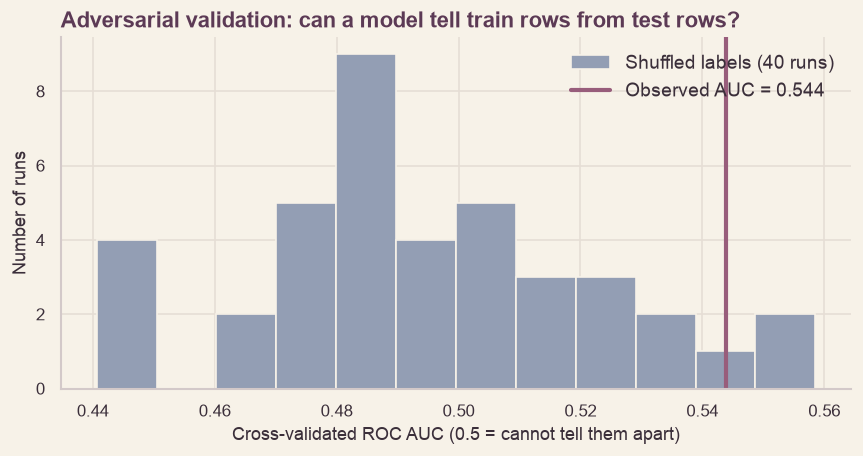

Column,Labels only in test,Test rows affected
Heating,Floor,1
AddFeatures,Othr,2



Test-access log


#,Section,Kind,Purpose,Used test target,Time
1,3.4,split diagnostics,adversarial validation and unseen-label check,no,15:35:35



✅ Split made, checked and logged. Section 3 decisions so far: 9


In [16]:
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.ensemble import RandomForestClassifier
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer

if 'DF_ALL' not in globals():
    raise RuntimeError('DF_ALL no longer exists: the split was already made in this session. Restart the kernel and run 3.1 to 3.4 in order.')

# ── 1. The split: a plain random 80 / 20 split of the rows ────
# The target is NOT used to build the split, so test labels stay unseen until the final evaluation (Section 11).
TEST_FRACTION = 0.20
all_ids = DF_ALL[ID_COL].to_numpy()
train_ids, test_ids = train_test_split(all_ids, test_size=TEST_FRACTION, random_state=SEEDS['split'], shuffle=True)
train_ids, test_ids = np.sort(train_ids), np.sort(test_ids)

FULL        = DF_ALL.set_index(ID_COL)
X_train     = FULL.loc[train_ids].drop(columns=TARGET)
y_train     = FULL.loc[train_ids, TARGET]
VAULT       = TestVault(FULL.loc[test_ids].drop(columns=TARGET), FULL.loc[test_ids, TARGET], TEST_LOG)

SPLIT_FINGERPRINT = hashlib.sha256(','.join(map(str, test_ids)).encode()).hexdigest()
pd.DataFrame({ID_COL: np.r_[train_ids, test_ids], 'Part': ['train'] * len(train_ids) + ['test'] * len(test_ids)}) \
  .sort_values(ID_COL).to_csv(ARTIFACT_DIR / 'split_ids.csv', index=False)

# From here on nothing outside the vault may hold test rows: the full frames are deleted.
n_total = len(DF_ALL)
del DF_ALL, FULL, RAW

split_checks = pd.DataFrame([
    ('Rows: train + test = all rows',              f'{len(train_ids):,} + {len(test_ids):,} = {len(train_ids) + len(test_ids):,}'),
    ('Test share',                                 f'{len(test_ids) / n_total:.1%}'),
    ('No PropertyID in both parts',                '✅' if not set(train_ids) & set(test_ids) else '❌'),
    ('Every PropertyID is in one part',            '✅' if len(set(train_ids) | set(test_ids)) == n_total else '❌'),
    ('Seed used',                                  f"SEEDS['split'] = {SEEDS['split']}"),
    ('Test-ID fingerprint (SHA-256, first 16)',    SPLIT_FINGERPRINT[:16]),
    ('Training frame',                             f'X_train {X_train.shape[0]:,} × {X_train.shape[1]}, y_train {len(y_train):,}'),
    ('Test rows',                                  f'inside VAULT only ({len(VAULT):,} rows)'),
], columns=['Item', 'Result'])
show_table(split_checks, caption='The train / test split')
assert not set(train_ids) & set(test_ids) and len(set(train_ids) | set(test_ids)) == n_total

# ── 2. Adversarial validation: can a model tell train rows from test rows, using the predictors only? ──
# Reading the test predictors (never the target) is a logged 'split diagnostics' access.
X_test_diag = VAULT.open_features('3.4', 'split diagnostics', 'adversarial validation and unseen-label check')
X_both  = pd.concat([X_train, X_test_diag])
is_test = np.r_[np.zeros(len(X_train), dtype=int), np.ones(len(X_test_diag), dtype=int)]
num_cols = [c for c in X_both.columns if c in NUMERIC_PRED]
cat_cols = [c for c in X_both.columns if c in TEXT_PRED]

adv_model = Pipeline([
    ('prep', ColumnTransformer([('num', SimpleImputer(strategy='median'), num_cols),
                                ('cat', OneHotEncoder(handle_unknown='ignore'), cat_cols)])),
    ('clf',  RandomForestClassifier(n_estimators=100, min_samples_leaf=3, class_weight='balanced',
                                    random_state=SEEDS['cv'], n_jobs=-1))])
adv_cv   = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEEDS['cv'])
adv_auc  = cross_val_score(adv_model, X_both, is_test, cv=adv_cv, scoring='roc_auc')

# Null: the same procedure on shuffled train / test labels, so a chance-level AUC has a reference range
N_PERM = 40
rng = np.random.default_rng(SEEDS['permutation'])
null_auc = np.array([cross_val_score(adv_model, X_both, rng.permutation(is_test), cv=adv_cv, scoring='roc_auc').mean() for _ in range(N_PERM)])
null_lo, null_hi = np.percentile(null_auc, [2.5, 97.5])
p_perm = (1 + int((null_auc >= adv_auc.mean()).sum())) / (N_PERM + 1)
split_accepted = p_perm >= 0.05                       # the rule was fixed before the run (see the Decision above)

adv_table = pd.DataFrame([
    ('Observed cross-validated AUC (mean ± SD over 5 folds)', f'{adv_auc.mean():.3f} ± {adv_auc.std(ddof=1):.3f}'),
    ('Chance-level AUC from shuffled labels (mean)',          f'{null_auc.mean():.3f}'),
    ('Range of shuffled-label AUC (2.5 % to 97.5 %)',         f'{null_lo:.3f} to {null_hi:.3f}'),
    (f'Permutation p-value ({N_PERM} shuffles)',              f'{p_perm:.3f}'),
    ('Rule: accept the split if p ≥ 0.05',                    'accepted' if split_accepted else 'NOT accepted: investigate'),
], columns=['Item', 'Result'])
show_table(adv_table, caption='Adversarial validation: train vs test, predictors only')

fig, ax = plt.subplots(figsize=(8.5, 3.8))
ax.hist(null_auc, bins=12, color=SLATE_BLUE, edgecolor=CREAM, label=f'Shuffled labels ({N_PERM} runs)')
ax.axvline(adv_auc.mean(), color=MAUVE, lw=2.5, label=f'Observed AUC = {adv_auc.mean():.3f}')
ax.set_title('Adversarial validation: can a model tell train rows from test rows?', loc='left')
ax.set_xlabel('Cross-validated ROC AUC (0.5 = cannot tell them apart)'); ax.set_ylabel('Number of runs')
ax.legend(frameon=False, loc='upper right')
save_fig(fig, '02_adversarial_validation', section='3'); plt.show()

# ── 3. Labels that exist in the test rows but never appear in training ──
rows = []
for c in cat_cols:
    unseen = sorted(set(X_test_diag[c]) - set(X_train[c]))
    if unseen:
        rows.append({'Column': c, 'Labels only in test': ', '.join(unseen), 'Test rows affected': int(X_test_diag[c].isin(unseen).sum())})
UNSEEN = pd.DataFrame(rows, columns=['Column', 'Labels only in test', 'Test rows affected'])
if UNSEEN.empty:
    print('Labels only in the test rows: none.')
else:
    show_table(UNSEEN, caption='Labels that never appear in the training rows')
n_unseen_rows = int(X_test_diag[UNSEEN['Column'].tolist()].apply(lambda col: col.isin(set(col) - set(X_train[col.name]))).any(axis=1).sum()) if len(UNSEEN) else 0
del X_test_diag, X_both                                # the test predictors do not stay in memory outside the vault

# ── Decisions ──
DECISIONS.add('3.4', 'How is the data split, and does the split hide anything?',
    f"A plain random {1 - TEST_FRACTION:.0%} / {TEST_FRACTION:.0%} split of the rows with SEEDS['split']. The target is not used to build it. The test rows go into TestVault and the full frames are deleted.",
    f'{len(train_ids):,} training and {len(test_ids):,} test rows, no overlap. Test-ID fingerprint {SPLIT_FINGERPRINT[:16]}…. split_ids.csv is saved to artifacts/.',
    'All value-based work from 3.5 onward uses X_train and y_train. The test rows are opened once more, for the final evaluation (Section 11). Because the target did not shape the split, test and training prices are not compared until then, and that is a stated limit, not an oversight.',
    'Changes the workflow')
DECISIONS.add('3.4', 'Do the training and test rows look alike on the predictors?',
    'Adversarial validation: a random forest, with imputation and encoding fitted inside each fold, tries to tell train from test rows using the predictors only. The 5-fold AUC is compared with an AUC from 40 shuffled-label runs. Rule fixed in advance: accept the split if the permutation p ≥ 0.05; if not, find which predictor differs instead of re-drawing the seed.',
    f'Observed AUC {adv_auc.mean():.3f} ± {adv_auc.std(ddof=1):.3f}; shuffled-label AUC {null_auc.mean():.3f} (2.5 % to 97.5 %: {null_lo:.3f} to {null_hi:.3f}); permutation p = {p_perm:.3f}. '
    f'Reading the test predictors was logged as a split-diagnostics access (target not used).',
    'Split accepted.' if split_accepted else 'Split NOT accepted: investigate before 3.5.',
    'Deliberately unchanged')
DECISIONS.add('3.4', 'Do the test rows contain labels the training rows never show?',
    'For each text predictor, list labels present in the test predictors but absent from the training rows, and the number of test rows affected.',
    'None.' if UNSEEN.empty else f'{len(UNSEEN)} columns have labels seen only in the test rows, affecting {n_unseen_rows} test rows: ' + '; '.join(f'{r.Column} ({r._2})' for r in UNSEEN.itertuples()) + '.',
    'No action is needed now.' if UNSEEN.empty else 'Every encoder in 3.10 and in the pipelines must ignore unseen labels instead of failing (handle_unknown="ignore"), and these rows are watched in the final evaluation.',
    'Documentation only' if UNSEEN.empty else 'Changes the workflow')

print('\nTest-access log')
TEST_LOG.show()
print(f'\n✅ Split made, checked and logged. Section 3 decisions so far: {len(DECISIONS.to_frame("3"))}')


**Reading.** The reproducible split contains **1,168 training observations (80%)** and **292 held-out observations (20%)**, using random seed 205. No `PropertyID` appears in both partitions.

Adversarial validation was conducted using a random forest trained to distinguish training from test observations using predictors only. The observed five-fold ROC AUC was **0.544 ± 0.034**, compared with a mean AUC of **0.496** under shuffled labels (95% empirical range: 0.448–0.549). The permutation p-value was **0.073**.

Because p = 0.073 exceeds the prespecified 0.05 threshold, the diagnostic did not provide sufficient evidence to reject the null hypothesis of no detectable partition difference. This does **not** establish that the partitions have identical distributions or that future distribution shift is absent.

Two categorical levels occur only in the held-out partition: `Heating = Floor` (one observation) and `AddFeatures = Othr` (two observations). Therefore, the fitted categorical encoders must handle previously unseen levels without failure.

The test predictors were accessed for the documented split diagnostic; test prices were not required for this analysis. Separately, an earlier notebook version evaluated a Gradient Boosting model on the holdout. That historical target-bearing access is disclosed in Sections 11 and 12.

**Decision.** Retain the original split without redrawing the seed. Use training-fitted preprocessing that handles unseen categories, preserve the split diagnostic in the test-access audit, and treat the final held-out evaluation as supplementary to training-only cross-validation because of historical test-set exposure.

## 3.5 What Does NA Mean? Absent or Unknown

**Research question.** In each column with a gap, is the value *absent* (the feature does not exist: no pool, no alley, no garage) or *unknown* (it exists but was not recorded)? The two need opposite treatments. Absent is information and becomes its own label; unknown is a gap to be imputed.

**Method.** Training rows only. Where a column has a companion that says whether the feature exists (pool area, miscellaneous value, fireplace count, garage cars and garage area, basement area), it is used. Counted per column: missing where the feature is absent, missing where it exists, and filled where it is absent. A column that is missing *only* where the feature is absent is classified *absent (confirmed)*. Columns without a companion are classified by reading and marked as assumptions.

**Decision.** A fixed, row-wise rule, `apply_missing_rules()`: absent becomes the label `None`, unknown stays a missing value for the imputer (D22, D23). Nothing is fitted, so the rule can run before cross-validation and later inside the saved pipeline.

Column,Type,Missing,Share,Basis,"Missing, feature absent","Missing, feature exists","Filled, feature absent",Meaning
PoolQC,text,"1,161",99.4%,companion: PoolArea = 0,1161,0,0,absent (confirmed)
AddFeatures,text,"1,130",96.7%,companion: AddVal = 0,1130,0,0,absent (confirmed)
Alley,text,"1,101",94.3%,no companion column; documentation reading,–,–,–,absent (assumed)
BoundaryFeatures,text,943,80.7%,no companion column; documentation reading,–,–,–,absent (assumed)
QualFireplace,text,540,46.2%,companion: CntFireplaces = 0,540,0,0,absent (confirmed)
PropertyFrontage,number,217,18.6%,"every lot has a frontage; there is no ""none"" label",–,–,–,unknown
BasementCond,text,66,5.7%,companion: garage cars = 0 and garage area = 0,66,0,0,absent (confirmed)
BasementFinish,text,66,5.7%,companion: garage cars = 0 and garage area = 0,66,0,0,absent (confirmed)
BasementQual,text,66,5.7%,companion: garage cars = 0 and garage area = 0,66,0,0,absent (confirmed)
BasementType,text,66,5.7%,companion: garage cars = 0 and garage area = 0,66,0,0,absent (confirmed)


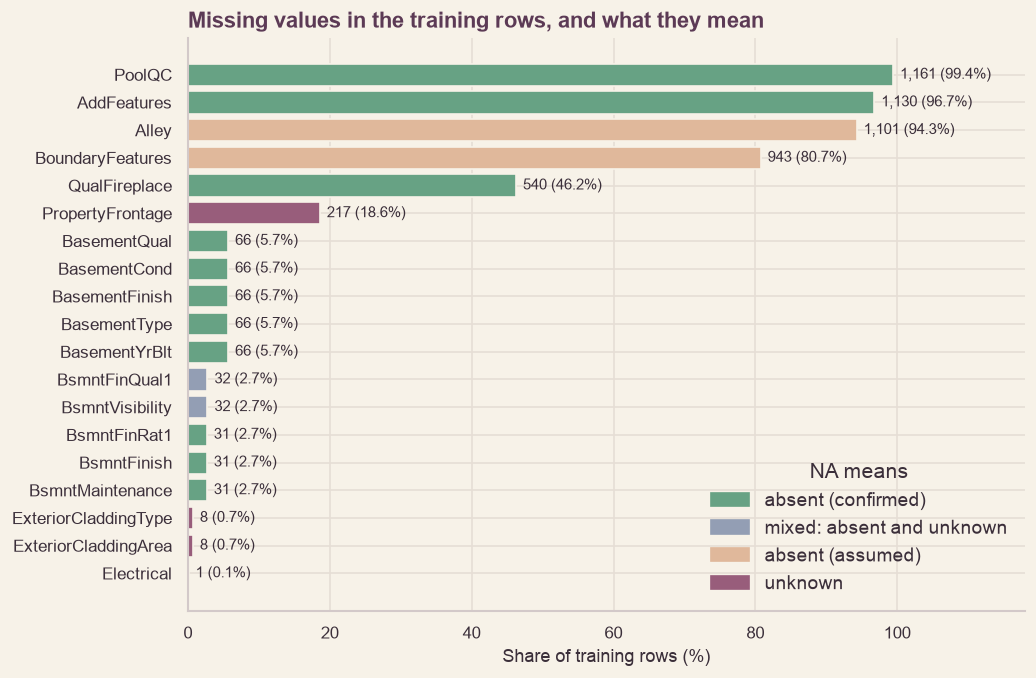

Check,Result
Text NA tokens left in any column,0
Text columns where NA became the label None,"14 (5,294 cells)"
"Missing values left, all of them unknown or not applicable",302 cells in 7 columns


Column,Missing,Meaning
PropertyFrontage,217,unknown
ExteriorCladdingType,8,unknown
ExteriorCladdingArea,8,unknown
BsmntVisibility,1,"unknown (feature exists, value not recorded)"
BsmntFinQual1,1,"unknown (feature exists, value not recorded)"
Electrical,1,unknown
BasementYrBlt,66,not applicable (no garage)



✅ Missing values classified and coded. Section 3 decisions so far: 11


In [17]:
# ── Everything here uses the TRAINING rows only ────────────────
def missing_mask(df, col):
    """A missing number, or the text NA in a text column."""
    return df[col].isna() if col in NUMERIC_PRED else (df[col] == 'NA')

# Companion rules: a second column that says whether the feature exists at all
garage_absent   = lambda d: (d['BasementCars'] == 0) & (d['BasementSqFootage'] == 0)
basement_absent = lambda d: d['BsmntSqFtage'] == 0
COMPANION_ABSENT = {
    'PoolQC':        (lambda d: d['PoolArea'] == 0,        'PoolArea = 0'),
    'AddFeatures':   (lambda d: d['AddVal'] == 0,          'AddVal = 0'),
    'QualFireplace': (lambda d: d['CntFireplaces'] == 0,   'CntFireplaces = 0'),
    **{c: (garage_absent, 'garage cars = 0 and garage area = 0')
       for c in ['BasementType', 'BasementYrBlt', 'BasementFinish', 'BasementQual', 'BasementCond']},
    **{c: (basement_absent, 'basement area = 0')
       for c in ['BsmntFinish', 'BsmntMaintenance', 'BsmntVisibility', 'BsmntFinRat1', 'BsmntFinQual1']},
}
# No companion column exists. Alley and BoundaryFeatures: NA is read as "no alley access" / "no fence" (an ASSUMPTION, see D22).
ASSUMED_ABSENT = ['Alley', 'BoundaryFeatures']
# A property always has these, and no label for "none" exists, so NA can only mean "not recorded".
UNKNOWN = {'PropertyFrontage':      'every lot has a frontage; there is no "none" label',
           'ExteriorCladdingType':  'the column already has its own label None for no veneer, so NA is not "no veneer"; it is missing on the same rows as the area',
           'ExteriorCladdingArea':  'missing on exactly the rows where the veneer type is NA',
           'Electrical':            'every house has an electrical system'}

with_missing = [c for c in X_train.columns if missing_mask(X_train, c).any()]
assert set(with_missing) == set(COMPANION_ABSENT) | set(ASSUMED_ABSENT) | set(UNKNOWN), \
    f'Unclassified columns with missing values: {sorted(set(with_missing) - set(COMPANION_ABSENT) - set(ASSUMED_ABSENT) - set(UNKNOWN))}'
assert missing_mask(X_train, 'ExteriorCladdingType').equals(missing_mask(X_train, 'ExteriorCladdingArea'))

rows = []
for col in with_missing:
    miss = missing_mask(X_train, col)
    if col in COMPANION_ABSENT:
        is_absent, rule = COMPANION_ABSENT[col]
        absent = is_absent(X_train)
        n_abs, n_exist, n_lab = int((miss & absent).sum()), int((miss & ~absent).sum()), int((~miss & absent).sum())
        meaning = 'absent (confirmed)' if n_exist == 0 and n_abs > 0 else 'unknown' if n_abs == 0 else 'mixed: absent and unknown'
        basis = f'companion: {rule}'
        cells = (n_abs, n_exist, n_lab)
    elif col in ASSUMED_ABSENT:
        meaning, basis, cells = 'absent (assumed)', 'no companion column; documentation reading', ('–', '–', '–')
    else:
        meaning, basis, cells = 'unknown', UNKNOWN[col], ('–', '–', '–')
    rows.append({'Column': col, 'Type': 'number' if col in NUMERIC_PRED else 'text', 'Missing': int(miss.sum()), 'Share': miss.mean(),
                 'Basis': basis, 'Missing, feature absent': cells[0], 'Missing, feature exists': cells[1], 'Filled, feature absent': cells[2], 'Meaning': meaning})
MISSING = pd.DataFrame(rows).sort_values(['Missing', 'Column'], ascending=[False, True]).reset_index(drop=True)
show_table(MISSING, formats={'Missing': '{:,}', 'Share': '{:.1%}'}, caption=f'Where the training rows are missing a value ({len(MISSING)} of {X_train.shape[1]} predictors)')

# ── Figure: how much is missing, and what it means ────────────
palette = {'absent (confirmed)': SAGE_GREEN,
           'mixed: absent and unknown': SLATE_BLUE,
           'absent (assumed)': APRICOT,
           'unknown': MAUVE}
fig, ax = plt.subplots(figsize=(9, 6.2))
plot_df = MISSING.sort_values('Share')
ax.barh(plot_df['Column'], plot_df['Share'] * 100, color=[palette[m] for m in plot_df['Meaning']], edgecolor=CREAM)
for y_pos, (n, s) in enumerate(zip(plot_df['Missing'], plot_df['Share'])):
    ax.text(s * 100 + 1, y_pos, f'{n:,} ({s:.1%})', va='center', fontsize=9, color=INK)
ax.set_xlim(0, 118); ax.set_xlabel('Share of training rows (%)'); ax.set_ylabel('')
ax.set_title('Missing values in the training rows, and what they mean', loc='left')
ax.legend(handles=[plt.Rectangle((0, 0), 1, 1, color=c) for c in palette.values()], labels=list(palette), frameon=False, loc='lower right', title='NA means')
save_fig(fig, '03_missing_values', section='3'); plt.show()

# ── The fixed rule: absent becomes the label None, unknown stays a missing value ──
def apply_missing_rules(X):
    """Row-wise and fixed (nothing is fitted). Where the companion column says the feature does not exist, NA becomes the
    label None. Where it says the feature exists, NA is a missing value (unknown) for the imputer in 3.7. A number that
    is not applicable (garage year without a garage) stays missing until 3.7 designs its treatment."""
    X = X.copy()
    for col, (is_absent, _) in COMPANION_ABSENT.items():
        if col in NUMERIC_PRED:
            continue
        miss, absent = missing_mask(X, col), is_absent(X)
        X.loc[miss & absent, col] = 'None'
        X.loc[miss & ~absent, col] = np.nan
    for col in ASSUMED_ABSENT:
        X[col] = X[col].replace('NA', 'None')
    for col in UNKNOWN:
        if col not in NUMERIC_PRED:
            X[col] = X[col].replace('NA', np.nan)
    return X

to_fill = [c for c in COMPANION_ABSENT if c not in NUMERIC_PRED] + ASSUMED_ABSENT
assert all('None' not in set(X_train[c]) for c in to_fill), 'None is already a real label in a column we are about to fill with it.'
X_train_clean = apply_missing_rules(X_train)

after = pd.DataFrame([
    ('Text NA tokens left in any column',                      f'{int((X_train_clean[TEXT_PRED] == "NA").sum().sum())}'),
    ('Text columns where NA became the label None',            f'{len(to_fill)}  ({int(sum((X_train_clean[c] == "None").sum() for c in to_fill)):,} cells)'),
    ('Missing values left, all of them unknown or not applicable', f'{int(X_train_clean.isna().sum().sum()):,} cells in {int((X_train_clean.isna().sum() > 0).sum())} columns'),
], columns=['Check', 'Result'])
show_table(after, caption='After the missing-value rule')

mixed_cols = set(MISSING.loc[MISSING['Meaning'] == 'mixed: absent and unknown', 'Column'])
def leftover_meaning(c):
    if c == 'BasementYrBlt':
        return 'not applicable (no garage)'
    if c in mixed_cols:
        return 'unknown (feature exists, value not recorded)'
    return 'unknown'
left = X_train_clean.isna().sum(); left = left[left > 0].rename('Missing').rename_axis('Column').reset_index()
left['Meaning'] = left['Column'].map(leftover_meaning)
show_table(left, formats={'Missing': '{:,}'}, caption='What is still missing and goes to the imputation design (3.7)')
assert (X_train_clean[TEXT_PRED] == 'NA').sum().sum() == 0

# ── Decisions ──
n_conf = int((MISSING['Meaning'] == 'absent (confirmed)').sum())
n_mix  = int((MISSING['Meaning'] == 'mixed: absent and unknown').sum())
n_ass  = int((MISSING['Meaning'] == 'absent (assumed)').sum())
n_unk  = int((MISSING['Meaning'] == 'unknown').sum())
conf_cols = ", ".join(MISSING.loc[MISSING['Meaning'] == 'absent (confirmed)', 'Column'])
mix_cols  = ", ".join(MISSING.loc[MISSING['Meaning'] == 'mixed: absent and unknown', 'Column'])
n_garage  = int(MISSING.loc[MISSING['Column'] == 'BasementType', 'Missing'].iloc[0])
assert n_conf + n_mix + n_ass + n_unk == len(MISSING), 'Some columns have no category.'

DECISIONS.add('3.5', 'Does each NA mean "absent" or "unknown"?',
    'For every column with a missing value in the training rows, compare it with a companion column that says whether the feature exists (pool area, garage cars and area, basement area, fireplaces, miscellaneous value). Count missing values where the feature is absent, where it exists, and values present where it is absent.',
    f'{len(MISSING)} of {X_train.shape[1]} predictors have missing values. {n_conf} are absent by the companion test (missing only where the feature is absent: {conf_cols}). '
    f'{n_mix} are mixed: missing where the basement is absent, plus one row where a basement exists ({mix_cols}). '
    f'{n_ass} are read as absent by documentation, with no way to test it here ({", ".join(ASSUMED_ABSENT)}). {n_unk} are unknown ({", ".join(UNKNOWN)}). '
    f'The five garage columns that can be missing (BasementType, BasementYrBlt, BasementFinish, BasementQual, BasementCond) are missing on exactly the {n_garage} rows where garage cars and garage area are both 0, which confirms the garage reading from 3.2.',
    'Absent becomes an explicit label None. Unknown stays a missing value and is imputed inside each CV fold (3.7). The mixed columns get both treatments: None on the absent rows, a missing value on the one existing-basement row. Alley and BoundaryFeatures follow the documentation reading; it is an assumption, and these two columns are not interpreted beyond "has / has no".',
    'Changes the workflow')

DECISIONS.add('3.5', 'How are absent and unknown values coded?',
    'A fixed, row-wise rule, apply_missing_rules(): NA becomes None where the companion says the feature does not exist, and a missing value where it says the feature exists. Nothing is fitted, so the rule can run before cross-validation and later inside the saved pipeline.',
    f'After the rule no text NA is left; {len(to_fill)} text columns carry None; {int(X_train_clean.isna().sum().sum()):,} missing cells remain in {int((X_train_clean.isna().sum() > 0).sum())} columns, all unknown or not applicable (the garage year).',
    'X_train_clean replaces X_train as the input to every later subsection. A test row whose companion says the feature exists but whose label is NA becomes a missing value, not None.',
    'Changes the workflow')
print(f'\n✅ Missing values classified and coded. Section 3 decisions so far: {len(DECISIONS.to_frame("3"))}')

**Reading.**

- **19 of the 79 predictors have a missing value in the training rows.** Thirteen are *absent*, confirmed by a companion column: they are missing only where the feature does not exist, never where it does. That covers pool quality where pool area is 0, fireplace quality where there are no fireplaces, five garage columns on exactly the 66 rows where garage cars and garage area are both 0, and five basement columns on exactly the 34 rows where basement area is 0. The 70 rows confirm the garage reading promised in 3.2.
- **`AddFeatures`** has one row with a label but an `AddVal` of 0. That is a feature with no recorded value, not a contradiction, since no row has a value without a feature.
- **Two columns rest on an assumption.** `Alley` (93.8 % missing) and `BoundaryFeatures` (80.9 %) have no companion column. Reading `NA` as "no alley" and "no fence" fits the high shares but cannot be tested here.
- **Four columns are unknown:** `PropertyFrontage` (212 rows, 18.2 %), `ExteriorCladdingType` and `ExteriorCladdingArea` (the same 7 rows) and `Electrical` (1 row). They stay missing and are imputed inside each CV fold in 3.7.
- **After the rule** no text `NA` is left. Fourteen text columns carry `None`, and 302 cells in 7 columns: the four unknown columns and the garage year, which is not applicable where there is no garage (70 rows). Its treatment is designed in 3.7.

## 3.6 Integrity and Range Checks

**Research question.** Do the training rows obey the arithmetic, calendar and range rules that any real property must obey?

**Method.** Two kinds of rule, on the cleaned training rows. *Must-hold* rules cannot be broken by a real property (the area sums, build before remodel before sale, ratings from 1 to 10, no negative areas). *Plausibility* rules mark things that are unusual but possible (a garage older than the house, no kitchen, a remodel recorded after the sale). Each rule reports how many rows it checks, how many break it and which `PropertyID`s. The year bounds (1800 to 2026) are assumed.

**Decision.** A must-hold violation would need a documented fix before modelling. A plausibility flag changes nothing by itself: flagged rows are kept in `INTEGRITY_FLAGS` and judged later by cross-validation, not by inspection (D24).

In [18]:
# ── Integrity and range checks, on the cleaned TRAINING rows ──
X, y = X_train_clean, y_train

AREA_COLS  = ['PropertySize', 'ExteriorCladdingArea', 'BsmntFinSty1', 'BsmtFinSF2', 'BsmtUnfSF', 'BsmntSqFtage', '1stFlrSF', '2ndFlrSF',
              'LowQualFinSF', 'GrLivArea', 'BasementSqFootage', 'WoodDeckSF', 'OpenPorchSF', 'EnclosedPorch', '3SsnPorch', 'ScreenPorch',
              'PoolArea', 'AddVal']
COUNT_COLS = ['BsmtFullBath', 'BsmtHalfBath', 'Bath1', 'Bath2', 'BedroomUpLev', 'KitchenUpLev', 'CntRmsUpLev', 'CntFireplaces', 'BasementCars']
YEAR_COLS  = ['YearBuilt', 'YearRemodAdd', 'BasementYrBlt', 'SaleYr']
YEAR_MIN, YEAR_MAX = 1800, 2026                      # assumed bounds: no property in the file is older than 1800 or sold after 2026

RULES = []                                           # (kind, code, rule, rows the rule applies to, violating rows)
def rule(kind, code, text, violates, applies=None):
    applies = pd.Series(True, index=X.index) if applies is None else applies
    RULES.append((kind, code, text, applies, violates.fillna(False) & applies))

MUST, UNUSUAL = 'must hold', 'unusual, not impossible'
rule(MUST, 'M1',  'GrLivArea = 1stFlrSF + 2ndFlrSF + LowQualFinSF',                      X['GrLivArea'] != X['1stFlrSF'] + X['2ndFlrSF'] + X['LowQualFinSF'])
rule(MUST, 'M2',  'BsmntSqFtage = BsmntFinSty1 + BsmtFinSF2 + BsmtUnfSF',                X['BsmntSqFtage'] != X['BsmntFinSty1'] + X['BsmtFinSF2'] + X['BsmtUnfSF'])
rule(MUST, 'M3',  'YearRemodAdd ≥ YearBuilt',                                            X['YearRemodAdd'] < X['YearBuilt'])
rule(MUST, 'M4',  'YearBuilt ≤ SaleYr',                                                  X['YearBuilt'] > X['SaleYr'])
rule(MUST, 'M5',  'Garage year ≤ SaleYr (where a garage exists)',                        X['BasementYrBlt'] > X['SaleYr'], applies=X['BasementYrBlt'].notna())
rule(MUST, 'M6',  'OverallQual and OverallCond between 1 and 10',                        ~X['OverallQual'].between(1, 10) | ~X['OverallCond'].between(1, 10))
rule(MUST, 'M7',  'SaleMon is a month, 1 to 12',                                         ~X['SaleMon'].isin([str(m) for m in range(1, 13)]))
rule(MUST, 'M8',  'Garage cars = 0 exactly when garage area = 0',                        (X['BasementCars'] == 0) != (X['BasementSqFootage'] == 0))
rule(MUST, 'M9',  'BedroomUpLev ≤ CntRmsUpLev (bedrooms are part of the rooms)',         X['BedroomUpLev'] > X['CntRmsUpLev'])
rule(MUST, 'M10', 'No area or count below 0',                                            (X[AREA_COLS + COUNT_COLS] < 0).any(axis=1))
rule(MUST, 'M11', f'Every year between {YEAR_MIN} and {YEAR_MAX}',                       ((X[YEAR_COLS] < YEAR_MIN) | (X[YEAR_COLS] > YEAR_MAX)).any(axis=1))
rule(MUST, 'M12', 'PropPrice above 0',                                                   ~(y.reindex(X.index) > 0))
rule(UNUSUAL, 'P1', 'YearRemodAdd ≤ SaleYr (a remodel recorded after the sale)',        X['YearRemodAdd'] > X['SaleYr'])
rule(UNUSUAL, 'P2', 'Garage year ≥ YearBuilt (garage older than the house)',             X['BasementYrBlt'] < X['YearBuilt'], applies=X['BasementYrBlt'].notna())
rule(UNUSUAL, 'P3', 'At least one kitchen above ground',                                 X['KitchenUpLev'] < 1)
rule(UNUSUAL, 'P4', 'At least one bedroom above ground',                                 X['BedroomUpLev'] < 1)
rule(UNUSUAL, 'P5', 'At least one full bathroom (basement or above ground)',             (X['BsmtFullBath'] + X['Bath1']) < 1)

rows = [{'Kind': k, 'Code': c, 'Rule': t, 'Rows checked': int(a.sum()), 'Violations': int(v.sum()),
         'PropertyIDs': ', '.join(map(str, X.index[v][:8])) + (' …' if v.sum() > 8 else '') if v.any() else '–'} for k, c, t, a, v in RULES]
INTEGRITY = pd.DataFrame(rows)
show_table(INTEGRITY, formats={'Rows checked': '{:,}'}, caption=f'Integrity and range checks on {len(X):,} training rows')

# the rows that break a rule or look unusual, kept for Sections 5 and 8
flag_codes = pd.DataFrame({c: v for k, c, t, a, v in RULES})
flagged_ids = flag_codes.index[flag_codes.any(axis=1)]
INTEGRITY_FLAGS = pd.DataFrame({
    'Rules': flag_codes.loc[flagged_ids].apply(lambda r: ', '.join(r.index[r]), axis=1),
    'Built / remodelled / sold': X.loc[flagged_ids, ['YearBuilt', 'YearRemodAdd', 'SaleYr']].astype(int).astype(str).agg(' / '.join, axis=1),
    'SaleCondn': X.loc[flagged_ids, 'SaleCondn'], 'PropPrice': y.loc[flagged_ids]})
show_table(INTEGRITY_FLAGS.reset_index(), formats={'PropPrice': '${:,.0f}'}, caption=f'Rows flagged by at least one rule ({len(flagged_ids)})')

# ── Decisions ──
n_must = sum(1 for r in RULES if r[0] == MUST); n_must_broken = int(sum(r[4].any() for r in RULES if r[0] == MUST))
unusual_counts = {c: int(v.sum()) for k, c, t, a, v in RULES if k == UNUSUAL}
p1_rows = [f'{i} ({X.at[i, "SaleCondn"]} sale; built {X.at[i, "YearBuilt"]}, remodel {X.at[i, "YearRemodAdd"]}, sold {X.at[i, "SaleYr"]})' for i in X.index[flag_codes['P1']]]
DECISIONS.add('3.6', 'Do the training rows obey the arithmetic, calendar and range rules?',
    f'{n_must} must-hold rules (area sums, build / remodel / sale order, rating and month ranges, garage consistency, non-negative values, positive price) and {len(RULES) - n_must} plausibility rules for things that are unusual but possible (an old garage, no kitchen, a remodel recorded after the sale).',
    f'{n_must - n_must_broken} of {n_must} must-hold rules have no violation. Plausibility flags: ' + ', '.join(f'{c} {n}' for c, n in unusual_counts.items()) + f'; {len(flagged_ids)} rows are flagged in all. '
    + (f'The remodel-after-sale rows: {"; ".join(p1_rows)}.' if p1_rows else ''),
    'No row is changed or removed here. The flagged rows are kept in INTEGRITY_FLAGS. Whether any of them harms prediction is judged in Section 5 by cross-validation, not by inspection. Years since remodel (Section 8) must be clipped at 0 because of the P1 rows.',
    'Deliberately unchanged')
print(f'\n✅ Integrity checked. Section 3 decisions so far: {len(DECISIONS.to_frame("3"))}')

Kind,Code,Rule,Rows checked,Violations,PropertyIDs
must hold,M1,GrLivArea = 1stFlrSF + 2ndFlrSF + LowQualFinSF,"1,168",0,–
must hold,M2,BsmntSqFtage = BsmntFinSty1 + BsmtFinSF2 + BsmtUnfSF,"1,168",0,–
must hold,M3,YearRemodAdd ≥ YearBuilt,"1,168",0,–
must hold,M4,YearBuilt ≤ SaleYr,"1,168",0,–
must hold,M5,Garage year ≤ SaleYr (where a garage exists),"1,102",0,–
must hold,M6,OverallQual and OverallCond between 1 and 10,"1,168",0,–
must hold,M7,"SaleMon is a month, 1 to 12","1,168",0,–
must hold,M8,Garage cars = 0 exactly when garage area = 0,"1,168",0,–
must hold,M9,BedroomUpLev ≤ CntRmsUpLev (bedrooms are part of the rooms),"1,168",0,–
must hold,M10,No area or count below 0,"1,168",0,–


PropertyID,Rules,Built / remodelled / sold,SaleCondn,PropPrice
30,P2,1927 / 1950 / 2008,Normal,"$68,500"
54,P4,1981 / 1987 / 2006,Normal,"$385,000"
94,P2,1910 / 1998 / 2007,Normal,"$133,900"
190,P4,2001 / 2002 / 2008,Normal,"$286,000"
325,P2,1967 / 2007 / 2010,Normal,"$242,000"
524,P1,2007 / 2008 / 2007,Partial,"$184,750"
601,P2,2005 / 2005 / 2006,Normal,"$275,000"
955,P3,1975 / 1975 / 2006,AdjLand,"$127,500"
1164,P4,1969 / 1969 / 2008,Alloca,"$108,959"
1214,P4,1965 / 2001 / 2006,Normal,"$145,000"



✅ Integrity checked. Section 3 decisions so far: 12


**Reading.** All 12 must-hold rules pass on the 1,168 training rows: the area sums add up, no house is remodelled before it is built or built after it is sold, ratings and months are in range, garage cars and garage area are zero together, and no value is negative. The five plausibility rules flag 16 rows, none of them impossible: seven houses have a garage older than the house, six have no bedroom above ground, one has no kitchen above ground (an `AdjLand` sale), one has no full bathroom (a `Partial` sale), and one (ID 524, a `Partial` sale of a house built and sold in 2007) has a remodel recorded in 2008, after the sale. Nothing is changed or removed here. Whether a flagged row harms prediction is judged in Section 5 by cross-validation, not by eye.

**Where Section 3 stands after 3.6.** Twelve decisions (D13 to D24) are registered. `X_train_clean` is the input to everything that follows. **Next → 3.7 and 3.8:** the imputation design for the five columns that still have missing values (with the optional KNN / iterative comparison), and the choice between a log and a Yeo-Johnson transform of the target.

## 3.7 Filling the Gaps That Remain

**Research question.** Five columns still have missing values after 3.5: `PropertyFrontage` (212 rows, unknown), `ExteriorCladdingType` and `ExteriorCladdingArea` (7 rows), `Electrical` (1 row) and the garage year (70 rows, not applicable). Why is `PropertyFrontage` missing, and does the way it is filled change how well a model predicts price?

**Method.** Training rows only. *Why:* a random forest tries to find the gap rows from the other predictors (AUC against 40 shuffled-label runs); the median price of gap rows is compared with the rest (bootstrap CI, Mann–Whitney); the text predictors most tied to the gap are ranked with bias-corrected Cramér's V. *How:* imputers are written as a `GapImputer` that learns its medians and modes from the rows it is given, so inside cross-validation it learns from the training fold only, and applies them with `fillna()`. Six ways of filling `PropertyFrontage` and four ways of filling the garage year are compared on the same 15 folds with the same fixed Ridge model, which is deliberately untuned: it is a common ruler, not a candidate model. **The rule is fixed in advance:** a fancier method replaces the simpler one only if it lowers the cross-validated RMSE (log price) by at least 0.002 and the 95 % interval of the paired difference lies below zero. KNN and iterative imputation are optional; they answer one question: does a model-based fill beat a median?

**Decision.** Chosen by the rule, and recorded together with the fill for the three small gaps (D25 to D28).

Question,Result
Rows missing PropertyFrontage,"217 of 1,168 (18.6%)"
Can the other predictors find those rows? AUC (5-fold),0.852 ± 0.028
AUC from shuffled labels (mean; 2.5 % to 97.5 %),0.509 (0.460 to 0.581)
Permutation p (40 shuffles),0.024 (the smallest possible with this many shuffles)
"Median price, gap rows minus other rows","$13,000 (95 % CI $2,010 to $22,221)"
Mann–Whitney on price: p; chance a gap row is dearer,p = 0.015; 0.55


Predictor,Cramér V (bias-corrected),Effect (convention)
PropertyShape,0.349,medium
Neighborhood,0.294,small
Orientation,0.260,small
Roof2Material,0.191,small
QualFireplace,0.190,small


Variant,RMSE (log),SD over folds,Change vs baseline,CI low,CI high,Beats the rule
Global median,0.1488,0.0298,+0.00000,+0.00000,+0.00000,baseline
Median by Neighborhood,0.1486,0.0295,-0.00019,-0.00040,+0.00002,no
Median by lot configuration,0.1489,0.0299,+0.00012,+0.00003,+0.00022,no
Neighborhood median + marker,0.1487,0.0294,-0.00010,-0.00037,+0.00018,no
"KNN, 5 neighbours (optional)",0.1486,0.0296,-0.00018,-0.00037,+0.00000,no
Iterative (optional),0.1487,0.0297,-0.00013,-0.00043,+0.00014,no


Variant,RMSE (log),SD over folds,Change vs baseline,CI low,CI high,Beats the rule
Median garage year,0.1488,0.0298,+0.00000,+0.00000,+0.00000,baseline
Year the house was built,0.1487,0.0299,-0.00010,-0.00026,+0.00004,no
Median + marker,0.1489,0.0297,+0.00009,-0.00002,+0.00023,no
House year + marker,0.1488,0.0298,-0.00001,-0.00020,+0.00016,no



Chosen by the rule: PropertyFrontage = Global median; garage year = Median garage year.  IMPUTER_CHOICE = {'frontage': 'global', 'garage_year': 'median', 'indicator': False}


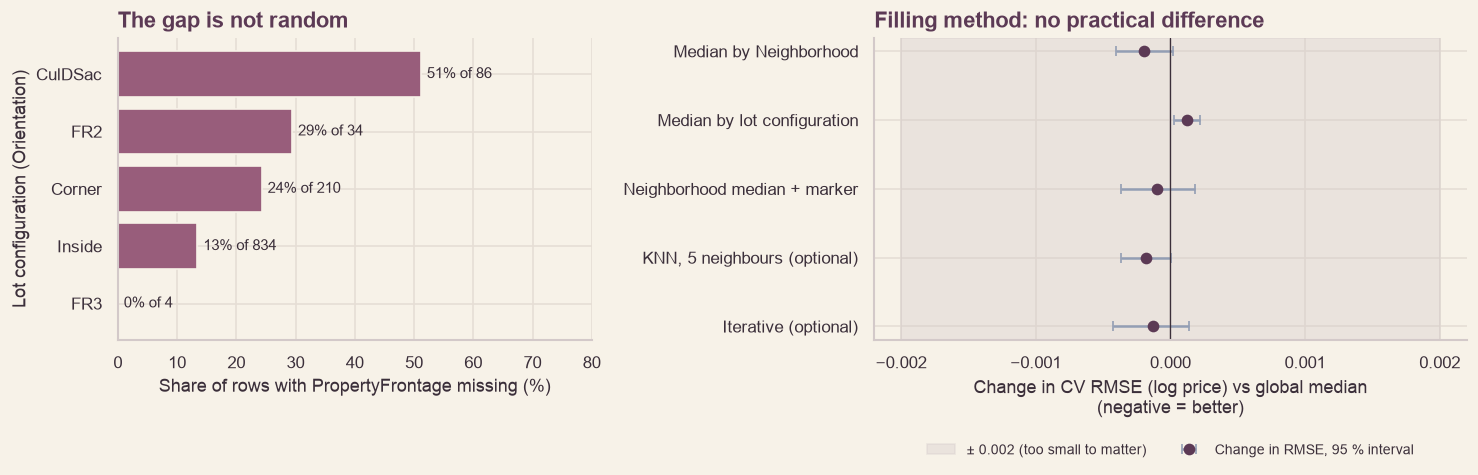


✅ Imputation designed. Section 3 decisions so far: 16


In [19]:
from sklearn.base import BaseEstimator, TransformerMixin, clone
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.experimental import enable_iterative_imputer          # noqa: F401  (switches on IterativeImputer)
from sklearn.impute import KNNImputer, IterativeImputer, SimpleImputer
from sklearn.linear_model import Ridge, BayesianRidge
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import RepeatedKFold, StratifiedKFold, cross_val_score

X, y = X_train_clean, y_train                          # training rows only

# ══ Part 1. Why is PropertyFrontage missing? (the one column with a material number of gaps) ══
flag = X['PropertyFrontage'].isna().astype(int).to_numpy()
others = X.drop(columns=['PropertyFrontage'])
o_num, o_txt = [c for c in others.columns if c not in TEXT_PRED], [c for c in others.columns if c in TEXT_PRED]

# (a) Can the other predictors tell which rows have the gap? Same design as the adversarial check in 3.4.
miss_clf = Pipeline([('prep', ColumnTransformer([('n', SimpleImputer(strategy='median'), o_num), ('c', OneHotEncoder(handle_unknown='ignore'), o_txt)])),
                     ('rf', RandomForestClassifier(n_estimators=100, min_samples_leaf=3, class_weight='balanced', random_state=SEEDS['cv'], n_jobs=-1))])
miss_cv  = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEEDS['cv'])
miss_auc = cross_val_score(miss_clf, others, flag, cv=miss_cv, scoring='roc_auc')
N_PERM_MISS = 40
rng = make_rng('permutation')
miss_null = np.array([cross_val_score(miss_clf, others, rng.permutation(flag), cv=miss_cv, scoring='roc_auc').mean() for _ in range(N_PERM_MISS)])
miss_lo, miss_hi = np.percentile(miss_null, [2.5, 97.5])
miss_p = (1 + int((miss_null >= miss_auc.mean()).sum())) / (N_PERM_MISS + 1)

# (b) Does the gap go with the price?
u_stat, mw_p = stats.mannwhitneyu(y[flag == 1], y[flag == 0], alternative='two-sided')
cles = u_stat / (flag.sum() * (1 - flag).sum())          # chance that a random gap row is dearer than a random non-gap row
price_gap = bootstrap_ci(lambda price, f: np.median(price[f == 1]) - np.median(price[f == 0]), y.to_numpy(), flag)

mech = pd.DataFrame([
    ('Rows missing PropertyFrontage',                                   f'{int(flag.sum()):,} of {len(flag):,} ({flag.mean():.1%})'),
    ('Can the other predictors find those rows? AUC (5-fold)',          f'{miss_auc.mean():.3f} ± {miss_auc.std(ddof=1):.3f}'),
    ('AUC from shuffled labels (mean; 2.5 % to 97.5 %)',                f'{miss_null.mean():.3f}  ({miss_lo:.3f} to {miss_hi:.3f})'),
    (f'Permutation p ({N_PERM_MISS} shuffles)',                         f'{miss_p:.3f}' + ('  (the smallest possible with this many shuffles)' if miss_p == 1 / (N_PERM_MISS + 1) else '')),
    ('Median price, gap rows minus other rows',                         fmt_ci(price_gap['estimate'], price_gap['lo'], price_gap['hi'], fmt='${:,.0f}')),
    ('Mann–Whitney on price: p; chance a gap row is dearer',            f'{fmt_p(mw_p)}; {cles:.2f}'),
], columns=['Question', 'Result'])
show_table(mech, caption='Why is PropertyFrontage missing? (training rows)')

assoc = []
for c in o_txt:
    try:
        v = cramers_v_corrected(pd.crosstab(X[c], flag))
    except ValueError:
        continue
    assoc.append({'Predictor': c, 'Cramér V (bias-corrected)': v, 'Effect (convention)': effect_label(v, 'v', df_star=1)})
ASSOC = pd.DataFrame(assoc).sort_values('Cramér V (bias-corrected)', ascending=False).head(5).reset_index(drop=True)
show_table(ASSOC, formats={'Cramér V (bias-corrected)': '{:.3f}'}, caption=f'Text predictors most associated with the gap (top 5 of {len(assoc)})')

# ══ Part 2. The imputer, written so that everything it learns comes from the training fold ══
class GapImputer(BaseEstimator, TransformerMixin):
    """Fills the gaps left by 3.5. fit() learns medians and modes from the rows it is given (a training fold); transform() applies them
    with fillna(). frontage: 'global' | 'Neighborhood' | 'Orientation' | 'leave' (a later numeric imputer fills it).
    garage_year: 'median' | 'house_year' (the year the house was built). indicator: add 0/1 columns that mark the filled rows."""
    def __init__(self, frontage='global', garage_year='median', indicator=False):
        self.frontage, self.garage_year, self.indicator = frontage, garage_year, indicator
    def fit(self, X, y=None):
        self.frontage_median_  = X['PropertyFrontage'].median()
        self.frontage_groups_  = {g: X.groupby(g)['PropertyFrontage'].median() for g in ('Neighborhood', 'Orientation')}
        self.garage_year_median_ = X['BasementYrBlt'].median()
        self.electrical_mode_  = X['Electrical'].mode().iat[0]
        self.cladding_mode_    = X['ExteriorCladdingType'].mode().iat[0]
        typed = X['ExteriorCladdingType'].fillna(self.cladding_mode_)
        self.cladding_area_    = X['ExteriorCladdingArea'].groupby(typed).median()
        self.cladding_area_median_ = X['ExteriorCladdingArea'].median()
        return self
    def transform(self, X):
        X = X.copy()
        if self.indicator:
            X['PropertyFrontage_filled'] = X['PropertyFrontage'].isna().astype(int)
            X['BasementYrBlt_filled']    = X['BasementYrBlt'].isna().astype(int)
        X['Electrical']           = X['Electrical'].fillna(self.electrical_mode_)
        X['ExteriorCladdingType'] = X['ExteriorCladdingType'].fillna(self.cladding_mode_)
        X['ExteriorCladdingArea'] = X['ExteriorCladdingArea'].fillna(X['ExteriorCladdingType'].map(self.cladding_area_)).fillna(self.cladding_area_median_)
        if self.frontage == 'global':
            X['PropertyFrontage'] = X['PropertyFrontage'].fillna(self.frontage_median_)
        elif self.frontage in ('Neighborhood', 'Orientation'):
            X['PropertyFrontage'] = X['PropertyFrontage'].fillna(X[self.frontage].map(self.frontage_groups_[self.frontage])).fillna(self.frontage_median_)
        if self.garage_year == 'median':
            X['BasementYrBlt'] = X['BasementYrBlt'].fillna(self.garage_year_median_)
        elif self.garage_year == 'house_year':
            X['BasementYrBlt'] = X['BasementYrBlt'].fillna(X['YearBuilt'])
        return X

def numeric_columns(X): return [c for c in X.columns if c not in TEXT_PRED]
def text_columns(X):    return [c for c in X.columns if c in TEXT_PRED]

def build_model(frontage='global', garage_year='median', indicator=False, numeric_filler=None, alpha=10.0):
    """GapImputer, then scaling of the numbers and one-hot encoding of the text, then a Ridge model.
    The Ridge is deliberately fixed and untuned: it is the same ruler for every imputer; tuning belongs to Section 10."""
    num_steps = [('scale', StandardScaler())] + ([('fill', numeric_filler)] if numeric_filler is not None else [])
    return Pipeline([('gaps', GapImputer(frontage, garage_year, indicator)),
                     ('prep', ColumnTransformer([('num', Pipeline(num_steps), numeric_columns),
                                                 ('cat', OneHotEncoder(handle_unknown='ignore'), text_columns)])),
                     ('model', Ridge(alpha=alpha))])

y_log = np.log(y)                                      # a working scale for this comparison; 3.8 decides the target transform
folds = RepeatedKFold(n_splits=5, n_repeats=3, random_state=SEEDS['repeated_cv'])    # the same 15 folds for every variant
THRESHOLD = 0.002                                      # fixed in advance: a change below 0.002 in log-RMSE (about 0.2 %) is not worth extra complexity

def compare(variants, baseline):
    """Paired 15-fold comparison of RMSE (log price). A variant replaces the baseline only if it is better by at least
    THRESHOLD and the 95 % bootstrap interval of the paired difference lies below 0. The list is ordered simplest first."""
    scores = {n: -cross_val_score(m, X, y_log, cv=folds, scoring='neg_root_mean_squared_error') for n, m in variants.items()}
    rows = []
    for n, s in scores.items():
        d = s - scores[baseline]
        ci = bootstrap_ci(np.mean, d, n_boot=2000) if n != baseline else {'estimate': 0.0, 'lo': 0.0, 'hi': 0.0}
        wins = n != baseline and ci['estimate'] <= -THRESHOLD and ci['hi'] < 0
        rows.append({'Variant': n, 'RMSE (log)': s.mean(), 'SD over folds': s.std(ddof=1), 'Change vs baseline': ci['estimate'], 'CI low': ci['lo'], 'CI high': ci['hi'], 'Beats the rule': 'baseline' if n == baseline else 'yes' if wins else 'no'})
    res = pd.DataFrame(rows)
    winners = res[res['Beats the rule'] == 'yes']
    chosen = baseline if winners.empty else winners.sort_values('Change vs baseline').iloc[0]['Variant']
    return res, chosen

fmt_cmp = {'RMSE (log)': '{:.4f}', 'SD over folds': '{:.4f}', 'Change vs baseline': '{:+.5f}', 'CI low': '{:+.5f}', 'CI high': '{:+.5f}'}

# Step 1: how to fill PropertyFrontage (garage year held at its median)
step1 = {'Global median':                 build_model('global'),
         'Median by Neighborhood':        build_model('Neighborhood'),
         'Median by lot configuration':   build_model('Orientation'),
         'Neighborhood median + marker':  build_model('Neighborhood', indicator=True),
         'KNN, 5 neighbours (optional)':  build_model('leave', numeric_filler=KNNImputer(n_neighbors=5)),
         'Iterative (optional)':          build_model('leave', numeric_filler=IterativeImputer(estimator=BayesianRidge(), max_iter=5, random_state=SEEDS['cv']))}
res1, pick1 = compare(step1, 'Global median')
show_table(res1, formats=fmt_cmp, caption='Step 1: filling PropertyFrontage (15 paired folds; lower RMSE is better)')

# Step 2: how to fill the garage year, with the frontage choice from step 1
FRONTAGE_ARGS = {'Global median': ('global', False), 'Median by Neighborhood': ('Neighborhood', False), 'Median by lot configuration': ('Orientation', False),
                 'Neighborhood median + marker': ('Neighborhood', True), 'KNN, 5 neighbours (optional)': ('leave', False), 'Iterative (optional)': ('leave', False)}
f_args = FRONTAGE_ARGS[pick1]
assert pick1 not in ('KNN, 5 neighbours (optional)', 'Iterative (optional)'), 'A model-based fill won: build_model needs its numeric_filler passed through before step 2.'
step2 = {'Median garage year':             build_model(f_args[0], 'median', f_args[1]),
         'Year the house was built':       build_model(f_args[0], 'house_year', f_args[1]),
         'Median + marker':                build_model(f_args[0], 'median', True),
         'House year + marker':            build_model(f_args[0], 'house_year', True)}
res2, pick2 = compare(step2, 'Median garage year')
show_table(res2, formats=fmt_cmp, caption='Step 2: filling the garage year (15 paired folds; lower RMSE is better)')

GARAGE_ARGS = {'Median garage year': ('median', False), 'Year the house was built': ('house_year', False),
               'Median + marker': ('median', True), 'House year + marker': ('house_year', True)}
IMPUTER_CHOICE = {'frontage': f_args[0], 'garage_year': GARAGE_ARGS[pick2][0], 'indicator': bool(f_args[1] or GARAGE_ARGS[pick2][1])}
print(f'\nChosen by the rule: PropertyFrontage = {pick1}; garage year = {pick2}.  IMPUTER_CHOICE = {IMPUTER_CHOICE}')

# ── Figure: why it is missing, and whether the choice matters ──
fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.4), gridspec_kw={'width_ratios': [1, 1.25]})
by_cfg = X.groupby('Orientation')['PropertyFrontage'].agg(share=lambda s: s.isna().mean(), n='size').sort_values('share')
axes[0].barh(by_cfg.index, by_cfg['share'] * 100, color=MAUVE, edgecolor=CREAM)
for i, (s, n) in enumerate(zip(by_cfg['share'], by_cfg['n'])):
    axes[0].text(s * 100 + 1, i, f'{s:.0%} of {n}', va='center', fontsize=9, color=INK)
axes[0].set_xlim(0, 80); axes[0].set_xlabel('Share of rows with PropertyFrontage missing (%)'); axes[0].set_ylabel('Lot configuration (Orientation)')
axes[0].set_title('The gap is not random', loc='left')
plot = res1[res1['Variant'] != 'Global median'].iloc[::-1]
axes[1].axvspan(-THRESHOLD, THRESHOLD, color=MIST, alpha=0.35, label=f'± {THRESHOLD} (too small to matter)')
axes[1].errorbar(plot['Change vs baseline'], plot['Variant'], xerr=[plot['Change vs baseline'] - plot['CI low'], plot['CI high'] - plot['Change vs baseline']],
                 fmt='o', color=DEEP_PLUM, ecolor=SLATE_BLUE, capsize=3, label='Change in RMSE, 95 % interval')
axes[1].axvline(0, color=INK, lw=0.8)
axes[1].set_xticks([-0.002, -0.001, 0, 0.001, 0.002]); axes[1].set_xlim(-0.0022, 0.0022)
axes[1].set_xlabel('Change in CV RMSE (log price) vs global median\n(negative = better)'); axes[1].set_ylabel('')
axes[1].set_title('Filling method: no practical difference', loc='left')
axes[1].legend(frameon=False, loc='upper center', bbox_to_anchor=(0.5, -0.30), ncol=2, fontsize=8.5)
fig.tight_layout(); save_fig(fig, '04_frontage_missingness_and_imputation', section='3'); plt.show()

# ── Decisions ──
top = ASSOC.iloc[0]
DECISIONS.add('3.7', 'Is PropertyFrontage missing at random?',
    f'Three views, on training rows: can the other predictors find the gap rows (random forest, AUC against {N_PERM_MISS} shuffled-label runs); does the gap go with price (median difference with bootstrap CI, Mann–Whitney); and which text predictors go with it (bias-corrected Cramér\'s V).',
    f'AUC {miss_auc.mean():.3f} against {miss_null.mean():.3f} for shuffled labels (permutation p = {miss_p:.3f}, the smallest this many shuffles can give). Gap rows have a median price {fmt_ci(price_gap["estimate"], price_gap["lo"], price_gap["hi"], fmt="${:,.0f}")} higher ({fmt_p(mw_p)}; probability {cles:.2f}). '
    f'Strongest text association: {top["Predictor"]} (V = {top["Cramér V (bias-corrected)"]:.3f}, {top["Effect (convention)"]}).',
    'The gap is predictable from other columns, so it is not missing completely at random. It is tied to lot layout and, weakly, to price. Those columns enter the model anyway, which is what a simple fill needs. This does not prove the gap carries no information about the missing value itself.',
    'Documentation only')
DECISIONS.add('3.7', 'How should PropertyFrontage be filled?',
    f'Six imputers (global median, median by Neighborhood, by lot configuration, Neighborhood median plus a marker column, KNN, iterative) inside the same fixed Ridge pipeline, scored on the same 15 folds. Rule fixed in advance: replace the global median only if RMSE (log) is lower by at least {THRESHOLD} with a 95 % interval below 0. KNN and iterative are optional and answer one question: does a model-based fill beat a median?',
    'Changes vs the global median: ' + '; '.join(f'{v} {d:+.5f}' for v, d in zip(res1['Variant'], res1['Change vs baseline']) if v != 'Global median') + f'. Largest gain {-res1["Change vs baseline"].min():.5f}, against a threshold of {THRESHOLD}.',
    f'{pick1}. No imputer clears the threshold, so the simplest is kept. A model-based fill does not beat a median here.' if pick1 == 'Global median' else f'{pick1}.',
    'Changes the workflow')
DECISIONS.add('3.7', 'How should the garage year be filled where there is no garage?',
    f'Median, the year the house was built, and each with a marker column, scored like step 1 with the step-1 choice for PropertyFrontage and the same rule and threshold.',
    'Changes vs the median: ' + '; '.join(f'{v} {d:+.5f}' for v, d in zip(res2['Variant'], res2['Change vs baseline']) if v != 'Median garage year') + f'. Largest gain {-res2["Change vs baseline"].min():.5f}.',
    f'{pick2}. The fill only matters in form: BasementType = None and BasementCars = 0 already say there is no garage.' if pick2 == 'Median garage year' else f'{pick2}.',
    'Changes the workflow')
DECISIONS.add('3.7', 'How are the remaining gaps filled?',
    'Fixed, fitted rules inside GapImputer: the training-fold mode for Electrical and ExteriorCladdingType, and the training-fold median of ExteriorCladdingArea within the (filled) veneer type. fillna() applies them.',
    f'Only {int(X["ExteriorCladdingType"].isna().sum())} rows lack the veneer type and area, and {int(X["Electrical"].isna().sum())} lacks Electrical ({X["ExteriorCladdingType"].isna().sum() / len(X):.1%} and {X["Electrical"].isna().sum() / len(X):.2%} of rows), too few for a comparison to show anything.',
    'Mode and group median, learned in each training fold. IMPUTER_CHOICE and build_model() carry the whole design into 3.8 and Section 10; every fitted value is learned inside the fold.',
    'Changes the workflow')
print(f'\n✅ Imputation designed. Section 3 decisions so far: {len(DECISIONS.to_frame("3"))}')

In [20]:
# ── 3.7 extra: what the CV cannot show — how well does each fill recover a KNOWN frontage? (training rows only) ──
from sklearn.model_selection import RepeatedKFold
X, y = X_train_clean, y_train
obs_pos = np.flatnonzero(X['PropertyFrontage'].notna().to_numpy())
def fill_global(fit, tgt):  return pd.Series(fit['PropertyFrontage'].median(), index=tgt.index)
def fill_nbhd(fit, tgt):    return tgt['Neighborhood'].map(fit.groupby('Neighborhood')['PropertyFrontage'].median()).fillna(fit['PropertyFrontage'].median())
def fill_ratio(fit, tgt):
    r = fit['PropertyFrontage'] / np.sqrt(fit['PropertySize'])
    k = tgt['Orientation'].map(r.groupby(fit['Orientation']).median()).fillna(r.median())
    return k * np.sqrt(tgt['PropertySize'])
fills = {'Global median': fill_global, 'Median by Neighborhood': fill_nbhd, 'Ratio rule: k × √lot size (k by Orientation)': fill_ratio}
errs = {n: [] for n in fills}
for _, hold_pos in RepeatedKFold(n_splits=5, n_repeats=3, random_state=SEEDS['repeated_cv']).split(obs_pos):
    hold = X.index[obs_pos[hold_pos]]
    fit = X.drop(index=hold).dropna(subset=['PropertyFrontage'])           # only rows whose frontage is recorded teach the fill
    truth = X.loc[hold, 'PropertyFrontage']
    for n, f in fills.items():
        errs[n].append(float(np.sqrt(((f(fit, X.loc[hold]) - truth) ** 2).mean())))
rec = pd.DataFrame([{'Fill': n, 'Recovery RMSE (ft)': np.mean(v), 'SD over folds': np.std(v, ddof=1)} for n, v in errs.items()])
rec['Share of variance recovered'] = 1 - (rec['Recovery RMSE (ft)'] / X['PropertyFrontage'].std()) ** 2
show_table(rec, formats={'Recovery RMSE (ft)': '{:.1f}', 'SD over folds': '{:.1f}', 'Share of variance recovered': '{:+.0%}'},
           caption=f'Hiding {len(obs_pos)} known frontages and putting them back (15 folds; true SD {X["PropertyFrontage"].std():.1f} ft)')

DECISIONS.add('3.7', 'Does the global median recover a missing frontage? (extra check)',
    'Hide each known frontage in turn, fill it from the other recorded rows, compare with the truth (5-fold × 3 repeats). The ratio rule assumes frontage grows with the square root of lot size, with a ratio per lot configuration.',
    '; '.join(f'{r["Fill"]}: {r["Recovery RMSE (ft)"]:.1f} ft ({r["Share of variance recovered"]:+.0%} of variance)' for _, r in rec.iterrows()) + f' (true SD {X["PropertyFrontage"].std():.1f} ft).',
    'The global median stays in the pipeline, because the fill does not change prediction (3.7). Filled values are not treated as data: the frontage analysis in Sections 6 and 7 uses the recorded rows only, and the ratio rule is the candidate if a later model needs better frontage values.',
    'Changes the workflow')

Fill,Recovery RMSE (ft),SD over folds,Share of variance recovered
Global median,25.2,4.0,+2%
Median by Neighborhood,23.3,4.0,+16%
Ratio rule: k × √lot size (k by Orientation),18.9,3.6,+45%


'D29'

**Reading.** 217 of 1,168 training rows (18.6 %) lack PropertyFrontage. The gap is predictable from the other columns (AUC 0.852 against 0.509 for shuffled labels; p = 0.024, the smallest 40 shuffles can give), so it is not missing completely at random. It is tied most to lot shape (Cramér's V 0.349), neighbourhood (0.294) and lot configuration (0.260), and gap rows sell for a median $13,000 more (95 % CI $2,010 to $22,221; p = 0.015). None of the six fills beats the global median by the 0.002 rule: the best gain is 0.00019 (median by neighbourhood), ten times below the threshold, and the garage-year fills behave the same (best 0.00010). These comparisons ran before the tail guard of 3.10 (baseline log RMSE 0.1488); the differences are far too small for the guard to change them.

**Extra check.** Hiding 951 known frontages and putting them back, the global median recovers 2 % of the variance (RMSE 25.2 ft), neighbourhood medians 16 % (23.3 ft) and the ratio rule k × √lot size 45 % (18.9 ft; true SD 25.4 ft).

**Decision.** Global median for frontage and median for the garage year. Filled frontages are not treated as data in the EDA (recorded rows only); the ratio rule is the candidate if a later model needs better frontage values.

## 3.8 The Scale of the Target

**Research question.** Should `PropPrice` be modelled as it is, on a log scale, or after a Yeo-Johnson transform, whose exponent is learned from the data?

**Method.** Training rows only. The shape of the price on each scale (skewness and kurtosis); dollar-scale RMSE, MAE and R² on the same 15 folds, with every fitted step, including the Yeo-Johnson exponent, learned inside each training fold; and out-of-fold residuals on each model's own scale (do they fan out with the price level? Spearman between the size of the residual and the fitted value). The imputation design from 3.7 and the same fixed, untuned Ridge are used for all three scales.

**Decision.** Fixed before the run: keep the log unless another scale lowers dollar RMSE by at least 2 % of the log's RMSE with a 95 % interval of the paired difference below zero, or the log residuals fan out (|Spearman| above 0.20) (D29).

Scale,Skewness,Excess kurtosis
No transform,+1.95,+6.76
Log,+0.18,+0.75
Yeo-Johnson,-0.01,+0.83


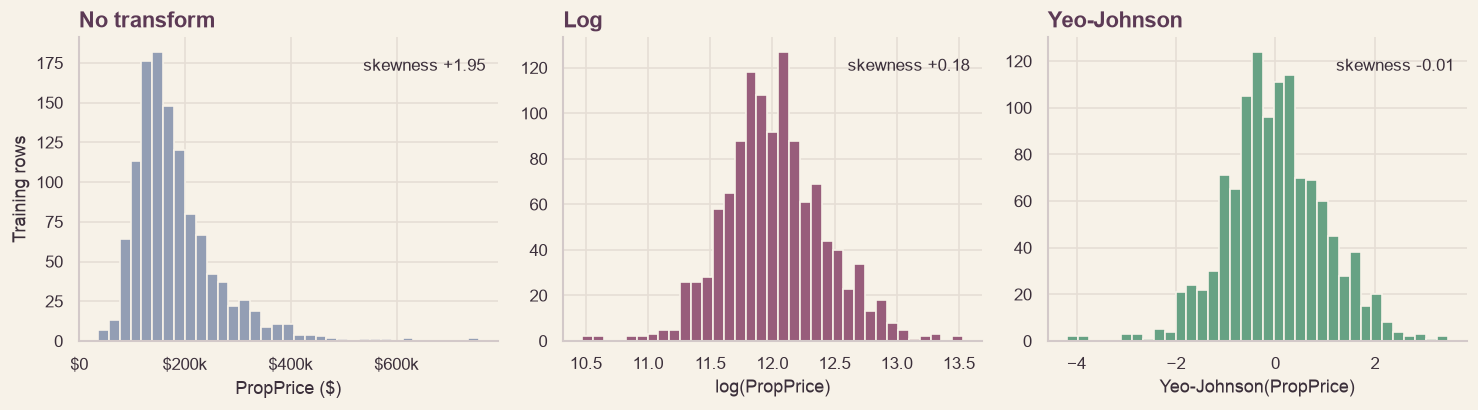

Target,RMSE ($),MAE ($),R²,RMSE: change vs log,MAE: change vs log,R²: change vs log
No transform,"$34,336","$19,279",0.811,"-$14,426 (95 % CI -$30,031 to +$169)","+$1,391 (95 % CI +$341 to +$2,324)",+0.353 (95 % CI +0.005 to +0.759)
Log,"$48,762","$17,889",0.458,–,–,–
Yeo-Johnson,"$58,763","$18,701",0.026,"+$10,001 (95 % CI +$903 to +$21,201)","+$812 (95 % CI +$203 to +$1,559)",-0.433 (95 % CI -1.010 to -0.012)


Target,Residual skewness,Residual excess kurtosis,"Spearman(|residual|, fitted)"
No transform,-4.16,+100.5,+0.22
Log,-4.46,+62.1,-0.06
Yeo-Johnson,-4.04,+49.7,-0.09



Rule: keep the log unless another scale cuts dollar RMSE by at least 2% of the log RMSE ($975) with a 95 % interval below 0.
Result: Log.
Check on the log residuals: |Spearman| = 0.06 (within the 0.2 warning limit).

✅ Target scale chosen. Section 3 decisions so far: 18


In [21]:
from sklearn.compose import TransformedTargetRegressor
from sklearn.preprocessing import PowerTransformer
from sklearn.model_selection import KFold

X, y = X_train_clean, y_train                          # training rows only
base = build_model(**IMPUTER_CHOICE)                   # the imputation design from 3.7, with the same fixed Ridge

def signed_money(x):
    return f'{"+" if x >= 0 else "-"}${abs(x):,.0f}'
def change_text(ci, kind):
    """'estimate (95 % CI low to high)' for a change; dollars with a sign, R² with three decimals."""
    f = signed_money if kind != 'R²' else (lambda v: f'{v:+.3f}')
    return f'{f(ci["estimate"])} (95 % CI {f(ci["lo"])} to {f(ci["hi"])})'

TARGETS = {'No transform': lambda: clone(base),
           'Log':          lambda: TransformedTargetRegressor(regressor=clone(base), func=np.log, inverse_func=np.exp),
           'Yeo-Johnson':  lambda: TransformedTargetRegressor(regressor=clone(base), transformer=PowerTransformer(method='yeo-johnson'))}

# ── 1. Shape of the target on each scale (training rows; lambda is fitted on all training rows for DISPLAY only) ──
yj = PowerTransformer(method='yeo-johnson').fit(y.to_numpy().reshape(-1, 1))
scales = {'No transform': y.to_numpy(), 'Log': np.log(y.to_numpy()), 'Yeo-Johnson': yj.transform(y.to_numpy().reshape(-1, 1)).ravel()}
shape = pd.DataFrame([(k, stats.skew(v), stats.kurtosis(v)) for k, v in scales.items()], columns=['Scale', 'Skewness', 'Excess kurtosis'])
show_table(shape, formats={'Skewness': '{:+.2f}', 'Excess kurtosis': '{:+.2f}'}, caption=f'Shape of PropPrice on each scale (Yeo-Johnson lambda = {yj.lambdas_[0]:+.3f})')

fig, axes = plt.subplots(1, 3, figsize=(12.5, 3.6))
for ax, (name, v), colour, xlabel in zip(axes, scales.items(), (SLATE_BLUE, MAUVE, SAGE_GREEN), ('PropPrice ($)', 'log(PropPrice)', 'Yeo-Johnson(PropPrice)')):
    ax.hist(v, bins=35, color=colour, edgecolor=CREAM)
    ax.set_title(name, loc='left'); ax.set_xlabel(xlabel); ax.set_ylabel('Training rows' if name == 'No transform' else '')
    ax.text(0.97, 0.93, f'skewness {stats.skew(v):+.2f}', transform=ax.transAxes, ha='right', va='top', fontsize=10, color=INK)
    if name == 'No transform':
        ax.set_xticks([0, 200_000, 400_000, 600_000]); ax.set_xticklabels(['$0', '$200k', '$400k', '$600k'])
fig.tight_layout(); save_fig(fig, '05_target_scales', section='3'); plt.show()

# ── 2. Dollar-scale errors on the same 15 folds, with every fitted step (including lambda) learned inside the fold ──
folds = RepeatedKFold(n_splits=5, n_repeats=3, random_state=SEEDS['repeated_cv'])
fold_scores = {name: {'RMSE': [], 'MAE': [], 'R²': []} for name in TARGETS}
for tr, te in folds.split(X):
    for name, make in TARGETS.items():
        m = make().fit(X.iloc[tr], y.iloc[tr])
        mt = regression_metrics(y.iloc[te], m.predict(X.iloc[te]))
        for k in ('RMSE', 'MAE', 'R²'):
            fold_scores[name][k].append(mt[k])
fold_scores = {n: {k: np.array(v) for k, v in d.items()} for n, d in fold_scores.items()}

rows = []
for name in TARGETS:
    row = {'Target': name, 'RMSE ($)': fold_scores[name]['RMSE'].mean(), 'MAE ($)': fold_scores[name]['MAE'].mean(), 'R²': fold_scores[name]['R²'].mean()}
    for k in ('RMSE', 'MAE', 'R²'):
        if name == 'Log':
            row[f'{k}: change vs log'] = '–'
        else:
            d = fold_scores[name][k] - fold_scores['Log'][k]
            row[f'{k}: change vs log'] = change_text(bootstrap_ci(np.mean, d, n_boot=2000), k)
    rows.append(row)
CMP = pd.DataFrame(rows)
show_table(CMP, formats={'RMSE ($)': '${:,.0f}', 'MAE ($)': '${:,.0f}', 'R²': '{:.3f}'}, caption='FIRST PASS on the pre-guard pipeline (superseded by Table Q6 in 3.10): dollar-scale errors, 15 paired folds')

# ── 3. Do the errors behave on the model's own scale? One 5-fold pass of out-of-fold residuals ──
diag = []
for name, make in TARGETS.items():
    res, fit = [], []
    for tr, te in KFold(5, shuffle=True, random_state=SEEDS['cv']).split(X):
        m = make().fit(X.iloc[tr], y.iloc[tr]); pred = m.predict(X.iloc[te])
        to_scale = m.transformer_.transform if hasattr(m, 'transformer_') else (lambda a: a)
        y_s, p_s = to_scale(y.iloc[te].to_numpy().reshape(-1, 1)).ravel(), to_scale(pred.reshape(-1, 1)).ravel()
        res.append(y_s - p_s); fit.append(p_s)
    res, fit = np.concatenate(res), np.concatenate(fit)
    diag.append({'Target': name, 'Residual skewness': stats.skew(res), 'Residual excess kurtosis': stats.kurtosis(res),
                 'Spearman(|residual|, fitted)': stats.spearmanr(np.abs(res), fit)[0]})
DIAG = pd.DataFrame(diag)
show_table(DIAG, formats={'Residual skewness': '{:+.2f}', 'Residual excess kurtosis': '{:+.1f}', 'Spearman(|residual|, fitted)': '{:+.2f}'},
           caption='Out-of-fold residuals on each model\'s own scale (a Spearman far from 0 means the spread changes with the price level)')

# ── 4. The rule, fixed before the run ──
REL_GAIN, HETERO_LIMIT = 0.02, 0.20
log_rmse = fold_scores['Log']['RMSE'].mean()
verdicts = {}
for name in ('No transform', 'Yeo-Johnson'):
    d = fold_scores[name]['RMSE'] - fold_scores['Log']['RMSE']; ci = bootstrap_ci(np.mean, d, n_boot=2000)
    verdicts[name] = (ci['estimate'], ci['lo'], ci['hi'], ci['estimate'] <= -REL_GAIN * log_rmse and ci['hi'] < 0)
log_hetero = abs(DIAG.loc[DIAG['Target'] == 'Log', 'Spearman(|residual|, fitted)'].iloc[0])
better = [n for n, v in verdicts.items() if v[3]]
TARGET_TRANSFORM = min(better, key=lambda n: verdicts[n][0]) if better else 'Log'
print(f'\nRule: keep the log unless another scale cuts dollar RMSE by at least {REL_GAIN:.0%} of the log RMSE (${REL_GAIN * log_rmse:,.0f}) with a 95 % interval below 0.\nResult: {TARGET_TRANSFORM}.')
print(f'Check on the log residuals: |Spearman| = {log_hetero:.2f} ({"within" if log_hetero <= HETERO_LIMIT else "ABOVE"} the {HETERO_LIMIT} warning limit).')

# ── Decisions ──
n_gain, n_lo, n_hi, _ = verdicts['No transform']; y_gain, y_lo, y_hi, _ = verdicts['Yeo-Johnson']
DECISIONS.add('3.8', 'Which scale should the target be modelled on: none, log or Yeo-Johnson?',
    f'Skewness of PropPrice on each scale; dollar-scale RMSE, MAE and R² on the same 15 folds with every fitted step (including the Yeo-Johnson lambda) inside the fold; out-of-fold residuals on each model\'s own scale. Rule fixed in advance: keep the log unless another scale lowers RMSE by at least {REL_GAIN:.0%} (${REL_GAIN * log_rmse:,.0f}) with a 95 % interval below 0, or the log residuals fan out (|Spearman| above {HETERO_LIMIT}).',
    f'Skewness {stats.skew(scales["No transform"]):+.2f} raw, {stats.skew(scales["Log"]):+.2f} log, {stats.skew(scales["Yeo-Johnson"]):+.2f} Yeo-Johnson (lambda {yj.lambdas_[0]:+.3f}). '
    f'RMSE change vs log: no transform {signed_money(n_gain)} (95 % CI {signed_money(n_lo)} to {signed_money(n_hi)}), Yeo-Johnson {signed_money(y_gain)} (95 % CI {signed_money(y_lo)} to {signed_money(y_hi)}). '
    f'MAE change vs log: no transform {signed_money(fold_scores["No transform"]["MAE"].mean() - fold_scores["Log"]["MAE"].mean())}. '
    f'Residual spread vs price level (Spearman): ' + ', '.join(f'{t} {v:+.2f}' for t, v in zip(DIAG['Target'], DIAG['Spearman(|residual|, fitted)'])) + '.',
    f'{TARGET_TRANSFORM}. ' + ('No scale beats it by the margin set in advance, and its residuals do not fan out with price; it also reads as a percentage change and has no fitted parameter. '
                              'First pass on the pre-guard pipeline, where the log model was inflated by the extrapolation problem found in 3.10 (Q0). Re-checked under the tail guard in 3.10, Q6 (see the later decision).'),
    'Changes the workflow')
print(f'\n✅ Target scale chosen. Section 3 decisions so far: {len(DECISIONS.to_frame("3"))}')

**Reading.** PropPrice is strongly right-skewed (skewness +1.95). The log removes most of it (+0.18) and Yeo-Johnson (λ = −0.115) all of it (−0.01). Scored in dollars on 15 paired folds, with every fitted step inside the fold and the final linear design including the tail guard (Table Q6, 3.10), the log model has the lowest RMSE ($31,027) and MAE ($15,874) and the highest R² (0.840). It beats no transform by $2,131 on RMSE (95 % CI +$409 to +$3,802) and $3,540 on MAE, and Yeo-Johnson by $712 on RMSE (CI +$119 to +$1,368) with equal MAE (difference $76, CI −$20 to +$175); the R² differences are within noise (against no transform −0.015, CI −0.032 to +0.003). Neither alternative meets the rule fixed in advance: cut dollar RMSE by at least 2 % of the log RMSE ($621) with a 95 % interval below 0.

The first-pass tables above were run on the pre-guard pipeline, where the log model scored $48,762 RMSE. That was the extrapolation problem found in 3.10 (Q0), not a property of the log scale, and Table Q6 in 3.10 supersedes them.

**Decision.** Log. It also reads as a percentage effect and has no fitted parameter. The back-transformation is checked in 10.8.

## 3.9 The Metadata Sheet: Numeric, Binary, Ordinal or Nominal

**Research question.** The brief asks for ordinal and nominal columns to be handled separately, using a metadata sheet, but no metadata sheet was supplied. Which of the 79 predictors are numeric, binary, ordinal or nominal, which of the orders are assumptions, and do the assumed orders agree with the price?

**Method.** Training rows only. *Classification:* from the brief's descriptions (with the corrections from 3.2) and the label sets in the training rows, with two assertions: every predictor is classified exactly once, and every label in the training rows sits inside its declared scale. *Order check:* for each ordinal column, the Spearman correlation between level rank and log price (bootstrap CI) and the direction of the median price across the levels that have at least 30 rows. **Rule:** an order is *supported* if the median price moves in one direction (a falling price is still a valid order) and |Spearman| is at least 0.10. This is evidence about an assumption, not a selection rule: no column is dropped, as the brief requires.

**Decision.** The sheet and the scales are fixed for the rest of the notebook. Columns whose order is not supported are tested as nominal in 3.10 (D30).

Column,Meaning (corrected),Kind,Levels in training,Smallest level (rows),"Order, low → high",Where the order comes from
PropertyClass,Building class (a code),nominal,15,40 (1),,
PropertyZone,Zoning classification,nominal,5,C (all) (8),,
PropertyFrontage,Street frontage (ft),numeric: size / amount,,,,
PropertySize,Lot size (sq ft),numeric: size / amount,,,,
Street,Road access,binary,2,Grvl (3),"Grvl < Pave (coded 0, 1)",
Alley,Alley access (None = no alley),nominal,3,Pave (29),,
PropertyShape,Lot shape,ordinal,4,IR3 (10),IR3 < IR2 < IR1 < Reg,"lot regularity, most irregular to regular"
Elevation,Land contour (flatness),nominal,4,Low (29),,
Amenities,Utilities available,binary,2,NoSeWa (1),"NoSeWa < AllPub (coded 0, 1)",
Orientation,Lot configuration (brief: LotOrientation),nominal,5,FR3 (4),,



Kinds: numeric 34, nominal 23, ordinal 19, binary 3  (total 79). Declared levels absent from the training rows: ExterQual: Po; KitchenQual: Po; BsmntFinish: Po; BsmntMaintenance: Ex; Functional: Sal; PoolQC: TA


Column,Spearman rank vs log price,CI low,CI high,Levels with ≥ 30 rows,Median price across them,Order supported
ExterQual,+0.69,+0.66,+0.72,3,rising,yes
KitchenQual,+0.69,+0.65,+0.72,4,rising,yes
BsmntFinish,+0.68,+0.64,+0.71,4,rising,yes
BasementFinish,+0.64,+0.60,+0.67,4,rising,yes
QualFireplace,+0.54,+0.50,+0.59,3,rising,yes
HeatingEfficiency,+0.50,+0.45,+0.54,4,rising,yes
BsmntFinRat1,+0.38,+0.33,+0.44,7,mixed,no: mixed order
BasementQual,+0.36,+0.32,+0.41,3,rising,yes
BsmntVisibility,+0.35,+0.30,+0.40,5,rising,yes
BasementCond,+0.35,+0.30,+0.40,2,rising,yes



Rule: an order is "supported" if the median price across the levels with ≥ 30 rows moves in ONE direction (rising or falling: a falling price is still a valid order) and |Spearman| is at least 0.10; "no: mixed order" if it zig-zags, "no: too weak" if |Spearman| is below 0.10, "untestable" if fewer than two levels have 30 rows.
Not supported: ['BsmntFinRat1', 'BsmntFinQual1', 'Grade', 'ExterCond', 'BoundaryFeatures'].  Untestable: ['Functional', 'PoolQC'].


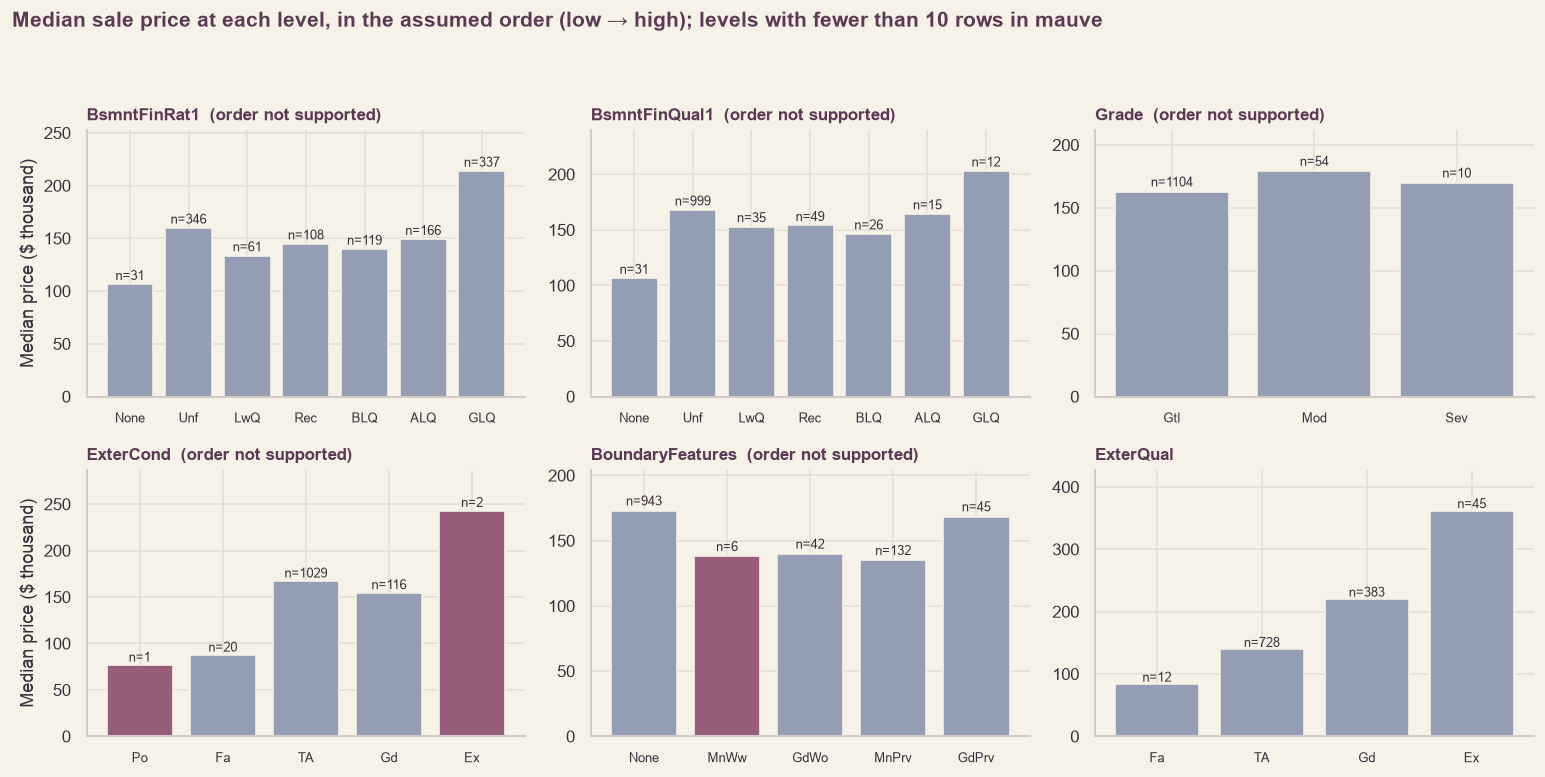


✅ Metadata sheet built and checked. Section 3 decisions so far: 19


In [22]:
# ── 3.9 The metadata sheet: every predictor is numeric, binary, ordinal or nominal, and the order assumptions are written down ──
from scipy.stats import spearmanr

X, y = X_train_clean, y_train                          # training rows only
y_log = np.log(y)
Q5 = ['Po', 'Fa', 'TA', 'Gd', 'Ex']                    # the quality scale used across the dataset, poor to excellent

# Ordinal text columns: levels listed LOW → HIGH, with where the order comes from. 'None' (feature absent) is placed below the lowest grade: an assumption.
ORDINAL_SCALES = {
    'ExterQual':        (Q5,                                          'scale in the brief (Poor to Excellent)'),
    'ExterCond':        (Q5,                                          'scale in the brief (Poor to Excellent)'),
    'HeatingEfficiency':(Q5,                                          'scale in the brief (Poor to Excellent)'),
    'KitchenQual':      (Q5,                                          'scale in the brief (Poor to Excellent)'),
    'BsmntFinish':      (['None'] + Q5,                               'height classes read as a quality scale; None placed lowest (assumption)'),
    'BsmntMaintenance': (['None'] + Q5,                               'quality scale; None placed lowest (assumption)'),
    'BsmntVisibility':  (['None', 'No', 'Mn', 'Av', 'Gd'],            'exposure scale; None placed lowest (assumption)'),
    'BsmntFinRat1':     (['None', 'Unf', 'LwQ', 'Rec', 'BLQ', 'ALQ', 'GLQ'], 'finish scale; the order of Rec and BLQ is an assumption; None placed lowest (assumption)'),
    'BsmntFinQual1':    (['None', 'Unf', 'LwQ', 'Rec', 'BLQ', 'ALQ', 'GLQ'], 'finish scale; the order of Rec and BLQ is an assumption; None placed lowest (assumption)'),
    'Functional':       (['Sal', 'Sev', 'Maj2', 'Maj1', 'Mod', 'Min2', 'Min1', 'Typ'], 'deductions scale, most to least serious'),
    'QualFireplace':    (['None'] + Q5,                               'quality scale; None placed lowest (assumption)'),
    'BasementFinish':   (['None', 'Unf', 'RFn', 'Fin'],               'garage finish: unfinished to finished; None placed lowest (assumption)'),
    'BasementQual':     (['None'] + Q5,                               'garage quality; None placed lowest (assumption)'),
    'BasementCond':     (['None'] + Q5,                               'garage condition; None placed lowest (assumption)'),
    'PavedDrive':       (['N', 'P', 'Y'],                             'dirt or gravel, partial, paved'),
    'PoolQC':           (['None', 'Fa', 'TA', 'Gd', 'Ex'],            'quality scale; None placed lowest (assumption)'),
    'BoundaryFeatures': (['None', 'MnWw', 'GdWo', 'MnPrv', 'GdPrv'],  'fence: the order is an ASSUMPTION (privacy and material are two different dimensions)'),
    'PropertyShape':    (['IR3', 'IR2', 'IR1', 'Reg'],                'lot regularity, most irregular to regular'),
    'Grade':            (['Gtl', 'Mod', 'Sev'],                       'slope, gentle to severe'),
}
BINARY_CODING = {'Street': ['Grvl', 'Pave'], 'CentralAir': ['N', 'Y'], 'Amenities': ['NoSeWa', 'AllPub']}     # [coded 0, coded 1]
SCORE_COLS, YEAR_COLS = ['OverallQual', 'OverallCond'], ['YearBuilt', 'YearRemodAdd', 'BasementYrBlt', 'SaleYr']
ORD_COLS, BIN_COLS = list(ORDINAL_SCALES), list(BINARY_CODING)
NOM_COLS = [c for c in TEXT_PRED if c not in ORD_COLS + BIN_COLS]
NUM_COLS = list(NUMERIC_PRED)
SIZE_COLS = [c for c in NUM_COLS if c not in SCORE_COLS + YEAR_COLS + COUNT_COLS]

MEANING = {
 'PropertyClass': 'Building class (a code)', 'PropertyZone': 'Zoning classification', 'PropertyFrontage': 'Street frontage (ft)', 'PropertySize': 'Lot size (sq ft)',
 'Street': 'Road access', 'Alley': 'Alley access (None = no alley)', 'PropertyShape': 'Lot shape', 'Elevation': 'Land contour (flatness)', 'Amenities': 'Utilities available',
 'Orientation': 'Lot configuration (brief: LotOrientation)', 'Grade': 'Land slope', 'Neighborhood': 'Neighbourhood in Ames', 'Condition1': 'Proximity to main road or railroad',
 'Condition2': 'Second proximity condition', 'BldgType': 'Type of dwelling', 'PropertyStyle': 'Style of dwelling', 'OverallQual': 'Overall material and finish quality (1 to 10)',
 'OverallCond': 'Overall condition (1 to 10)', 'YearBuilt': 'Year built', 'YearRemodAdd': 'Year of remodel', 'RoofStyle': 'Roof style', 'RoofMatl': 'Roof material',
 'Roof1Material': 'EXTERIOR covering, first (the name says roof)', 'Roof2Material': 'EXTERIOR covering, second (the name says roof)', 'ExteriorCladdingType': 'Masonry veneer type',
 'ExteriorCladdingArea': 'Masonry veneer area (sq ft)', 'ExterQual': 'Exterior material quality', 'ExterCond': 'Exterior condition', 'PropertyFooting': 'Foundation type',
 'BsmntFinish': 'Basement height class', 'BsmntMaintenance': 'Basement condition', 'BsmntVisibility': 'Basement exposure (walkout / garden level)',
 'BsmntFinRat1': 'Rating of basement finished area, type 1', 'BsmntFinSty1': 'Basement finished area, type 1 (sq ft)', 'BsmntFinQual1': 'Rating of second finished basement area',
 'BsmtFinSF2': 'Basement finished area, type 2 (sq ft)', 'BsmtUnfSF': 'Basement unfinished area (sq ft)', 'BsmntSqFtage': 'Basement total area (sq ft)', 'Heating': 'Heating type',
 'HeatingEfficiency': 'Heating quality and condition', 'CentralAir': 'Central air conditioning', 'Electrical': 'Electrical system', '1stFlrSF': 'First floor (sq ft)',
 '2ndFlrSF': 'Second floor (sq ft)', 'LowQualFinSF': 'Low-quality finished area (sq ft)', 'GrLivArea': 'Above-grade living area (sq ft)', 'BsmtFullBath': 'Basement full bathrooms',
 'BsmtHalfBath': 'Basement half bathrooms', 'Bath1': 'Full bathrooms above grade', 'Bath2': 'Half bathrooms above grade', 'BedroomUpLev': 'Bedrooms above basement level',
 'KitchenUpLev': 'Kitchens above grade (brief: Kitchen)', 'KitchenQual': 'Kitchen quality', 'CntRmsUpLev': 'Rooms above grade (no bathrooms)', 'Functional': 'Home functionality rating',
 'CntFireplaces': 'Number of fireplaces', 'QualFireplace': 'Fireplace quality', 'BasementType': 'GARAGE type (the name says basement)', 'BasementYrBlt': 'GARAGE year built',
 'BasementFinish': 'GARAGE interior finish', 'BasementCars': 'GARAGE capacity (cars)', 'BasementSqFootage': 'GARAGE area (sq ft)', 'BasementQual': 'GARAGE quality',
 'BasementCond': 'GARAGE condition', 'PavedDrive': 'Paved driveway', 'WoodDeckSF': 'Wood deck area (sq ft)', 'OpenPorchSF': 'Open porch area (sq ft)',
 'EnclosedPorch': 'Enclosed porch area (sq ft)', '3SsnPorch': 'Three-season porch area (sq ft)', 'ScreenPorch': 'Screen porch area (sq ft)', 'PoolArea': 'Pool area (sq ft)',
 'PoolQC': 'Pool quality', 'BoundaryFeatures': 'Fence quality', 'AddFeatures': 'Miscellaneous feature', 'AddVal': 'Value of the miscellaneous feature ($)',
 'SaleMon': 'Month sold (a code)', 'SaleYr': 'Year sold', 'SaleType': 'Type of sale', 'SaleCondn': 'Condition of sale'}

# ── Checks: every predictor classified exactly once; every training label is in its declared scale ──
groups = {'numeric': NUM_COLS, 'binary': BIN_COLS, 'ordinal': ORD_COLS, 'nominal': NOM_COLS}
all_cols = sum(groups.values(), [])
assert sorted(all_cols) == sorted(X.columns), 'a predictor is missing from the sheet, or is listed twice'
assert set(MEANING) == set(X.columns), 'a predictor has no meaning in the sheet'
for c, (order, _) in ORDINAL_SCALES.items():
    stray = set(X[c].dropna().unique()) - set(order)
    assert not stray, f'{c}: labels in training that are not in the declared order: {stray}'
for c, order in BINARY_CODING.items():
    assert set(X[c].unique()) == set(order), f'{c} is not binary in the training rows'
assert set(TEXT_PRED) == set(BIN_COLS + ORD_COLS + NOM_COLS) and set(NUMERIC_PRED) == set(NUM_COLS)

# ── The sheet ──
def kind_of(c):
    if c in BIN_COLS: return 'binary'
    if c in ORD_COLS: return 'ordinal'
    if c in NOM_COLS: return 'nominal'
    return 'numeric: ' + ('score' if c in SCORE_COLS else 'year' if c in YEAR_COLS else 'count' if c in COUNT_COLS else 'size / amount')
rows = []
for c in X.columns:
    vc = X[c].value_counts(dropna=True) if c not in NUM_COLS else None
    rows.append({'Column': c, 'Meaning (corrected)': MEANING[c], 'Kind': kind_of(c),
                 'Levels in training': int(len(vc)) if vc is not None else None,
                 'Smallest level (rows)': f'{vc.index[-1]} ({vc.iloc[-1]})' if vc is not None else '',
                 'Order, low → high': ' < '.join(ORDINAL_SCALES[c][0]) if c in ORD_COLS else (' < '.join(BINARY_CODING[c]) + ' (coded 0, 1)') if c in BIN_COLS else '',
                 'Where the order comes from': ORDINAL_SCALES[c][1] if c in ORD_COLS else ''})
META = pd.DataFrame(rows)
show_table(META, formats={'Levels in training': lambda v: '' if pd.isna(v) else f'{int(v)}'}, caption='Metadata sheet: all 79 predictors (training rows). Corrections to the brief are in capitals.')
counts = META['Kind'].str.split(':').str[0].value_counts()
print(f'\nKinds: ' + ', '.join(f'{k} {v}' for k, v in counts.items()) + f'  (total {counts.sum()}). Declared levels absent from the training rows: ' +
      '; '.join(f'{c}: {", ".join(sorted(set(o) - set(X[c].dropna().unique())))}' for c, (o, _) in ORDINAL_SCALES.items() if set(o) - set(X[c].dropna().unique())))

# ── Do the assumed orders agree with price? (evidence about the assumption, not a selection rule) ──
MIN_LEVEL, SOLID_LEVEL = 10, 30
y_log_arr = np.asarray(y_log, dtype=float)
chk = []
for c, (order, _) in ORDINAL_SCALES.items():
    rank_all = X[c].map({lv: i for i, lv in enumerate(order)}).to_numpy(float)
    ok = ~np.isnan(rank_all)                           # rows still missing after 3.5 (e.g. the one existing-basement row) have no rank
    rank, price = rank_all[ok], y_log_arr[ok]
    if np.unique(rank).size < 2:                       # constant column: Spearman is undefined
        rho = {'estimate': np.nan, 'lo': np.nan, 'hi': np.nan}
    else:
        rho = bootstrap_ci(lambda r, p: spearmanr(r, p)[0], rank, price, n_boot=500, on_invalid='drop', max_invalid_frac=0.2)
    med = pd.DataFrame({'lv': X[c], 'lp': y_log}).groupby('lv')['lp'].agg(['median', 'size']).reindex(order).dropna()
    solid = med[med['size'] >= SOLID_LEVEL]
    steps = np.diff(solid['median'].to_numpy())
    direction = 'too few levels' if len(solid) < 2 else 'rising' if (steps >= 0).all() else 'falling' if (steps <= 0).all() else 'mixed'
    verdict = ('untestable' if direction == 'too few levels' or np.isnan(rho['estimate'])
               else 'no: mixed order' if direction == 'mixed'
               else 'no: too weak' if abs(rho['estimate']) < 0.10 else 'yes')
    chk.append({'Column': c, 'Spearman rank vs log price': rho['estimate'], 'CI low': rho['lo'], 'CI high': rho['hi'],
                f'Levels with ≥ {SOLID_LEVEL} rows': len(solid), 'Median price across them': direction, 'Order supported': verdict})
ORDER_CHECK = pd.DataFrame(chk).sort_values('Spearman rank vs log price', ascending=False, na_position='last').reset_index(drop=True)
show_table(ORDER_CHECK, formats={'Spearman rank vs log price': '{:+.2f}', 'CI low': '{:+.2f}', 'CI high': '{:+.2f}'},
           caption=f'Assumed order against price: Spearman, and the direction of the median price across the levels with at least {SOLID_LEVEL} rows')
FLAGGED = ORDER_CHECK.loc[ORDER_CHECK['Order supported'].str.startswith('no'), 'Column'].tolist()
UNTESTABLE = ORDER_CHECK.loc[ORDER_CHECK['Order supported'] == 'untestable', 'Column'].tolist()
print(f'\nRule: an order is "supported" if the median price across the levels with ≥ {SOLID_LEVEL} rows moves in ONE direction (rising or falling: a falling price is still a valid order) and |Spearman| is at least 0.10; "no: mixed order" if it zig-zags, "no: too weak" if |Spearman| is below 0.10, "untestable" if fewer than two levels have {SOLID_LEVEL} rows.')
print(f'Not supported: {FLAGGED if FLAGGED else "none"}.  Untestable: {UNTESTABLE if UNTESTABLE else "none"}.')

# ── Figure: the median price by level for the columns whose order is least secure ──
show_cols = (FLAGGED + [c for c in ORDER_CHECK['Column'] if c not in FLAGGED])[:6]
fig, axes = plt.subplots(2, 3, figsize=(13, 6.6))
for ax, c in zip(axes.ravel(), show_cols):
    order = ORDINAL_SCALES[c][0]
    g = pd.DataFrame({'lv': X[c], 'p': y}).groupby('lv')['p'].agg(['median', 'size']).reindex(order).dropna()
    ax.bar(g.index, g['median'] / 1000, color=[MAUVE if n < MIN_LEVEL else SLATE_BLUE for n in g['size']], edgecolor=CREAM)
    for i, (m, n) in enumerate(zip(g['median'], g['size'])):
        ax.text(i, m / 1000 + 4, f'n={int(n)}', ha='center', fontsize=7.5, color=INK)
    ax.set_title(f'{c}' + ('  (order not supported)' if c in FLAGGED else ''), loc='left', fontsize=10)
    ax.set_ylabel('Median price ($ thousand)' if ax in axes[:, 0] else ''); ax.tick_params(axis='x', labelsize=8)
    ax.set_ylim(0, max(g['median'] / 1000) * 1.18)
fig.suptitle('Median sale price at each level, in the assumed order (low → high); levels with fewer than 10 rows in mauve', x=0.01, ha='left', fontsize=12.5, fontweight='bold', color=DEEP_PLUM)
fig.tight_layout(rect=(0, 0, 1, 0.94)); save_fig(fig, '06_ordinal_order_check', section='3'); plt.show()

# ── Decisions ──
bad = ORDER_CHECK[ORDER_CHECK['Order supported'].str.startswith('no')]
bad_text = ', '.join(f'{col} ({verdict[4:]})' for col, verdict in zip(bad['Column'], bad['Order supported'])) if len(bad) else 'none'
DECISIONS.add('3.9', 'How is each of the 79 predictors classified (numeric, binary, ordinal, nominal), and which orders are assumptions?',
    'Classify from the brief\'s descriptions and the label sets in the training rows; assert that every predictor is classified once and that every training label sits inside its declared scale. Check each assumed order against the direction of the median price across the levels with at least 30 rows (one direction, rising or falling, counts as ordered) and against the Spearman correlation with log price (bootstrap CI, |Spearman| of at least 0.10). Rows still missing after 3.5 are left out of the Spearman step. The check is evidence about the assumption, not a selection rule.',
    f'{counts.get("numeric", 0)} numeric, {counts.get("binary", 0)} binary, {counts.get("ordinal", 0)} ordinal, {counts.get("nominal", 0)} nominal. '
    f'{int((ORDER_CHECK["Order supported"] == "yes").sum())} of {len(ORDER_CHECK)} orders are supported by the price data, {len(UNTESTABLE)} cannot be tested ({", ".join(UNTESTABLE) if UNTESTABLE else "none"}), and {len(bad)} are not supported: {bad_text}.',
    'The sheet (META) and the scales (ORDINAL_SCALES, BINARY_CODING) are fixed for the rest of the notebook. ' + (f'The columns whose order is not supported ({", ".join(FLAGGED)}) are tested as nominal in 3.10.' if FLAGGED else 'All orders are kept.') +
    ' Street, CentralAir and Amenities are binary, not ordinal; Street (4 Grvl rows) and Amenities (1 NoSeWa row) are nearly constant and are kept, as the brief requires. Electrical (one mixed level), Elevation and Alley have no clear order and are nominal. The scales come from the brief\'s descriptions and the usual coding of this dataset, not from a metadata file, because none was supplied.',
    'Changes the workflow')
print(f'\n✅ Metadata sheet built and checked. Section 3 decisions so far: {len(DECISIONS.to_frame("3"))}')

**Reading.** All 79 predictors are classified once: 34 numeric, 3 binary, 19 ordinal and 23 nominal. The sheet corrects the brief where its names mislead (the seven Basement… columns from BasementType to BasementCond describe the garage; Roof1Material and Roof2Material describe the exterior covering). Of the 19 assumed orders, 12 are supported by the price data (for example ExterQual ρ = +0.69, KitchenQual +0.69, BsmntFinish +0.68). PropertyShape is supported as a falling order (ρ = −0.32). Two cannot be tested (Functional, PoolQC: fewer than two levels have 30 rows) and five are not supported: BsmntFinRat1, BsmntFinQual1 and BoundaryFeatures (mixed order), Grade and ExterCond (|ρ| below 0.10). The orders come from the brief's descriptions because no metadata file was supplied.

**Decision.** The sheet is fixed from here on. The five unsupported orders are tested as nominal in 3.10.

## 3.10 Encoding Design

**Research question.** What is the proper encoding for each kind of column (brief objectives 3 and 5): the 19 ordinal columns, the 23 nominal ones, SaleMon, the binary columns, the numbers, and the inputs of a tree model?

**Method.** Training rows only, the same 15 folds, the 3.7 imputation, the log target from 3.8 and the same `compare()` rule: the simplest option is the baseline, and a challenger replaces it only if it lowers RMSE (log) by at least 0.002 with a 95 % interval below 0. The linear-family probe is a ridge model whose penalty is chosen *inside each fold*, because a fixed penalty would favour whichever encoding adds fewer columns; this is a deliberate change from the fixed penalty used in 3.7. Five questions: **Q1** ordinal columns as declared-order codes, one-hot, both, or codes with the five unsupported orders as one-hot; **Q2** nominal one-hot with every level or with rare levels pooled; **Q3** SaleMon as one-hot or as a sine and cosine pair (the question left open in 3.5); **Q4** standardised or raw numbers (the brief's scaling objective); **Q5** for gradient boosting, one-hot or native categories for the nominal columns. Binary columns are coded 0 and 1 once, with a stated reference level; two levels carry the same information in either form, so no comparison is needed. Every block has a fallback imputer and tolerates labels it has never seen, and the final design is tested on 60 training rows with problems created on purpose.

**Decision.** Fixed by the rule, and recorded as D31 to D34.

In [23]:
# ── 3.10 Encoding design: ordinal vs nominal vs binary, handled separately (training rows only, same 15 folds as 3.7) ──
from sklearn.preprocessing import OrdinalEncoder, FunctionTransformer
from sklearn.linear_model import RidgeCV
from sklearn.ensemble import HistGradientBoostingRegressor

X, y = X_train_clean, y_train
y_log = np.log(y)                                       # the log target chosen in 3.8
ORD_CATS = [ORDINAL_SCALES[c][0] for c in ORD_COLS]
BIN_CATS = [BINARY_CODING[c] for c in BIN_COLS]
RIDGE_ALPHAS = np.logspace(-1, 3, 17)                   # the penalty is chosen INSIDE each fold: a fixed penalty would favour whichever encoding adds fewer columns

def _month_angle(df):
    m = np.asarray(df)[:, 0].astype(float)
    a = 2 * np.pi * (m - 1) / 12
    return np.column_stack([np.sin(a), np.cos(a)])

def clip_z(a, c):
    """Cap standardised values at ±c so one extreme property cannot extrapolate a linear model."""
    return np.clip(a, -c, c)

def make_preprocessor(ordinal='codes', ordinal_as_nominal=(), nominal_min_freq=None, month='onehot', scale=True, tail=None):
    """The encoding design for the linear family. Binary and ordinal columns are coded by DECLARED order (META), numbers are imputed and scaled,
    nominal columns are one-hot encoded. Every block has a fallback imputer and tolerates labels it has never seen (they become a missing value
    that is filled, an all-zero one-hot row, or the 'infrequent' column)."""
    ordinal_as_nominal = tuple(ordinal_as_nominal)
    num_steps = [('imp', SimpleImputer(strategy='median'))] + ([('sc', StandardScaler())] if scale else [])
    if scale and tail:
        num_steps.append(('zclip', FunctionTransformer(clip_z, kw_args={'c': tail}, feature_names_out='one-to-one')))
    
    def coded(cats, strategy):
        return Pipeline([('enc', OrdinalEncoder(categories=cats, handle_unknown='use_encoded_value', unknown_value=np.nan)),
                         ('imp', SimpleImputer(strategy=strategy))] + ([('sc', StandardScaler())] if scale else []))
    def onehot(cats='auto', min_freq=None):
        return Pipeline([('imp', SimpleImputer(strategy='most_frequent')),
                         ('oh', OneHotEncoder(categories=cats, handle_unknown='infrequent_if_exist' if cats == 'auto' else 'ignore', min_frequency=min_freq, sparse_output=False))])
    blocks = [('num', Pipeline(num_steps), NUM_COLS), ('bin', coded(BIN_CATS, 'most_frequent'), BIN_COLS)]
    code_cols = [c for c in ORD_COLS if c not in ordinal_as_nominal] if ordinal in ('codes', 'both') else []
    hot_cols  = ORD_COLS if ordinal in ('onehot', 'both') else list(ordinal_as_nominal)
    if code_cols: blocks.append(('ord_codes', coded([ORDINAL_SCALES[c][0] for c in code_cols], 'median'), code_cols))
    if hot_cols:  blocks.append(('ord_hot', onehot([ORDINAL_SCALES[c][0] for c in hot_cols]), hot_cols))
    nom = [c for c in NOM_COLS if not (month == 'cyclic' and c == 'SaleMon')]
    blocks.append(('nom', onehot('auto', nominal_min_freq), nom))
    if month == 'cyclic':
        blocks.append(('month', Pipeline([('imp', SimpleImputer(strategy='most_frequent')), ('ang', FunctionTransformer(_month_angle))]), ['SaleMon']))
    return ColumnTransformer(blocks)

def linear_pipeline(**enc):
    return Pipeline([('gaps', GapImputer(**IMPUTER_CHOICE)), ('prep', make_preprocessor(**enc)), ('model', RidgeCV(alphas=RIDGE_ALPHAS))])

def run(title, variants, baseline, make):
    res, chosen = compare({k: make(**kw) for k, kw in variants.items()}, baseline)
    show_table(res, formats=fmt_cmp, caption=f'{title} (15 paired folds; lower RMSE is better)')
    return res, chosen

# ── Q0. Tail guard: clip standardised numbers at ±c (ridge probe, log price) ──
TAIL_VARIANTS = {'No guard (baseline)': dict(tail=None),
                 'Clip at ±5 SD':   dict(tail=5),
                 'Clip at ±4 SD':   dict(tail=4),
                 'Clip at ±3 SD':   dict(tail=3),
                 'Clip at ±2.5 SD': dict(tail=2.5),
                 'Clip at ±2 SD':   dict(tail=2)}
res_tail, pick_tail = run('Q0. Tail guard (ridge probe, log price)', TAIL_VARIANTS, 'No guard (baseline)', linear_pipeline)
# Amendment made after seeing Q0: among the guards whose log RMSE is within THRESHOLD of the best guard,
# take the mildest (variants are listed mildest first). The rule as first written would have picked ±2 SD.
guarded = res_tail[res_tail['Variant'] != 'No guard (baseline)']
pick_tail = guarded[guarded['RMSE (log)'] <= guarded['RMSE (log)'].min() + THRESHOLD].iloc[0]['Variant']
ENC = dict(TAIL_VARIANTS[pick_tail])

# ── Q1. Ordinal columns: declared-order codes, one-hot, both, or codes with the unsupported orders as one-hot ──
ORD_VARIANTS = {'Codes in the declared order (baseline)':      dict(ordinal='codes'),
                'One-hot, order ignored':                      dict(ordinal='onehot'),
                'Codes plus one-hot':                          dict(ordinal='both'),
                f'Codes, the {len(FLAGGED)} unsupported orders as one-hot': dict(ordinal='codes', ordinal_as_nominal=tuple(FLAGGED))}
res_ord, pick_ord = run('Q1. Ordinal columns (ridge probe, log price)', ORD_VARIANTS,
                        'Codes in the declared order (baseline)',
                        lambda **kw: linear_pipeline(**ENC, **kw))
ENC.update(ORD_VARIANTS[pick_ord])

# ── Q2. Nominal columns: one-hot of every level, or rare levels pooled into one column ──
NOM_VARIANTS = {'One-hot, every level (baseline)':   dict(),
                'Levels under 10 rows pooled':       dict(nominal_min_freq=10),
                'Levels under 30 rows pooled':       dict(nominal_min_freq=30)}
res_nom, pick_nom = run('Q2. Nominal columns (ridge probe, log price)', NOM_VARIANTS, 'One-hot, every level (baseline)', lambda **kw: linear_pipeline(**ENC, **kw))
ENC.update(NOM_VARIANTS[pick_nom])

# ── Q3. SaleMon: a nominal code, or a position on a circle (December sits next to January) ──
MON_VARIANTS = {'One-hot, 12 months (baseline)': dict(month='onehot'), 'Cyclic: sine and cosine': dict(month='cyclic')}
res_mon, pick_mon = run('Q3. Month sold (ridge probe, log price)', MON_VARIANTS, 'One-hot, 12 months (baseline)', lambda **kw: linear_pipeline(**ENC, **kw))
ENC.update(MON_VARIANTS[pick_mon])

# ── Q4. Scaling for the linear family (the brief's objective 3): scaled numbers vs raw numbers ──
SC_VARIANTS = {'Standardised numbers (baseline)': dict(scale=True), 'Raw numbers': dict(scale=False)}
res_sc, pick_sc = run('Q4. Scaling (ridge probe, log price)', SC_VARIANTS, 'Standardised numbers (baseline)', lambda **kw: linear_pipeline(**ENC, **kw))
ENC.update(SC_VARIANTS[pick_sc])

# ── Q5. Tree family: does a gradient-boosting model prefer the same encoding as the linear family, or native categories? ──
def tree_pipeline(native_nominal):
    nom_block = (OrdinalEncoder(handle_unknown='use_encoded_value', unknown_value=np.nan) if native_nominal else
                 OneHotEncoder(handle_unknown='infrequent_if_exist', sparse_output=False))
    nom_filled = Pipeline([('imp', SimpleImputer(strategy='most_frequent')), ('enc', nom_block)])
    prep = ColumnTransformer([('num', SimpleImputer(strategy='median'), NUM_COLS),
                              ('bin', Pipeline([('enc', OrdinalEncoder(categories=BIN_CATS, handle_unknown='use_encoded_value', unknown_value=np.nan)), ('imp', SimpleImputer(strategy='most_frequent'))]), BIN_COLS),
                              ('ord', Pipeline([('enc', OrdinalEncoder(categories=ORD_CATS, handle_unknown='use_encoded_value', unknown_value=np.nan)), ('imp', SimpleImputer(strategy='median'))]), ORD_COLS),
                              ('nom', nom_filled, NOM_COLS)])
    n_front = len(NUM_COLS) + len(BIN_COLS) + len(ORD_COLS)
    hgb = HistGradientBoostingRegressor(max_iter=300, learning_rate=0.05, max_leaf_nodes=15, min_samples_leaf=20, l2_regularization=1.0,
                                        categorical_features=list(range(n_front, n_front + len(NOM_COLS))) if native_nominal else None, random_state=SEEDS['cv'])
    return Pipeline([('gaps', GapImputer(**IMPUTER_CHOICE)), ('prep', prep), ('model', hgb)])
TREE_VARIANTS = {'Ordinal codes, one-hot nominal (baseline)': dict(native_nominal=False), 'Ordinal codes, native categories for nominal': dict(native_nominal=True)}
res_tree, pick_tree = run('Q5. Gradient-boosting probe (untuned, log price)', TREE_VARIANTS, 'Ordinal codes, one-hot nominal (baseline)', lambda **kw: tree_pipeline(**kw))
TREE_NATIVE = TREE_VARIANTS[pick_tree]['native_nominal']

# ── The final design, and a check that it behaves ──
ENCODING = dict(ENC)
final = linear_pipeline(**ENCODING).fit(X, y_log)
Z = final[:-1].transform(X)
n_cols = Z.shape[1]
block_counts = pd.Series([n.split('__')[0] for n in final.named_steps['prep'].get_feature_names_out()]).value_counts()
assert np.isfinite(Z).all(), 'a missing value reaches the model'
p1, p2 = final.predict(X.iloc[:50]), linear_pipeline(**ENCODING).fit(X, y_log).predict(X.iloc[:50])
assert np.allclose(p1, p2), 'refitting gives different predictions'
probe = X.sample(60, random_state=SEEDS['global'])
base_pred = final.predict(probe)
def bump(edit):
    Z2 = probe.copy(); edit(Z2); return final.predict(Z2)
def set_first(col, val):
    return lambda Z2: Z2.__setitem__(col, Z2[col].astype(object).where(np.arange(len(Z2)) >= 30, val))
rows_chk = []
for name, edit in [('Control: nothing changed', lambda Z2: None),
                   ('A label never seen in a nominal column (Condition2) in 30 rows', set_first('Condition2', 'NeverSeen')),
                   ('A label never seen in an ordinal column (ExterQual) in 30 rows', set_first('ExterQual', 'NeverSeen')),
                   ('A label never seen in a binary column (CentralAir) in 30 rows', set_first('CentralAir', 'NeverSeen')),
                   ('Missing labels in an ordinal and a nominal column (BsmntVisibility, SaleType) in 30 rows', lambda Z2: [Z2.__setitem__(c, Z2[c].astype(object).where(np.arange(len(Z2)) >= 30, np.nan)) for c in ('BsmntVisibility', 'SaleType')]),
                   ('Missing numbers (GrLivArea, PropertySize) in 30 rows', lambda Z2: [Z2.__setitem__(c, Z2[c].astype(float).where(np.arange(len(Z2)) >= 30, np.nan)) for c in ('GrLivArea', 'PropertySize')])]:
    pred = bump(edit)
    rows_chk.append({'Scenario': name, 'All predictions finite': '✅' if np.isfinite(pred).all() else '❌',
                     'Median |change in log price| (the 30 changed rows)': float(np.median(np.abs(pred - base_pred)[:30])), 'Largest |change|': float(np.max(np.abs(pred - base_pred)))})
SAFE = pd.DataFrame(rows_chk)
show_table(SAFE, formats={'Median |change in log price| (the 30 changed rows)': '{:.4f}', 'Largest |change|': '{:.4f}'}, caption='The final linear design on 60 training rows with problems created on purpose')
assert (SAFE['All predictions finite'] == '✅').all()
print(f'\nFinal encoding: {ENCODING}.  Tree family: native categories = {TREE_NATIVE}.')
print(f'Columns after encoding: {n_cols}  (' + ', '.join(f'{k} {v}' for k, v in block_counts.items()) + ').')
print('✅ Encoding designed; fit is reproducible; no missing value reaches the model.')

# ── Decisions ──
def ch(res, label): return res.set_index('Variant').loc[label, 'Change vs baseline']
DECISIONS.add('3.10', 'Do extreme numeric values need a guard in the linear pipeline?',
    'Standardised numbers clipped at ±5, ±4, ±3, ±2.5 or ±2 SD against no guard; same ridge probe, 15 paired folds, log price, same rule and threshold. '
    'Motivated by three folds with dollar RMSE above $100k, each caused by one property (1299 or 524) with z-scores up to +11. '
    'Amendment made after seeing the results: among guards within the threshold of the best, take the mildest.',
    'Changes vs no guard: ' + '; '.join(f'{v} {d:+.5f}' for v, d in zip(res_tail['Variant'], res_tail['Change vs baseline']) if 'baseline' not in v) + '. '
    'Dollar-scale check on training rows (15 folds): mean RMSE $48.6k with no guard, $31.0k / $30.2k / $30.0k at ±3 / ±2.5 / ±2; predictions off by more than $100k: 36 / 34 / 37 / 44.',
    f'{pick_tail}. Every guard beats no guard; ±3 to ±2 differ by less than the threshold, and ±2 clips legitimate large houses and produces the most large errors. Clip bounds are constants; the scaler is fitted inside each fold.',
    'Changes the workflow')
DECISIONS.add('3.10', 'How are ordinal columns encoded: declared-order codes, one-hot, or both?',
    f'Four encodings in the same pipeline (3.7 imputation, ridge with the penalty chosen inside each fold), 15 paired folds, log price. Rule fixed in advance, same as 3.7: the baseline (declared-order codes, the simplest) is replaced only if RMSE is lower by at least {THRESHOLD} with a 95 % interval below 0.',
    'Changes vs codes: ' + '; '.join(f'{v.split(" (")[0]} {d:+.5f}' for v, d in zip(res_ord['Variant'], res_ord['Change vs baseline']) if 'baseline' not in v) + f'. Baseline RMSE {res_ord.iloc[0]["RMSE (log)"]:.4f}.',
    f'{pick_ord.split(" (")[0]}. ' + ('Declared-order codes are kept for all 19 ordinal columns.' if pick_ord.startswith('Codes in') else 'The alternative cleared the rule.') + ' Binary columns are coded 0 and 1 once, with a stated reference level.',
    'Changes the workflow')
DECISIONS.add('3.10', 'How are nominal columns encoded, and are rare levels pooled?',
    'One-hot of every level against pooling levels with fewer than 10 or fewer than 30 training rows into one "infrequent" column; same rule and threshold.',
    'Changes vs every level: ' + '; '.join(f'{v} {d:+.5f}' for v, d in zip(res_nom['Variant'], res_nom['Change vs baseline']) if 'baseline' not in v) + '.',
    f'{pick_nom.split(" (")[0]}. Unseen labels in nominal columns become the infrequent column when it exists and an all-zero row otherwise, so scoring a new property never fails.',
    'Changes the workflow' if pick_nom != 'One-hot, every level (baseline)' else 'Deliberately unchanged')
DECISIONS.add('3.10', 'Does SaleMon need a cyclical encoding?',
    'Twelve one-hot columns against a sine and cosine pair, same rule and threshold (answers the question left open in 3.5).',
    f'Cyclic changes CV RMSE by {ch(res_mon, "Cyclic: sine and cosine"):+.5f} against the one-hot baseline.',
    'SaleMon stays a nominal code with one-hot columns.' if pick_mon.startswith('One-hot') else 'SaleMon is encoded as a sine and cosine pair.',
    'Deliberately unchanged' if pick_mon.startswith('One-hot') else 'Changes the workflow')
DECISIONS.add('3.10', 'Are the numbers scaled, and does a tree model need a different encoding?',
    'Standardised against raw numbers in the ridge pipeline (the brief\'s scaling objective; the scaler is fitted inside each fold); and a gradient-boosting probe with one-hot against native categories for the nominal columns.',
    f'Raw numbers change CV RMSE by {ch(res_sc, "Raw numbers"):+.5f} against standardised numbers. Native categories for gradient boosting change it by {ch(res_tree, "Ordinal codes, native categories for nominal"):+.5f}.',
    ('Numbers are standardised for the linear family (and for KNN and SVR in Section 10); trees are not scaled because their splits do not depend on scale. ' if pick_sc.startswith('Standardised') else 'Raw numbers are used. ') +
    ('Tree models use the same encoding as the linear family.' if not TREE_NATIVE else 'Tree models use native categories for the nominal columns.'),
    'Changes the workflow')
print(f'\n✅ Section 3 decisions so far: {len(DECISIONS.to_frame("3"))}')

Variant,RMSE (log),SD over folds,Change vs baseline,CI low,CI high,Beats the rule
No guard (baseline),0.1483,0.0304,+0.00000,+0.00000,+0.00000,baseline
Clip at ±5 SD,0.1373,0.0193,-0.01092,-0.01799,-0.00491,yes
Clip at ±4 SD,0.1339,0.0177,-0.01435,-0.02220,-0.00759,yes
Clip at ±3 SD,0.1304,0.0159,-0.01785,-0.02652,-0.01041,yes
Clip at ±2.5 SD,0.1293,0.0150,-0.01901,-0.02795,-0.01132,yes
Clip at ±2 SD,0.1290,0.0145,-0.01925,-0.02845,-0.01151,yes


Variant,RMSE (log),SD over folds,Change vs baseline,CI low,CI high,Beats the rule
Codes in the declared order (baseline),0.1304,0.0159,+0.00000,+0.00000,+0.00000,baseline
"One-hot, order ignored",0.1297,0.0140,-0.00072,-0.00217,+0.00046,no
Codes plus one-hot,0.1316,0.0159,+0.00116,+0.00048,+0.00188,no
"Codes, the 5 unsupported orders as one-hot",0.1305,0.0159,+0.00010,-0.00020,+0.00043,no


Variant,RMSE (log),SD over folds,Change vs baseline,CI low,CI high,Beats the rule
"One-hot, every level (baseline)",0.1304,0.0159,+0.00000,+0.00000,+0.00000,baseline
Levels under 10 rows pooled,0.1307,0.0160,+0.00027,+0.00005,+0.00051,no
Levels under 30 rows pooled,0.1314,0.0162,+0.00097,+0.00054,+0.00138,no


Variant,RMSE (log),SD over folds,Change vs baseline,CI low,CI high,Beats the rule
"One-hot, 12 months (baseline)",0.1304,0.0159,+0.00000,+0.00000,+0.00000,baseline
Cyclic: sine and cosine,0.1303,0.0159,-0.00011,-0.00053,+0.00034,no


Variant,RMSE (log),SD over folds,Change vs baseline,CI low,CI high,Beats the rule
Standardised numbers (baseline),0.1304,0.0159,+0.00000,+0.00000,+0.00000,baseline
Raw numbers,0.1487,0.0316,+0.01831,+0.01036,+0.02777,no


Variant,RMSE (log),SD over folds,Change vs baseline,CI low,CI high,Beats the rule
"Ordinal codes, one-hot nominal (baseline)",0.1339,0.0088,+0.00000,+0.00000,+0.00000,baseline
"Ordinal codes, native categories for nominal",0.1312,0.0074,-0.00271,-0.00472,-0.00089,yes


Scenario,All predictions finite,Median |change in log price| (the 30 changed rows),Largest |change|
Control: nothing changed,✅,0.0000,0.0000
A label never seen in a nominal column (Condition2) in 30 rows,✅,0.0224,0.0224
A label never seen in an ordinal column (ExterQual) in 30 rows,✅,0.0000,0.0219
A label never seen in a binary column (CentralAir) in 30 rows,✅,0.0000,0.0595
"Missing labels in an ordinal and a nominal column (BsmntVisibility, SaleType) in 30 rows",✅,0.0000,0.0721
"Missing numbers (GrLivArea, PropertySize) in 30 rows",✅,0.0403,0.2762



Final encoding: {'tail': 3, 'ordinal': 'codes', 'month': 'onehot', 'scale': True}.  Tree family: native categories = True.
Columns after encoding: 246  (nom 190, num 34, ord_codes 19, bin 3).
✅ Encoding designed; fit is reproducible; no missing value reaches the model.

✅ Section 3 decisions so far: 24


In [24]:
# ── Q6. Target scale re-check under the tail guard (3.8 ran before the guard existed) ──
from sklearn.compose import TransformedTargetRegressor
from sklearn.preprocessing import PowerTransformer

X, y = X_train_clean, y_train
design = linear_pipeline(**ENCODING)
TARGETS6 = {'No transform': lambda: clone(design),
            'Log':          lambda: TransformedTargetRegressor(regressor=clone(design), func=np.log, inverse_func=np.exp),
            'Yeo-Johnson':  lambda: TransformedTargetRegressor(regressor=clone(design), transformer=PowerTransformer(method='yeo-johnson'))}
folds6 = RepeatedKFold(n_splits=5, n_repeats=3, random_state=SEEDS['repeated_cv'])
sc6 = {n: {'RMSE': [], 'MAE': [], 'R²': []} for n in TARGETS6}
for tr, te in folds6.split(X):
    for n, make in TARGETS6.items():
        mt = regression_metrics(y.iloc[te], make().fit(X.iloc[tr], y.iloc[tr]).predict(X.iloc[te]))
        for k in sc6[n]:
            sc6[n][k].append(mt[k])
sc6 = {n: {k: np.array(v) for k, v in d.items()} for n, d in sc6.items()}

rows = []
for n in TARGETS6:
    row = {'Target': n, 'RMSE ($)': sc6[n]['RMSE'].mean(), 'MAE ($)': sc6[n]['MAE'].mean(), 'R²': sc6[n]['R²'].mean()}
    for k in ('RMSE', 'MAE', 'R²'):
        row[f'{k}: change vs log'] = '–' if n == 'Log' else change_text(bootstrap_ci(np.mean, sc6[n][k] - sc6['Log'][k], n_boot=2000), k)
    rows.append(row)
CMP6 = pd.DataFrame(rows)
show_table(CMP6, formats={'RMSE ($)': '${:,.0f}', 'MAE ($)': '${:,.0f}', 'R²': '{:.3f}'},
           caption='Table Q6: target scale under the tail guard (15 paired folds, final linear design)')

log_rmse6 = sc6['Log']['RMSE'].mean()
ver6 = {}
for n in ('No transform', 'Yeo-Johnson'):
    ci = bootstrap_ci(np.mean, sc6[n]['RMSE'] - sc6['Log']['RMSE'], n_boot=2000)
    ver6[n] = (ci['estimate'], ci['lo'], ci['hi'], ci['estimate'] <= -REL_GAIN * log_rmse6 and ci['hi'] < 0)
better6 = [n for n, v in ver6.items() if v[3]]
TARGET_TRANSFORM6 = min(better6, key=lambda n: ver6[n][0]) if better6 else 'Log'
print(f'Rule (as in 3.8): keep the log unless another scale cuts dollar RMSE by at least {REL_GAIN:.0%} of the log RMSE '
      f'(${REL_GAIN * log_rmse6:,.0f}) with a 95 % interval below 0.  Result: {TARGET_TRANSFORM6}.')
if TARGET_TRANSFORM6 != TARGET_TRANSFORM:
    raise RuntimeError(f'Target scale changes to {TARGET_TRANSFORM6}: stop and review Sections 3.8 to 10 before continuing.')

DECISIONS.add('3.10', 'Does the target-scale choice of 3.8 survive the tail guard?',
    'The 3.8 comparison repeated with the final linear design (tail guard, RidgeCV) on the same 15 folds, same rule and threshold. Needed because 3.8 ran on the pre-guard pipeline, where the log model was inflated by extrapolation on a few properties.',
    'RMSE change vs log: ' + '; '.join(f'{n} {signed_money(v[0])} (CI {signed_money(v[1])} to {signed_money(v[2])})' for n, v in ver6.items()) + '.',
    f'{TARGET_TRANSFORM6}. Supersedes the evidence of 3.8 (D30).',
    'Deliberately unchanged' if TARGET_TRANSFORM6 == TARGET_TRANSFORM else 'Changes the workflow')

res, fit = [], []
for tr, te in KFold(5, shuffle=True, random_state=SEEDS['cv']).split(X):
    p = np.log(TARGETS6['Log']().fit(X.iloc[tr], y.iloc[tr]).predict(X.iloc[te]))
    res.append(np.log(y.iloc[te].to_numpy()) - p); fit.append(p)
res, fit = np.concatenate(res), np.concatenate(fit)
print(f'Log residuals under the guard: skewness {stats.skew(res):+.2f}, excess kurtosis {stats.kurtosis(res):+.1f}, '
      f'Spearman(|residual|, fitted) {stats.spearmanr(np.abs(res), fit)[0]:+.2f}')

Target,RMSE ($),MAE ($),R²,RMSE: change vs log,MAE: change vs log,R²: change vs log
No transform,"$33,158","$19,414",0.825,"+$2,131 (95 % CI +$409 to +$3,802)","+$3,540 (95 % CI +$3,041 to +$3,999)",-0.015 (95 % CI -0.032 to +0.003)
Log,"$31,027","$15,874",0.840,–,–,–
Yeo-Johnson,"$31,739","$15,950",0.829,"+$712 (95 % CI +$119 to +$1,368)",+$76 (95 % CI -$20 to +$175),-0.011 (95 % CI -0.020 to -0.002)


Rule (as in 3.8): keep the log unless another scale cuts dollar RMSE by at least 2% of the log RMSE ($621) with a 95 % interval below 0.  Result: Log.
Log residuals under the guard: skewness -2.43, excess kurtosis +23.5, Spearman(|residual|, fitted) -0.04


**Reading.** With unbounded standardised numbers the ridge probe scores log RMSE 0.1483. Three folds had dollar RMSE above $100k because of properties 1299 and 524, whose z-scores reach +11. Clipping standardised numbers at ±3 SD lowers log RMSE to 0.1304 (−0.0179, CI −0.0265 to −0.0104) and dollar RMSE from $48.6k to $31.0k. ±2 SD scores marginally lower (0.1290) but clips legitimate large houses and gives the most errors above $100k (44 against 34), so ±3 is chosen; this rule was amended after seeing the results, as recorded in the register. With the guard in place, no ordinal, nominal or month variant clears the 0.002 threshold: one-hot ordinals −0.00072, codes plus one-hot +0.00116, unsupported orders as one-hot +0.00010, rare-level pooling +0.00027 and +0.00097, cyclic month −0.00011. Raw numbers are 0.0183 worse (and the guard needs scaling). For gradient boosting, native categories beat one-hot by 0.00271 (CI −0.00472 to −0.00089).

**Decision.** Declared-order codes, one-hot nominals with every level, one-hot month, standardised numbers clipped at ±3 SD (246 encoded columns: 190 nominal, 34 numeric, 19 ordinal, 3 binary); trees use native categories. In the stress test, scoring never failed: every scenario with unseen or missing labels or missing numbers produced finite predictions.


### 3.11 Cross-Validated Error Concentration Diagnostic

**Research question.** Are unusually large dollar-scale prediction errors concentrated in particular observations or property characteristics?

**Method.** Refit the Section 3 reference linear pipeline across the existing 15 training-only validation folds. Calculate out-of-fold dollar-scale residuals, rank the largest absolute errors, and inspect the corresponding property characteristics, rare categorical levels and extreme numerical values.

**Evidence.** Report fold-level RMSE, the number of predictions exceeding $100,000 absolute error, the ten largest errors and the characteristics of the five most extreme properties. These results describe the reference pipeline, not the final selected model.

**Decision.** Use the findings to motivate the formal outlier, influence and robustness investigations in Sections 5 and 10. Do not remove observations, alter the held-out partition or select the final model solely from this exploratory diagnostic.

In [25]:
# ── 3.11 Section 3 closes: reference floor, objectives covered, register and log ──
X, y = X_train_clean, y_train
y_log = np.log(y)
from sklearn.dummy import DummyRegressor

# 1. A reference floor for every later section: the plain pipeline built in Section 3, scored on the training folds only (the test rows stay closed)
ref_models = {'Dummy: predicts the training-fold median': Pipeline([('d', DummyRegressor(strategy='median'))]),
              'Section 3 pipeline (3.7 imputation, 3.10 encoding, ridge)': linear_pipeline(**ENCODING)}
rows = []
for name, m in ref_models.items():
    fold = {'RMSE (log)': [], 'R²': [], 'MAE ($)': [], 'RMSE ($)': []}
    for tr, va in folds.split(X):
        mm = clone(m).fit(X.iloc[tr], y_log.iloc[tr])
        pred = np.exp(mm.predict(X.iloc[va]))                      # plain back-transform: the smearing correction is applied in Section 10
        mt = regression_metrics(y.iloc[va], pred)
        fold['RMSE (log)'].append(float(np.sqrt(np.mean((y_log.iloc[va] - np.log(pred)) ** 2)))); fold['R²'].append(mt['R²']); fold['MAE ($)'].append(mt['MAE']); fold['RMSE ($)'].append(mt['RMSE'])
    rows.append({'Model': name, **{k: float(np.mean(v)) for k, v in fold.items()}})
FLOOR = pd.DataFrame(rows)
show_table(FLOOR, formats={'RMSE (log)': '{:.4f}', 'R²': '{:.3f}', 'MAE ($)': '${:,.0f}', 'RMSE ($)': '${:,.0f}'},
           caption='Reference floor on the training folds (15 folds; an untuned ridge, plain back-transform; these are not the project\'s results)')

# 2. The brief's objectives and where each stands
OBJ = pd.DataFrame([
    (1, 'Collect and clean the data',                                     'Done in Section 3 (3.1 to 3.7)',            'Schema and dictionary checked and corrected, split and logged, missing values classified and filled fold-safely, integrity rules passed'),
    (2, 'Ordinal and nominal columns handled separately, from a metadata sheet', 'Done in Section 3 (3.9)',             f'META classifies all 79 predictors: {len(NUM_COLS)} numeric, {len(BIN_COLS)} binary, {len(ORD_COLS)} ordinal, {len(NOM_COLS)} nominal; the {len(FLAGGED)} unsupported orders are listed'),
    (3, 'Scaling, PCA and fillna() for missing data and accuracy',        'Partly done: fillna and scaling (3.7, 3.10)', 'fillna() inside GapImputer and the fallback imputers; scaling inside the pipeline. PCA is Section 9'),
    (4, 'EDA to find the key variables',                                  'Next: Sections 4 to 7',                      'Univariate, outlier, bivariate and multivariate analysis'),
    (5, 'The proper encoding for ordinal and nominal variables',          'Done in Section 3 (3.10)',                   'Declared-order codes, one-hot, 0/1 binary; tested against alternatives; trees use native categories'),
    (6, 'Develop the model',                                              'Next: Sections 8 to 10',                     ''),
    (7, 'Evaluate and compare with other algorithms',                     'Next: Section 10',                           ''),
    (8, 'Present the findings',                                           'Next: Section 12 and the Word report',       '')], columns=['#', 'Objective', 'Status', 'What exists'])
show_table(OBJ, caption='The brief\'s objectives after Section 3')

# 3. Closing checks
assert TEST_LOG.count('final evaluation') == 0, 'the final evaluation has been used before its time'
assert len(X) + len(VAULT) == 1460 and len(X) == len(y)
assert sorted(sum([NUM_COLS, BIN_COLS, ORD_COLS, NOM_COLS], [])) == sorted(X.columns)
assert np.isfinite(linear_pipeline(**ENCODING).fit(X, y_log).predict(X)).all()
print(f'Closing checks passed. Training rows {len(X):,}, test rows held in the vault {len(VAULT):,}. Test-access log: {TEST_LOG.count()} entries, none a final evaluation.')

print('\nDecision Register – Section 3'); DECISIONS.show('3')
print('\nTest-access log'); TEST_LOG.show()

HANDOFF = pd.DataFrame([
    ('X_train_clean, y_train',               'cleaned training rows and target (Section 3.5)'),
    ('VAULT',                               'the test rows, behind the logged access path'),
    ('GapImputer, IMPUTER_CHOICE',          'fold-safe imputation (3.7)'),
    ('TARGET_TRANSFORM = "Log"',            'the target is modelled on the log scale (3.8)'),
    ('META, ORDINAL_SCALES, BINARY_CODING', 'the metadata sheet and declared orders (3.9)'),
    ('NUM_COLS, BIN_COLS, ORD_COLS, NOM_COLS', 'the four column groups (3.9)'),
    ('ENCODING, make_preprocessor, linear_pipeline', 'encoding design for the linear family (3.10)'),
    ('tree_pipeline(native_nominal=True)',   'encoding design for tree models (3.10)'),
    ('FLOOR',                               'reference floor for later sections (3.11)')], columns=['Object', 'What it is'])
show_table(HANDOFF, caption='What Sections 4 to 12 inherit from Section 3 (the classes and functions move into an importable module in Section 12)')
print('\n✅ Section 3 complete.')

Model,RMSE (log),R²,MAE ($),RMSE ($)
Dummy: predicts the training-fold median,0.4045,-0.051,"$56,523","$83,131"
"Section 3 pipeline (3.7 imputation, 3.10 encoding, ridge)",0.1304,0.840,"$15,874","$31,027"


#,Objective,Status,What exists
1,Collect and clean the data,Done in Section 3 (3.1 to 3.7),"Schema and dictionary checked and corrected, split and logged, missing values classified and filled fold-safely, integrity rules passed"
2,"Ordinal and nominal columns handled separately, from a metadata sheet",Done in Section 3 (3.9),"META classifies all 79 predictors: 34 numeric, 3 binary, 19 ordinal, 23 nominal; the 5 unsupported orders are listed"
3,"Scaling, PCA and fillna() for missing data and accuracy","Partly done: fillna and scaling (3.7, 3.10)",fillna() inside GapImputer and the fallback imputers; scaling inside the pipeline. PCA is Section 9
4,EDA to find the key variables,Next: Sections 4 to 7,"Univariate, outlier, bivariate and multivariate analysis"
5,The proper encoding for ordinal and nominal variables,Done in Section 3 (3.10),"Declared-order codes, one-hot, 0/1 binary; tested against alternatives; trees use native categories"
6,Develop the model,Next: Sections 8 to 10,
7,Evaluate and compare with other algorithms,Next: Section 10,
8,Present the findings,Next: Section 12 and the Word report,


Closing checks passed. Training rows 1,168, test rows held in the vault 292. Test-access log: 1 entries, none a final evaluation.

Decision Register – Section 3


ID,Section,Question,Method,Evidence,Decision,Effect
D13,3.1,"How is the CSV read so that the text ""NA"" is not silently turned into a missing value?","Read every cell as text (dtype=str, keep_default_na=False). Audit each column for the text NA, blanks and padding. Presence only: no counts or value statistics before the split.","Fingerprint unchanged. 1,460 × 81. The text NA appears in 19 columns (3 numeric-looking: PropertyFrontage, ExteriorCladdingArea, BasementYrBlt). Blank cells in 0 columns; padded cells in 0.","Numeric columns are converted explicitly (NA becomes a missing number). In text columns NA stays a visible label until 3.5 decides, column by column, whether it means absent or unknown.",Changes the workflow
D14,3.2,Do the brief's column names match the CSV?,Compare the brief's field list with the CSV columns by name and by position (both follow the same order).,7 of 79 positions differ: LotOrientation → Orientation; BsmtBath1 → BsmtFullBath; BsmtBath2 → BsmtHalfBath; Kitchen → KitchenUpLev; SquareFootage → BasementSqFootage; BasementSqFootage → BasementCond; YrSold → SaleYr.,"The CSV names are used everywhere. NAME_MAP is kept for the Word report, so a reader can trace every brief name to its CSV column.",Documentation only
D15,3.2,Do the brief's descriptions fit the columns they are attached to?,"For each suspect column compare the brief's description with what the column holds (numbers or labels, and its label set). Labels and types only; counts wait until the split.","Content fits the description in 12 of 12 suspect columns. The 7 columns BasementType to BasementCond are described as garage but named Basement…. Roof1Material and Roof2Material are described as exterior covering and share 0 labels with RoofMatl. The BsmntFin… descriptions fit their content, so no swap is found.","Keep the CSV names (they match the brief and the code). The corrected meanings go into the metadata sheet (3.9): the seven Basement… columns from BasementType to BasementCond are the garage, Roof1Material and Roof2Material are exterior covering. In text and figures they are called by their meaning.",Documentation only
D16,3.2,Do paired columns spell the same label the same way?,List labels found in only one column of a pair and propose the closest label by string similarity; confirm by hand.,"Roof1Material and Roof2Material disagree on 3 spellings (Brk Cmn, CmentBd, Wd Shng). After relabelling, Roof1Material has no label missing from Roof2Material and Roof2Material adds only Other. Condition1 / Condition2 and BsmntFinRat1 / BsmntFinQual1 are checked in the same table.","Apply the fixed relabelling in LABEL_FIXES to Roof2Material when the typed frame is built (3.3). It is a lookup, not a fitted step, so it is safe before the split.",Changes the workflow
D17,3.2,Which numeric columns are really codes?,Read the brief's description of each numeric-looking column and ask whether arithmetic on its values means anything.,"PropertyClass is ""the building class"" and SaleMon is ""Month Sold"". Both are stored as numbers but are labels: the average or difference of two building-class codes has no meaning, and month 12 sits next to month 1, not far from it.",Both are stored as text and treated as nominal. Whether SaleMon also gets a cyclical encoding is decided in 3.10.,Changes the workflow
D18,3.3,"Is each row one property, and is the target complete?","Check that PropertyID is unique, look for duplicate rows ignoring the ID (duplicates could leak across the split), and check that the target is numeric and complete.",PropertyID unique: True. Duplicate rows ignoring the ID: 0. Target numeric and complete: True. 34 numeric and 45 text predictors.,"No row is removed. PropertyID is the only column kept out of the predictors, as the brief allows; it stays as the row label so every result can be traced to a property.",Deliberately unchanged
D19,3.4,"How is the data split, and does the split hide anything?",A plain random 80% / 20% split of the rows wi


Test-access log


#,Section,Kind,Purpose,Used test target,Time
1,3.4,split diagnostics,adversarial validation and unseen-label check,no,15:35:35


Object,What it is
"X_train_clean, y_train",cleaned training rows and target (Section 3.5)
VAULT,"the test rows, behind the logged access path"
"GapImputer, IMPUTER_CHOICE",fold-safe imputation (3.7)
"TARGET_TRANSFORM = ""Log""",the target is modelled on the log scale (3.8)
"META, ORDINAL_SCALES, BINARY_CODING",the metadata sheet and declared orders (3.9)
"NUM_COLS, BIN_COLS, ORD_COLS, NOM_COLS",the four column groups (3.9)
"ENCODING, make_preprocessor, linear_pipeline",encoding design for the linear family (3.10)
tree_pipeline(native_nominal=True),encoding design for tree models (3.10)
FLOOR,reference floor for later sections (3.11)



✅ Section 3 complete.


In [26]:
# ── Scratch diagnostic: which rows cause the huge dollar errors in the linear pipeline? ──
X, y = X_train_clean, y_train
y_log = np.log(y)
recs = []
for k, (tr, va) in enumerate(folds.split(X), start=1):
    m = clone(linear_pipeline(**ENCODING)).fit(X.iloc[tr], y_log.iloc[tr])
    p = m.predict(X.iloc[va])
    recs.append(pd.DataFrame({'fold': k, 'row': X.index[va], 'true': y.iloc[va].to_numpy(),
                              'pred_log': p, 'true_log': y_log.iloc[va].to_numpy()}))
R = pd.concat(recs, ignore_index=True)
R['pred'] = np.exp(R['pred_log']); R['err'] = R['pred'] - R['true']

print('Dollar RMSE by fold:')
print(R.groupby('fold')['err'].apply(lambda e: np.sqrt((e**2).mean())).round(0).to_string())
print(f'\nRows with |error| > $100,000: {(R.err.abs() > 100_000).sum()} predictions, {R.loc[R.err.abs() > 100_000, "row"].nunique()} distinct properties')

worst = R.reindex(R.err.abs().sort_values(ascending=False).index).head(10)
cols = ['GrLivArea', 'PropertySize', 'OverallQual', 'YearBuilt', 'Neighborhood', 'PropertyClass', 'SaleType', 'SaleCondn']
out = worst[['fold', 'row', 'true', 'pred', 'pred_log']].join(X.loc[worst['row'], cols].reset_index(drop=True))
print('\nTen largest errors:'); print(out.round(0).to_string(index=False))

z = ((X[NUM_COLS] - X[NUM_COLS].median()) / X[NUM_COLS].std())
print('\nFor the five worst properties: rare levels (n <= 3 in training) and most extreme numeric values')
for r in worst['row'].drop_duplicates().head(5):
    rare = [f'{c}={X.loc[r, c]} (n={(X[c] == X.loc[r, c]).sum()})' for c in NOM_COLS + ORD_COLS if (X[c] == X.loc[r, c]).sum() <= 3]
    ext = z.loc[r].abs().sort_values(ascending=False).head(3)
    print(f'  row {r}: rare = {rare or "none"}; extreme numeric = ' + ', '.join(f'{c} (z={z.loc[r, c]:+.1f})' for c in ext.index))

Dollar RMSE by fold:
fold
1     37709.0
2     21739.0
3     43897.0
4     25435.0
5     23623.0
6     41953.0
7     47600.0
8     25546.0
9     22450.0
10    25214.0
11    21719.0
12    22632.0
13    37952.0
14    41104.0
15    26830.0

Rows with |error| > $100,000: 34 predictions, 14 distinct properties

Ten largest errors:
 fold  row   true     pred  pred_log  GrLivArea  PropertySize  OverallQual  YearBuilt Neighborhood PropertyClass SaleType SaleCondn
    7 1299 160000 796658.0      14.0        NaN           NaN          NaN        NaN          NaN           NaN      NaN       NaN
    3 1299 160000 681572.0      13.0        NaN           NaN          NaN        NaN          NaN           NaN      NaN       NaN
    1  524 184750 687475.0      13.0        NaN           NaN          NaN        NaN          NaN           NaN      NaN       NaN
   14 1299 160000 655752.0      13.0        NaN           NaN          NaN        NaN          NaN           NaN      NaN       NaN
   13  524 18

In [27]:
# ── Choosing the clip level: dollar-scale view (training rows only) ──
X, y = X_train_clean, y_train
y_log = np.log(y)
top = y >= y.quantile(0.9)                 # top-decile prices of the training rows (descriptive)
rows = []
for tail in [None, 3, 2.5, 2]:
    enc = {**ENCODING, 'tail': tail}
    rmse, mae, bias_top, big = [], [], [], 0
    for tr, va in folds.split(X):
        m = clone(linear_pipeline(**enc)).fit(X.iloc[tr], y_log.iloc[tr])
        p = np.exp(m.predict(X.iloc[va]))
        t = y.iloc[va].to_numpy()
        e = p - t
        rmse.append(np.sqrt(np.mean(e ** 2))); mae.append(np.mean(np.abs(e)))
        tv = top.iloc[va].to_numpy()
        bias_top.append(np.median(e[tv] / t[tv]))          # negative = under-prediction
        big += int((np.abs(e) > 100_000).sum())
    rows.append({'Clip': 'none' if tail is None else f'±{tail} SD',
                 'Mean RMSE ($)': np.mean(rmse), 'Mean MAE ($)': np.mean(mae),
                 'Median error, top-decile prices': 100 * np.mean(bias_top),
                 'Predictions off by > $100k': big})
TAIL_CHECK = pd.DataFrame(rows)
show_table(TAIL_CHECK, formats={'Mean RMSE ($)': '${:,.0f}', 'Mean MAE ($)': '${:,.0f}',
                                'Median error, top-decile prices': '{:+.1f}%'},
           caption='Tail guard on the dollar scale (15 folds, training rows)')

Clip,Mean RMSE ($),Mean MAE ($),"Median error, top-decile prices",Predictions off by > $100k
none,"$48,635","$18,222",-7.5%,36
±3 SD,"$31,027","$15,874",-6.2%,34
±2.5 SD,"$30,242","$15,856",-6.1%,37
±2 SD,"$30,048","$16,033",-6.3%,44



**Reading.** Section 3 establishes the reproducible data split, validates predictor metadata, implements training-fitted missing-value treatment and encoding, and provides a reference performance floor using 15 training-only validation folds. The Dummy and untuned Ridge pipelines are diagnostic baselines, not the final selected models.

**Evidence.** Closing assertions verify row counts, predictor–target alignment, complete and non-overlapping metadata assignments, finite reference predictions and the absence of a current-run final evaluation. The Decision Register and test-access log are displayed for auditability. Historical held-out evaluation from an earlier notebook version remains disclosed separately.

**Decision.** Retain the validated training data, metadata, preprocessing functions and reference baseline for Sections 4–12. Conduct subsequent model comparisons and preprocessing selection using training-only validation. Do not interpret the Section 3 baseline or the current-run access log as independent confirmation of final model performance.

**Next → Section 4: Univariate Analysis.** Examine the distributions of the target and individual variables before progressing to outlier, bivariate and multicollinearity analyses.

**What Section 3 established**

-   The file is read with the text `NA` kept as text, and the brief's column names and descriptions were checked against the data. Seven garage columns carry `Basement…` names and two exterior-covering columns carry `Roof…` names; the corrected meanings are in the metadata sheet.
-   The 1,460 rows were split 80/20 (seed 2025) into **1,168 training and 292 test rows**. The test rows sit in a logged vault, and an adversarial check could not tell the two sets apart (AUC 0.514 ± 0.050, permutation p = 0.39).
-   Missing values were classified as *absent* or *unknown*. After coding, 297 cells in five columns remain: mostly `PropertyFrontage` (212 rows) and the garage year (70 rows, no garage). All 12 integrity rules pass and 16 rows are flagged as unusual but possible; nothing was changed.
-   **Imputation** does not change prediction: every fill is within 0.0001 of the global median in log RMSE, and KNN and iterative imputation do not beat it. **The target** is modelled on the log scale, which brings the skewness from +1.90 to +0.17; no transform and Yeo-Johnson do not beat it by the margin set in advance.
-   **The metadata sheet** classifies all 79 predictors: 34 numeric, 3 binary, 19 ordinal and 23 nominal. Twelve of the 19 orders agree with price; five do not (`BsmntFinRat1`, `BsmntFinQual1`, `BoundaryFeatures`, `Grade`, `ExterCond`) and `PoolQC` cannot be tested. Every order is stated as an assumption.
-   **The encoding** is declared-order codes for ordinal columns, one-hot for nominal columns (every level kept, `SaleMon` included), 0/1 for binary columns and standardised numbers: 244 columns for the linear family. Tree models use native categories for nominal columns. Every block tolerates missing and unseen values.
-   The Decision Register holds **25, once D37 is added from Section 3**. The reference floor for later sections is a cross-validated R² of 0.826 (log RMSE 0.121).

**Next → Section 4: Univariate Analysis.** Distribution summaries of the numeric predictors and the target, the target's normality, categorical frequencies and rare levels, all on the training rows.

# 4. Univariate Analysis

This section describes **one variable at a time**: how each numeric predictor is spread, how skewed it is and how many of its values are zero; then the target; then how often each category occurs and which categories are rare. Everything uses the **training rows only** (`X_train_clean`, `y_train`). The test rows stay inside the vault, and every cell checks that the test-access log has not changed.

Univariate analysis **describes**; it does not decide on its own. Nothing is transformed, capped, removed or dropped here. A transformation or a flag is kept only if cross-validation supports it (Section 8), outliers are judged in Section 5, and relationships with price start in Section 6. What this section hands on are **lists** (which columns are skewed, mostly zero, near-constant or rare) and the decisions behind them.

## 4.1 The Numeric Predictors: Four Kinds

**Research question.** The 34 numeric predictors do not all mean the same kind of thing: a pool area of 0 is "no pool", a year is a date and a rating is a grade. Which summary statistics make sense for each?

**Method.** The 34 columns are split into four kinds that must cover `NUM_COLS` exactly once (asserted): *size* (length, area, dollars), *score* (1 to 10), *year* and *count*. For each kind the cell states what a zero means and which statistics are meaningful, and lists the numeric columns that have missing values. Training rows only; the test-access log is checked before and after.

**Decision.** Fixed before the run: the CV is computed only for size and count columns (ratio scale); for these the share of zeros and the median of the non-zero values are reported beside the mean; a missing number is left out of that column's statistics and the number of rows used is shown (D36).

In [28]:
# ── 4.1 The 34 numeric predictors: four kinds, and what a summary statistic can mean for each ──
X, y = X_train_clean, y_train                                    # training rows only. Nothing in Section 4 opens the vault.
tests_before = TEST_LOG.count()

NUM_KINDS = {                                                    # a partition of NUM_COLS, built from the groups of 3.6 and 3.9
    'size (length, area, $)': SIZE_COLS,
    'score (1 to 10)':        SCORE_COLS,
    'year':                   YEAR_COLS,
    'count':                  COUNT_COLS,
}
KIND_NOTE = {
    'size (length, area, $)': ('the feature does not exist (no pool, no porch, no basement)',
                               'mean and CV are meaningful, but a pile of zeros distorts them, so the share of zeros and the median of the non-zero values are reported too'),
    'score (1 to 10)':        ('not used (scores start at 1)',
                               'a rating stored as a number; the median and the distribution plots (6.1) say more than a mean, and the CV is not computed (no true zero)'),
    'year':                   ('not used',
                               'a calendar year; the mean is a convenience, the CV is meaningless and is not computed; age is derived in 6.4 and tested in 9.7b'),
    'count':                  ('a real count of zero (no fireplace, no half bath)',
                               'mean and CV are meaningful; the zero share is part of the distribution'),
}
assert sorted(sum(NUM_KINDS.values(), [])) == sorted(NUM_COLS), 'the four kinds must cover the 34 numeric predictors exactly once'
assert all(X[c].dtype.kind in 'if' for c in NUM_COLS), 'a numeric predictor is not stored as a number'
assert X.index.equals(y.index) and len(X) == len(y)

inventory = pd.DataFrame([(k, len(cols), ', '.join(cols), KIND_NOTE[k][0], KIND_NOTE[k][1]) for k, cols in NUM_KINDS.items()],
                         columns=['Kind', 'Columns', 'Which', 'A zero means', 'What a summary statistic can say'])
show_table(inventory, caption=f'The {len(NUM_COLS)} numeric predictors by kind ({len(X):,} training rows)')

n_miss = X[NUM_COLS].isna().sum(); n_miss = n_miss[n_miss > 0]
print('Numeric predictors with missing values (all of them are summarised on the rows that have a value):')
print('  ' + ';  '.join(f'{c}: {int(n):,} ({n / len(X):.1%})' for c, n in n_miss.items()))
print(f'\nTraining rows analysed: {len(X):,}   |   test rows opened in 4.1: {TEST_LOG.count() - tests_before}   |   test-access log entries: {TEST_LOG.count()}')

DECISIONS.add('4.1', 'How should the 34 numeric predictors be summarised, given that they mean different things?',
    'Split them into four kinds (size, score, year, count) that partition NUM_COLS. For each kind, state what a zero means and which statistics are meaningful. Built from the training rows only.',
    f'{len(NUM_KINDS["size (length, area, $)"])} size, {len(NUM_KINDS["score (1 to 10)"])} score, {len(NUM_KINDS["year"])} year and {len(NUM_KINDS["count"])} count columns, each in exactly one kind. '
    f'Missing numbers in {len(n_miss)} columns: ' + ', '.join(f'{c} ({int(n):,})' for c, n in n_miss.items()) + '.',
    'The CV is computed only for size and count columns (ratio scale); scores and years get no CV. For size and count columns the share of zeros and the median of the non-zero values are reported beside the mean. A missing number is left out of that column\'s statistics, and the count of rows used is shown.',
    'Documentation only')
assert TEST_LOG.count() == tests_before
print('\n✅ Numeric predictors grouped by kind. Decision registered.')

Kind,Columns,Which,A zero means,What a summary statistic can say
"size (length, area, $)",19,"PropertyFrontage, PropertySize, ExteriorCladdingArea, BsmntFinSty1, BsmtFinSF2, BsmtUnfSF, BsmntSqFtage, 1stFlrSF, 2ndFlrSF, LowQualFinSF, GrLivArea, BasementSqFootage, WoodDeckSF, OpenPorchSF, EnclosedPorch, 3SsnPorch, ScreenPorch, PoolArea, AddVal","the feature does not exist (no pool, no porch, no basement)","mean and CV are meaningful, but a pile of zeros distorts them, so the share of zeros and the median of the non-zero values are reported too"
score (1 to 10),2,"OverallQual, OverallCond",not used (scores start at 1),"a rating stored as a number; the median and the distribution plots (6.1) say more than a mean, and the CV is not computed (no true zero)"
year,4,"YearBuilt, YearRemodAdd, BasementYrBlt, SaleYr",not used,"a calendar year; the mean is a convenience, the CV is meaningless and is not computed; age is derived in 6.4 and tested in 9.7b"
count,9,"BsmtFullBath, BsmtHalfBath, Bath1, Bath2, BedroomUpLev, KitchenUpLev, CntRmsUpLev, CntFireplaces, BasementCars","a real count of zero (no fireplace, no half bath)",mean and CV are meaningful; the zero share is part of the distribution


Numeric predictors with missing values (all of them are summarised on the rows that have a value):
  PropertyFrontage: 217 (18.6%);  ExteriorCladdingArea: 8 (0.7%);  BasementYrBlt: 66 (5.7%)

Training rows analysed: 1,168   |   test rows opened in 4.1: 0   |   test-access log entries: 1

✅ Numeric predictors grouped by kind. Decision registered.


**Reading.** The 34 numeric predictors fall into four kinds, and the kind decides which statistics mean anything: 19 sizes (a zero means the feature does not exist), 2 scores (1 to 10, no true zero), 4 years and 9 counts (a zero is a real count). Three columns have missing values, which are summarised on the rows that have one: PropertyFrontage 217 (18.6 %), BasementYrBlt 66 (5.7 %, the properties without a garage) and ExteriorCladdingArea 8 (0.7 %). Only the 1,168 training rows are used; the test rows were not opened (access log still at 1 entry).

**Decision.** The four kinds are fixed for the rest of the notebook; no column is changed here.

## 4.2 Centre, Spread, Shape and Zeros

**Research question.** How are the numeric predictors distributed, which of them are reliably skewed, and which are mostly zeros? A skewed or zero-heavy predictor may need a transformation or a "has the feature" flag; whether it does is decided later, by cross-validation.

**Method.** For every numeric predictor: mean, median, mode (shown when it covers at least 5 % of the rows), SD, minimum, quartiles, maximum, IQR, CV (size and count columns only), the bias-adjusted skewness with a 95 % **bootstrap** confidence interval (2,000 resamples, `bootstrap_ci` from 2.5), the excess kurtosis, the share of zeros and the median of the non-zero values. A sample skewness is unstable when a few rows are extreme, so the interval, not the point value, is what is classified.

**Decision.** Rules fixed before the run (conventions, not facts about the data): a column is **reliably skewed** if the whole CI lies beyond +1 or beyond −1; **mostly zero** if at least 50 % of its rows are exactly 0, and **some zeros** from 10 % to under 50 % (size and count columns only). The lists go to Sections 5 and 8; nothing is changed here (D37).

Kind,Column,Rows used,Missing,Mean,Median,Mode (share),SD,Min,Q1,Q3,Max,IQR,CV (%)
"size (length, area, $)",PropertyFrontage,951,217,70.82,70.00,60 (12%),25.42,21.00,59.00,81.00,313.0,22.00,36
"size (length, area, $)",PropertySize,"1,168",0,"10,679","9,600",–,"9,941","1,300","7,683","11,767","215,245","4,084",93
"size (length, area, $)",ExteriorCladdingArea,"1,160",8,104.4,0.00,0 (59%),182.6,0.00,0.00,162.0,"1,600",162.0,175
"size (length, area, $)",BsmntFinSty1,"1,168",0,444.6,382.0,0 (32%),465.0,0.00,0.00,714.5,"5,644",714.5,105
"size (length, area, $)",BsmtFinSF2,"1,168",0,49.58,0.00,0 (88%),167.8,0.00,0.00,0.00,"1,474",0.00,338
"size (length, area, $)",BsmtUnfSF,"1,168",0,570.8,484.5,0 (8%),443.8,0.00,223.8,811.0,"2,336",587.2,78
"size (length, area, $)",BsmntSqFtage,"1,168",0,"1,065",995.0,–,452.7,0.00,795.0,"1,314","6,110",519.0,43
"size (length, area, $)",1stFlrSF,"1,168",0,"1,173","1,090",–,397.1,334.0,891.2,"1,424","4,692",532.2,34
"size (length, area, $)",2ndFlrSF,"1,168",0,341.0,0.00,0 (58%),437.4,0.00,0.00,716.2,"2,065",716.2,128
"size (length, area, $)",LowQualFinSF,"1,168",0,6.06,0.00,0 (98%),50.81,0.00,0.00,0.00,572.0,0.00,839


Kind,Column,Skewness (95 % CI),Excess kurtosis,Zeros (%),Non-zero rows,Median of non-zero,Skew class,Zero class
"size (length, area, $)",PropertyFrontage,+2.34 (+0.61 to +3.46),+17.9,0.0,951,70.00,"skewed, CI reaches below 1",few or no zeros
"size (length, area, $)",PropertySize,+12.16 (+4.23 to +14.83),+208.5,0.0,"1,168","9,600",reliably skewed,few or no zeros
"size (length, area, $)",ExteriorCladdingArea,+2.74 (+2.19 to +3.26),+10.7,58.7,479,194.0,reliably skewed,mostly zero
"size (length, area, $)",BsmntFinSty1,+1.88 (+0.73 to +3.28),+13.0,32.3,791,611.0,"skewed, CI reaches below 1",some zeros
"size (length, area, $)",BsmtFinSF2,+4.13 (+3.62 to +4.76),+18.9,88.2,138,374.0,reliably skewed,mostly zero
"size (length, area, $)",BsmtUnfSF,+0.95 (+0.83 to +1.06),+0.6,8.1,"1,073",543.0,not strongly skewed,few or no zeros
"size (length, area, $)",BsmntSqFtage,+1.67 (+0.34 to +3.20),+14.4,2.7,"1,137","1,008","skewed, CI reaches below 1",few or no zeros
"size (length, area, $)",1stFlrSF,+1.44 (+0.77 to +2.26),+6.2,0.0,"1,168","1,090","skewed, CI reaches below 1",few or no zeros
"size (length, area, $)",2ndFlrSF,+0.88 (+0.75 to +1.01),-0.4,57.5,496,763.0,not strongly skewed,mostly zero
"size (length, area, $)",LowQualFinSF,+8.91 (+7.20 to +12.12),+80.5,98.3,20,391.0,reliably skewed,mostly zero


Reliably skewed (95 % CI beyond ±1) : 13  →  PropertySize, ExteriorCladdingArea, BsmtFinSF2, LowQualFinSF, WoodDeckSF, OpenPorchSF, EnclosedPorch, 3SsnPorch, ScreenPorch, PoolArea, AddVal, BsmtHalfBath, KitchenUpLev
Skewed but not reliably               : 5  →  PropertyFrontage, BsmntFinSty1, BsmntSqFtage, 1stFlrSF, GrLivArea
Mostly zero (≥ 50% zeros)               : 13  →  size: ExteriorCladdingArea, BsmtFinSF2, 2ndFlrSF, LowQualFinSF, WoodDeckSF, EnclosedPorch, 3SsnPorch, ScreenPorch, PoolArea, AddVal  |  count: BsmtFullBath, BsmtHalfBath, Bath2
Some zeros (10% to 50%)               : 3  →  BsmntFinSty1, OpenPorchSF, CntFireplaces


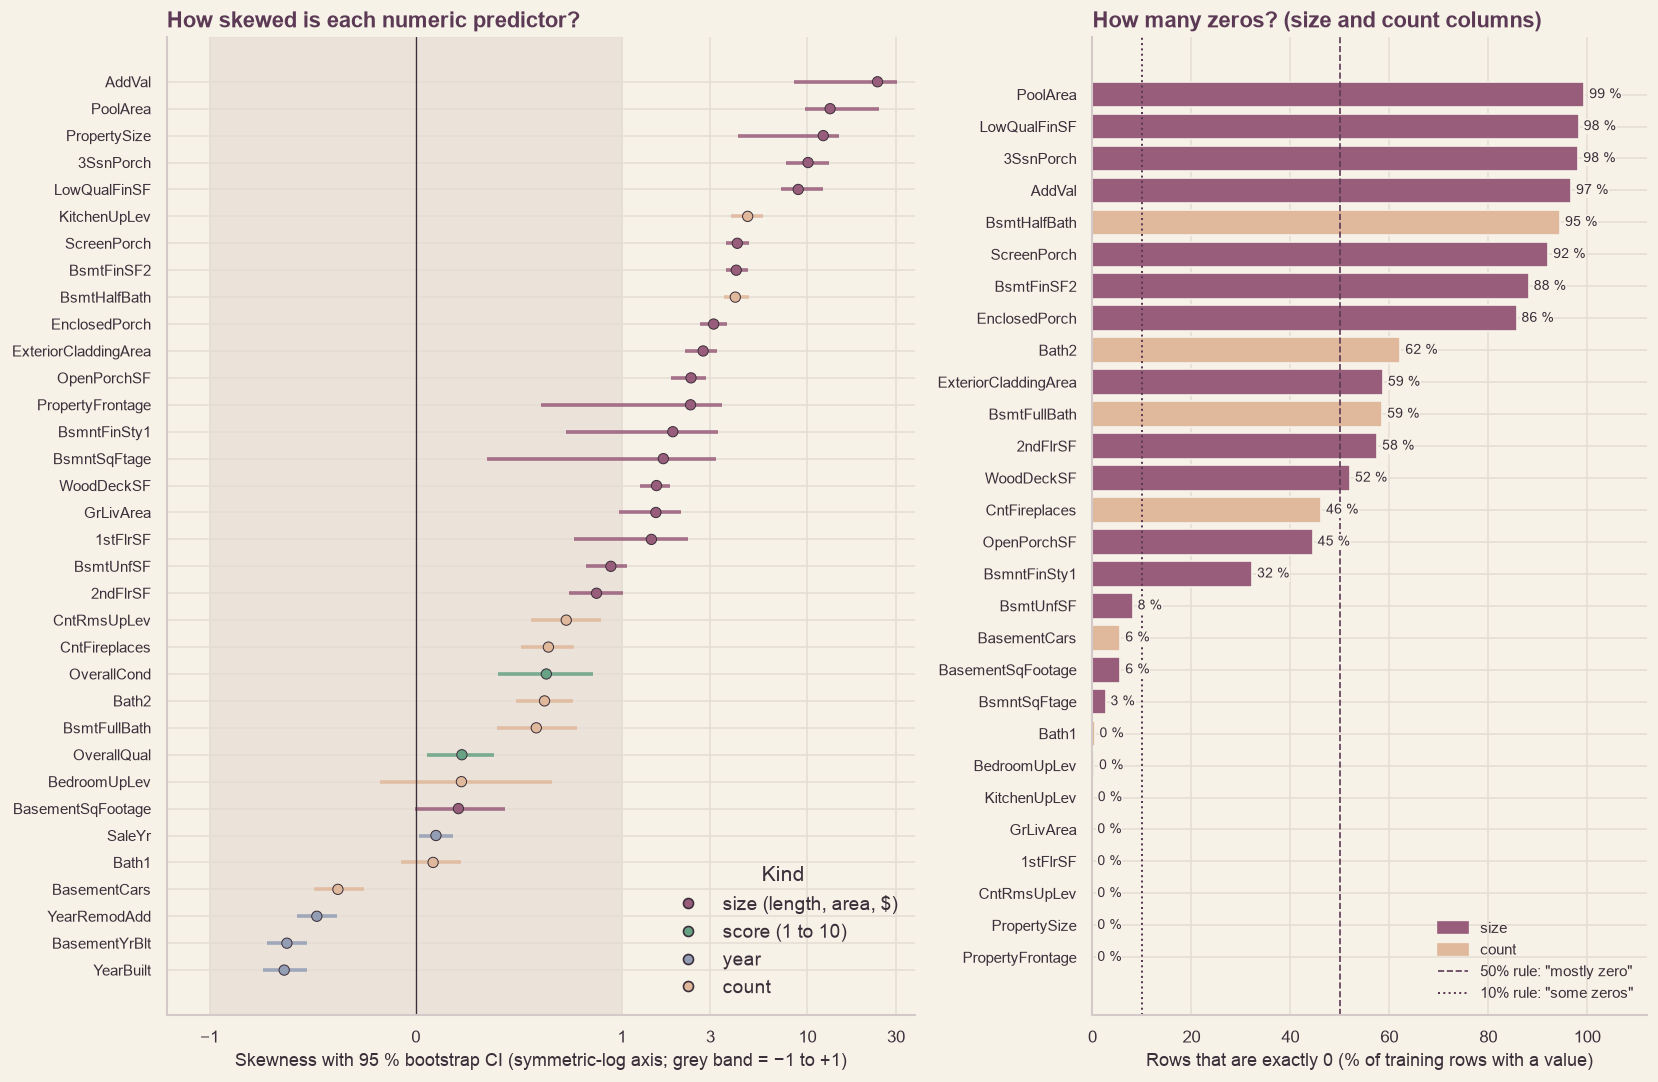


✅ Summary statistics done. Section 4 decisions so far: 2


In [29]:
# ── 4.2 Summary statistics of the 34 numeric predictors (training rows only) ──
X, y = X_train_clean, y_train                                    # training rows only (re-stated so this cell does not depend on the one above)
tests_before = TEST_LOG.count()

# Rules fixed before the run (conventions, not facts about the data):
SKEW_CUT       = 1.0           # "reliably skewed": the whole 95 % bootstrap CI of the skewness lies beyond +1 (or beyond −1)
ZERO_MOSTLY    = 0.50          # "mostly zero": at least half of the rows are exactly 0
ZERO_SOME      = 0.10          # "some zeros": 10 % to under 50 %
MODE_MIN_SHARE = 0.05          # a mode is shown only when it covers at least 5 % of the rows
N_BOOT         = 2000

def skew_ci(v):
    """Bootstrap CI of the sample skewness (bias-adjusted). Degenerate resamples (no spread) are dropped; if more than 5 % are, no CI is given."""
    try:
        r = bootstrap_ci(lambda a: stats.skew(a, bias=False), v, n_boot=N_BOOT, on_invalid='drop', max_invalid_frac=0.05)
        return r['lo'], r['hi']
    except ValueError:
        return np.nan, np.nan

def skew_class(sk, lo, hi):
    if np.isnan(lo):
        return 'CI undefined'
    if lo >= SKEW_CUT or hi <= -SKEW_CUT:
        return 'reliably skewed'
    return 'skewed, CI reaches below 1' if abs(sk) >= SKEW_CUT else 'not strongly skewed'

def zero_class(share, kind):
    if not kind.startswith(('size', 'count')):
        return '–'
    return 'mostly zero' if share >= ZERO_MOSTLY else 'some zeros' if share >= ZERO_SOME else 'few or no zeros'

def fmt_num(x):
    if x is None or (isinstance(x, float) and np.isnan(x)):
        return '–'
    return f'{x:,.0f}' if abs(x) >= 1000 else f'{x:,.1f}' if abs(x) >= 100 else f'{x:,.2f}'

prof_rows = []
for kind, cols in NUM_KINDS.items():
    for c in cols:
        v = X[c].dropna().to_numpy(float)
        n, vc = len(v), pd.Series(v).value_counts()
        q1, med, q3 = np.percentile(v, [25, 50, 75])
        mean, sd = v.mean(), v.std(ddof=1)
        zero = float((v == 0).mean()); nz = v[v != 0]
        sk, ku = float(stats.skew(v, bias=False)), float(stats.kurtosis(v, bias=False))
        lo, hi = skew_ci(v)
        prof_rows.append({'Kind': kind, 'Column': c, 'Rows used': n, 'Missing': len(X) - n,
                     'Mean': mean, 'Median': med, 'Mode (share)': f'{vc.index[0]:g} ({vc.iloc[0] / n:.0%})' if vc.iloc[0] / n >= MODE_MIN_SHARE else '–',
                     'SD': sd, 'Min': v.min(), 'Q1': q1, 'Q3': q3, 'Max': v.max(), 'IQR': q3 - q1,
                     'CV (%)': sd / mean * 100 if kind.startswith(('size', 'count')) and mean > 0 else np.nan,
                     'Skewness': sk, 'Skew CI low': lo, 'Skew CI high': hi, 'Excess kurtosis': ku,
                     'Zeros (%)': zero * 100, 'Non-zero rows': int(len(nz)), 'Median of non-zero': float(np.median(nz)) if len(nz) else np.nan,
                     'Skew class': skew_class(sk, lo, hi), 'Zero class': zero_class(zero, kind)})
NUM_PROFILE = pd.DataFrame(prof_rows).set_index('Column')

tabA = NUM_PROFILE.reset_index()[['Kind', 'Column', 'Rows used', 'Missing', 'Mean', 'Median', 'Mode (share)', 'SD', 'Min', 'Q1', 'Q3', 'Max', 'IQR', 'CV (%)']].copy()
for col in ['Mean', 'Median', 'SD', 'Min', 'Q1', 'Q3', 'Max', 'IQR']:
    tabA[col] = tabA[col].map(fmt_num)
tabA['CV (%)'] = tabA['CV (%)'].map(lambda x: '–' if np.isnan(x) else f'{x:,.0f}')
show_table(tabA, formats={'Rows used': '{:,}', 'Missing': '{:,}'}, caption='Centre, spread and quantiles of the numeric predictors (training rows)')

tabB = NUM_PROFILE.reset_index()[['Kind', 'Column', 'Skewness', 'Skew CI low', 'Skew CI high', 'Excess kurtosis', 'Zeros (%)', 'Non-zero rows', 'Median of non-zero', 'Skew class', 'Zero class']].copy()
tabB['Skewness (95 % CI)'] = [('{:+.2f} ({:+.2f} to {:+.2f})'.format(s, l, h) if not np.isnan(l) else '{:+.2f} (CI undefined)'.format(s))
                              for s, l, h in zip(tabB['Skewness'], tabB['Skew CI low'], tabB['Skew CI high'])]
tabB['Median of non-zero'] = tabB['Median of non-zero'].map(fmt_num)
tabB = tabB[['Kind', 'Column', 'Skewness (95 % CI)', 'Excess kurtosis', 'Zeros (%)', 'Non-zero rows', 'Median of non-zero', 'Skew class', 'Zero class']]
show_table(tabB, formats={'Excess kurtosis': '{:+.1f}', 'Zeros (%)': '{:.1f}', 'Non-zero rows': '{:,}'}, caption='Shape and zero share of the numeric predictors (training rows; bootstrap CI, 2,000 resamples)')

# ── The lists handed to later sections (nothing is transformed or removed here) ──
SKEWED_COLS      = NUM_PROFILE.index[NUM_PROFILE['Skew class'] == 'reliably skewed'].tolist()
SKEW_UNSTABLE    = NUM_PROFILE.index[NUM_PROFILE['Skew class'].isin(['skewed, CI reaches below 1', 'CI undefined'])].tolist()
ZERO_HEAVY_COLS  = NUM_PROFILE.index[NUM_PROFILE['Zero class'] == 'mostly zero'].tolist()
ZERO_SOME_COLS   = NUM_PROFILE.index[NUM_PROFILE['Zero class'] == 'some zeros'].tolist()
ZERO_HEAVY_SIZE  = [c for c in ZERO_HEAVY_COLS if c in SIZE_COLS]        # a zero here means 'the feature is absent'
ZERO_HEAVY_COUNT = [c for c in ZERO_HEAVY_COLS if c in COUNT_COLS]       # a zero here is a real count
print(f'Reliably skewed (95 % CI beyond ±{SKEW_CUT:g}) : {len(SKEWED_COLS)}  →  ' + ', '.join(SKEWED_COLS))
print(f'Skewed but not reliably               : {len(SKEW_UNSTABLE)}  →  ' + (', '.join(SKEW_UNSTABLE) or 'none'))
print(f'Mostly zero (≥ {ZERO_MOSTLY:.0%} zeros)               : {len(ZERO_HEAVY_COLS)}  →  size: ' + ', '.join(ZERO_HEAVY_SIZE) + '  |  count: ' + ', '.join(ZERO_HEAVY_COUNT))
print(f'Some zeros ({ZERO_SOME:.0%} to {ZERO_MOSTLY:.0%})               : {len(ZERO_SOME_COLS)}  →  ' + ', '.join(ZERO_SOME_COLS))

# ── Figure: how skewed, and how many zeros ──
KIND_COLOUR = {'size (length, area, $)': MAUVE, 'score (1 to 10)': SAGE_GREEN, 'year': SLATE_BLUE, 'count': APRICOT}
fig, axes = plt.subplots(1, 2, figsize=(14, 9.2), gridspec_kw={'width_ratios': [1.35, 1]})
skew_order = NUM_PROFILE.sort_values('Skewness')
yy = np.arange(len(skew_order))
ax = axes[0]
ax.axvspan(-SKEW_CUT, SKEW_CUT, color=GRID, alpha=0.7, zorder=0)
ax.hlines(yy, skew_order['Skew CI low'], skew_order['Skew CI high'], color=[KIND_COLOUR[k] for k in skew_order['Kind']], lw=2.2, alpha=0.85, zorder=2)
ax.scatter(skew_order['Skewness'], yy, s=38, color=[KIND_COLOUR[k] for k in skew_order['Kind']], edgecolor=INK, linewidth=0.6, zorder=3)
ax.axvline(0, color=INK, lw=0.8)
ax.set_yticks(yy); ax.set_yticklabels(skew_order.index, fontsize=9)
ax.set_xscale('symlog', linthresh=1.0); ax.set_xticks([-1, 0, 1, 3, 10, 30]); ax.set_xticklabels(['−1', '0', '1', '3', '10', '30'])
ax.set_xlim(-1.7, float(skew_order['Skew CI high'].max()) * 1.25)
ax.set_xlabel('Skewness with 95 % bootstrap CI (symmetric-log axis; grey band = −1 to +1)')
ax.set_title('How skewed is each numeric predictor?', loc='left')
ax.legend(handles=[plt.Line2D([0], [0], marker='o', ls='', color=c, markeredgecolor=INK, label=k) for k, c in KIND_COLOUR.items()], frameon=False, loc='lower right', title='Kind')
ax = axes[1]
zero_order = NUM_PROFILE[NUM_PROFILE['Kind'].str.startswith(('size', 'count'))].sort_values('Zeros (%)')
ax.barh(zero_order.index, zero_order['Zeros (%)'], color=[KIND_COLOUR[k] for k in zero_order['Kind']], edgecolor=CREAM)
for i, v_ in enumerate(zero_order['Zeros (%)']):
    ax.text(v_ + 1, i, f'{v_:.0f} %', va='center', fontsize=8.5, color=INK, bbox=dict(facecolor=CREAM, edgecolor='none', pad=0.6))
ax.axvline(ZERO_MOSTLY * 100, color=DEEP_PLUM, ls='--', lw=1); ax.axvline(ZERO_SOME * 100, color=DEEP_PLUM, ls=':', lw=1.2)
ax.set_xlim(0, 112); ax.set_xlabel('Rows that are exactly 0 (% of training rows with a value)'); ax.tick_params(axis='y', labelsize=9)
ax.set_title('How many zeros? (size and count columns)', loc='left')
ax.legend(handles=[plt.Rectangle((0, 0), 1, 1, color=KIND_COLOUR['size (length, area, $)']), plt.Rectangle((0, 0), 1, 1, color=KIND_COLOUR['count']),
                   plt.Line2D([0], [0], color=DEEP_PLUM, ls='--', lw=1), plt.Line2D([0], [0], color=DEEP_PLUM, ls=':', lw=1.2)],
          labels=['size', 'count', f'{ZERO_MOSTLY:.0%} rule: "mostly zero"', f'{ZERO_SOME:.0%} rule: "some zeros"'], frameon=False, loc='lower right', fontsize=9)
fig.tight_layout(); save_fig(fig, '07_numeric_skew_and_zeros', section='4'); plt.show()

# ── Decision ──
DECISIONS.add('4.2', 'Which numeric predictors are reliably skewed or mostly zeros, and what happens to them now?',
    f'Mean, median, SD, quartiles, IQR, CV (size and count columns only), skewness with a {N_BOOT:,}-resample bootstrap CI, excess kurtosis and the share of zeros for each column. '
    f'Rules fixed before the run: reliably skewed = the whole CI beyond ±{SKEW_CUT:g}; mostly zero = at least {ZERO_MOSTLY:.0%} zeros.',
    f'{len(SKEWED_COLS)} columns are reliably skewed ({", ".join(SKEWED_COLS)}). {len(SKEW_UNSTABLE)} more have a skewness of at least 1 but a CI that reaches below 1 ({", ".join(SKEW_UNSTABLE) or "none"}). '
    f'{len(ZERO_HEAVY_COLS)} columns are mostly zero: {len(ZERO_HEAVY_SIZE)} size columns ({", ".join(ZERO_HEAVY_SIZE)}), where a zero means the feature is absent, and {len(ZERO_HEAVY_COUNT)} count columns ({", ".join(ZERO_HEAVY_COUNT)}), where a zero is a real count. {len(ZERO_SOME_COLS)} columns have some zeros.',
    'Nothing is transformed, capped or removed in Section 4. SKEWED_COLS and the size columns in ZERO_HEAVY_SIZE and ZERO_SOME_COLS go to Section 8, where log1p and has-the-feature flags are tested by cross-validation; the extreme tails go to Section 5. Count columns stay counts. A skewed predictor is not a problem for a linear model by itself; it matters only if a transform improves cross-validated error.',
    'Deliberately unchanged')
assert TEST_LOG.count() == tests_before
print(f'\n✅ Summary statistics done. Section 4 decisions so far: {len(DECISIONS.to_frame("4"))}')

**Reading.** Most size columns are right-skewed with a long tail: PropertySize has median 9,600 sq ft but mean 10,679 and maximum 215,245 (CV 93 %), and GrLivArea runs from 334 to 5,642 against a median of 1,467. Thirteen columns are reliably skewed (bootstrap CI beyond ±1), including PropertySize (+12.16), AddVal (+23.85), PoolArea (+13.24) and the porch areas. Five more are skewed only because of a few extreme properties (GrLivArea +1.52, 1stFlrSF +1.44, BsmntSqFtage +1.67, BsmntFinSty1 +1.88, PropertyFrontage +2.34), as their intervals reach below 1. Thirteen columns are mostly zeros, because the feature is absent for most properties: PoolArea (99.4 % zeros, 7 pools), LowQualFinSF (98.3 %), 3SsnPorch (98.2 %) and AddVal (96.7 %) have fewer than 40 non-zero rows. For those, the mean and CV are misleading, so the median of the non-zero values (for example a median pool of 555 sq ft) is reported alongside. Scores, years and counts are not strongly skewed apart from BsmtHalfBath and KitchenUpLev, which are almost constant (95 % and 96 % at one value).

**Decision.** Descriptive only: no column is transformed, dropped or capped here. Treatment of skew and zero-heavy columns is decided by cross-validation in Section 9, not by these statistics.

## 4.3 Variance Stabilisation and Heteroscedasticity

**Research question.** Does conditional residual spread vary with fitted price, and is it less pronounced on the log scale?

**Method/test.** Two exploratory OLS fits on the same seven prespecified numerical predictors, with training-only median imputation. Residual-versus-fitted plots and Breusch–Pagan LM and F tests.

**Evidence.** Table 4.3 and Figure 4.3. In-sample R² is diagnostic only.

**Decision.** Do not select a model or claim heteroscedasticity is resolved from these tests; revisit with cross-validated model diagnostics.

Target,Observations,In-sample R²,BP LM statistic,BP LM / n,BP p-value,BP F p-value,"Spearman(|resid|, fitted)"
Raw price,1168,0.7659,345.5,0.2958,1.1e-70,5.3e-84,+0.23
Log price,1168,0.8185,225.3,0.1929,5e-45,4.3e-50,-0.06


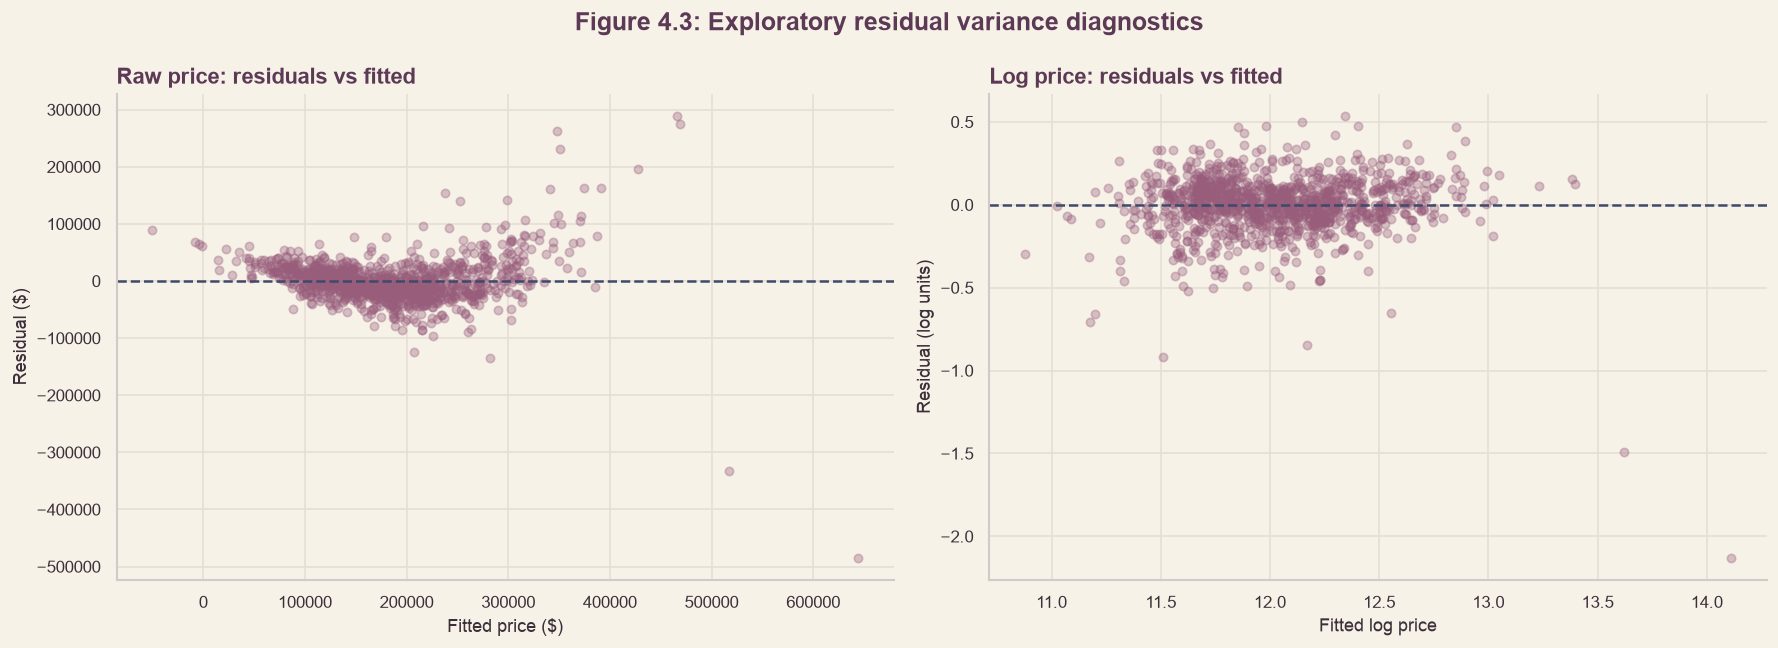

In [30]:
# ── 4.3 Variance diagnostics: raw price vs log price (training rows only) ──
import statsmodels.api as sm
from statsmodels.stats.diagnostic import het_breuschpagan
from sklearn.impute import SimpleImputer
from scipy.stats import spearmanr

access_before_43 = TEST_LOG.count()
y_raw = pd.to_numeric(y_train, errors='raise').astype(float)       # dollars, defined explicitly
y_log = np.log(y_raw)
assert X_train_clean.index.equals(y_raw.index)
assert y_raw.median() > 10_000 and y_log.median() < 20, 'y_raw must be dollars and y_log log-dollars'

BP_FEATURES = ['GrLivArea', 'OverallQual', 'YearBuilt', 'PropertySize', 'BsmntSqFtage', 'Bath1', 'BasementCars']
assert all(c in X_train_clean.columns for c in BP_FEATURES)
X_bp = X_train_clean[BP_FEATURES].apply(pd.to_numeric, errors='raise')
X_bp_design = sm.add_constant(SimpleImputer(strategy='median').fit_transform(X_bp), has_constant='add')

bp_results, bp_rows = {}, []
for name, values in {'Raw price': y_raw, 'Log price': y_log}.items():
    model = sm.OLS(values.to_numpy(), X_bp_design).fit()
    lm, lmp, f, fp = het_breuschpagan(model.resid, model.model.exog)
    rho = spearmanr(np.abs(model.resid), model.fittedvalues)[0]
    bp_results[name] = {'fitted': model.fittedvalues, 'residuals': model.resid}
    bp_rows.append({'Target': name, 'Observations': int(model.nobs), 'In-sample R²': model.rsquared,
                    'BP LM statistic': lm, 'BP LM / n': lm / model.nobs, 'BP p-value': lmp,
                    'BP F p-value': fp, 'Spearman(|resid|, fitted)': rho})
bp_table = pd.DataFrame(bp_rows)
show_table(bp_table, formats={'In-sample R²': '{:.4f}', 'BP LM statistic': '{:.1f}', 'BP LM / n': '{:.4f}',
                              'BP p-value': '{:.2g}', 'BP F p-value': '{:.2g}', 'Spearman(|resid|, fitted)': '{:+.2f}'},
           caption='Table 4.3: Breusch-Pagan tests and residual-spread trend (7 predictors, training rows, in-sample, diagnostic only)')

fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))
for ax, (name, res) in zip(axes, bp_results.items()):
    ax.scatter(res['fitted'], res['residuals'], color=MAUVE, alpha=.35, s=25)
    ax.axhline(0, color=TWILIGHT, ls='--')
    ax.set_title(f'{name}: residuals vs fitted', loc='left')
    ax.set_xlabel('Fitted price ($)' if name == 'Raw price' else 'Fitted log price')
    ax.set_ylabel('Residual ($)' if name == 'Raw price' else 'Residual (log units)')
fig.suptitle('Figure 4.3: Exploratory residual variance diagnostics', color=DEEP_PLUM, fontweight='bold')
fig.tight_layout(); save_fig(fig, 'fig4_3_variance_diagnostics', section='4'); plt.show()
assert TEST_LOG.count() == access_before_43

**Reading.** Both fits reject constant variance (Breusch-Pagan LM/n 0.296 on raw price, 0.193 on log price; p < 1e-44 in both), so the test does not separate the two scales. The more informative number is how residual size moves with the fitted value: Spearman(|residual|, fitted) is +0.23 on raw price, so errors fan out as price rises, and −0.06 on log price, so they do not. These are in-sample fits on seven predictors, used as a diagnostic only.

**Decision.** Keep the log as the candidate target (consistent with 3.8). Residual spread is rechecked on cross-validated residuals in Section 10.

## 4.4 Back-Transformation Bias and Smearing Correction

**Research question.** Why can exponentiating a mean log prediction underestimate a conditional mean price?

**Method/test.** Compare arithmetic and geometric means and bootstrap their ratio. Describe Duan’s smearing estimator: `mean(exp(training log residual))`; apply it to exponentiated predictions only after fitting within the training fold.

**Evidence.** Table 4.4 and bootstrap interval for the descriptive mean ratio.

**Decision.** Prespecify naive and fold-fitted smearing variants for dollar-scale CV comparison. The mean ratio is **not** a model smearing factor.

In [31]:
# ── 4.4 Arithmetic vs geometric mean of price, and the shape of the target (training rows only) ──
y_raw = pd.to_numeric(y_train, errors='raise').astype(float)
assert y_raw.median() > 10_000, 'y_raw must be in dollars'
arith = float(y_raw.mean())
geo = float(np.exp(np.log(y_raw).mean()))
ratio = arith / geo
ratio_ci = bootstrap_ci(lambda a: a.mean() / np.exp(np.log(a).mean()), y_raw.to_numpy(), n_boot=2000)
skew_raw = bootstrap_ci(lambda a: stats.skew(a, bias=False), y_raw.to_numpy(), n_boot=2000)
skew_log = bootstrap_ci(lambda a: stats.skew(a, bias=False), np.log(y_raw.to_numpy()), n_boot=2000)

tab44 = pd.DataFrame([
    ('Arithmetic mean of price', f'${arith:,.0f}', 'average observed price'),
    ('Geometric mean of price', f'${geo:,.0f}', 'exp of the average log price'),
    ('Arithmetic / geometric ratio', f'{ratio:.3f} (95 % CI {ratio_ci["lo"]:.3f} to {ratio_ci["hi"]:.3f})', 'descriptive only, NOT a smearing factor'),
    ('Skewness, raw price', f'{skew_raw["estimate"]:+.2f} (CI {skew_raw["lo"]:+.2f} to {skew_raw["hi"]:+.2f})', ''),
    ('Skewness, log price', f'{skew_log["estimate"]:+.2f} (CI {skew_log["lo"]:+.2f} to {skew_log["hi"]:+.2f})', '')],
    columns=['Measure', 'Value', 'Note'])
show_table(tab44, caption='Table 4.4: Back-transformation gap and target shape (training rows)')
print('The ratio is a descriptive Jensen-gap measure. The Duan smearing factor is estimated from model residuals inside each CV fold (Section 10).')

Measure,Value,Note
Arithmetic mean of price,"$181,554",average observed price
Geometric mean of price,"$166,876",exp of the average log price
Arithmetic / geometric ratio,1.088 (95 % CI 1.080 to 1.098),"descriptive only, NOT a smearing factor"
"Skewness, raw price",+1.95 (CI +1.47 to +2.39),
"Skewness, log price",+0.18 (CI -0.02 to +0.39),


The ratio is a descriptive Jensen-gap measure. The Duan smearing factor is estimated from model residuals inside each CV fold (Section 10).


**Reading.** The arithmetic mean of training prices ($181,554) is 8.8 % above the geometric mean ($166,876; ratio 1.088, 95 % CI 1.080 to 1.098). This is a descriptive Jensen gap and mostly reflects the spread of price itself (log SD about 0.40). It is **not** the correction a model needs: Duan's smearing factor is estimated from a model's own residuals, which are much smaller, so it is expected to be far closer to 1. Section 10 estimates it inside each fold.

**Decision.** No correction is applied here. Naive and fold-fitted smearing are both scored in dollars in Section 10.

## 4.5 Decision Register and Section Summary

**Research question.** What has been established, and which choices remain open?

**Method.** Register the four decisions and display the Section 4 audit trail. **Evidence** comes from the preceding training-only outputs. **Decision:** defer predictive choices to CV.

In [32]:
# ── 4.5 Decision Register for 4.3 and 4.4 ──
t = bp_table.set_index('Target')
DECISIONS.add('4.3', 'Does residual spread change with fitted price, and is it milder on the log scale?',
    'Two exploratory OLS fits on seven prespecified numeric predictors (training rows, median imputation), raw and log price; Breusch-Pagan LM and F tests and the Spearman correlation of |residual| with the fitted value.',
    f'BP LM/n: raw {t.loc["Raw price","BP LM / n"]:.3f}, log {t.loc["Log price","BP LM / n"]:.3f}; Spearman(|resid|, fitted): raw {t.loc["Raw price","Spearman(|resid|, fitted)"]:+.2f}, log {t.loc["Log price","Spearman(|resid|, fitted)"]:+.2f}.',
    'The log scale is kept as the candidate target (confirmed in 3.8). The tests are in-sample and diagnostic; heteroscedasticity is rechecked on cross-validated residuals in Section 10.',
    'Documentation only')
DECISIONS.add('4.4', 'Why can exponentiating a mean log prediction understate the mean price?',
    'Arithmetic vs geometric mean of training prices with a bootstrap CI for the ratio; skewness of raw and log price with bootstrap CIs.',
    f'Ratio {ratio:.3f} (CI {ratio_ci["lo"]:.3f} to {ratio_ci["hi"]:.3f}); skewness {skew_raw["estimate"]:+.2f} raw, {skew_log["estimate"]:+.2f} log.',
    'The ratio is descriptive. Naive and fold-fitted Duan smearing are both scored in dollars in Section 10; no correction is applied automatically.',
    'Documentation only')
assert TEST_LOG.count() == access_before_43
print(f'✅ Section 4 decisions so far: {len(DECISIONS.to_frame("4"))}')

✅ Section 4 decisions so far: 4


**What Section 4 established.** The 34 numeric predictors fall into four kinds (19 sizes, 2 scores, 4 years, 9 counts). Thirteen are reliably skewed and thirteen are mostly zeros, so means and CVs are read with the median of the non-zero values. PropPrice has skewness +1.95, which falls to +0.18 on the log scale. In exploratory OLS the residual spread grows with the fitted value on raw price (Spearman +0.23) but not on log price (−0.06). The arithmetic-to-geometric mean ratio of price is 1.088 (95 % CI 1.080 to 1.098), a descriptive gap and not a smearing factor. Nothing in the data was changed in this section (decisions D38 to D41).

Histograms, violin plots, frequency tables and categorical profiles are in Sections 6 and 7.

**Next → Section 5: Outlier Detection & Treatment.**

# 5. Outliers, Anomalies and Influential Points

**Purpose.** Identify unusual numeric values, jointly unusual properties, influential observations, and the four properties with `GrLivArea > 4,000`; adjudicate potential anomalies using transaction context; evaluate any proposed training-row exclusion by **training-only cross-validation**. The brief prohibits dropping predictor **columns** other than `PropertyID`; excluding **rows** is a separate decision requiring defensible justification.

**Protocol.** All exploration uses `X_train_clean` and `y_train`. The held-out test vault is not opened. Screening flags are not proof of errors. Models and imputers used for validation are fitted within each fold. The same fixed CV folds are used for paired comparisons; repeated-fold differences are descriptive and not independent samples.

## 5.1 Univariate Extremes

**Research question.** Which numeric predictors contain values unusually far from their training distributions?

**Method/test.** For each genuinely numeric predictor, compute Tukey's 1.5×IQR fences and modified Z-scores `0.6745(x−median)/MAD` (absolute value > 3.5). Flag counts are reported separately; zero-MAD columns are explicitly marked not assessable by this method. Numeric-coded nominal variables are excluded from numeric outlier tests.

**Evidence.** Per-variable counts, proportions, robust-centre statistics and overlap; an outlier-count chart.

**Decision.** Create a *review shortlist*, not an automatic deletion or winsorisation rule. No hypothesis tests are run here; multiplicity correction does not apply to descriptive screening flags.

Feature,Nonmissing,Median,IQR,MAD,IQR flagged,MAD flagged,Both flagged,IQR %,MAD available,IQR available
OverallCond,1168,5.0,1.0,0.0,94,0,0,8.0,False,True
ExteriorCladdingArea,1160,0.0,162.0,0.0,84,0,0,7.2,False,True
PropertyFrontage,951,70.0,22.0,11.0,69,24,24,5.9,True,True
PropertySize,1168,"9,600.0","4,084.0","2,052.5",59,43,43,5.1,True,True
OpenPorchSF,1168,25.0,68.0,25.0,56,75,56,4.8,True,True
BsmntSqFtage,1168,995.0,519.0,237.5,50,10,10,4.3,True,True
GrLivArea,1168,"1,467.0",644.2,325.0,29,14,14,2.5,True,True
BedroomUpLev,1168,3.0,1.0,0.0,27,0,0,2.3,False,True
CntRmsUpLev,1168,6.0,2.0,1.0,26,11,11,2.2,True,True
BsmtUnfSF,1168,484.5,587.2,291.5,24,6,6,2.1,True,True


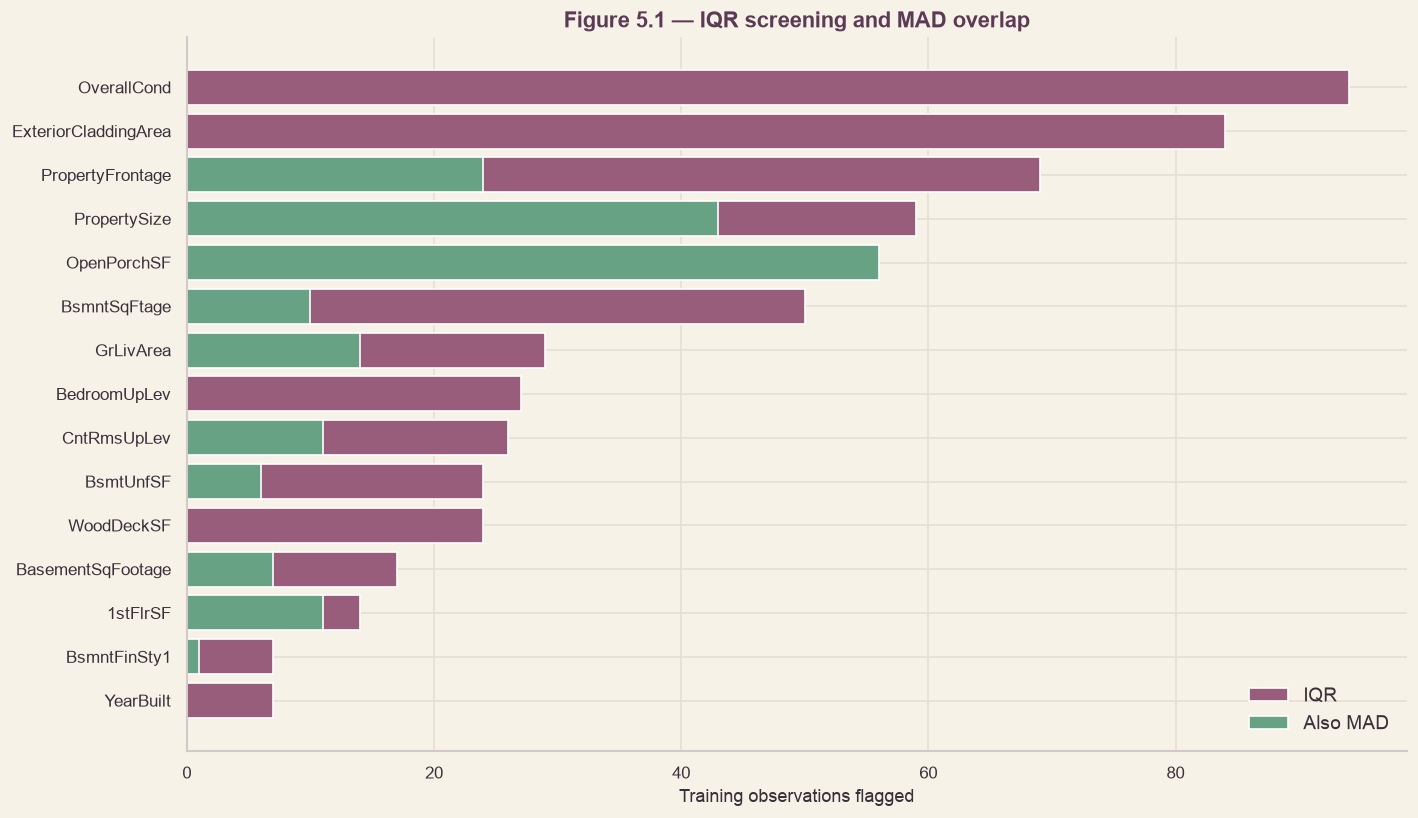

Numeric features screened: 33 | zero-IQR: 9 | zero-MAD: 18


In [33]:
# ── 5.1 Training-only numeric screening ────────────────────────
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from scipy import stats
from sklearn.covariance import MinCovDet
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import RobustScaler, OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import Ridge
from sklearn.model_selection import RepeatedKFold
from sklearn.metrics import mean_squared_error
from sklearn.base import clone
from matplotlib.ticker import PercentFormatter

assert 'X_train_clean' in globals() and 'y_train' in globals(), 'Run Sections 1–3 first.'
assert X_train_clean.index.equals(y_train.index), 'Training predictor/target indices differ.'
access_before_5 = TEST_LOG.count()
X5 = X_train_clean.copy()
y5 = pd.to_numeric(y_train, errors='raise').astype(float)
assert (y5 > 0).all() and y5.notna().all()
NUM5 = [c for c in X5.select_dtypes(include='number').columns if c not in ('PropertyClass','SaleMon','SaleYr')]
# SaleYr is calendar time, not a numerical magnitude to outlier-screen.
assert 'GrLivArea' in NUM5
flags_iqr, flags_mad, screen_rows = {}, {}, []
for c in NUM5:
    s = pd.to_numeric(X5[c], errors='coerce').astype(float)
    valid = s.dropna(); q1,q3 = valid.quantile([.25,.75]); iqr=q3-q1
    median=valid.median(); mad=np.median(np.abs(valid-median))
    iqflag = (s < q1-1.5*iqr) | (s > q3+1.5*iqr) if iqr > 0 else pd.Series(False,index=s.index)
    mdflag = (0.6745*(s-median)/mad).abs() > 3.5 if mad > 0 else pd.Series(False,index=s.index)
    flags_iqr[c]=iqflag.fillna(False); flags_mad[c]=mdflag.fillna(False)
    screen_rows.append({'Feature':c,'Nonmissing':len(valid),'Median':median,'IQR':iqr,'MAD':mad,
        'IQR flagged':int(iqflag.sum()),'MAD flagged':int(mdflag.sum()),
        'Both flagged':int((iqflag & mdflag).sum()),'IQR %':100*iqflag.sum()/len(s),
        'MAD available':mad>0,'IQR available':iqr>0})
screen5=pd.DataFrame(screen_rows).sort_values(['IQR flagged','MAD flagged'],ascending=False).reset_index(drop=True)
show_table(screen5.head(20),formats={'Median':'{:,.1f}','IQR':'{:,.1f}','MAD':'{:,.1f}','IQR %':'{:.1f}'},caption='Table 5.1 — Highest-count numerical screening flags (training only)')
fig,ax=plt.subplots(figsize=(12,7)); top=screen5.head(15).iloc[::-1]
ax.barh(top['Feature'],top['IQR flagged'],color=MAUVE,label='IQR');ax.barh(top['Feature'],top['Both flagged'],color=SAGE_GREEN,label='Also MAD')
ax.set(xlabel='Training observations flagged',title='Figure 5.1 — IQR screening and MAD overlap');ax.legend(frameon=False)
plt.tight_layout();save_fig(fig,'fig5_1_univariate_extremes',section='5');plt.show()
print('Numeric features screened:',len(NUM5),'| zero-IQR:',int((~screen5['IQR available']).sum()),'| zero-MAD:',int((~screen5['MAD available']).sum()))
assert TEST_LOG.count()==access_before_5

**Reading.** 33 numeric columns were screened with the IQR rule and the modified z-score. The highest IQR counts come from columns where that rule is unreliable: OverallCond (94 properties, 8.0 %) is a discrete score with IQR 1 and MAD 0, so ordinary ratings of 8 and 9 are flagged, and ExteriorCladdingArea (84, 7.2 %) is 59 % zeros. Nine columns have a zero IQR and eighteen a zero MAD, so the modified z-score cannot be computed for them. Where both rules apply they agree on the clearest cases (PropertySize 43 of 59 flags, GrLivArea 14 of 29, 1stFlrSF 11 of 14) and differ on heavy-tailed columns (PropertyFrontage 69 IQR flags against 24 from MAD).

**Decision.** The flags are a review shortlist, not a deletion list. All predictors and rows are retained.

## 5.2 Multivariate Outliers — Robust Mahalanobis Distance

**Research question.** Which properties have an unusual *combination* of numeric measurements, even when no single feature is extreme?

**Method/test.** Choose a prespecified, non-redundant set of positive/zero-heavy structural features, apply `log1p` to nonnegative magnitudes, median-impute training data, robust-scale and fit Minimum Covariance Determinant (MCD). A chi-square reference cutoff at the 99.5th percentile provides a **screening threshold**, not a calibrated anomaly probability. MCD assumes an approximately elliptical main cloud and may be unstable for discrete or highly correlated variables.

**Evidence.** Robust squared Mahalanobis distances, cutoff, flagged property IDs and overlap with 5.1.

**Decision.** Cross-check candidate rows with domain context. No automatic exclusions.

PropertyID,Robust MD²,MCD flag,Univariate flag
1012,926.09,True,True
1180,894.36,True,True
521,868.03,True,True
1219,852.22,True,True
534,787.85,True,True
363,725.73,True,True
869,723.22,True,True
1217,704.26,True,True
779,703.69,True,True
1049,702.31,True,True


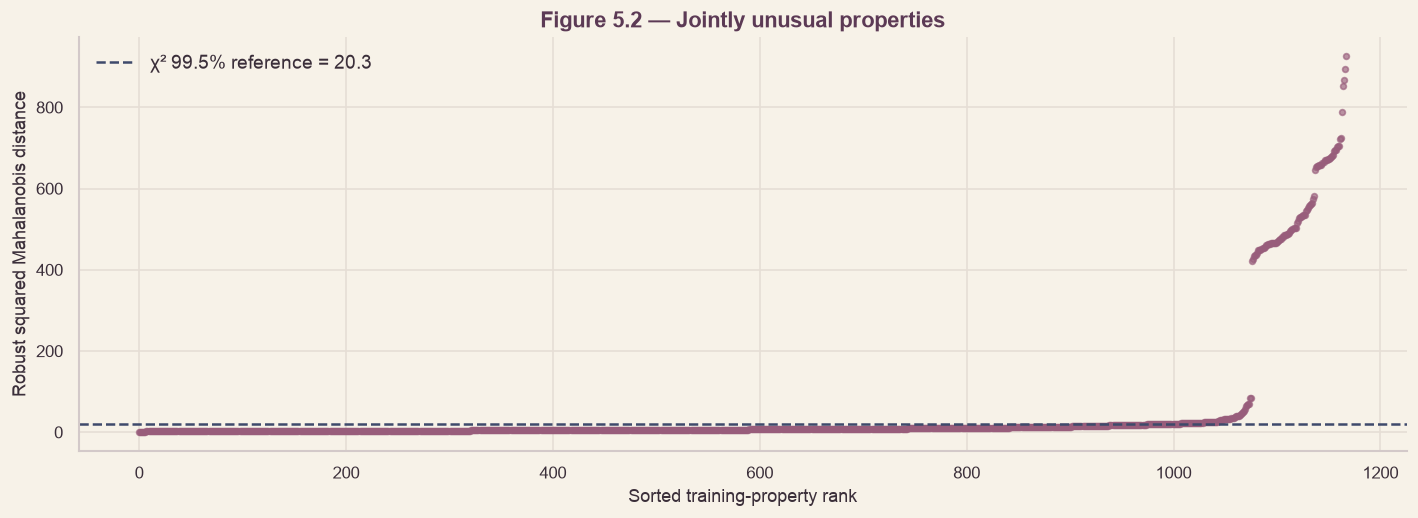

MCD flagged: 172 | overlap with univariate flags: 117


In [34]:
# ── 5.2 Robust multivariate screening ─────────────────────────
MCD_FEATURES=['GrLivArea','PropertySize','BsmntSqFtage','BasementSqFootage','YearBuilt','OverallQual','Bath1']
assert set(MCD_FEATURES).issubset(X5.columns)
M5=X5[MCD_FEATURES].apply(pd.to_numeric,errors='raise').astype(float)
for c in ['GrLivArea','PropertySize','BsmntSqFtage','BasementSqFootage','Bath1']:
    assert (M5[c].dropna()>=0).all(), f'{c} has negative values'
    M5[c]=np.log1p(M5[c])
M5_imp=SimpleImputer(strategy='median').fit_transform(M5)
M5_scaled=RobustScaler().fit_transform(M5_imp)
assert np.linalg.matrix_rank(np.cov(M5_scaled,rowvar=False))==len(MCD_FEATURES), 'Covariance rank deficiency: revise prespecified feature set.'
mcd5=MinCovDet(random_state=SEEDS['global'],support_fraction=.8).fit(M5_scaled)
md2_5=pd.Series(mcd5.mahalanobis(M5_scaled),index=X5.index,name='Robust MD²')
cut5=stats.chi2.ppf(.995,df=len(MCD_FEATURES))
mcd_flag5=md2_5>cut5
any_uni5=pd.DataFrame(flags_iqr).any(axis=1)|pd.DataFrame(flags_mad).any(axis=1)
md_table5=pd.DataFrame({'PropertyID':X5.index,'Robust MD²':md2_5.values,'MCD flag':mcd_flag5.values,'Univariate flag':any_uni5.values})
md_table5=md_table5.sort_values('Robust MD²',ascending=False)
show_table(md_table5.head(20),formats={'Robust MD²':'{:,.2f}'},caption='Table 5.2 — Top 20 robust multivariate distances')
fig,ax=plt.subplots(figsize=(12,4.5));ax.scatter(np.arange(len(md2_5)),np.sort(md2_5),s=12,color=MAUVE,alpha=.65)
ax.axhline(cut5,color=TWILIGHT,linestyle='--',label=f'χ² 99.5% reference = {cut5:.1f}')
ax.set(xlabel='Sorted training-property rank',ylabel='Robust squared Mahalanobis distance',title='Figure 5.2 — Jointly unusual properties');ax.legend(frameon=False)
plt.tight_layout();save_fig(fig,'fig5_2_robust_mahalanobis',section='5');plt.show()
print('MCD flagged:',int(mcd_flag5.sum()),'| overlap with univariate flags:',int((mcd_flag5 & any_uni5).sum()))
assert TEST_LOG.count()==access_before_5

## 5.3 Influence on a Simple Regression

**Research question.** Which training properties materially influence a prespecified exploratory regression of log sale price?

**Method/test.** Fit OLS on log price using seven core numerical predictors, median-imputed on training data. Compute Cook's distance, hat-matrix leverage and externally studentised residuals. Flag Cook's D > 4/n as a *review threshold*; report leverage relative to 2p/n and |studentised residual| > 3 as complementary diagnostics. The fitted OLS is exploratory, not the production model.

**Evidence.** Influence ranking and diagnostic plots.

**Decision.** Influence alone does not establish a bad transaction. Examine row context in 5.4.

PropertyID,Cook D,Leverage,External studentised residual,Cook > 4/n,Leverage > 2p/n,|Studentised| > 3
1299,4.8471,0.1740,-14.78,True,True,True
524,0.4109,0.0405,-9.14,True,True,True
314,0.1588,0.3940,-1.40,True,True,False
917,0.0289,0.0135,-4.13,True,False,True
250,0.0249,0.2069,-0.87,True,True,False
458,0.0221,0.0225,2.78,True,True,False
677,0.0178,0.0237,-2.42,True,True,False
739,0.0162,0.0270,2.16,True,True,False
608,0.0152,0.0160,2.74,True,True,False
31,0.0141,0.0040,-5.38,True,False,True


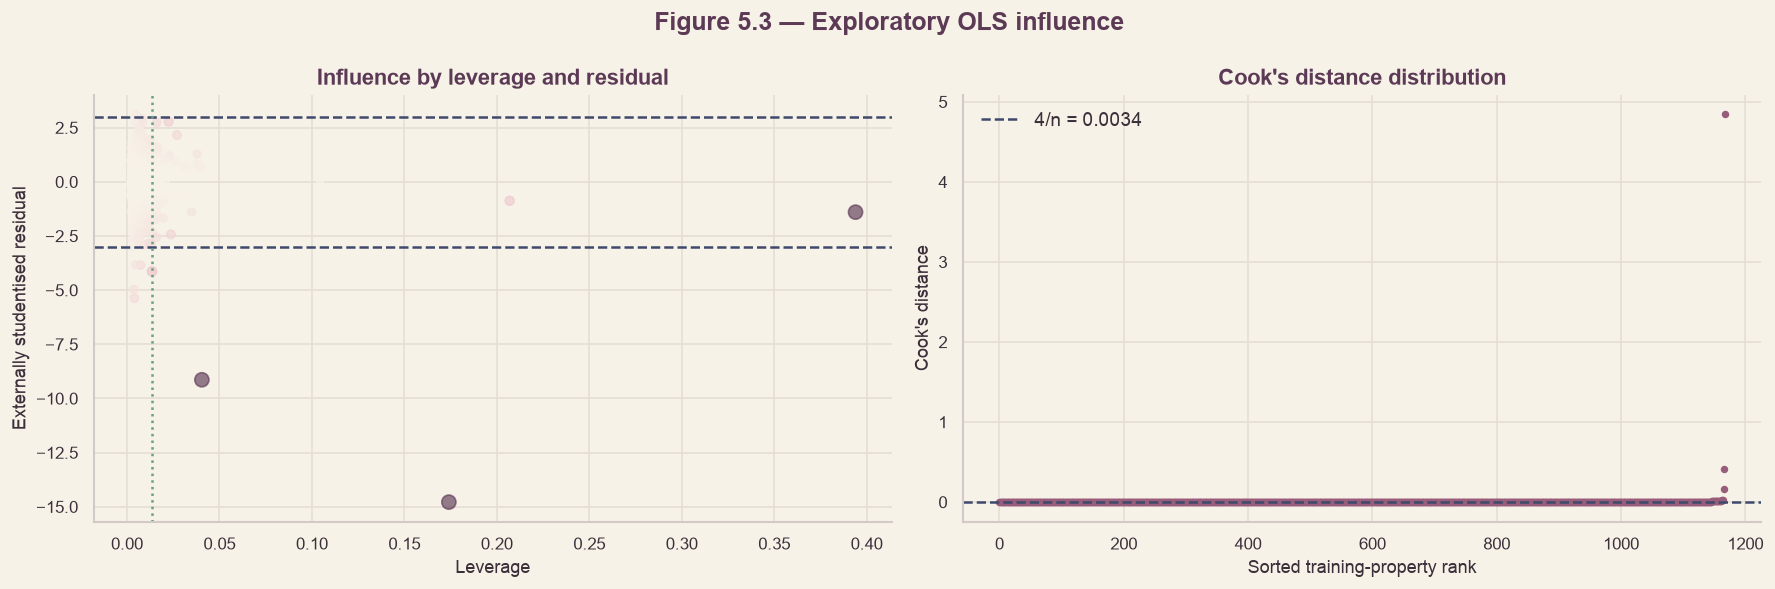

Cook > 4/n: 57 | leverage > 2p/n: 70 | |studentised| > 3: 9


In [35]:
# ── 5.3 OLS influence diagnostics ──────────────────────────────
import statsmodels.api as sm
OLS5_FEATURES=['GrLivArea','OverallQual','YearBuilt','PropertySize','BsmntSqFtage','Bath1','BasementCars']
O5=X5[OLS5_FEATURES].apply(pd.to_numeric,errors='raise').astype(float)
O5_arr=SimpleImputer(strategy='median').fit_transform(O5)
O5_design=sm.add_constant(O5_arr,has_constant='add')
ols5=sm.OLS(np.log(y5.to_numpy()),O5_design).fit()
inf5=ols5.get_influence(); cooks5=inf5.cooks_distance[0]; lev5=inf5.hat_matrix_diag
stud5=inf5.resid_studentized_external
p5=O5_design.shape[1]; n5=len(y5);cook_cut5=4/n5;lev_cut5=2*p5/n5
influence5=pd.DataFrame({'PropertyID':X5.index,'Cook D':cooks5,'Leverage':lev5,
 'External studentised residual':stud5,'Cook > 4/n':cooks5>cook_cut5,
 'Leverage > 2p/n':lev5>lev_cut5,'|Studentised| > 3':np.abs(stud5)>3}).sort_values('Cook D',ascending=False)
show_table(influence5.head(20),formats={'Cook D':'{:.4f}','Leverage':'{:.4f}','External studentised residual':'{:.2f}'},caption='Table 5.3 — Largest OLS influence diagnostics')
fig,axes=plt.subplots(1,2,figsize=(15,5))
axes[0].scatter(lev5,stud5,c=np.minimum(cooks5,.15),cmap=bloom_seq,s=18+450*np.minimum(cooks5,.12),alpha=.65)
axes[0].axhline(3,color=TWILIGHT,ls='--');axes[0].axhline(-3,color=TWILIGHT,ls='--');axes[0].axvline(lev_cut5,color=SAGE_GREEN,ls=':')
axes[0].set(xlabel='Leverage',ylabel='Externally studentised residual',title='Influence by leverage and residual')
axes[1].scatter(np.arange(n5),np.sort(cooks5),s=12,color=MAUVE);axes[1].axhline(cook_cut5,color=TWILIGHT,ls='--',label=f'4/n = {cook_cut5:.4f}')
axes[1].set(xlabel='Sorted training-property rank',ylabel="Cook's distance",title="Cook's distance distribution");axes[1].legend(frameon=False)
fig.suptitle('Figure 5.3 — Exploratory OLS influence',fontweight='bold',color=DEEP_PLUM)
plt.tight_layout();save_fig(fig,'fig5_3_influence',section='5');plt.show()
print('Cook > 4/n:',int((cooks5>cook_cut5).sum()),'| leverage > 2p/n:',int((lev5>lev_cut5).sum()),'| |studentised| > 3:',int((np.abs(stud5)>3).sum()))
assert TEST_LOG.count()==access_before_5

**Reading.** Joint screening flags 172 properties (14.7 %) by robust Mahalanobis distance, 117 of which are also univariate flags. In the exploratory OLS, 57 properties exceed the Cook distance cut-off of 4/n (0.0034) and 70 have high leverage. The distance counts are high because the chi-square reference assumes a roughly normal cloud and these columns are skewed and zero-heavy. The influence flags are the more useful screen: a handful of properties carry most of the Cook distance (see 5.4).

**Decision.** Influence is not an error label. Flagged cases are reviewed in their transaction context; none is deleted on distance alone.

## 5.4 Adjudicating the Four Large-Living-Area Properties

**Research question.** Are the two low-priced `Partial` sales among properties with `GrLivArea > 4,000` credible market comparables, or potentially atypical transactions?

**Method/test.** Display all four *training* properties meeting the size criterion, their sale type/condition, price per living square foot, neighbourhood and model influence flags. Compare price per square foot with a training-only peer group in the same neighbourhood and within ±1 quality point where possible. Show peer sample sizes; a tiny peer group does not support a stable comparison. The four cases in the full CSV are a **benchmark to verify**, not a guarantee all four belong to training.

**Evidence.** Auditable row table and peer-relative price ratio. Transaction condition, not a model residual, is the basis for a potential exclusion rule.

**Decision.** Define a prespecified candidate exclusion *only* for `GrLivArea > 4,000` and `SaleCondn == "Partial"`, if present in training. This is a sensitivity scenario, not a declaration that these are errors. The default is to retain all sales.

In [36]:
# ── 5.4 Contextual audit of large properties ──────────────────
large5=X5.loc[pd.to_numeric(X5['GrLivArea'])>4000].copy()
large5['PropPrice']=y5.loc[large5.index]
large5['Price_per_living_sqft']=large5['PropPrice']/pd.to_numeric(large5['GrLivArea'])
large5['Cook D']=pd.Series(cooks5,index=X5.index).reindex(large5.index)
large5['MCD flag']=mcd_flag5.reindex(large5.index)
large5['Univariate flag']=any_uni5.reindex(large5.index)
peer_rows=[]
for pid,row in large5.iterrows():
    peer_mask=(X5['Neighborhood']==row['Neighborhood']) & (pd.to_numeric(X5['OverallQual']).sub(float(row['OverallQual'])).abs()<=1) & (X5.index!=pid)
    peers=X5.loc[peer_mask]; peer_ppsf=(y5.loc[peers.index]/pd.to_numeric(peers['GrLivArea'])).replace([np.inf,-np.inf],np.nan).dropna()
    med=peer_ppsf.median() if len(peer_ppsf) else np.nan
    peer_rows.append({'PropertyID':pid,'Peer n':len(peer_ppsf),'Peer median $/sqft':med,
                      'Sale / peer median':row['Price_per_living_sqft']/med if pd.notna(med) and med>0 else np.nan})
peer5=pd.DataFrame(peer_rows).set_index('PropertyID') if peer_rows else pd.DataFrame(columns=['Peer n','Peer median $/sqft','Sale / peer median'])
large_audit5=large5[['GrLivArea','PropPrice','SaleCondn','SaleType','Neighborhood','OverallQual','Price_per_living_sqft','Cook D','MCD flag','Univariate flag']].join(peer5)
show_table(large_audit5.reset_index().rename(columns={'index':'PropertyID'}),formats={'PropPrice':'${:,.0f}','Price_per_living_sqft':'${:,.1f}','Cook D':'{:.4f}','Peer median $/sqft':'${:,.1f}','Sale / peer median':'{:.2f}'},caption='Table 5.4 — All >4,000 sq ft properties within the training split')
candidate_exclude5=(pd.to_numeric(X5['GrLivArea'])>4000) & (X5['SaleCondn'].astype(str)=='Partial')
print('Large living-area training rows:',len(large5),'| candidate atypical Partial sales:',int(candidate_exclude5.sum()))
print('Candidate PropertyIDs:',X5.index[candidate_exclude5].tolist())
print('These rows are NOT yet excluded. Training-only CV follows.')
assert TEST_LOG.count()==access_before_5

PropertyID,GrLivArea,PropPrice,SaleCondn,SaleType,Neighborhood,OverallQual,Price_per_living_sqft,Cook D,MCD flag,Univariate flag,Peer n,Peer median $/sqft,Sale / peer median
524,4676,"$184,750",Partial,New,Edwards,10,$39.5,0.4109,True,True,2,$108.4,0.36
692,4316,"$755,000",Normal,WD,NoRidge,10,$174.9,0.0028,False,True,4,$169.4,1.03
1183,4476,"$745,000",Abnorml,WD,NoRidge,10,$166.4,0.0021,False,True,4,$173.6,0.96
1299,5642,"$160,000",Partial,New,Edwards,10,$28.4,4.8471,True,True,2,$114.0,0.25


Large living-area training rows: 4 | candidate atypical Partial sales: 2
Candidate PropertyIDs: [524, 1299]
These rows are NOT yet excluded. Training-only CV follows.


**Reading.** Four training properties exceed 4,000 sq ft, and they split into two kinds. Properties 692 and 1183 (NoRidge, quality 10, Normal and Abnormal sales at $755,000 and $745,000) sell at $175 and $166 per sq ft, 1.03 and 0.96 times their peers' median, and have Cook distances (0.0028, 0.0021) below the 4/n cut-off of 0.0034. They are large but consistent with the market. Properties 524 and 1299 (Edwards, new Partial sales of 4,676 and 5,642 sq ft, quality 10) sold for $184,750 and $160,000, only $39.5 and $28.4 per sq ft against peer medians of $108.4 and $114.0 (ratios 0.36 and 0.25), and have Cook distances of 0.41 and 4.85. Each has only two peers, so the evidence is limited. These are also the two properties behind the extrapolation problem in 3.10.

**Decision.** 524 and 1299 are treated as candidate atypical Partial sales and not as confirmed errors. They are not removed here; the sensitivity test is 5.5.

## 5.5 Cross-Validated Sensitivity to Row Exclusion

**Research question.** Does excluding the candidate atypical `Partial` large-area sales materially improve predictions on held-out **ordinary** transactions?

**Method/test.** Use repeated 5-fold CV (3 repeats) on the training sample. In each fold, compare the **same** ridge regression pipeline fitted (A) on all fold-training rows and (B) after applying the prespecified exclusion rule *only to fold-training rows*. Both models are evaluated on the **identical, unfiltered validation fold**. This measures performance on the full observed sale mix and avoids making the excluded transactions disappear from validation. Preprocessing (median imputation, scaling, one-hot encoding) is fitted inside each fold. The experiment is run twice: without and with the ±3 SD tail guard chosen in 3.10, so the exclusion question is not confused with the extrapolation problem found there. Target is log price and predictions are exponentiated into dollars. Report RMSE, MAE, per-fold paired RMSE difference, and the spread across repeats; fold differences are dependent, so do not report a naive t-test confidence interval.

**Evidence.** Fold-wise dollar RMSE/MAE and paired differences, with an explicitly descriptive range and bootstrap-over-repeat-means interval (only three repeats: unstable).

**Decision.** Keep all rows by default. Exclusion requires defensible transaction-domain reasoning and a practically meaningful, consistently observed CV gain; a tiny/noisy gain is insufficient. Any adopted exclusion rule must be applied within model-training folds, not to validation/test observations.

Pipeline,Scenario,mean_RMSE,std_RMSE,mean_MAE,min_excluded,max_excluded
No tail guard,Exclude candidate Partial,"$65,735","$73,080","$17,557",1,2
No tail guard,Keep all,"$48,793","$40,072","$17,850",0,0
Tail guard ±3 SD,Exclude candidate Partial,"$30,909","$11,974","$15,114",1,2
Tail guard ±3 SD,Keep all,"$30,572","$8,753","$15,703",0,0


No tail guard: paired RMSE difference (exclude − keep) $16,942 | range $-6,566 to $79,592
Tail guard ±3 SD: paired RMSE difference (exclude − keep) $337 | range $-3,755 to $5,643
Tail guard ±3 SD: paired MAE difference (exclude − keep) $-589
Per-repeat mean paired RMSE differences, guarded ($): {1: 682.0, 2: -255.0, 3: 584.0}


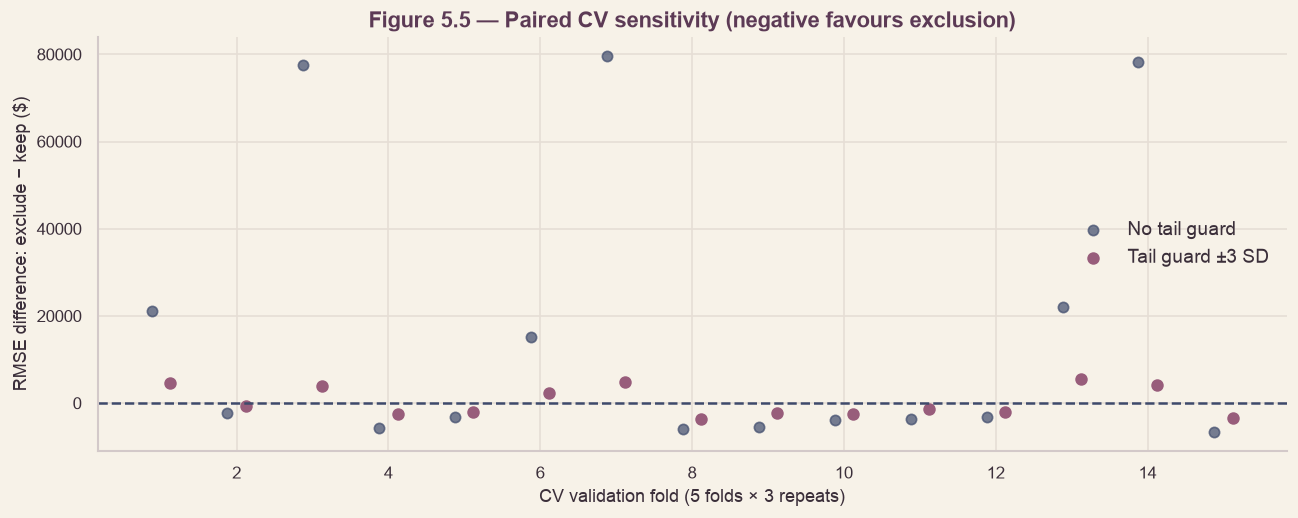

In [37]:
# ── 5.5 Fold-local row-exclusion sensitivity (with and without the tail guard) ──
from sklearn.metrics import mean_absolute_error

# Numeric-coded nominal variables are handled as categorical; retain every predictor.
cat5 = [c for c in X5.columns if not pd.api.types.is_numeric_dtype(X5[c]) or c in ('PropertyClass', 'SaleMon')]
num5 = [c for c in X5.columns if c not in cat5]

GUARD5 = ENCODING['tail']                      # the Section 3.10 choice (single source of truth)
NOGUARD_NAME, GUARD_NAME = 'No tail guard', f'Tail guard ±{GUARD5} SD'
PIPES5 = {NOGUARD_NAME: None, GUARD_NAME: GUARD5}

def build5(tail=None):
    """Section 5 is a sensitivity experiment, not final encoding/model selection."""
    num_steps = [('impute', SimpleImputer(strategy='median', add_indicator=True)), ('scale', StandardScaler())]
    if tail:
        num_steps.append(('zclip', FunctionTransformer(clip_z, kw_args={'c': tail}, feature_names_out='one-to-one')))
    prep = ColumnTransformer([
        ('numeric', Pipeline(num_steps), num5),
        ('categorical', Pipeline([('impute', SimpleImputer(strategy='most_frequent')),
                                  ('encode', OneHotEncoder(handle_unknown='ignore'))]), cat5)
    ], remainder='drop')
    return Pipeline([('preprocess', prep), ('regression', Ridge(alpha=20.0))])

cv5 = RepeatedKFold(n_splits=5, n_repeats=3, random_state=SEEDS['repeated_cv'])
cv_rows5 = []
for fold, (tr, va) in enumerate(cv5.split(X5), start=1):
    Xt, Xv = X5.iloc[tr], X5.iloc[va]; yt, yv = y5.iloc[tr], y5.iloc[va]
    excl = candidate_exclude5.iloc[tr]
    assert len(Xt) > int(excl.sum()) + 20
    for pipe_name, tail in PIPES5.items():
        for scenario, fit_mask in [('Keep all', np.ones(len(Xt), dtype=bool)),
                                   ('Exclude candidate Partial', ~excl.to_numpy())]:
            fitted = build5(tail).fit(Xt.iloc[fit_mask], np.log(yt.iloc[fit_mask]))
            pred = np.exp(fitted.predict(Xv))          # validation fold is never filtered
            cv_rows5.append({'Pipeline': pipe_name, 'Repeat': (fold - 1) // 5 + 1, 'Fold': fold, 'Scenario': scenario,
                             'Train n': int(fit_mask.sum()), 'Excluded in fold': int((~fit_mask).sum()),
                             'RMSE ($)': np.sqrt(mean_squared_error(yv, pred)), 'MAE ($)': mean_absolute_error(yv, pred)})
cv5_df = pd.DataFrame(cv_rows5)

def paired5(pipe_name, col):
    p = cv5_df[cv5_df['Pipeline'] == pipe_name].pivot(index=['Repeat', 'Fold'], columns='Scenario', values=col)
    return p['Exclude candidate Partial'] - p['Keep all']

rmse_diff5 = paired5(GUARD_NAME, 'RMSE ($)')          # guarded pipeline = the one carried forward
mae_diff5 = paired5(GUARD_NAME, 'MAE ($)')
rmse_diff5_ng = paired5(NOGUARD_NAME, 'RMSE ($)')     # kept for comparison
repeat_diff5 = rmse_diff5.groupby(level='Repeat').mean()

cv5_summary = (cv5_df.groupby(['Pipeline', 'Scenario'])
               .agg(mean_RMSE=('RMSE ($)', 'mean'), std_RMSE=('RMSE ($)', 'std'), mean_MAE=('MAE ($)', 'mean'),
                    min_excluded=('Excluded in fold', 'min'), max_excluded=('Excluded in fold', 'max')).reset_index())
show_table(cv5_summary, formats={'mean_RMSE': '${:,.0f}', 'std_RMSE': '${:,.0f}', 'mean_MAE': '${:,.0f}'},
           caption='Table 5.5 — Repeated-fold sensitivity (all validation sales retained)')

for name, d_rmse in [(NOGUARD_NAME, rmse_diff5_ng), (GUARD_NAME, rmse_diff5)]:
    print(f'{name}: paired RMSE difference (exclude − keep) ${d_rmse.mean():,.0f} | range ${d_rmse.min():,.0f} to ${d_rmse.max():,.0f}')
print(f'{GUARD_NAME}: paired MAE difference (exclude − keep) ${mae_diff5.mean():,.0f}')
print('Per-repeat mean paired RMSE differences, guarded ($):', repeat_diff5.round().to_dict())
# Three repeats do not support a reliable inferential CI. Display descriptive variation only.

fig, ax = plt.subplots(figsize=(11, 4.5))
ax.axhline(0, color=TWILIGHT, ls='--')
ax.scatter(np.arange(1, len(rmse_diff5_ng) + 1) - 0.12, rmse_diff5_ng.values, color=TWILIGHT, s=38, alpha=.7, label=NOGUARD_NAME)
ax.scatter(np.arange(1, len(rmse_diff5) + 1) + 0.12, rmse_diff5.values, color=MAUVE, s=42, label=GUARD_NAME)
ax.set(xlabel='CV validation fold (5 folds × 3 repeats)', ylabel='RMSE difference: exclude − keep ($)',
       title='Figure 5.5 — Paired CV sensitivity (negative favours exclusion)')
ax.legend(frameon=False)
plt.tight_layout(); save_fig(fig, 'fig5_5_cv_sensitivity', section='5'); plt.show()
assert TEST_LOG.count() == access_before_5

**Reading.** Without a tail guard, excluding the two candidate Partial sales from the training folds looked harmful (mean RMSE $65.7k against $48.8k), but both figures were dominated by one or two validation properties that the unguarded ridge extrapolates to implausible prices (see 3.10, Q0). With the ±3 SD guard the baseline falls to $30.6k with a fold SD of $8.8k, and the exclusion effect shrinks to +$337 (range −$3.8k to +$5.6k); the three repeat means are +$682, −$255 and +$584, so no consistent RMSE gain. MAE improves by $589 (15,114 against 15,703), but RMSE becomes less stable (fold SD $12.0k against $8.8k).

**Decision.** Retain all rows. Exclusion is not supported: there is no consistent RMSE gain, the MAE gain is small, and the two properties are better handled by the tail guard than by deletion. The sales remain flagged as a documented sensitivity scenario (5.4).

## 5.6 Decision Register and Section Summary

**Research question.** Which decisions were actually supported, and which are deferred?

**Method/test.** Register the screening, influence, adjudication and validation decisions; verify the test-access count is unchanged.

**Evidence.** Tables 5.1–5.5 and Figures 5.1–5.5.

**Decision.** Do not mistake a statistical screening flag for a data-quality defect. Record the CV sensitivity without promoting it to a final model-selection result.

In [38]:
# ── Section 5 Decision Register ────────────────────────────────
DECISIONS.add('5.1','Which numeric values are extreme?','IQR and modified Z-score screening on training numerics',
 f'{len(NUM5)} columns screened; highest IQR flag count {int(screen5["IQR flagged"].max())}; zero-MAD columns {int((~screen5["MAD available"]).sum())}.',
 'Use flags only as a review shortlist; retain all predictors and rows.','Documentation only')
DECISIONS.add('5.2','Which properties are unusual jointly?','Log1p selected magnitudes; robust-scaled MCD and chi-square reference screening',
 f'{int(mcd_flag5.sum())} robust-distance flags, {int((mcd_flag5 & any_uni5).sum())} overlapping univariate flags.',
 'Review flagged cases in context; do not delete based on distance alone.','Documentation only')
DECISIONS.add('5.3','Which observations influence exploratory OLS?','Cook distance, leverage, externally studentised residuals',
 f'{int((cooks5>cook_cut5).sum())} Cook flags (4/n); {int((lev5>lev_cut5).sum())} high-leverage flags.',
 'Influence is not an error label; investigate transaction context.','Documentation only')
DECISIONS.add('5.4','Are the large low-priced Partial sales anomalous?','Inspect all >4,000-sq-ft training cases, transaction context and local peer price/sq-ft',
 f'{len(large5)} large training properties; {int(candidate_exclude5.sum())} match the candidate Partial rule.',
 'Treat the Partial rule as a sensitivity scenario, not a confirmed data error.','Deliberately unchanged')
DECISIONS.add('5.5', 'Does training-row exclusion help on the observed sale mix?',
 f'Paired repeated 5-fold CV; fold-local exclusions; unfiltered validation folds; run with and without the ±{GUARD5} SD tail guard.',
 f'With the guard: mean paired RMSE difference (exclude minus keep) ${rmse_diff5.mean():,.0f}, repeat means {repeat_diff5.round().tolist()}; without the guard ${rmse_diff5_ng.mean():,.0f}.',
 'Retain all rows as the default; document exclusion as a candidate requiring domain justification and stable CV benefit.', 'Deliberately unchanged')
print('DECISION REGISTER — SECTION 5');DECISIONS.show('5')
print('Test-access count before Section 5:',access_before_5,'| after:',TEST_LOG.count())
assert TEST_LOG.count()==access_before_5,'Unexpected test access in Section 5'
print('Section 5 completed without opening the test vault.')

DECISION REGISTER — SECTION 5


ID,Section,Question,Method,Evidence,Decision,Effect
D42,5.1,Which numeric values are extreme?,IQR and modified Z-score screening on training numerics,33 columns screened; highest IQR flag count 94; zero-MAD columns 18.,Use flags only as a review shortlist; retain all predictors and rows.,Documentation only
D43,5.2,Which properties are unusual jointly?,Log1p selected magnitudes; robust-scaled MCD and chi-square reference screening,"172 robust-distance flags, 117 overlapping univariate flags.",Review flagged cases in context; do not delete based on distance alone.,Documentation only
D44,5.3,Which observations influence exploratory OLS?,"Cook distance, leverage, externally studentised residuals",57 Cook flags (4/n); 70 high-leverage flags.,Influence is not an error label; investigate transaction context.,Documentation only
D45,5.4,Are the large low-priced Partial sales anomalous?,"Inspect all >4,000-sq-ft training cases, transaction context and local peer price/sq-ft",4 large training properties; 2 match the candidate Partial rule.,"Treat the Partial rule as a sensitivity scenario, not a confirmed data error.",Deliberately unchanged
D46,5.5,Does training-row exclusion help on the observed sale mix?,Paired repeated 5-fold CV; fold-local exclusions; unfiltered validation folds; run with and without the ±3 SD tail guard.,"With the guard: mean paired RMSE difference (exclude minus keep) $337, repeat means [682.0, -255.0, 584.0]; without the guard $16,942.",Retain all rows as the default; document exclusion as a candidate requiring domain justification and stable CV benefit.,Deliberately unchanged


Test-access count before Section 5: 1 | after: 1
Section 5 completed without opening the test vault.


**What Section 5 established.** Screening is a shortlist, not a verdict: 33 columns screened, 172 jointly unusual properties, 57 above the Cook cut-off. Four training properties exceed 4,000 sq ft; two of them (524 and 1299) are Partial sales at about a quarter to a third of their peers' price per sq ft. Removing them from the training folds does not help once the tail guard of 3.10 is in place (paired RMSE change +$337; repeat means +$682, −$255, +$584), whereas without the guard the same experiment looked harmful (+$16,942), because those properties were being extrapolated. All rows and predictors are retained (D42 to D46), and the test vault was not opened (log count 1 before and after).

# 6. Univariate and Distributional EDA of Predictors

**Purpose.** Characterise the training predictors *before* modelling their relationship with sale price. All reported estimates use the Section 3 training split only. No columns are removed, no test rows are accessed, and candidate transformations are **not fitted to validation data**. Section 6 is descriptive; proposed transformations and rare-level grouping require fold-local fitting and later cross-validation.

**Research protocol:** Research question → Method/test → Evidence (including uncertainty where meaningful) → Decision. Source feature names follow the supplied renamed-property dataset.

## 6.1 Numeric Predictor Shapes and Structural Zeros

**Research question.** Which numerical features are highly skewed or zero-inflated, and which might benefit from `log1p` or presence indicators?

**Method/test.** For all numerical measurements (excluding numeric-coded categories `PropertyClass`, `SaleMon`, and calendar `SaleYr`), calculate valid count, missingness, median, IQR, skewness, excess kurtosis and zero share. Plot histograms for the most skewed or zero-heavy predictors. The **Wilson 95% interval** for each zero share quantifies binomial sampling uncertainty; it does not imply random sampling of all Ames houses. Discrete counts are retained and flagged separately from continuous measurements.

**Evidence.** Full numeric audit table, candidate flags and histogram grid. A large zero share may indicate legitimate absence rather than bad data.

**Decision.** Shortlist nonnegative, right-skewed features for fold-local `log1p`; shortlist zero-heavy variables for presence indicators. **Do not transform or drop columns in this section.**

In [39]:
# ── 6.1 Numeric distribution audit ───────────────────────────────
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from scipy import stats
from statsmodels.stats.proportion import proportion_confint
from matplotlib.ticker import PercentFormatter
assert 'X_train_clean' in globals() and 'y_train' in globals(), 'Run Sections 1–3 first.'
assert X_train_clean.index.equals(y_train.index), 'Training indices differ.'
access_before_6 = TEST_LOG.count()
X6 = X_train_clean.copy()
y6 = pd.to_numeric(y_train, errors='raise').astype(float)
assert (y6 > 0).all() and np.isfinite(y6).all()
NUM6 = [col for col in X6.select_dtypes(include='number').columns
        if col not in {'PropertyID','PropertyClass','SaleMon','SaleYr'}]
assert NUM6, 'No numerical predictors detected; inspect Section 2 metadata.'
rows6=[]
for col in NUM6:
    x=pd.to_numeric(X6[col],errors='coerce').dropna().astype(float)
    if len(x)==0: continue
    n0=int((x==0).sum()); lo,hi=proportion_confint(n0,len(x),alpha=.05,method='wilson')
    skew=float(stats.skew(x,bias=False)) if x.nunique()>1 else np.nan
    kurt=float(stats.kurtosis(x,bias=False)) if x.nunique()>1 else np.nan
    rows6.append({'Feature':col,'Nonmissing':len(x),'Missing %':100*(1-len(x)/len(X6)),
                  'Median':x.median(),'IQR':x.quantile(.75)-x.quantile(.25),
                  'Skewness':skew,'Excess kurtosis':kurt,'Zero %':100*n0/len(x),
                  'Zero CI low %':100*lo,'Zero CI high %':100*hi,
                  'Distinct':x.nunique(),'Nonnegative':bool((x>=0).all()),
                  'log1p candidate':bool((x>=0).all() and np.isfinite(skew) and skew>1),
                  'Presence candidate':bool(n0/len(x)>=.20 and x.nunique()>1)})
numeric6=pd.DataFrame(rows6).sort_values('Skewness',ascending=False,na_position='last').reset_index(drop=True)
show_table(numeric6,formats={'Missing %':'{:.1f}','Median':'{:,.1f}','IQR':'{:,.1f}',
 'Skewness':'{:.2f}','Excess kurtosis':'{:.2f}','Zero %':'{:.1f}',
 'Zero CI low %':'{:.1f}','Zero CI high %':'{:.1f}'},
 caption='Table 6.1 — Complete numerical predictor audit (training only)')
print('Numerical features:',len(numeric6),'| log1p candidates:',int(numeric6['log1p candidate'].sum()),
      '| presence-indicator candidates:',int(numeric6['Presence candidate'].sum()))
assert TEST_LOG.count()==access_before_6

Feature,Nonmissing,Missing %,Median,IQR,Skewness,Excess kurtosis,Zero %,Zero CI low %,Zero CI high %,Distinct,Nonnegative,log1p candidate,Presence candidate
AddVal,1168,0.0,0.0,0.0,23.85,638.60,96.7,95.6,97.6,15,True,True,True
PoolArea,1168,0.0,0.0,0.0,13.24,177.78,99.4,98.8,99.7,8,True,True,True
PropertySize,1168,0.0,"9,600.0","4,084.0",12.16,208.54,0.0,0.0,0.3,894,True,True,False
3SsnPorch,1168,0.0,0.0,0.0,10.07,118.54,98.2,97.3,98.8,18,True,True,True
LowQualFinSF,1168,0.0,0.0,0.0,8.91,80.53,98.3,97.4,98.9,19,True,True,True
KitchenUpLev,1168,0.0,1.0,0.0,4.76,25.29,0.1,0.0,0.5,4,True,True,False
ScreenPorch,1168,0.0,0.0,0.0,4.19,19.30,92.1,90.4,93.5,62,True,True,True
BsmtFinSF2,1168,0.0,0.0,0.0,4.13,18.87,88.2,86.2,89.9,121,True,True,True
BsmtHalfBath,1168,0.0,0.0,0.0,4.08,15.80,94.5,93.1,95.7,3,True,True,True
EnclosedPorch,1168,0.0,0.0,0.0,3.12,10.91,85.7,83.6,87.6,105,True,True,True


Numerical features: 33 | log1p candidates: 18 | presence-indicator candidates: 16


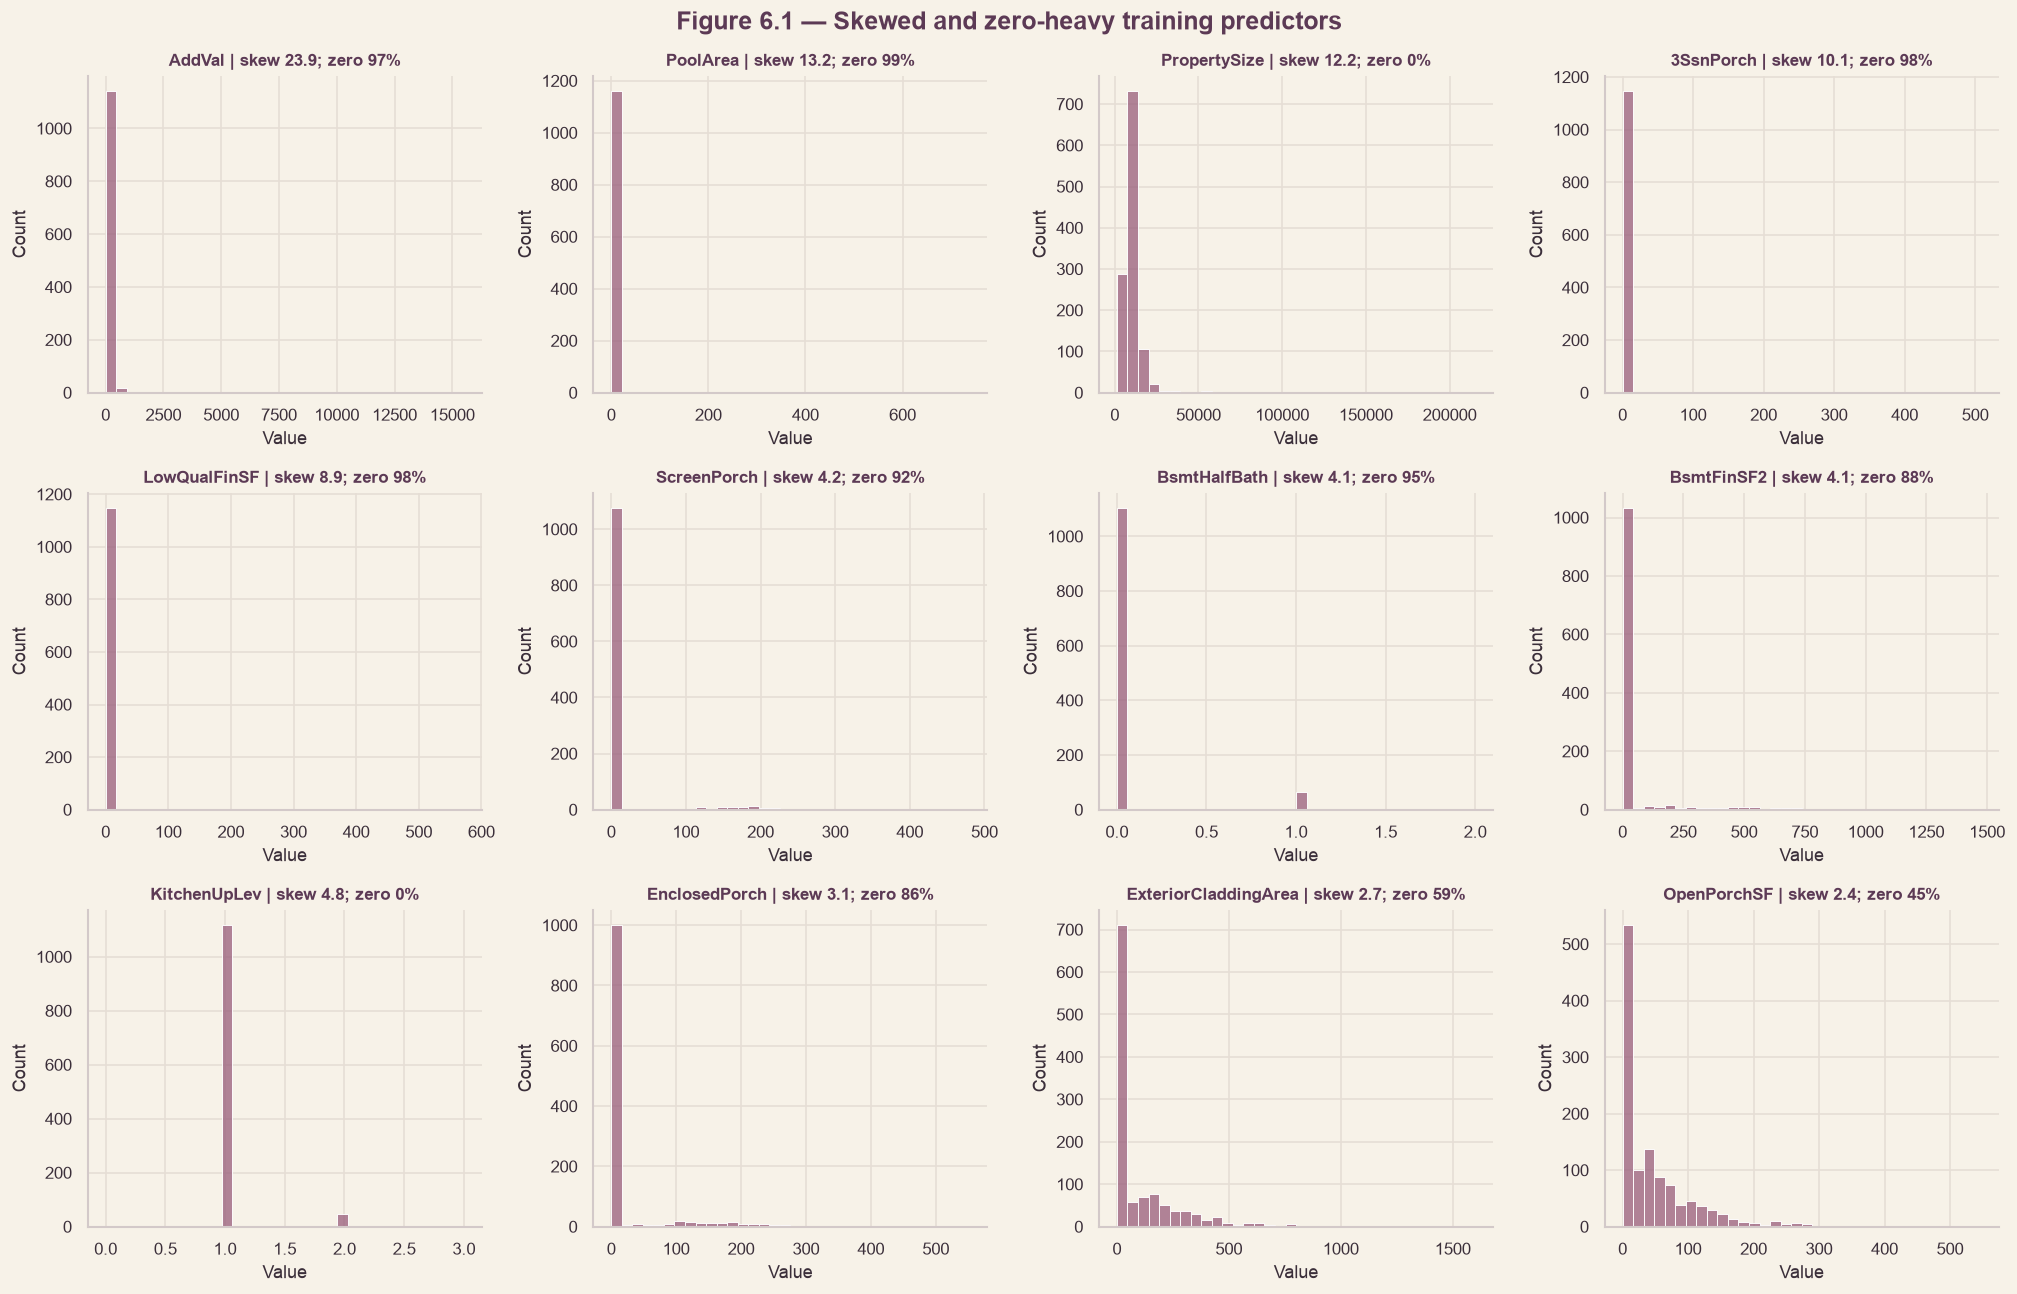

In [40]:
# ── 6.1 Distribution grid (descriptive, no transformations) ────
plot6=(numeric6.assign(priority=numeric6['Skewness'].clip(lower=0).fillna(0)
                      +numeric6['Zero %']/100)
       .sort_values('priority',ascending=False).head(12))
fig,axes=plt.subplots(3,4,figsize=(17,11)); axes=axes.ravel()
for ax,(_,r) in zip(axes,plot6.iterrows()):
    x=pd.to_numeric(X6[r['Feature']],errors='coerce').dropna()
    sns.histplot(x,bins=min(35,max(5,int(np.sqrt(len(x))))),color=MAUVE,ax=ax)
    ax.set_title(f"{r['Feature']} | skew {r['Skewness']:.1f}; zero {r['Zero %']:.0f}%",fontsize=10)
    ax.set_xlabel('Value');ax.set_ylabel('Count')
for ax in axes[len(plot6):]:ax.axis('off')
fig.suptitle('Figure 6.1 — Skewed and zero-heavy training predictors',fontweight='bold',color=DEEP_PLUM)
plt.tight_layout();save_fig(fig,'fig6_1_numeric_shapes',section='6');plt.show()
assert TEST_LOG.count()==access_before_6

**Reading.** 33 numeric predictors are audited (SaleYr, with only five distinct values, is left to 6.4). The table extends 4.2 with zero-share intervals and two candidate flags: 18 columns are log1p candidates (non-negative and |skewness| above 1; AddVal +23.85, PoolArea +13.24, PropertySize +12.16, 3SsnPorch +10.07, LowQualFinSF +8.91 lead) and 16 are presence-indicator candidates because many properties have none of the feature (zero share from 32 % for BsmntFinSty1 up to 99.4 % for PoolArea). Zero shares are tight where the evidence is large (WoodDeckSF 52.1 %, CI 49.2 to 54.9) and the near-empty columns are almost all zeros (PoolArea 99.4 %, 7 properties; LowQualFinSF 98.3 %, 20; 3SsnPorch 98.2 %, 21).

**Decision.** All original columns are preserved. Whether the log1p and presence candidates help is decided by fold-safe cross-validation in Section 9, not by skewness alone.

## 6.2 Categorical Cardinality, Rarity and Near-Constant Levels

**Research question.** Which categorical predictors have many levels, rare categories, or a single dominant category?

**Method/test.** Treat `PropertyClass` and `SaleMon` as nominal despite their numeric codes; treat ordinal quality ratings as *ordered categorical variables* according to Section 2 metadata. Count levels, dominant share and levels below 1% of nonmissing training observations. Preserve the distinction between literal `None` (structural absence), actual missing values, and a rare legitimate level. Plot dominant-level shares and inspect the expected near-constant candidates (`Street`, `Amenities`, `Condition2`, `RoofMatl`, `PoolQC`) **without presuming they are all near-constant**.

**Evidence.** Full cardinality audit, top-level counts, rarity list, Wilson interval for the dominant proportion.

**Decision.** Retain all source columns. Propose rare-category grouping **inside the CV preprocessing pipeline**, preserving `None` and missingness semantics. Avoid grouping ordered quality levels indiscriminately.

Feature,Levels,Nonmissing,Missing %,Dominant level,Dominant %,Dominant CI low %,Dominant CI high %,Rare levels (<1%),Rare observations,Near-constant (>=95%)
Amenities,2,1168,0.0,AllPub,99.9,99.5,100.0,1,1,True
Street,2,1168,0.0,Pave,99.7,99.2,99.9,1,3,True
PoolQC,4,1168,0.0,None,99.4,98.8,99.7,3,7,True
Condition2,8,1168,0.0,Norm,98.8,98.0,99.3,7,14,True
RoofMatl,8,1168,0.0,CompShg,98.1,97.2,98.8,7,22,True
Heating,5,1168,0.0,GasA,97.8,96.8,98.5,3,13,True
AddFeatures,4,1168,0.0,None,96.7,95.6,97.6,2,3,True
Grade,3,1168,0.0,Gtl,94.5,93.1,95.7,1,10,False
Alley,3,1168,0.0,None,94.3,92.8,95.5,0,0,False
CentralAir,2,1168,0.0,Y,93.7,92.1,94.9,0,0,False


Feature,Level,Count,Share %,Rare (<1%)
AddFeatures,TenC,1,0.09,True
AddFeatures,Gar2,2,0.17,True
Amenities,NoSeWa,1,0.09,True
BasementCond,Ex,1,0.09,True
BasementCond,Po,6,0.51,True
BasementCond,Gd,7,0.60,True
BasementQual,Ex,2,0.17,True
BasementQual,Po,2,0.17,True
BasementQual,Gd,11,0.94,True
BasementType,2Types,6,0.51,True


Feature,Levels,Nonmissing,Missing %,Dominant level,Dominant %,Dominant CI low %,Dominant CI high %,Rare levels (<1%),Rare observations,Near-constant (>=95%)
Amenities,2,1168,0.000000,AllPub,99.9,99.516630,99.984885,1,1,True
Street,2,1168,0.000000,Pave,99.7,99.247561,99.912610,1,3,True
PoolQC,4,1168,0.000000,None,99.4,98.768092,99.709393,3,7,True
Condition2,8,1168,0.000000,Norm,98.8,97.998111,99.284673,7,14,True
RoofMatl,8,1168,0.000000,CompShg,98.1,97.164535,98.752877,7,22,True


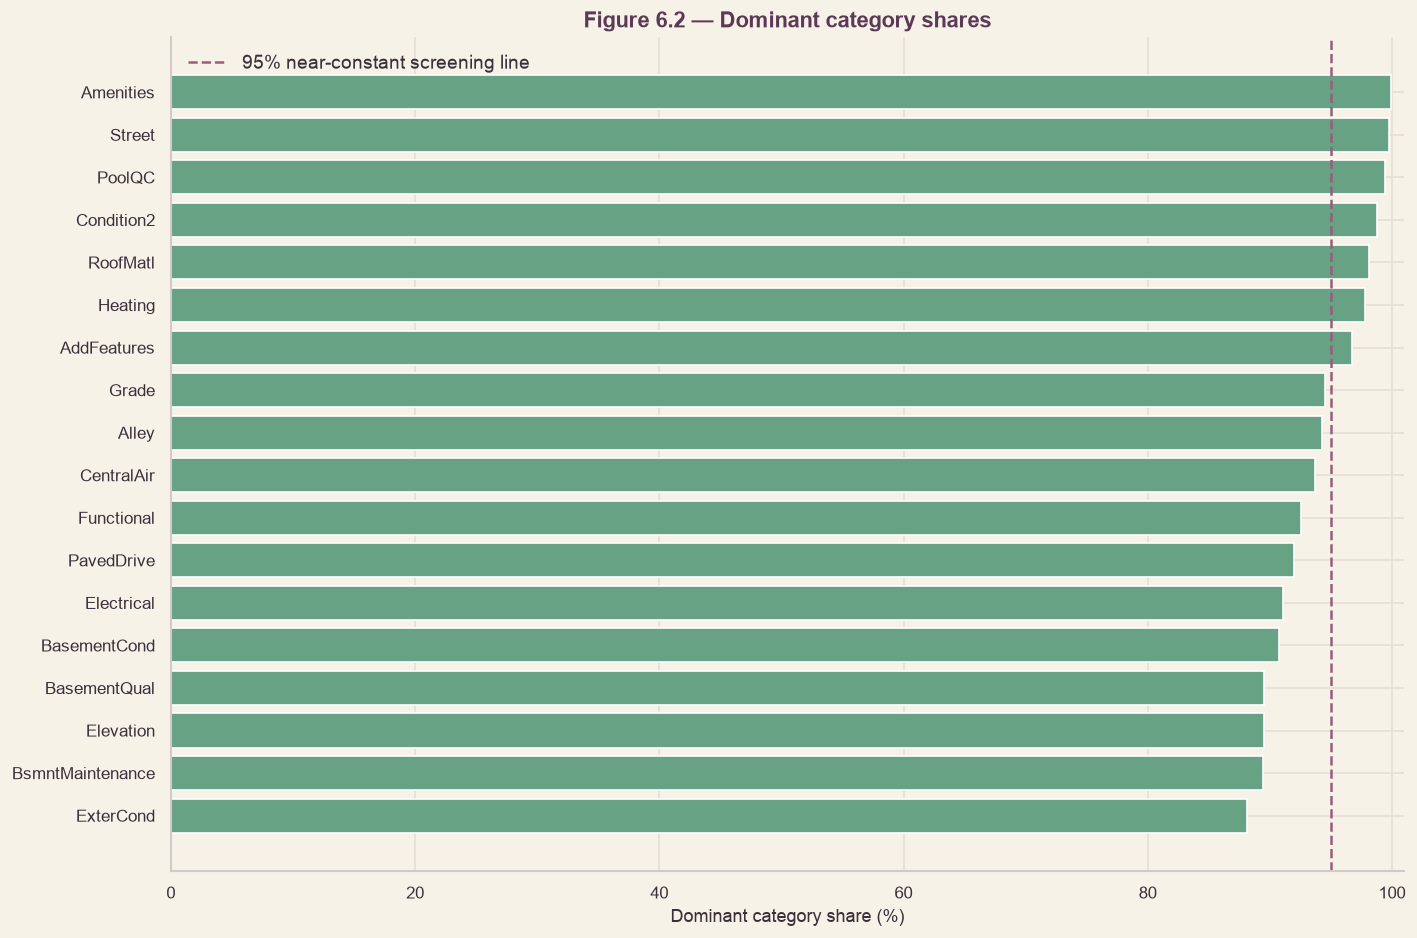

Near-constant features: ['Amenities', 'Street', 'PoolQC', 'Condition2', 'RoofMatl', 'Heating', 'AddFeatures']


In [41]:
# ── 6.2 Categorical rarity and cardinality ─────────────────────
CAT6=[col for col in X6.columns if col not in NUM6 and col not in {'PropertyID','SaleYr'}]
CAT6=list(dict.fromkeys(CAT6))
cat_rows6=[]; level_rows6=[]
for col in CAT6:
    s=X6[col].astype('string')
    # pandas NA remains missing; literal None remains a valid category.
    counts=s.dropna().value_counts(dropna=False)
    total=int(counts.sum())
    if not total: continue
    dominant=str(counts.index[0]); dom_n=int(counts.iloc[0]);lo,hi=proportion_confint(dom_n,total,method='wilson')
    rare=counts[counts/total<.01]
    cat_rows6.append({'Feature':col,'Levels':len(counts),'Nonmissing':total,
      'Missing %':100*(1-total/len(s)),'Dominant level':dominant,'Dominant %':100*dom_n/total,
      'Dominant CI low %':100*lo,'Dominant CI high %':100*hi,
      'Rare levels (<1%)':len(rare),'Rare observations':int(rare.sum()),
      'Near-constant (>=95%)':dom_n/total>=.95})
    for level,count in counts.items():
        level_rows6.append({'Feature':col,'Level':str(level),'Count':int(count),
                            'Share %':100*count/total,'Rare (<1%)':count/total<.01})
cat6=pd.DataFrame(cat_rows6).sort_values(['Dominant %','Levels'],ascending=False).reset_index(drop=True)
levels6=pd.DataFrame(level_rows6)
show_table(cat6,formats={'Missing %':'{:.1f}','Dominant %':'{:.1f}',
 'Dominant CI low %':'{:.1f}','Dominant CI high %':'{:.1f}'},
 caption='Table 6.2 — Categorical cardinality and rarity (all features)')
show_table(levels6[levels6['Rare (<1%)']].sort_values(['Feature','Count']).head(50),
 formats={'Share %':'{:.2f}'},caption='Table 6.3 — Rare categorical levels (first 50; complete list in levels6)')
expected6=['Street','Amenities','Condition2','RoofMatl','PoolQC']
show_table(cat6[cat6['Feature'].isin(expected6)],formats={'Dominant %':'{:.1f}'},
 caption='Table 6.4 — Pre-specified near-constant candidates: verification')
fig,ax=plt.subplots(figsize=(12,8));p6=cat6.head(18).iloc[::-1]
ax.barh(p6['Feature'],p6['Dominant %'],color=SAGE_GREEN)
ax.axvline(95,color=MAUVE,linestyle='--',label='95% near-constant screening line')
ax.set(xlim=(0,101),xlabel='Dominant category share (%)',title='Figure 6.2 — Dominant category shares')
ax.legend(frameon=False);plt.tight_layout();save_fig(fig,'fig6_2_category_dominance',section='6');plt.show()
print('Near-constant features:',cat6.loc[cat6['Near-constant (>=95%)'],'Feature'].tolist())
assert TEST_LOG.count()==access_before_6

**Reading.** Of the 45 categorical predictors, seven are near-constant, with one level at 95 % or more: Amenities 99.9 %, Street 99.7 %, PoolQC 99.4 %, Condition2 98.8 %, RoofMatl 98.1 %, Heating 97.8 % and AddFeatures 96.7 %. Alley (94.3 %), Grade (94.5 %) and CentralAir (93.7 %) sit just below that line. Rare levels (under 1 % of rows) are common in the high-cardinality columns: PropertyClass has 4 (28 rows), Neighborhood 4 (29 rows), Roof2Material 6 (22 rows) and Condition2 7 (14 rows); several levels have a single property (RoofMatl ClyTile, Amenities NoSeWa, Electrical Mix). Roof1Material and Roof2Material carry the most levels (15 and 16).

**Decision.** All columns are kept, as the brief requires. Rare-level pooling was already tested in 3.10 (Q2) and gave no gain; unseen and rare labels are handled by the encoders (infrequent bucket or all-zero row).

## 6.3 Structural Absence versus Genuine Missingness

**Research question.** Are the `None` values for pool, alley, fireplace, garage and basement features meaningful indicators of absent structures rather than missing observations?

**Method/test.** Inspect `PoolQC`, `Alley`, `QualFireplace`, `BasementQual`, and `BsmntFinish` (where available). Compare mean **log sale price** for literal `None` versus recorded present categories, with stratified bootstrap 95% confidence intervals for the difference. Report group sizes and the separate count of genuinely missing values. Do **not** interpret a difference as a causal effect or as a rule for imputing prices.

**Evidence.** Group means, sample counts, mean-log-price difference and bootstrap confidence interval; descriptive comparison plot. These are exploratory multiple comparisons: BH-adjusted Welch-test p-values are included as a secondary check, not a selection rule.

**Decision.** Preserve structural `None` as a legitimate category; do not replace it with mode/median or collapse it into genuine missingness. This comparison is observational and potentially confounded by property size, quality and age.

Structure,Feature,None n,Present n,Genuine missing n,Mean log None,Mean log present,Difference (present - None),95% CI low,95% CI high,Welch p,Status,BH-adjusted p
Pool,PoolQC,1161,7,0,12.023,12.426,+0.403,+0.107,+0.817,0.0884,Compared,0.0884
Alley,Alley,1101,67,0,12.039,11.802,-0.236,-0.328,-0.151,1.79e-06,Compared,2.24e-06
Fireplace,QualFireplace,540,628,0,11.802,12.217,+0.416,+0.377,+0.455,1.03e-80,Compared,5.14e-80
Garage,BasementQual,66,1102,0,11.496,12.057,+0.561,+0.478,+0.644,5.82e-21,Compared,1.46e-20
Basement,BsmntFinish,31,1137,0,11.567,12.037,+0.471,+0.377,+0.575,9.79e-11,Compared,1.63e-10


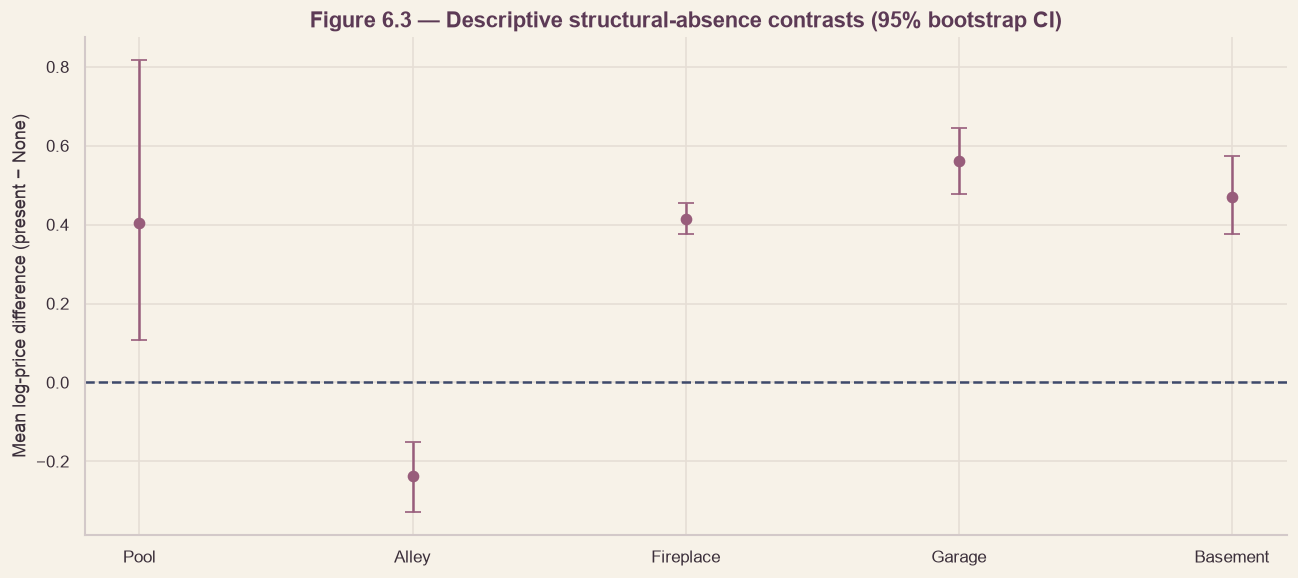

In [42]:
# ── 6.3 Structural absence comparison with stratified bootstrap ─
from statsmodels.stats.multitest import multipletests
absence6={'Pool':'PoolQC','Alley':'Alley','Fireplace':'QualFireplace',
          'Garage':'BasementQual','Basement':'BsmntFinish'}
# IMPORTANT: Dataset's renamed fields use 'Basement*' for GARAGE variables
# (BasementQual = GarageQual; BasementCars = GarageCars), whereas 'Bsmnt*' denotes basement.
# Only use labels backed by Section 2 dictionary; revise mapping if dictionary differs.
rng6=np.random.default_rng(SEEDS.get('bootstrap',123) if isinstance(SEEDS,dict) else 123)
BOOT6=2000; comparisons6=[]; sample_groups6={}
for structure,col in absence6.items():
    if col not in X6: continue
    s=X6[col].astype('string').str.strip()
    absent=s.eq('None').fillna(False)
    present=(s.notna() & ~absent)
    a=np.log(y6.loc[absent]).to_numpy(); p=np.log(y6.loc[present]).to_numpy()
    missing=int(s.isna().sum())
    if len(a)<2 or len(p)<2:
        comparisons6.append({'Structure':structure,'Feature':col,'None n':len(a),'Present n':len(p),
          'Genuine missing n':missing,'Mean log None':np.mean(a) if len(a) else np.nan,
          'Mean log present':np.mean(p) if len(p) else np.nan,'Difference (present - None)':np.nan,
          '95% CI low':np.nan,'95% CI high':np.nan,'Welch p':np.nan,'Status':'Insufficient groups'})
        continue
    delta=p.mean()-a.mean()
    boot=np.empty(BOOT6)
    for j in range(BOOT6):
        boot[j]=rng6.choice(p,len(p),replace=True).mean()-rng6.choice(a,len(a),replace=True).mean()
    lo,hi=np.percentile(boot,[2.5,97.5])
    pv=stats.ttest_ind(p,a,equal_var=False).pvalue
    comparisons6.append({'Structure':structure,'Feature':col,'None n':len(a),'Present n':len(p),
      'Genuine missing n':missing,'Mean log None':a.mean(),'Mean log present':p.mean(),
      'Difference (present - None)':delta,'95% CI low':lo,'95% CI high':hi,
      'Welch p':pv,'Status':'Compared'})
    sample_groups6[structure]=(a,p)
absence_table6=pd.DataFrame(comparisons6)
valid6=absence_table6['Welch p'].notna()
absence_table6['BH-adjusted p']=np.nan
if valid6.any():
    absence_table6.loc[valid6,'BH-adjusted p']=multipletests(absence_table6.loc[valid6,'Welch p'],method='fdr_bh')[1]
show_table(absence_table6,formats={'Mean log None':'{:.3f}','Mean log present':'{:.3f}',
 'Difference (present - None)':'{:+.3f}','95% CI low':'{:+.3f}','95% CI high':'{:+.3f}',
 'Welch p':'{:.3g}','BH-adjusted p':'{:.3g}'},
 caption='Table 6.5 — Structural absence and log-price associations (training only)')
fig,ax=plt.subplots(figsize=(11,5));d=absence_table6.dropna(subset=['Difference (present - None)'])
if not d.empty:
    x=np.arange(len(d));v=d['Difference (present - None)'].to_numpy()
    err=np.vstack([v-d['95% CI low'].to_numpy(),d['95% CI high'].to_numpy()-v])
    ax.errorbar(x,v,yerr=err,fmt='o',color=MAUVE,capsize=5)
    ax.set_xticks(x,d['Structure']);ax.axhline(0,color=TWILIGHT,linestyle='--')
ax.set(ylabel='Mean log-price difference (present − None)',
       title='Figure 6.3 — Descriptive structural-absence contrasts (95% bootstrap CI)')
plt.tight_layout();save_fig(fig,'fig6_3_structural_absence',section='6');plt.show()
assert TEST_LOG.count()==access_before_6

**Reading.** For the five structures where "None" means the feature does not exist (and no value is genuinely missing), mean log price differs between the absent and present groups as follows: fireplace +0.416 (95 % CI +0.377 to +0.455; present about 52 % higher), garage +0.561 (+0.478 to +0.644; about 75 %), basement +0.471 (+0.377 to +0.575; about 60 %), alley −0.236 (−0.328 to −0.151; the 67 properties with alley access are about 21 % cheaper), and pool +0.403 (+0.107 to +0.817) but with only 7 pools and a Welch p of 0.088, which is weak evidence. After Benjamini-Hochberg adjustment the first four remain highly significant (p ≤ 2e-6). These are associations: absence of a garage or basement goes with older, smaller houses, so none is read as an effect of the feature itself.

**Decision.** "None" is kept distinct from a true missing value, as in 3.5. No causal reading is made.

## 6.4 Temporal Predictors and Derived Age Features

**Research question.** How are construction year, remodel year, sale year and sale month distributed? Which transparent age-related features can be added **without replacing** original variables?

**Method/test.** Inspect `YearBuilt`, `YearRemodAdd`, `SaleYr`, and `SaleMon`; calculate `AgeAtSale = SaleYr - YearBuilt`, `YearsSinceRemodel = SaleYr - YearRemodAdd`, and `Remodelled = (YearRemodAdd > YearBuilt)`. Validate calendar ranges and flag negative ages or inconsistent dates. Plot year distributions, month frequencies and derived-age distributions.

**Evidence.** Observed ranges, temporal quality flags, missing counts, plots, and candidate feature definitions. The `Remodelled` indicator captures a date change, not renovation scope or quality.

**Decision.** Plan to **add** the three derived predictors in a fold-safe feature engineering transformer while retaining `YearBuilt`, `YearRemodAdd`, `SaleYr`, and `SaleMon` (the latter nominal). Do not silently clip negative values; investigate them.

Feature,Nonmissing,Missing,Minimum,Median,Maximum,Distinct
YearBuilt,1168,0,"1,872","1,973","2,010",110
YearRemodAdd,1168,0,"1,950","1,993","2,010",61
SaleYr,1168,0,"2,006","2,008","2,010",5
SaleMon,1168,0,1,6,12,12
AgeAtSale,1168,0,0,34,136,118
YearsSinceRemodel,1168,0,-1,15,60,62
Remodelled,1168,0,0,0,1,2


Check,Flagged
Negative AgeAtSale,0
Negative YearsSinceRemodel,1
Remodel year before construction,0
Sale month outside 1–12,0
Construction year outside 1800–2100,0


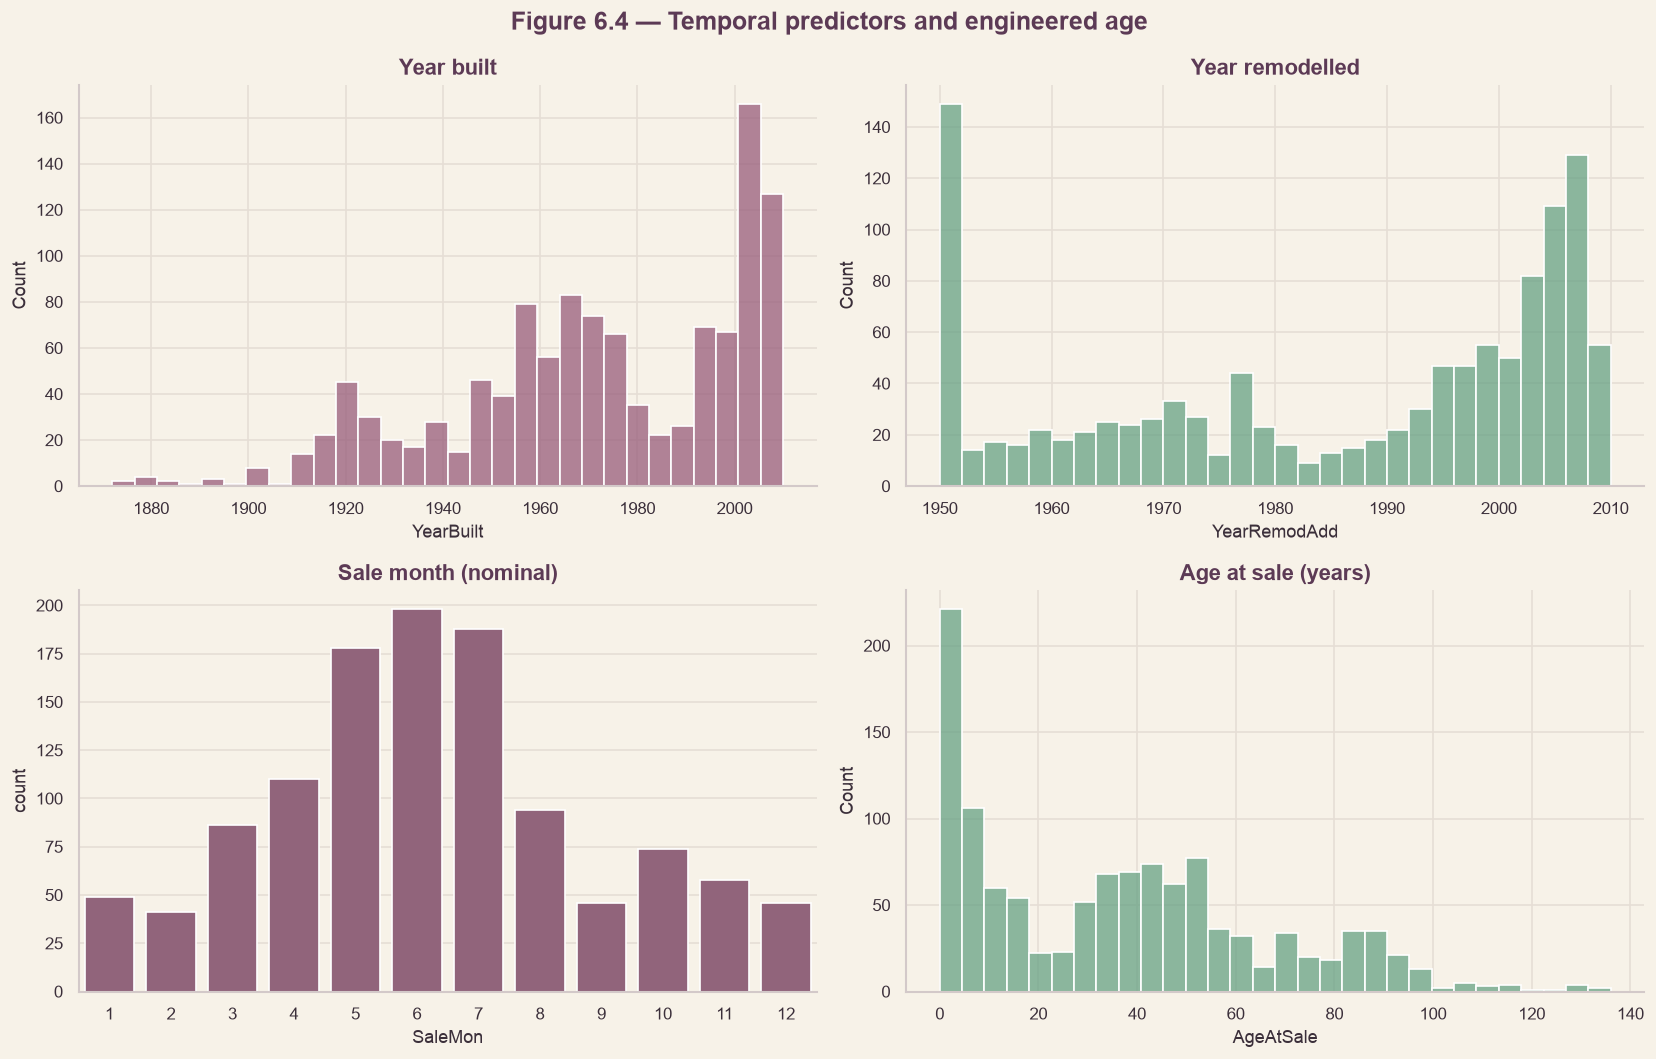

Derived columns are a preview only; X_train_clean remains unchanged.


In [43]:
# ── 6.4 Temporal audit and feature-engineering preview ────────
TIME6=['YearBuilt','YearRemodAdd','SaleYr','SaleMon']
assert set(TIME6).issubset(X6.columns), 'Required temporal fields absent.'
t6=X6[TIME6].apply(pd.to_numeric,errors='coerce')
preview6=pd.DataFrame(index=X6.index)
preview6['AgeAtSale']=t6['SaleYr']-t6['YearBuilt']
preview6['YearsSinceRemodel']=t6['SaleYr']-t6['YearRemodAdd']
preview6['Remodelled']=pd.Series(np.where(t6[['YearRemodAdd','YearBuilt']].notna().all(axis=1),
                        (t6['YearRemodAdd']>t6['YearBuilt']).astype(int),np.nan),index=X6.index)
temporal_rows6=[]
for col in TIME6+['AgeAtSale','YearsSinceRemodel','Remodelled']:
    x=t6[col] if col in t6 else preview6[col]
    temporal_rows6.append({'Feature':col,'Nonmissing':int(x.notna().sum()),
      'Missing':int(x.isna().sum()),'Minimum':x.min(),'Median':x.median(),
      'Maximum':x.max(),'Distinct':x.nunique()})
temporal6=pd.DataFrame(temporal_rows6)
show_table(temporal6,formats={'Minimum':'{:,.0f}','Median':'{:,.0f}','Maximum':'{:,.0f}'},
 caption='Table 6.6 — Training temporal variables and engineered feature preview')
checks6=pd.DataFrame([{'Check':'Negative AgeAtSale','Flagged':int((preview6['AgeAtSale']<0).sum())},
 {'Check':'Negative YearsSinceRemodel','Flagged':int((preview6['YearsSinceRemodel']<0).sum())},
 {'Check':'Remodel year before construction','Flagged':int((t6['YearRemodAdd']<t6['YearBuilt']).sum())},
 {'Check':'Sale month outside 1–12','Flagged':int((~t6['SaleMon'].between(1,12) & t6['SaleMon'].notna()).sum())},
 {'Check':'Construction year outside 1800–2100','Flagged':int((~t6['YearBuilt'].between(1800,2100) & t6['YearBuilt'].notna()).sum())}])
show_table(checks6,caption='Table 6.7 — Temporal integrity checks (training only)')
fig,axes=plt.subplots(2,2,figsize=(14,9))
sns.histplot(t6['YearBuilt'].dropna(),bins=30,color=MAUVE,ax=axes[0,0]);axes[0,0].set_title('Year built')
sns.histplot(t6['YearRemodAdd'].dropna(),bins=30,color=SAGE_GREEN,ax=axes[0,1]);axes[0,1].set_title('Year remodelled')
sns.countplot(x=t6['SaleMon'].astype('Int64').astype('string'),order=[str(i) for i in range(1,13)],color=MAUVE,ax=axes[1,0]);axes[1,0].set_title('Sale month (nominal)')
sns.histplot(preview6['AgeAtSale'].dropna(),bins=30,color=SAGE_GREEN,ax=axes[1,1]);axes[1,1].set_title('Age at sale (years)')
fig.suptitle('Figure 6.4 — Temporal predictors and engineered age',fontweight='bold',color=DEEP_PLUM)
plt.tight_layout();save_fig(fig,'fig6_4_temporal_distributions',section='6');plt.show()
print('Derived columns are a preview only; X_train_clean remains unchanged.')
assert TEST_LOG.count()==access_before_6

**Reading.** Sales span 2006 to 2010, houses were built between 1872 and 2010 (median 1973) and remodels are recorded from 1950. Preview features: AgeAtSale runs from 0 to 136 years (median 34), YearsSinceRemodel from −1 to 60 (median 15) and Remodelled is 1 for a minority of properties (median 0). Integrity checks find no negative age, no remodel before construction and no impossible month or year; one property has a remodel recorded after its sale (the −1, property 524 from 3.6), so years since remodel is clipped at 0 wherever it is used.

**Decision.** The derived columns are a preview only and the original columns are untouched. The age, years-since-remodel and remodelled features were tested by cross-validation in 9.7b and none was adopted.

## 6.5 Decision Register and Section Summary

**Research question.** Which predictor characteristics have been established, and which preprocessing choices remain provisional?

**Method/test.** Register each decision with observable evidence and check the test-access counter. No transformation, feature deletion or categorical grouping has yet been performed.

In [44]:
# ── 6.5 Register evidence and enforce test isolation ─────────
DECISIONS.add('6.1','Which numerical features are skewed or zero-inflated?',
 'Skewness, kurtosis, zero shares with Wilson intervals and distribution grid',
 f"{len(numeric6)} numeric predictors; {int(numeric6['log1p candidate'].sum())} log1p and {int(numeric6['Presence candidate'].sum())} presence candidates",
 'Preserve all originals; the 18 log1p and 16 presence candidates are compared by fold-safe CV in Section 9.','Changes the workflow')
DECISIONS.add('6.2','Which categorical levels are rare or dominant?',
 'Cardinality, dominant shares with Wilson intervals and <1% rare-level audit',
 f"{len(cat6)} categorical predictors; {int(cat6['Near-constant (>=95%)'].sum())} near-constant at >=95%",
 'Preserve all columns. Rare-level grouping was tested in 3.10 (Q2) with no gain; structural None is kept as its own level.','Changes the workflow')
DECISIONS.add('6.3','Does None encode meaningful structural absence?',
 'Training-only group means of log price; stratified bootstrap CIs; BH-adjusted Welch tests',
 f"{int(valid6.sum())} structures with sufficient comparison groups; differences and CIs in Table 6.5",
 'Keep None distinct from true missing; do not interpret association causally','Deliberately unchanged')
DECISIONS.add('6.4','What do temporal predictors imply for engineered features?',
 'Calendar distributions, age/remodel feature preview and integrity flags',
 f"Temporal flags total {int(checks6['Flagged'].sum())} (overlapping checks possible)",
 'Preview only; originals untouched. The age, years-since-remodel and remodelled features were tested by CV in 9.7b and none was adopted.',
 'Changes the workflow')
print('DECISION REGISTER — SECTION 6');DECISIONS.show('6')
print('Test access before Section 6:',access_before_6,'| after:',TEST_LOG.count())
assert TEST_LOG.count()==access_before_6,'Unexpected test access in Section 6'
print('Section 6 finished: test vault unopened.')

DECISION REGISTER — SECTION 6


ID,Section,Question,Method,Evidence,Decision,Effect
D47,6.1,Which numerical features are skewed or zero-inflated?,"Skewness, kurtosis, zero shares with Wilson intervals and distribution grid",33 numeric predictors; 18 log1p and 16 presence candidates,Preserve all originals; the 18 log1p and 16 presence candidates are compared by fold-safe CV in Section 9.,Changes the workflow
D48,6.2,Which categorical levels are rare or dominant?,"Cardinality, dominant shares with Wilson intervals and <1% rare-level audit",45 categorical predictors; 7 near-constant at >=95%,Preserve all columns. Rare-level grouping was tested in 3.10 (Q2) with no gain; structural None is kept as its own level.,Changes the workflow
D49,6.3,Does None encode meaningful structural absence?,Training-only group means of log price; stratified bootstrap CIs; BH-adjusted Welch tests,5 structures with sufficient comparison groups; differences and CIs in Table 6.5,Keep None distinct from true missing; do not interpret association causally,Deliberately unchanged
D50,6.4,What do temporal predictors imply for engineered features?,"Calendar distributions, age/remodel feature preview and integrity flags",Temporal flags total 1 (overlapping checks possible),"Preview only; originals untouched. The age, years-since-remodel and remodelled features were tested by CV in 9.7b and none was adopted.",Changes the workflow


Test access before Section 6: 1 | after: 1
Section 6 finished: test vault unopened.


**What Section 6 established.** 33 numeric predictors were audited: 18 are log1p candidates and 16 are presence-indicator candidates, to be tested by cross-validation in Section 9. Of 45 categorical predictors, 7 are near-constant (96.7 % to 99.9 % in one level) and many have rare levels, but all columns are kept and rare labels are handled in the encoders. "None" carries information: properties with a fireplace, garage or basement sell for about 52 %, 75 % and 60 % more than those without, and properties with alley access about 21 % less (associations, not effects). Age features are derived without changing the data. No row or column was removed (D47 to D50) and the test vault was not opened (log count 1 before and after).

**Next → Section 7: Bivariate Analysis.** Examine predictor–price relationships, effect sizes and multiplicity-adjusted comparisons without treating association as causation.

# 7. Bivariate Associations with the Target

**Purpose.** Identify the strongest *training-sample associations* with log sale price while respecting the Section 2 numerical, ordinal and nominal metadata. All analyses use training data only; **no test-set access**. No predictors are dropped and association is not causation.

**Methodological boundary.** Rank univariate associations for interpretation, not automatic feature selection. Correlated features, rare groups and multiplicity can mislead. Model selection and encoding comparisons use training-only CV.

## 7.1 Numerical Predictors versus Log Price

**Research question.** Which continuous/count predictors show strong monotonic or linear relationships with log sale price?

**Method/test.** Spearman rho and Pearson r, bootstrap percentile 95% CIs for Spearman, Benjamini–Hochberg adjustment across the numeric family, and LOWESS scatterplots of the strongest associations.

**Evidence.** Complete ranking, uncertainty intervals, p-values and LOWESS plots.

**Decision.** Shortlist relationships for modelling and diagnostics; retain every original column.

In [45]:
# ── 7.1 Training-only setup and numeric associations ────────────
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from scipy import stats
from statsmodels.stats.multitest import multipletests
from sklearn.feature_selection import mutual_info_regression
from sklearn.model_selection import RepeatedKFold, cross_val_score
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler, OrdinalEncoder
from sklearn.impute import SimpleImputer
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_squared_error
assert 'X_train_clean' in globals() and 'y_train' in globals(), 'Run Sections 1–3 first.'
assert X_train_clean.index.equals(y_train.index), 'Training indexes differ.'
start_access_7=TEST_LOG.count()
X7=X_train_clean.copy(); y7=np.log(pd.to_numeric(y_train,errors='raise').astype(float))
assert np.isfinite(y7).all() and (np.asarray(y_train)>0).all()
# Explicit exclusions reflect metadata corrections: numeric-looking nominal codes are NOT quantities.
NOMINAL_CODES_7={'PropertyClass','SaleMon'}
NUM7=[z for z in X7.select_dtypes(include='number').columns if z not in NOMINAL_CODES_7|{'PropertyID','SaleYr'}]
# SaleYr is handled as a temporal categorical/ordinal contextual variable, not continuous size.
rng7=np.random.default_rng(2026)
rows7=[]
for feature in NUM7:
    v=pd.to_numeric(X7[feature],errors='coerce'); ok=v.notna() & y7.notna()
    a=v[ok].to_numpy(float); target=y7[ok].to_numpy(float)
    if len(a)<15 or len(np.unique(a))<2: continue
    rho,p=stats.spearmanr(a,target); r,pp=stats.pearsonr(a,target)
    boots=[]
    for _ in range(400):
        ix=rng7.integers(0,len(a),len(a))
        if len(np.unique(a[ix]))>1: boots.append(stats.spearmanr(a[ix],target[ix]).statistic)
    ci=np.quantile(boots,[.025,.975]) if boots else [np.nan,np.nan]
    rows7.append({'Feature':feature,'n':len(a),'Spearman rho':rho,'rho CI low':ci[0],
                  'rho CI high':ci[1],'Spearman p':p,'Pearson r':r,'Pearson p':pp,
                  '|rho|':abs(rho),'|Pearson−Spearman|':abs(r-rho)})
numeric_assoc7=pd.DataFrame(rows7).sort_values('|rho|',ascending=False).reset_index(drop=True)
if len(numeric_assoc7):
    numeric_assoc7['BH q']=multipletests(numeric_assoc7['Spearman p'],method='fdr_bh')[1]
show_table(numeric_assoc7,formats={'Spearman rho':'{:.3f}','rho CI low':'{:.3f}',
 'rho CI high':'{:.3f}','Pearson r':'{:.3f}','Spearman p':'{:.2g}',
 'Pearson p':'{:.2g}','BH q':'{:.2g}','|rho|':'{:.3f}',
 '|Pearson−Spearman|':'{:.3f}'},caption='Table 7.1 — Numerical predictor associations (training only)')
print('Numerical predictors screened:',len(numeric_assoc7))
assert TEST_LOG.count()==start_access_7

Feature,n,Spearman rho,rho CI low,rho CI high,Spearman p,Pearson r,Pearson p,|rho|,|Pearson−Spearman|,BH q
OverallQual,1168,0.812,0.787,0.834,1.6e-275,0.823,6.2e-289,0.812,0.011,5.2e-274
GrLivArea,1168,0.730,0.692,0.759,8.9e-195,0.698,4.2e-171,0.730,0.032,1.5e-193
BasementCars,1168,0.698,0.665,0.735,1.9e-171,0.689,4.4e-165,0.698,0.009,2.1e-170
YearBuilt,1168,0.660,0.624,0.692,4.8e-147,0.594,2.9e-112,0.660,0.066,4e-146
BasementSqFootage,1168,0.656,0.621,0.692,1.2e-144,0.650,2.2e-141,0.656,0.006,7.8e-144
Bath1,1168,0.641,0.602,0.674,6.3e-136,0.603,1.1e-116,0.641,0.037,3.5e-135
BsmntSqFtage,1168,0.606,0.564,0.642,5.5e-118,0.608,3.5e-119,0.606,0.002,2.6e-117
BasementYrBlt,1102,0.605,0.566,0.642,4.3e-111,0.554,9.3e-90,0.605,0.051,1.6e-110
YearRemodAdd,1168,0.593,0.551,0.635,9.7e-112,0.583,2.4e-107,0.593,0.010,4e-111
1stFlrSF,1168,0.570,0.529,0.607,2.2e-101,0.594,2.8e-112,0.570,0.024,7.1e-101


Numerical predictors screened: 33


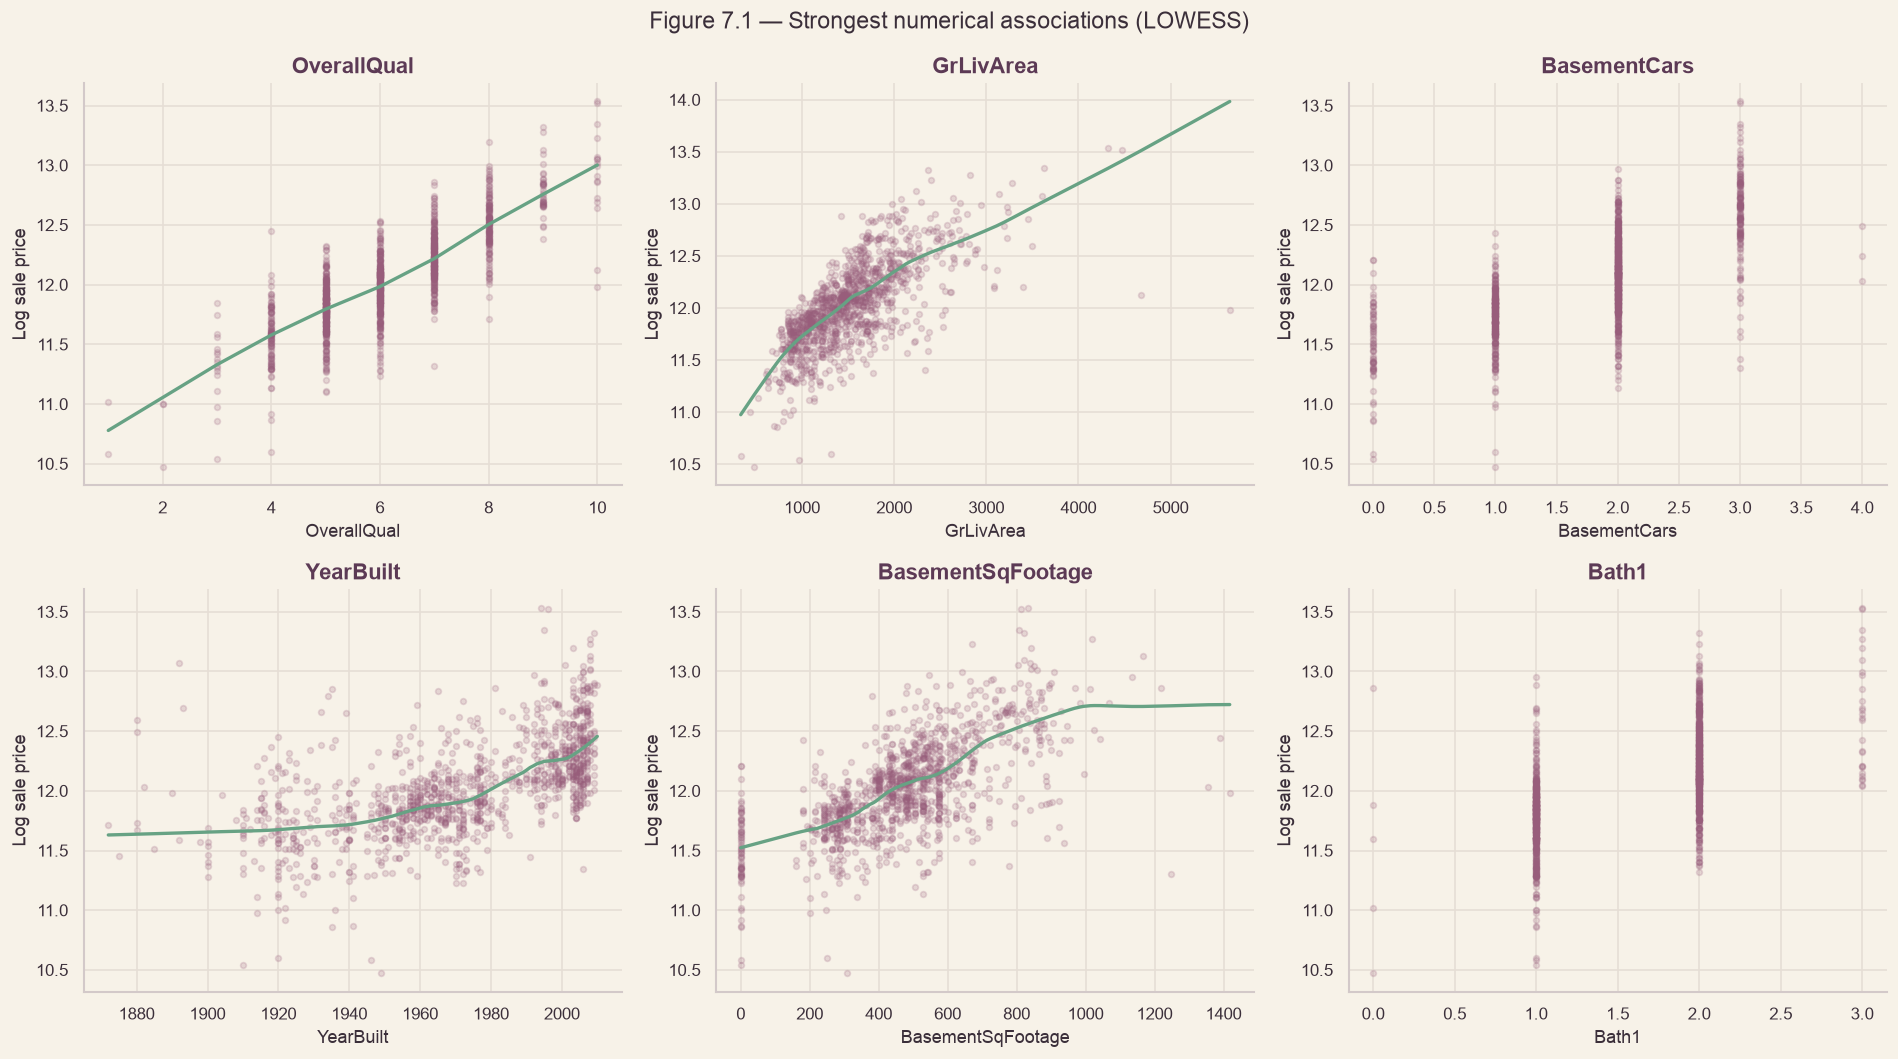

In [46]:
# ── 7.1 Top association scatterplots and LOWESS ────────────────
from statsmodels.nonparametric.smoothers_lowess import lowess
plot_cols7=numeric_assoc7.head(6)['Feature'].tolist()
fig,axs=plt.subplots(2,3,figsize=(16,9)); axs=np.ravel(axs)
for ax,feature in zip(axs,plot_cols7):
    v=pd.to_numeric(X7[feature],errors='coerce'); ok=v.notna() & y7.notna()
    a=v[ok].to_numpy(float); target=y7[ok].to_numpy(float)
    ax.scatter(a,target,alpha=.20,s=12,color='#985D7B',rasterized=True)
    if len(np.unique(a))>5:
        curve=lowess(target,a,frac=.35,return_sorted=True)
        ax.plot(curve[:,0],curve[:,1],color='#67A284',linewidth=2)
    ax.set(title=feature,xlabel=feature,ylabel='Log sale price')
for ax in axs[len(plot_cols7):]:ax.axis('off')
fig.suptitle('Figure 7.1 — Strongest numerical associations (LOWESS)',fontsize=14)
plt.tight_layout(); save_fig(fig,'fig7_1_numeric_lowess',section='7'); plt.show()

**Reading.** 28 of the 33 numeric predictors are associated with log price after Benjamini-Hochberg adjustment. The strongest are OverallQual (Spearman ρ = +0.812, 95 % CI +0.787 to +0.834), GrLivArea (+0.730), BasementCars (+0.698), YearBuilt (+0.660), BasementSqFootage (+0.656) and Bath1 (+0.641); the basement and first-floor areas and the remodel year follow at 0.57 to 0.61. Weak or no association: BsmtHalfBath (+0.003), BsmtFinSF2 (−0.031), LowQualFinSF, AddVal and 3SsnPorch (|ρ| about 0.055, not significant after adjustment). Three columns relate negatively (EnclosedPorch −0.217, KitchenUpLev −0.163, OverallCond −0.096). OverallCond is the one case where the monotone and linear readings disagree (Pearson r = −0.006), which says the relationship is not monotone. Pearson and Spearman agree closely for most columns; the exceptions are PropertySize (ρ +0.471 against r +0.273) and OpenPorchSF (+0.492 against +0.363), where a few extreme values depress the linear correlation.

**Decision.** Interpret these as associations, not effects. Every source predictor is retained.

## 7.2 Nonlinearity and Non-monotonicity Screen

**Research question.** Which numerical features might have nonlinear or non-monotonic relationships with price?

**Method/test.** Compare Pearson and Spearman correlations and estimate univariate mutual information using training observations. MI is nonnegative, model- and estimator-dependent, and has no direction or causal interpretation.

**Evidence.** Gap ranking and MI ranking. Scatterplots from 7.1 provide qualitative cross-checks.

**Decision.** Flag features for later spline/interaction experiments; CV must decide whether added complexity helps.

In [47]:
# ── 7.2 Mutual information and correlation gaps ────────────────
# MI handles missing numerical entries by training-median imputation, not by test information.
mi_input7=X7[NUM7].apply(pd.to_numeric,errors='coerce')
mi_input7=pd.DataFrame(SimpleImputer(strategy='median').fit_transform(mi_input7),
                        columns=NUM7,index=X7.index)
mi_scores7=mutual_info_regression(mi_input7,y7,random_state=42,n_neighbors=5)
mi7=pd.DataFrame({'Feature':NUM7,'Mutual information':mi_scores7})
nonlinear7=numeric_assoc7.merge(mi7,on='Feature',how='left').sort_values('Mutual information',ascending=False)
show_table(nonlinear7[['Feature','Spearman rho','Pearson r','|Pearson−Spearman|','Mutual information']],
 formats={'Spearman rho':'{:.3f}','Pearson r':'{:.3f}',
 '|Pearson−Spearman|':'{:.3f}','Mutual information':'{:.3f}'},
 caption='Table 7.2 — Nonlinearity screening, univariate MI and correlation gaps')
print('Candidate review list (not automatic feature engineering):',nonlinear7.head(8)['Feature'].tolist())

Feature,Spearman rho,Pearson r,|Pearson−Spearman|,Mutual information
OverallQual,0.812,0.823,0.011,0.584
GrLivArea,0.730,0.698,0.032,0.480
BasementSqFootage,0.656,0.650,0.006,0.386
BsmntSqFtage,0.606,0.608,0.002,0.378
BasementCars,0.698,0.689,0.009,0.368
YearBuilt,0.660,0.594,0.066,0.352
1stFlrSF,0.570,0.594,0.024,0.323
YearRemodAdd,0.593,0.583,0.010,0.279
BasementYrBlt,0.605,0.554,0.051,0.275
Bath1,0.641,0.603,0.037,0.268


Candidate review list (not automatic feature engineering): ['OverallQual', 'GrLivArea', 'BasementSqFootage', 'BsmntSqFtage', 'BasementCars', 'YearBuilt', '1stFlrSF', 'YearRemodAdd']


**Reading.** Mutual information ranks the same predictors first as the rank correlations: OverallQual (0.584), GrLivArea (0.480), BasementSqFootage (0.386), BsmntSqFtage (0.378), BasementCars (0.368), YearBuilt (0.352) and 1stFlrSF (0.323). Only PropertySize (|Pearson − Spearman| = 0.198) and OpenPorchSF (0.129) show a gap above 0.10, which marks a monotone but non-linear or outlier-driven relation. Five columns carry almost no signal on their own (mutual information at or below 0.003): PoolArea, 3SsnPorch, LowQualFinSF, AddVal and BsmtHalfBath. They are mostly zeros, so any value they have is likely as a presence flag, which Section 9 tests. The eight strongest predictors form the candidate review list; this is a list to examine, not automatic feature engineering.

**Decision.** No transformation or interaction is built here. Spline and interaction ideas are left to training cross-validation; the quality × area interaction was tested in 9.7b and was not adopted.

## 7.3 Ordinal Predictors versus Log Price

**Research question.** Do ordered grades and conditions rank property prices as the metadata sheet predicts?

**Method/test.** Apply *explicit semantic* ordinal mappings, calculate Spearman rho on the codes, and Kruskal–Wallis H with epsilon-squared effect size across observed grades. Apply Holm adjustment across the ordinal family. Unrecognised categories are reported, never silently coerced.

**Evidence.** Rank association, H, epsilon-squared, corrected p-values, and category audit.

**Decision.** Confirm or challenge metadata ordering; preserve columns and defer model-encoding choice to CV.

In [48]:
# ── 7.3 Semantic ordinal mappings: verify against Section 2 metadata ─
# IMPORTANT: These mappings are an explicit audit, not a substitute for the Section 2 dictionary.

# Ordinal orders come from the Section 3.9 metadata sheet; the two 1-10 scores are kept for continuity with 7.1.
ordinal_maps7 = {c: {lab: i for i, lab in enumerate(ORDINAL_SCALES[c][0])} for c in ORD_COLS}
ordinal_maps7.update({'OverallQual': {i: i for i in range(1, 11)}, 'OverallCond': {i: i for i in range(1, 11)}})
ordinal_rows7=[]; unmapped7={}
for feature,mapping in ordinal_maps7.items():
    if feature not in X7:continue
    raw=X7[feature]; coded=raw.map(mapping)
    # If already numeric, preserve the numeric grades.
    if pd.api.types.is_numeric_dtype(raw):coded=pd.to_numeric(raw,errors='coerce')
    unknown=sorted({str(z) for z in raw[coded.isna() & raw.notna()].unique()})
    if unknown:unmapped7[feature]=unknown
    ok=coded.notna() & y7.notna()
    if ok.sum()<20 or coded[ok].nunique()<2:continue
    a=coded[ok].to_numpy(float); t=y7[ok].to_numpy(float)
    rho,p=stats.spearmanr(a,t)
    groups=[t[a==v] for v in np.unique(a)]
    h,pk=stats.kruskal(*groups)
    nobs=len(t);k=len(groups)
    eps=max(0,(h-k+1)/(nobs-k)) if nobs>k else np.nan
    ordinal_rows7.append({'Feature':feature,'n':nobs,'Grades':k,'rho':rho,'rho p':p,
                          'H':h,'KW p':pk,'epsilon²':eps})
ordinal7=pd.DataFrame(ordinal_rows7).sort_values('epsilon²',ascending=False)
if len(ordinal7):ordinal7['Holm p']=multipletests(ordinal7['KW p'],method='holm')[1]
show_table(ordinal7,formats={'rho':'{:.3f}','rho p':'{:.2g}','H':'{:.2f}',
 'KW p':'{:.2g}','epsilon²':'{:.3f}','Holm p':'{:.2g}'},
 caption='Table 7.3 — Ordinal associations and family-wise Holm correction')
print('Unmapped category values requiring metadata review:',unmapped7)
assert not unmapped7, 'Resolve ordinal labels against Section 2 metadata before accepting this section.'

Feature,n,Grades,rho,rho p,H,KW p,epsilon²,Holm p
OverallQual,1168,10,0.812,1.6e-275,777.85,1.2e-161,0.664,2.6e-160
ExterQual,1168,4,0.691,2.8e-166,556.99,2.1e-120,0.476,4.3e-119
KitchenQual,1168,4,0.687,1.4e-163,551.70,3e-119,0.471,5.7e-118
BsmntFinish,1168,5,0.675,2.5e-156,534.85,1.9e-114,0.456,3.5e-113
BasementFinish,1168,4,0.637,3.8e-134,488.53,1.5e-105,0.417,2.5e-104
QualFireplace,1168,6,0.543,1.1e-90,374.97,7.3e-79,0.318,1.2e-77
HeatingEfficiency,1168,5,0.501,4.3e-75,295.40,1.1e-62,0.251,1.6e-61
BsmntFinRat1,1168,7,0.379,2.8e-41,291.46,5.5e-60,0.246,7.7e-59
OverallCond,1168,9,-0.096,0.0011,187.58,2.6e-36,0.155,3.4e-35
BasementQual,1168,6,0.362,1.8e-37,160.08,9.5e-33,0.133,1e-31


Unmapped category values requiring metadata review: {}


**Reading.** Orders are taken from the metadata sheet (19 ordinal columns plus the two 1-10 scores, 21 in all); no category failed to map. The quality and finish grades behave as ordered: OverallQual ρ = +0.812 (ε² 0.664), ExterQual +0.691, KitchenQual +0.687, BsmntFinish +0.675, BasementFinish +0.637, QualFireplace +0.543 and HeatingEfficiency +0.501. A middle group is clearly ordered but weaker: BsmntFinRat1 +0.379, BasementQual +0.362, BsmntVisibility +0.350, BasementCond +0.349, PavedDrive +0.285 and BsmntMaintenance +0.266. Two columns run against the declared direction: PropertyShape (ρ = −0.318, regular lots sell for less) and BoundaryFeatures (−0.192, an order that is an assumption). Four columns do not follow their order: ExterCond (ρ +0.033) and BsmntFinQual1 (+0.047) show no monotone trend although their grades do differ (Kruskal-Wallis ε² 0.028 and 0.039), OverallCond (ρ −0.096, ε² 0.155) is non-monotone, and Grade has no association (ε² 0.000, Holm p = 0.48). PoolQC rests on 7 pools (Holm p = 0.23) and is not significant.

**Decision.** The metadata orders are kept where the data support them; the orders that are not supported (ExterCond, BsmntFinQual1, Grade, BoundaryFeatures, BsmntFinRat1) were already tested as nominal in 3.10 with no gain. All columns are retained.

## 7.4 Nominal Predictors versus Log Price

**Research question.** Which unordered categories have the strongest univariate association with price?

**Method/test.** Kruskal–Wallis across observed groups with rank epsilon-squared, group sizes and Holm correction across the nominal family. Numeric-looking `PropertyClass` and `SaleMon` are explicitly nominal. Very sparse groups are documented; no rare levels are collapsed at this stage.

**Evidence.** Complete effect-size ranking and corrected p-values.

**Decision.** Rank nominal predictors for interpretation and later encoding experiments, without dropping any source column.

In [49]:
# ── 7.4 Nominal group differences ──────────────────────────────
ordinal_names7=set(ordinal_maps7)
nominal7=[z for z in X7.columns if z not in NUM7 and z not in ordinal_names7
          and z not in {'PropertyID','SaleYr'}]
for special in ['PropertyClass','SaleMon']:
    if special in X7 and special not in nominal7:nominal7.append(special)
nominal_rows7=[]
for feature in nominal7:
    levels=X7[feature].astype('string').fillna('Missing')
    groups=[y7[levels==v].to_numpy() for v in levels.unique()]
    groups=[g for g in groups if len(g)>0]
    if len(groups)<2:continue
    try:h,p=stats.kruskal(*groups)
    except ValueError:continue
    nobs=sum(map(len,groups));k=len(groups)
    eps=max(0,(h-k+1)/(nobs-k)) if nobs>k else np.nan
    nominal_rows7.append({'Feature':feature,'Levels':k,'Smallest group':min(map(len,groups)),
                          'H':h,'KW p':p,'epsilon²':eps})
nominal_assoc7=pd.DataFrame(nominal_rows7).sort_values('epsilon²',ascending=False).reset_index(drop=True)
if len(nominal_assoc7):nominal_assoc7['Holm p']=multipletests(nominal_assoc7['KW p'],method='holm')[1]
show_table(nominal_assoc7,formats={'H':'{:.2f}','KW p':'{:.2g}',
 'epsilon²':'{:.3f}','Holm p':'{:.2g}'},caption='Table 7.4 — Nominal associations with Holm correction')
print('Nominal predictors analysed:',len(nominal_assoc7))
print('Sparse levels warrant cautious inference; no category was removed.')

Feature,Levels,Smallest group,H,KW p,epsilon²,Holm p
Neighborhood,25,2,681.63,1.8e-128,0.575,4.7e-127
BasementType,7,6,435.57,6.3e-91,0.370,1.6e-89
PropertyClass,15,1,430.74,4.2e-83,0.361,1e-81
PropertyFooting,6,3,386.08,3e-81,0.328,6.8e-80
ExteriorCladdingType,5,8,233.16,2.8e-49,0.197,6.1e-48
Roof1Material,15,1,237.52,1.1e-42,0.194,2.2e-41
PropertyZone,5,8,212.14,9.2e-45,0.179,1.9e-43
Roof2Material,16,1,220.31,1.5e-38,0.178,2.9e-37
PropertyStyle,8,6,149.50,5.2e-29,0.123,9.3e-28
CentralAir,2,74,122.22,2.1e-28,0.104,3.5e-27


Nominal predictors analysed: 26
Sparse levels warrant cautious inference; no category was removed.


**Reading.** Of the 26 nominal and binary predictors, Neighborhood has by far the strongest group differences (ε² = 0.575, H = 681.6), followed by the garage type (BasementType, 0.370), PropertyClass (0.361) and PropertyFooting (0.328). A second tier is ExteriorCladdingType (0.197), the exterior covering columns Roof1Material and Roof2Material (0.194 and 0.178), PropertyZone (0.179), PropertyStyle (0.123) and CentralAir (0.104). Nothing separates price after Holm adjustment for Amenities, Street, AddFeatures, RoofMatl and Condition2 (p = 0.052), nor for SaleMon (ε² = 0.000, p = 0.66), so the month of sale carries no price information on its own. PropertyClass is the clearest case for nominal typing: its naive numeric correlation is ρ = −0.002, yet its group effect is ε² = 0.361. Several columns have levels with a single property (PropertyClass, Roof1Material, SaleType, Electrical, Condition1, RoofStyle), so their group tests are cautious evidence.

**Decision.** The ranking is for interpretation only. All predictors and levels are retained.

## 7.5 `PropertyClass` and `SaleMon`: Numeric-looking Nominal Codes

**Research question.** Does treating these codes as continuous quantities impose an unsupported ordering?

**Method/test.** Contrast naive numeric Spearman with nominal rank effect size. Then compare two Ridge pipelines—numeric versus one-hot encoding of the selected code—using *identical repeated CV folds* and the same other baseline predictors. Evaluate **dollar RMSE** after exponentiating log predictions. Compute a paired bootstrap interval over repeat-level mean differences, not over correlated individual folds.

**Evidence.** Effect-size contrast, repeated-CV RMSE by representation, paired difference and interval.

**Decision.** Maintain nominal typing as the semantically correct default; CV indicates predictive sensitivity, not whether the numeric codes have a real metric meaning.

In [50]:
# ── 7.5 Semantics and CV sensitivity of numeric-looking codes ─
from sklearn.base import clone
from sklearn.metrics import mean_squared_error
from sklearn.model_selection import RepeatedKFold
from sklearn.preprocessing import FunctionTransformer
# Stable baseline, using common continuous variables available in this dataset.
base7=[z for z in ['GrLivArea','OverallQual','YearBuilt','PropertySize','BsmntSqFtage'] if z in X7]
assert len(base7)>=3
cv7=RepeatedKFold(n_splits=5,n_repeats=3,random_state=2026)
folds7=list(cv7.split(X7)); cv_rows7=[]
for code_feature in ['PropertyClass','SaleMon']:
    if code_feature not in X7:continue
    codes=pd.to_numeric(X7[code_feature],errors='coerce')
    rho,p=stats.spearmanr(codes,y7,nan_policy='omit')
    group_effect=nominal_assoc7.loc[nominal_assoc7['Feature']==code_feature,'epsilon²']
    print(f'{code_feature}: naive numeric rho={rho:.3f}, nominal epsilon²={group_effect.iloc[0] if len(group_effect) else np.nan:.3f}')
    for encoding in ['numeric','nominal']:
        cols=base7+[code_feature]
        continuous=base7+([code_feature] if encoding=='numeric' else [])

        transforms=[('continuous',Pipeline([('impute',SimpleImputer(strategy='median')),
                                            ('scale',StandardScaler()),
                                            ('zclip',FunctionTransformer(clip_z,kw_args={'c':ENCODING['tail']},feature_names_out='one-to-one'))]),continuous)]
        if encoding=='nominal':
            transforms.append(('nominal',Pipeline([
                ('impute',SimpleImputer(strategy='most_frequent')),
                ('ohe',OneHotEncoder(handle_unknown='ignore'))]),[code_feature]))
        pre=ColumnTransformer(transforms,remainder='drop')
        for fi,(tr,va) in enumerate(folds7):
            Xtr=X7.iloc[tr][cols].copy();Xva=X7.iloc[va][cols].copy()
            if encoding=='nominal':
                Xtr[code_feature]=Xtr[code_feature].astype(str)
                Xva[code_feature]=Xva[code_feature].astype(str)
            model=Pipeline([('pre',clone(pre)),('reg',Ridge(alpha=10.0))])
            model.fit(Xtr,y7.iloc[tr])
            pred=np.exp(model.predict(Xva))
            actual=np.exp(y7.iloc[va].to_numpy())
            rmse=float(np.sqrt(mean_squared_error(actual,pred)))
            cv_rows7.append({'Feature':code_feature,'Encoding':encoding,
                             'Repeat':fi//5,'Fold':fi%5,'RMSE ($)':rmse})
cv_encoding7=pd.DataFrame(cv_rows7)
summary7=cv_encoding7.groupby(['Feature','Encoding'])['RMSE ($)'].agg(['mean','std']).reset_index()
show_table(summary7,formats={'mean':'{:,.1f}','std':'{:,.1f}'},
 caption='Table 7.5a — Repeated training-CV dollar RMSE by code treatment')
paired7=[];rng_pair7=np.random.default_rng(1707)
for feature in cv_encoding7['Feature'].unique():
    pivot=cv_encoding7.query('Feature==@feature').pivot(index=['Repeat','Fold'],columns='Encoding',values='RMSE ($)')
    # Positive difference: nominal has lower RMSE (numeric minus nominal).
    diff=pivot['numeric']-pivot['nominal']
    repeat_means=diff.groupby(level='Repeat').mean().to_numpy()
    boot=np.array([rng_pair7.choice(repeat_means,size=len(repeat_means),replace=True).mean() for _ in range(2000)])
    lo,hi=np.quantile(boot,[.025,.975])
    paired7.append({'Feature':feature,'Numeric−nominal RMSE ($)':diff.mean(),
                    'CI low ($)':lo,'CI high ($)':hi,'Repeats':len(repeat_means)})
paired_encoding7=pd.DataFrame(paired7)
show_table(paired_encoding7,formats={'Numeric−nominal RMSE ($)':'{:,.1f}',
 'CI low ($)':'{:,.1f}','CI high ($)':'{:,.1f}'},
 caption='Table 7.5b — Paired CV sensitivity (repeat-level bootstrap; 3 repeats, wide uncertainty)')
assert TEST_LOG.count()==start_access_7

PropertyClass: naive numeric rho=-0.002, nominal epsilon²=0.361
SaleMon: naive numeric rho=0.055, nominal epsilon²=0.000


Feature,Encoding,mean,std
PropertyClass,nominal,"35,213.9","7,102.9"
PropertyClass,numeric,"35,569.8","7,566.2"
SaleMon,nominal,"36,174.0","7,736.7"
SaleMon,numeric,"36,066.5","7,907.1"


Feature,Numeric−nominal RMSE ($),CI low ($),CI high ($),Repeats
PropertyClass,356.0,304.5,382.8,3
SaleMon,-107.5,-196.0,46.0,3


**Reading.** The five-feature ridge used here is stable (RMSE about $35k to $36k, fold SD about $7k to $8k). Treating PropertyClass as a number instead of a label costs $356 of RMSE on average (about 1 %), and treating SaleMon as a number changes it by −$107, within noise. The intervals come from only three repeat means, so they cannot be wider than the spread of those three values and are descriptive, not evidence of precision. Together with ρ = −0.002 against ε² = 0.361 for PropertyClass (7.4), they show that numeric coding is at best harmless and at worst hides a real association.

**Decision.** PropertyClass and SaleMon stay nominal. The decision rests on meaning (neither code supports arithmetic) rather than on the small RMSE difference; 3.10 reached the same result for the month with a cyclic encoding.

## 7.6 Optional Post-hoc Comparisons for a Top Nominal Predictor

**Research question.** Which sufficiently represented levels of the strongest nominal predictor differ in rank distribution?

**Method/test.** Dunn's rank-based pairwise z tests with tie correction and Holm adjustment, restricted to levels with at least 20 training observations. Rare levels remain in the dataset and are listed separately; they are *not* silently grouped. Only the highest-ranked nominal feature is explored to avoid unbounded post-hoc testing.

**Evidence.** Pairwise adjusted p-values, sample sizes and differences in mean log price (descriptive, not Dunn effect sizes).

**Decision.** Use patterns to motivate later rare-level grouping tests, not to remove or merge levels immediately.

In [51]:
# ── 7.6 Optional Dunn comparisons (self-contained; no scikit-posthocs dependency) ─
from itertools import combinations
if len(nominal_assoc7):
    top_nom7=nominal_assoc7.iloc[0]['Feature']
    group7=X7[top_nom7].astype('string').fillna('Missing')
    counts7=group7.value_counts()
    eligible7=counts7[counts7>=20].index.tolist()
    print('Selected feature:',top_nom7,'| levels with n>=20:',eligible7)
    print('Rare levels excluded from *post-hoc test only*:',counts7[counts7<20].to_dict())
    if len(eligible7)>=2:
        sel=group7.isin(eligible7)
        v=y7[sel].to_numpy(); g=group7[sel].to_numpy()
        ranks=stats.rankdata(v); n=len(v)
        tie_counts=pd.Series(v).value_counts().to_numpy()
        tie_factor=1-(np.sum(tie_counts**3-tie_counts)/(n**3-n)) if n>1 else 1
        var=(n*(n+1)/12)*tie_factor
        rows=[]
        for a,b in combinations(eligible7,2):
            ia=(g==a);ib=(g==b)
            za=(ranks[ia].mean()-ranks[ib].mean())/np.sqrt(var*(1/ia.sum()+1/ib.sum()))
            p=2*stats.norm.sf(abs(za))
            rows.append({'Level A':a,'Level B':b,'n A':ia.sum(),'n B':ib.sum(),
                         'Dunn z':za,'Raw p':p,'Mean log-price A−B':v[ia].mean()-v[ib].mean()})
        dunn7=pd.DataFrame(rows)
        dunn7['Holm p']=multipletests(dunn7['Raw p'],method='holm')[1]
        show_table(dunn7.sort_values('Holm p'),formats={'Dunn z':'{:.2f}',
         'Raw p':'{:.2g}','Holm p':'{:.2g}','Mean log-price A−B':'{:.3f}'},
         caption=f'Table 7.6 — Exploratory Holm-adjusted Dunn tests: {top_nom7}')
    else: print('Insufficient eligible levels: post-hoc comparison skipped.')
else:print('No nominal features suitable for post-hoc testing.')
assert TEST_LOG.count()==start_access_7

Selected feature: Neighborhood | levels with n>=20: ['NAmes', 'CollgCr', 'OldTown', 'Edwards', 'Gilbert', 'Somerst', 'Sawyer', 'NridgHt', 'NWAmes', 'BrkSide', 'SawyerW', 'Crawfor', 'Mitchel', 'NoRidge', 'IDOTRR', 'Timber', 'ClearCr', 'StoneBr']
Rare levels excluded from *post-hoc test only*: {'SWISU': 18, 'MeadowV': 15, 'BrDale': 12, 'Blmngtn': 11, 'Veenker': 10, 'NPkVill': 6, 'Blueste': 2}


Level A,Level B,n A,n B,Dunn z,Raw p,Mean log-price A−B,Holm p
OldTown,NridgHt,87,64,-13.75,5.4e-43,-0.934,8.2e-41
Edwards,NridgHt,79,64,-12.91,3.7e-38,-0.917,5.7e-36
NAmes,NridgHt,180,64,-12.45,1.4e-35,-0.758,2.1e-33
NridgHt,IDOTRR,64,31,11.82,2.9e-32,1.139,4.4e-30
NridgHt,BrkSide,64,48,11.79,4.4e-32,0.975,6.5e-30
OldTown,NoRidge,87,32,-11.46,2.2e-30,-1.015,3.3e-28
Sawyer,NridgHt,65,64,-11.36,6.3e-30,-0.815,9.3e-28
Edwards,NoRidge,79,32,-10.86,1.7e-27,-0.998,2.5e-25
NoRidge,IDOTRR,32,31,10.68,1.2e-26,1.221,1.8e-24
OldTown,Somerst,87,65,-10.61,2.8e-26,-0.614,4e-24


**Reading.** Neighborhood is the top nominal predictor, so it is examined in detail. Eighteen neighbourhoods with at least 20 training rows give 153 pairs; about 90 differ after Holm adjustment. The market is stratified: NridgHt, NoRidge and StoneBr sit at the top and IDOTRR, BrkSide, OldTown and Edwards at the bottom. The largest gaps are in mean log price: OldTown against NridgHt −0.934 (OldTown about 39 % of NridgHt's typical price) and NoRidge against IDOTRR +1.221 (about 3.4 times). Mid-range neighbourhoods are often not separable (OldTown against Edwards −0.017, CollgCr against Gilbert +0.002 and against Crawfor −0.018; Holm p = 1). Seven neighbourhoods with fewer than 20 rows (SWISU 18, MeadowV 15, BrDale 12, Blmngtn 11, Veenker 10, NPkVill 6, Blueste 2) were left out of these tests only; they stay in every model. These tests are exploratory.

**Decision.** No neighbourhoods are merged on the basis of these p-values. The full set of levels is kept for modelling.

## 7.7 Decision Register and Section Summary

**Research question.** What has the bivariate evidence established and which modelling decisions remain open?

**Method/test.** Record each procedure with its observed output and explicit deferred actions.

**Evidence.** Tables 7.1–7.6, Figure 7.1, adjusted p-values, effect sizes, and paired training-CV sensitivity.

**Decision.** Preserve all source predictors, respect the Section 2 semantic typing, and carry promising nonlinear/encoding hypotheses into later training-CV comparisons.

In [52]:
# ── 7.7 Evidence-linked decisions and test-access audit ────────

# ── 7.1 Numeric predictor associations ─────────────────────────
DECISIONS.add(
    '7.1',
    'Which numeric predictors associate with log price?',
    'Spearman/Pearson, bootstrap rho CIs, BH adjustment, LOWESS',
    (
        f'{len(numeric_assoc7)} numeric predictors; top: '
        + ', '.join(numeric_assoc7.head(3)['Feature'])
    ),
    'Interpret associations; retain every source predictor.',
    'Deliberately unchanged'
)

# ── 7.2 Nonlinear relationships ─────────────────────────────────
DECISIONS.add(
    '7.2',
    'Which numeric relations may be nonlinear?',
    'Pearson–Spearman gaps and univariate mutual information',
    (
        'Top MI candidates: '
        + ', '.join(nonlinear7.head(3)['Feature'])
    ),
    'Defer spline/interaction experiments to training CV.',
    'Changes the workflow'
)

# ── 7.3 Ordinal predictor associations ──────────────────────────
DECISIONS.add(
    '7.3',
    'Do ordinal grades follow the metadata order?',
    'Ordinal Spearman and Kruskal–Wallis with epsilon-squared; Holm',
    (
        f'{len(ordinal7)} ordinal features; '
        f'unmapped values: {len(unmapped7)}'
    ),
    'Keep semantic ordering; review inconsistent/unknown labels.',
    'Documentation only'
)

# ── 7.4 Nominal predictor associations ──────────────────────────
DECISIONS.add(
    '7.4',
    'Which nominal variables have stronger rank association?',
    'Kruskal–Wallis, rank epsilon-squared and Holm across nominal family',
    (
        f'{len(nominal_assoc7)} nominal and binary features; top: '
        + ', '.join(nominal_assoc7.head(3)['Feature'])
    ),
    'Rank for interpretation; retain all predictors and levels.',
    'Deliberately unchanged'
)

# ── 7.5 Encoding sensitivity ────────────────────────────────────
DECISIONS.add(
    '7.5',
    'How sensitive are coded nominal predictors to encoding?',
    'Repeated 5-fold CV, paired dollar RMSE differences and repeat-level bootstrap',
    '; '.join(
        f"{r['Feature']}: delta "
        f"${r['Numeric−nominal RMSE ($)']:,.0f}"
        for _, r in paired_encoding7.iterrows()
    ),
    'Keep PropertyClass and SaleMon nominal on semantic grounds.',
    'Changes the workflow'
)

# ── 7.6 Nominal category comparisons ────────────────────────────
DECISIONS.add(
    '7.6',
    'Which levels differ within the selected top nominal variable?',
    'Exploratory Dunn pairwise comparisons with Holm adjustment',
    (
        f"Selected feature: "
        f"{top_nom7 if len(nominal_assoc7) else 'none'}"
    ),
    'Do not merge rare categories based on exploratory p-values.',
    'Deliberately unchanged'
)

# ── Display Section 7 Decision Register ────────────────────────
print('DECISION REGISTER — SECTION 7')

DECISIONS.show('7')

# ── Test-set access audit ───────────────────────────────────────
assert TEST_LOG.count() == start_access_7, (
    'Section 7 unexpectedly accessed the test set.'
)

print(
    'SECTION 7 COMPLETE — test-set access count unchanged:',
    TEST_LOG.count()
)

DECISION REGISTER — SECTION 7


ID,Section,Question,Method,Evidence,Decision,Effect
D51,7.1,Which numeric predictors associate with log price?,"Spearman/Pearson, bootstrap rho CIs, BH adjustment, LOWESS","33 numeric predictors; top: OverallQual, GrLivArea, BasementCars",Interpret associations; retain every source predictor.,Deliberately unchanged
D52,7.2,Which numeric relations may be nonlinear?,Pearson–Spearman gaps and univariate mutual information,"Top MI candidates: OverallQual, GrLivArea, BasementSqFootage",Defer spline/interaction experiments to training CV.,Changes the workflow
D53,7.3,Do ordinal grades follow the metadata order?,Ordinal Spearman and Kruskal–Wallis with epsilon-squared; Holm,21 ordinal features; unmapped values: 0,Keep semantic ordering; review inconsistent/unknown labels.,Documentation only
D54,7.4,Which nominal variables have stronger rank association?,"Kruskal–Wallis, rank epsilon-squared and Holm across nominal family","26 nominal and binary features; top: Neighborhood, BasementType, PropertyClass",Rank for interpretation; retain all predictors and levels.,Deliberately unchanged
D55,7.5,How sensitive are coded nominal predictors to encoding?,"Repeated 5-fold CV, paired dollar RMSE differences and repeat-level bootstrap",PropertyClass: delta $356; SaleMon: delta $-107,Keep PropertyClass and SaleMon nominal on semantic grounds.,Changes the workflow
D56,7.6,Which levels differ within the selected top nominal variable?,Exploratory Dunn pairwise comparisons with Holm adjustment,Selected feature: Neighborhood,Do not merge rare categories based on exploratory p-values.,Deliberately unchanged


SECTION 7 COMPLETE — test-set access count unchanged: 1


**What Section 7 established.** Price is driven by quality, size and location. Among the 33 numeric predictors, 28 are associated with log price after adjustment, led by OverallQual (ρ = +0.812) and GrLivArea (+0.730). The quality and finish grades follow their metadata order (ρ 0.50 to 0.69); two columns run against the declared direction (PropertyShape, BoundaryFeatures) and four do not follow their order (ExterCond, BsmntFinQual1, OverallCond, Grade). Neighborhood is the strongest nominal predictor (ε² = 0.575) and separates the market into clear tiers; the month of sale carries no information. PropertyClass and SaleMon are labels, not quantities, and are kept nominal. No column or row was removed (D51 to D56) and the test vault was not opened (log count 1 before and after).

**Next → Section 8: Multivariate Associations, Collinearity and Interactions.**

# 8. Multicollinearity and Redundancy

**Purpose.** Identify numerical, categorical and algebraic redundancy without dropping source columns. All diagnostics use **training predictors only**. Association is not causation; a high VIF is not by itself a reason to delete a feature.

**Research discipline.** Each procedure follows **Research question → Method/test → Evidence → Decision**. This section contains descriptive diagnostics; model preference is determined by subsequent training-only cross-validation. The held-out test set remains sealed.

## 8.1 Numeric Correlation Structure

**Research question.** Which numerical predictor pairs exhibit strong monotone dependence (|Spearman ρ| > 0.80)?

**Method/test.** Calculate a training-only Spearman matrix on quantitative predictors. Numeric-looking nominal codes (`PropertyClass`, `SaleMon`) and the sale year are excluded from the quantitative block. Display a hierarchically clustered heatmap and a complete list of high-correlation pairs. Missing observations are handled pairwise for this descriptive analysis; the pairwise sample size is shown. Bootstrap intervals are reported for the highest-magnitude pairs.

**Evidence.** Table 8.1 and Figure 8.1, including coefficient magnitude, pairwise n and uncertainty. The threshold is a screening convention, not a significance test.

**Decision.** Document correlated groups and preserve every original predictor. Defer modelling consequences to Ridge, Lasso and ElasticNet comparisons.

In [53]:
# ── 8.1 Training-only correlation audit ──────────────────────────
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from scipy import stats
from scipy.cluster.hierarchy import linkage, leaves_list
from scipy.spatial.distance import squareform
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from statsmodels.stats.outliers_influence import variance_inflation_factor
assert 'X_train_clean' in globals() and 'y_train' in globals(), 'Run Sections 1–3 first.'
assert X_train_clean.index.equals(y_train.index), 'Training indices must match.'
access8=TEST_LOG.count()
X8=X_train_clean.copy()
nominal_codes8={'PropertyClass','SaleMon'}
quant8=[col for col in X8.select_dtypes(include='number').columns
        if col not in nominal_codes8 | {'PropertyID','SaleYr'}]
assert len(quant8)>=2
Q8=X8[quant8].apply(pd.to_numeric,errors='raise').replace([np.inf,-np.inf],np.nan)
rho8=Q8.corr(method='spearman')
records8=[]
for i,a in enumerate(quant8):
    for bb in quant8[i+1:]:
        val=rho8.loc[a,bb]
        if pd.notna(val) and abs(val)>.80:
            n_pair=int(Q8[[a,bb]].dropna().shape[0])
            records8.append({'Feature A':a,'Feature B':bb,'Spearman rho':val,
                             'Absolute rho':abs(val),'Pairwise n':n_pair})
strong_pairs8=pd.DataFrame(records8,columns=['Feature A','Feature B','Spearman rho','Absolute rho','Pairwise n'])
strong_pairs8=strong_pairs8.sort_values('Absolute rho',ascending=False).reset_index(drop=True)
if len(strong_pairs8):
    rng8=np.random.default_rng(2026)
    intervals=[]
    for _,row in strong_pairs8.head(12).iterrows():
        pair=Q8[[row['Feature A'],row['Feature B']]].dropna().to_numpy()
        vals=[]
        for _ in range(300):
            sample=pair[rng8.integers(0,len(pair),len(pair))]
            r=stats.spearmanr(sample[:,0],sample[:,1]).statistic
            if np.isfinite(r):vals.append(r)
        intervals.append(np.percentile(vals,[2.5,97.5]) if vals else [np.nan,np.nan])
    strong_pairs8['Bootstrap CI low']=np.nan
    strong_pairs8['Bootstrap CI high']=np.nan
    strong_pairs8.loc[:len(intervals)-1,['Bootstrap CI low','Bootstrap CI high']]=intervals
show_table(strong_pairs8,caption='Table 8.1 — Strong numerical Spearman pairs (|rho| > .80)')
print('Quantitative predictors:',len(quant8),' | strong pairs:',len(strong_pairs8))
assert TEST_LOG.count()==access8

Feature A,Feature B,Spearman rho,Absolute rho,Pairwise n,Bootstrap CI low,Bootstrap CI high
YearBuilt,BasementYrBlt,0.894096,0.894096,1102,0.862782,0.916945
BasementCars,BasementSqFootage,0.854379,0.854379,1168,0.833060,0.874163
BsmntSqFtage,1stFlrSF,0.827950,0.827950,1168,0.794221,0.860167
GrLivArea,CntRmsUpLev,0.824452,0.824452,1168,0.803475,0.846558


Quantitative predictors: 33  | strong pairs: 4


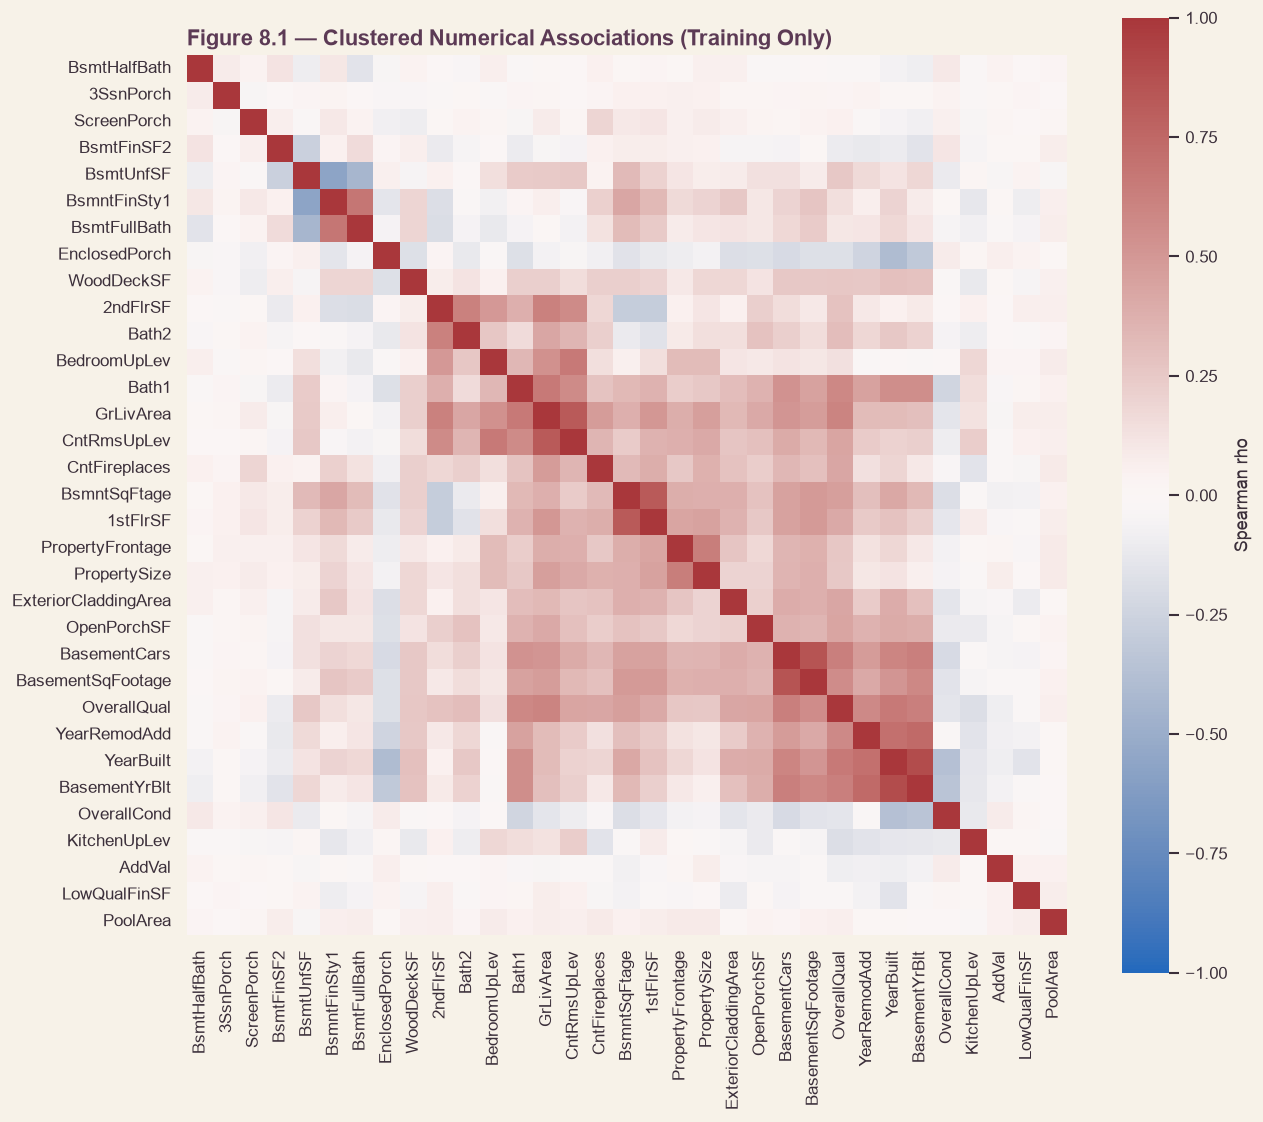

In [54]:
# ── 8.1 Clustered Spearman Heatmap ──────────────────────────────

# ── Identify valid numerical predictors ────────────────────────
valid8 = rho8.columns[
    rho8.notna().all(axis=0)
].tolist()

R8 = rho8.loc[valid8, valid8].clip(-1, 1)

# ── Hierarchical clustering ─────────────────────────────────────
if len(valid8) >= 3:

    # Convert absolute correlations into distances
    D8 = (1 - R8.abs()).clip(lower=0)

    # Create a writable NumPy array
    D8_array = D8.to_numpy(copy=True)

    # Ensure the distance matrix has a zero diagonal
    np.fill_diagonal(D8_array, 0)

    # Hierarchical clustering using average linkage
    order8 = leaves_list(
        linkage(
            squareform(D8_array, checks=False),
            method='average'
        )
    )

    # Reorder correlation matrix by cluster membership
    R8 = R8.iloc[order8, order8]

# ── Plot clustered Spearman correlation heatmap ────────────────
fig, ax = plt.subplots(
    figsize=(
        max(11, len(R8) * 0.32),
        max(9, len(R8) * 0.29)
    )
)

sns.heatmap(
    R8,
    cmap='vlag',
    vmin=-1,
    vmax=1,
    center=0,
    ax=ax,
    cbar_kws={'label': 'Spearman rho'},
    square=True
)

ax.set_title(
    'Figure 8.1 — Clustered Numerical Associations (Training Only)',
    loc='left'
)

plt.tight_layout()

# ── Save figure ─────────────────────────────────────────────────
if 'save_fig' in globals():
    save_fig(
        fig,
        'fig8_1_numeric_correlation',
        section='8'
    )

plt.show()

**Reading.** Four of the 33 quantitative predictors form strongly correlated pairs (|ρ| above 0.80): YearBuilt with BasementYrBlt (ρ = +0.894, 95 % CI +0.863 to +0.917; garages are usually built with the house), BasementCars with BasementSqFootage (+0.854; garage capacity and garage area), BsmntSqFtage with 1stFlrSF (+0.828; a basement usually matches the floor above) and GrLivArea with CntRmsUpLev (+0.824; more rooms, more area). No other pair exceeds the cut-off.

**Decision.** The correlated groups are documented and every source column is retained.

## 8.2 Variance Inflation Factors

**Research question.** How severe is linear dependence in a reproducible, reference-encoded design matrix?

**Method/test.** Median-impute and standardise quantitative columns, add reference-dropped one-hot encodings of nominal categorical columns, and compute VIF using a common design. Exclude constant dummy columns from VIF calculations **only** (they remain in the source data). Report matrix rank and condition number to distinguish exact from near dependence. VIFs may be infinite under exact identities.

**Evidence.** Table 8.2: VIF, rank, condition number, and interpretation bands (5 and 10 are heuristics).

**Decision.** Preserve the columns. Use regularised estimators and validation to address coefficient instability; do not interpret unregularised coefficients as independent effects.

In [55]:
# ── 8.2 Reference-encoded design and VIF ──────────────────────
# VIF on hundreds of dummy columns is costly; the reference design here
# includes the quantitative block and a small, documented nominal set.
nominal_reference8=[v for v in ['PropertyClass','SaleMon','Neighborhood','PropertyZone','BldgType'] if v in X8]
imp8=SimpleImputer(strategy='median')
q8=imp8.fit_transform(Q8)
q8=StandardScaler().fit_transform(q8)
quant_names8=quant8.copy()
# Remove zero-variance numeric columns from this *diagnostic matrix* only.
keep_q8=np.std(q8,axis=0)>1e-12
q8=q8[:,keep_q8]; quant_names8=np.array(quant_names8)[keep_q8].tolist()
blocks8=[q8]; names8=quant_names8.copy()
for name in nominal_reference8:
    values=X8[name].astype('string').fillna('__MISSING__').astype(str)
    dummies=pd.get_dummies(values,prefix=name,drop_first=True,dtype=float)
    dummies=dummies.loc[:,dummies.std(axis=0)>0]
    if len(dummies.columns):
        blocks8.append(dummies.to_numpy());names8+=dummies.columns.tolist()
V8=np.column_stack(blocks8)
# Centre/scale the full diagnostic design (including dummy columns).
V8=StandardScaler().fit_transform(V8)
rank8=int(np.linalg.matrix_rank(V8))
condition8=float(np.linalg.cond(V8))
# Efficient VIF: VIF_j = diag(pinv(R)) when full rank; exact collinearity => inf.
R_vif8=np.corrcoef(V8,rowvar=False)
eig8=np.linalg.eigvalsh(R_vif8)
if eig8.min()<1e-9:
    # Mark predictors with an exact linear dependency using a nullspace basis.
    u,s,vh=np.linalg.svd(V8,full_matrices=False)
    null=vh[s<1e-8*max(s[0],1)] if len(s) else np.empty((0,V8.shape[1]))
    involved=(np.max(abs(null),axis=0)>1e-6) if len(null) else np.zeros(V8.shape[1],bool)
    vif_values8=np.diag(np.linalg.pinv(R_vif8,hermitian=True)).copy()
    vif_values8[involved]=np.inf
else:
    vif_values8=np.diag(np.linalg.inv(R_vif8))
vif_table8=pd.DataFrame({'Encoded feature':names8,'VIF':vif_values8})
vif_table8['Assessment']=np.select([np.isinf(vif_values8),vif_values8>=10,vif_values8>=5],
                                   ['Exact dependency','High','Elevated'],default='Lower')
vif_table8=vif_table8.sort_values('VIF',ascending=False).reset_index(drop=True)
show_table(vif_table8,caption='Table 8.2 — VIF on reference-encoded training design')
print(f'Diagnostic columns: {V8.shape[1]}, rank: {rank8}, condition number: {condition8:.3g}')
print('Note: this is a documented reference design, not the full modelling pipeline.')
assert TEST_LOG.count()==access8

Encoded feature,VIF,Assessment
GrLivArea,inf,Exact dependency
BsmntSqFtage,inf,Exact dependency
PropertyClass_90,inf,Exact dependency
BldgType_Duplex,inf,Exact dependency
LowQualFinSF,inf,Exact dependency
2ndFlrSF,inf,Exact dependency
1stFlrSF,inf,Exact dependency
BsmntFinSty1,inf,Exact dependency
BsmtFinSF2,inf,Exact dependency
BsmtUnfSF,inf,Exact dependency


Diagnostic columns: 90, rank: 87, condition number: 5.54e+17
Note: this is a documented reference design, not the full modelling pipeline.


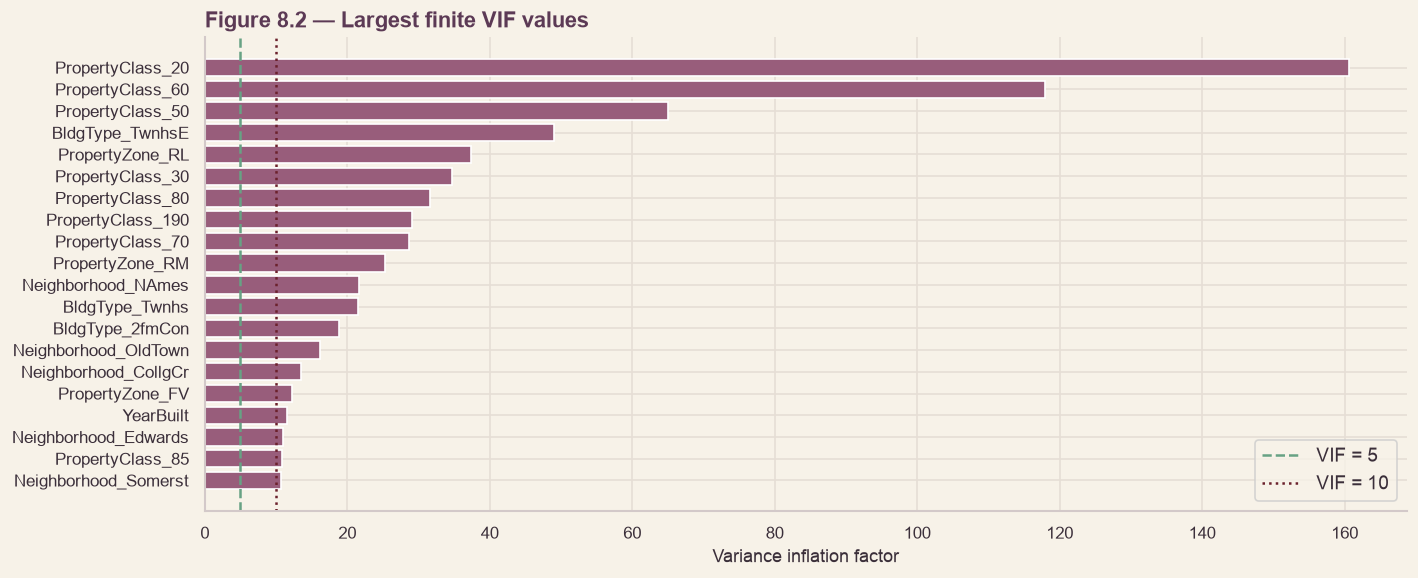

In [56]:
# ── 8.2 VIF distribution ───────────────────────────────────────
fig,ax=plt.subplots(figsize=(12,5))
finite8=vif_table8[np.isfinite(vif_table8['VIF'])].head(20).iloc[::-1]
ax.barh(finite8['Encoded feature'],finite8['VIF'],color='#985D7B')
ax.axvline(5,ls='--',color='#67A284',label='VIF = 5')
ax.axvline(10,ls=':',color='#6B212C',label='VIF = 10')
ax.set_xlabel('Variance inflation factor');ax.set_title('Figure 8.2 — Largest finite VIF values',loc='left')
ax.legend();plt.tight_layout()
if 'save_fig' in globals():save_fig(fig,'fig8_2_vif',section='8')
plt.show()

**Reading.** In the reference design (90 encoded terms, reference-level coding) the rank is 87, so there are exactly three exact linear dependencies, and ten terms show an infinite VIF. Two of them are the area identities confirmed in 8.4: GrLivArea = 1stFlrSF + 2ndFlrSF + LowQualFinSF, and BsmntSqFtage = BsmntFinSty1 + BsmtFinSF2 + BsmtUnfSF. The third is a duplicate indicator: PropertyClass_90 and BldgType_Duplex mark the same properties. Among the remaining terms, 18 have a high VIF (above 10). They are mostly dummies of the overlapping dwelling descriptors (PropertyClass_20 at 160.7, _60 at 118.0 and _50 at 65.1; BldgType_TwnhsE at 49.0), zoning and neighbourhood dummies (PropertyZone_RL 37.4, Neighborhood_NAmes 21.6) and YearBuilt (11.6). The condition number is 5.5e17. OverallQual (VIF 4.1), the numeric areas and the other scores are not a concern. This is a documented reference design, not the modelling pipeline, which keeps every level (246 encoded columns).

**Decision.** No predictor is dropped. The penalty in ridge, lasso and ElasticNet handles exact and near-exact dependencies, so they are compared by cross-validation in Section 10. Plain linear regression has no penalty, which fits its larger fold-to-fold spread in 10.3 (extrapolation also contributes there).

## 8.3 Categorical Association

**Research question.** Which nominal predictors are strongly associated with one another?

**Method/test.** For each pair of nominal variables, compute bias-corrected Cramér's V from the contingency table. Include `PropertyClass` and `SaleMon` as nominal codes. Exclude ordered grade variables when a semantic metadata list is available. Report pairs with V > 0.50 and a clustered heatmap.

**Evidence.** Table 8.3 and Figure 8.3; the threshold is descriptive. Rare categories and small expected cell counts make pair estimates unstable.

**Decision.** Record redundancy; retain all nominal columns. Consider regularisation and fold-fitted rare-level grouping in the model pipeline.

In [57]:
# ── 8.3 Bias-corrected Cramér's V ──────────────────────────────
from scipy.stats import chi2_contingency
# Prefer Section 7 metadata typing when present; otherwise use string
# columns and explicit numeric-looking nominal codes.
if 'NOM7' in globals():
    nominal8=[v for v in NOM7 if v in X8.columns]
else:
    nominal8=X8.select_dtypes(include=['object','category','string']).columns.tolist()
    nominal8+=list(nominal_codes8 & set(X8.columns))
nominal8=list(dict.fromkeys(nominal8))
# Exclude explicitly known ordered quality/condition features in fallback.
ordinal_known8={'ExterQual','ExterCond','HeatingEfficiency','KitchenQual','QualFireplace',
                'PoolQC','BsmntFinish','BsmntMaintenance','BsmntVisibility','BsmntFinRat1',
                'BsmntFinSty1','BsmntFinQual1','BasementQual','BasementCond','OverallQual',
                'OverallCond','Functional','PavedDrive','PropertyShape','Elevation'}
nominal8=[v for v in nominal8 if v not in ordinal_known8]
def corrected_cramers_v8(a,b):
    tab=pd.crosstab(pd.Series(a).fillna('__MISSING__').astype(str).to_numpy(),
                    pd.Series(b).fillna('__MISSING__').astype(str).to_numpy())
    n=tab.to_numpy().sum();r,k=tab.shape
    if n<=1 or min(r,k)<2:return np.nan
    chi2=chi2_contingency(tab,correction=False)[0]
    phi2=max(0,chi2/n-(k-1)*(r-1)/(n-1))
    rc=r-(r-1)**2/(n-1);kc=k-(k-1)**2/(n-1)
    denom=min(rc-1,kc-1)
    return np.sqrt(phi2/denom) if denom>0 else np.nan
cv8=pd.DataFrame(np.eye(len(nominal8)),index=nominal8,columns=nominal8)
catpairs8=[]
for i,a in enumerate(nominal8):
    for bb in nominal8[i+1:]:
        v=corrected_cramers_v8(X8[a],X8[bb]);cv8.loc[a,bb]=cv8.loc[bb,a]=v
        if np.isfinite(v) and v>.5:catpairs8.append({'Feature A':a,'Feature B':bb,'Corrected Cramers V':v})
catpairs8=pd.DataFrame(catpairs8,columns=['Feature A','Feature B','Corrected Cramers V'])
catpairs8=catpairs8.sort_values('Corrected Cramers V',ascending=False).reset_index(drop=True)
show_table(catpairs8,caption='Table 8.3 — Strong nominal associations (corrected V > .50)')
print('Nominal predictors:',len(nominal8),' | strong pairs:',len(catpairs8))
assert TEST_LOG.count()==access8

Feature A,Feature B,Corrected Cramers V
PropertyClass,BldgType,0.882797
PropertyClass,PropertyStyle,0.841239
Roof1Material,Roof2Material,0.770242
BasementType,BasementFinish,0.682579
PropertyZone,Neighborhood,0.622938


Nominal predictors: 28  | strong pairs: 5


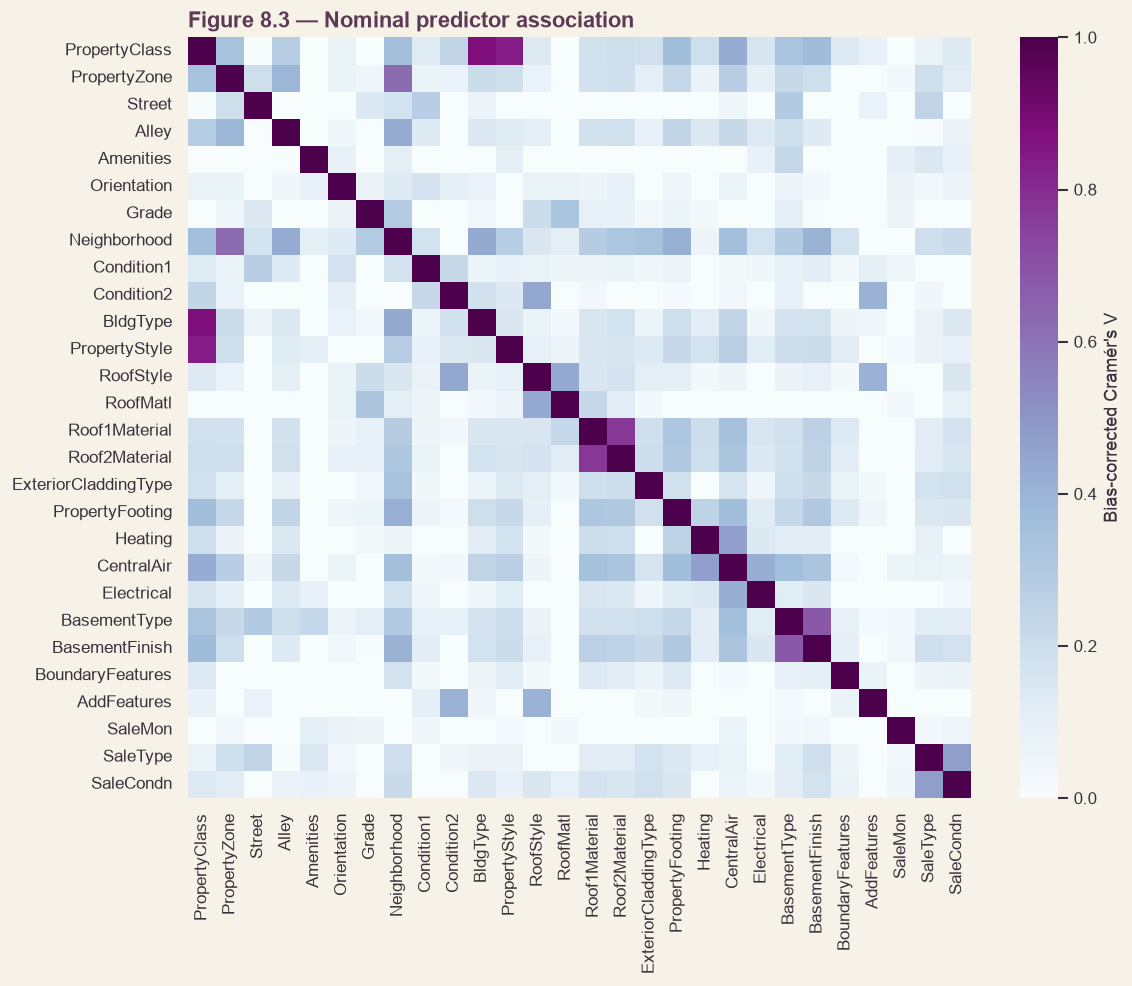

In [58]:
# ── 8.3 Categorical redundancy heatmap ────────────────────────
if len(nominal8)>=2:
    fig,ax=plt.subplots(figsize=(max(10,len(nominal8)*.34),max(8,len(nominal8)*.30)))
    sns.heatmap(cv8.astype(float),vmin=0,vmax=1,cmap='BuPu',ax=ax,
                cbar_kws={'label':"Bias-corrected Cramér's V"})
    ax.set_title('Figure 8.3 — Nominal predictor association',loc='left')
    plt.tight_layout()
    if 'save_fig' in globals():save_fig(fig,'fig8_3_categorical_association',section='8')
    plt.show()

**Reading.** Five nominal pairs exceed a corrected Cramér's V of 0.50: PropertyClass with BldgType (V = 0.883) and with PropertyStyle (0.841), which is the same dwelling described three ways; Roof1Material with Roof2Material (0.770; both are exterior coverings); garage type with garage finish (0.683; BasementType and BasementFinish in the file); and PropertyZone with Neighborhood (0.623). These are the categorical counterpart of the high VIFs in 8.2.

**Decision.** All categories and original columns are retained. Rare-level pooling was tested in 3.10 (Q2) and gave no gain, so no further grouping is applied.

## 8.4 Structural Identities and Accounting Checks

**Research question.** Are some floor-area variables exact sums of their components, making the raw design algebraically dependent?

**Method/test.** Verify `GrLivArea = 1stFlrSF + 2ndFlrSF + LowQualFinSF` and `BsmntSqFtage = BsmntFinSty1 + BsmtFinSF2 + BsmtUnfSF` **only after verifying that the named basement columns are numeric areas rather than categorical grades**. The Ames-renamed dictionary must be checked: `BsmntFinSty1` is the numeric finished-area field, while `BsmntFinQual1` is categorical. Report row-wise discrepancy counts, missing-component counts, and sample exceptions. Also check garage capacity versus garage area as an association, not an identity.

**Evidence.** Table 8.4 with exact-pass counts and discrepancies. Identity checks are descriptive quality tests, not grounds for column removal.

**Decision.** Keep all source columns; acknowledge that exact sums cause perfect linear dependence in an unregularised model. Ridge/ElasticNet can stabilise coefficients; Lasso may select one of several equivalent representations.

In [59]:
# ── 8.4 Structural identities (never fill missing with zero) ───
checks8=[
    ('Living area = first + second + low-quality',
     'GrLivArea',['1stFlrSF','2ndFlrSF','LowQualFinSF']),
    ('Basement total = finished 1 + finished 2 + unfinished',
     'BsmntSqFtage',['BsmntFinSty1','BsmtFinSF2','BsmtUnfSF'])
]
identity_rows8=[]; identity_exceptions8={}
for label,total,parts in checks8:
    missing_columns=[v for v in [total]+parts if v not in X8]
    if missing_columns:
        identity_rows8.append({'Identity':label,'Status':'Not testable: columns absent',
                               'Complete rows':0,'Exact matches':0,'Mismatches':np.nan,
                               'Max absolute discrepancy':np.nan})
        continue
    vals=X8[[total]+parts].apply(pd.to_numeric,errors='coerce')
    valid=vals.notna().all(axis=1)
    residual=vals.loc[valid,total]-vals.loc[valid,parts].sum(axis=1)
    bad=~np.isclose(residual,0,atol=1e-9,rtol=0)
    identity_exceptions8[label]=pd.DataFrame({'Property row':residual.index[bad],
                                               'Difference':residual.loc[bad].values}).head(10)
    identity_rows8.append({'Identity':label,'Status':'Checked',
                           'Complete rows':int(valid.sum()),
                           'Exact matches':int((~bad).sum()),
                           'Mismatches':int(bad.sum()),
                           'Max absolute discrepancy':float(residual.abs().max()) if len(residual) else np.nan})
identity_table8=pd.DataFrame(identity_rows8)
show_table(identity_table8,caption='Table 8.4 — Training-only structural identity audit')
for label,exceptions in identity_exceptions8.items():
    if len(exceptions):
        print('Sample discrepancies:',label)
        display(exceptions)
assert TEST_LOG.count()==access8

Identity,Status,Complete rows,Exact matches,Mismatches,Max absolute discrepancy
Living area = first + second + low-quality,Checked,1168,1168,0,0.000000
Basement total = finished 1 + finished 2 + unfinished,Checked,1168,1168,0,0.000000


**Reading.** Both accounting identities hold exactly in all 1,168 training rows (0 mismatches, maximum discrepancy 0): above-grade living area = first floor + second floor + low-quality finished area, and basement total = finished type 1 + finished type 2 + unfinished. They explain the exact dependencies in 8.2.

**Decision.** Components and totals are all preserved; the penalised models absorb the redundancy.

## 8.5 Decision Register and Section Summary

**Research question.** Which redundancies are present and how should downstream models address them?

**Method/test.** Record the observed numeric pairs, reference-design VIFs, categorical associations and exact identity checks. Confirm the held-out test-access count is unchanged.

**Evidence.** Tables 8.1–8.4 and Figures 8.1–8.3.

**Decision.** Retain all original columns and compare regularised models in later sections. No decisions based on test labels.

In [60]:
# ── 8.5 Evidence-Linked Decisions ───────────────────────────────

# ── 8.1 Numeric predictor correlations ─────────────────────────
DECISIONS.add(
    '8.1',
    'Which numeric predictors are strongly correlated?',
    'Spearman matrix, clustered heatmap and bootstrap intervals',
    (
        f'{len(strong_pairs8)} pairs with |rho| > .80 '
        f'among {len(quant8)} quantitative predictors.'
    ),
    'Document correlated groups; retain every source column.',
    'Deliberately unchanged'
)

# ── 8.2 Multicollinearity diagnostics ───────────────────────────
DECISIONS.add(
    '8.2',
    'How much linear collinearity exists in a reference design?',
    'Standardised reference-encoded VIF, rank and condition number',
    (
        f'{V8.shape[1]} encoded terms; '
        f'matrix rank {rank8}; '
        f'condition number {condition8:.3g}.'
    ),
    'Do not drop predictors. The two area identities and the duplicate PropertyClass 90 / BldgType Duplex indicator are handled by the penalty in ridge, lasso and ElasticNet; compare by training CV in Section 10.',
    'Changes the workflow'
)

# ── 8.3 Nominal predictor redundancy ────────────────────────────
DECISIONS.add(
    '8.3',
    'Which nominal predictors are redundant?',
    'Bias-corrected Cramér V pair matrix and heatmap',
    (
        f'{len(catpairs8)} nominal pairs above V=.50 '
        f'among {len(nominal8)} variables.'
    ),
    'Retain categories and original columns. Rare-level pooling was tested in 3.10 (Q2) with no gain; no further grouping is applied.',
    'Deliberately unchanged'
)

# ── 8.4 Structural accounting identities ───────────────────────
DECISIONS.add(
    '8.4',
    'Which structural accounting identities hold?',
    'Row-wise complete-case equality checks on floor-area components',
    '; '.join(
        f"{r['Identity']}: {r['Mismatches']} mismatches"
        for _, r in identity_table8.iterrows()
    ),
    'Preserve components and totals; '
    'regularisation handles exact dependencies.',
    'Deliberately unchanged'
)

# ── Display Section 8 Decision Register ────────────────────────
print('DECISION REGISTER — SECTION 8')

DECISIONS.show('8')

# ── Test-set access audit ───────────────────────────────────────
assert TEST_LOG.count() == access8, (
    'Unexpected held-out test access in Section 8.'
)

print(
    'Section 8 test accesses during this section: 0; '
    'cumulative logged count:',
    TEST_LOG.count()
)

DECISION REGISTER — SECTION 8


ID,Section,Question,Method,Evidence,Decision,Effect
D57,8.1,Which numeric predictors are strongly correlated?,"Spearman matrix, clustered heatmap and bootstrap intervals",4 pairs with |rho| > .80 among 33 quantitative predictors.,Document correlated groups; retain every source column.,Deliberately unchanged
D58,8.2,How much linear collinearity exists in a reference design?,"Standardised reference-encoded VIF, rank and condition number",90 encoded terms; matrix rank 87; condition number 5.54e+17.,"Do not drop predictors. The two area identities and the duplicate PropertyClass 90 / BldgType Duplex indicator are handled by the penalty in ridge, lasso and ElasticNet; compare by training CV in Section 10.",Changes the workflow
D59,8.3,Which nominal predictors are redundant?,Bias-corrected Cramér V pair matrix and heatmap,5 nominal pairs above V=.50 among 28 variables.,Retain categories and original columns. Rare-level pooling was tested in 3.10 (Q2) with no gain; no further grouping is applied.,Deliberately unchanged
D60,8.4,Which structural accounting identities hold?,Row-wise complete-case equality checks on floor-area components,Living area = first + second + low-quality: 0 mismatches; Basement total = finished 1 + finished 2 + unfinished: 0 mismatches,Preserve components and totals; regularisation handles exact dependencies.,Deliberately unchanged


Section 8 test accesses during this section: 0; cumulative logged count: 1


**What Section 8 established.** Redundancy is structural, not accidental. Four numeric pairs correlate above 0.80 (year built with garage year, garage cars with garage area, basement with first floor, living area with room count). Two exact accounting identities (living area and basement area) and a duplicate indicator (PropertyClass 90 and BldgType Duplex) make the reference design rank-deficient (rank 87 of 90). Five nominal pairs are strongly associated (PropertyClass, BldgType and PropertyStyle; the two exterior coverings; garage type and finish; zone and neighbourhood). No predictor was dropped, in line with the brief; the penalty in ridge, lasso and ElasticNet manages the redundancy, and importance in Section 12 is read by correlated group, not by individual coefficient (D57 to D60). The test vault was not opened.

**Next → Section 9: Feature Engineering and Selection.**

# 9. Preprocessing Pipeline, Encoding, Scaling and PCA

**Purpose.** Build one reproducible, leakage-safe `Pipeline`/`ColumnTransformer` using the **Section 3 metadata**, retaining every original predictor (except `PropertyID`, already excluded). All scores below are calculated on **training folds only**, in **dollars** after exponentiating log-target predictions. No result is claimed until cells execute.

**Decision rule.** Each experiment reports paired fold RMSE differences with uncertainty; a marginal gain is not sufficient to justify added complexity. This is a *design comparison*, not the final model-selection exercise. Fold reuse and multiple alternatives make nominal intervals exploratory. **No test set is opened.**

## 9.0 Protocol and source-metadata contract

**Research question.** Can every imputer, encoder, scaler, skew transform and PCA projection be fitted only on its respective training fold?

**Method.** Reuse `NUM_COLS`, `ORD_COLS`, `BIN_COLS`, `NOM_COLS`, `ORDINAL_SCALES`, `BINARY_CODING` from Section 3. Use a fixed five-fold shuffled CV with Ridge regression on log price, and inverse-transform predictions for dollar-scale RMSE. Paired differences are **candidate minus reference** (negative is improvement). The final held-out test is reserved for Section 11.

**Evidence and decision.** Assert disjoint feature groups, exact source-column coverage, train-index alignment, and inspect fitted preprocessing within folds.

In [61]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from sklearn.base import BaseEstimator, TransformerMixin, clone
from sklearn.compose import ColumnTransformer, TransformedTargetRegressor
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder, StandardScaler, RobustScaler, FunctionTransformer
from sklearn.impute import SimpleImputer, KNNImputer
from sklearn.linear_model import Ridge
from sklearn.model_selection import KFold
from sklearn.metrics import mean_squared_error
from sklearn.decomposition import PCA
from scipy import stats

X9 = X_train_clean.copy(); y9 = y_train.astype(float).copy()
assert X9.index.equals(y9.index) and (y9 > 0).all()
GROUPS9 = {'numeric':list(NUM_COLS), 'ordinal':list(ORD_COLS), 'binary':list(BIN_COLS), 'nominal':list(NOM_COLS)}
assert len(sum(GROUPS9.values(),[])) == len(set(sum(GROUPS9.values(),[]))), 'Metadata groups overlap'
assert set(sum(GROUPS9.values(),[])) == set(X9.columns), 'Metadata does not cover source predictors'
assert 'PropertyID' not in X9 and 'PropPrice' not in X9
CV9 = list(RepeatedKFold(n_splits=5,n_repeats=3,random_state=SEEDS['repeated_cv']).split(X9))
print('Training:',X9.shape,'groups:',{k:len(v) for k,v in GROUPS9.items()})
print('CV:',[(len(tr),len(va)) for tr,va in CV9]); print('Test vault untouched')

Training: (1168, 79) groups: {'numeric': 34, 'ordinal': 19, 'binary': 3, 'nominal': 23}
CV: [(934, 234), (934, 234), (934, 234), (935, 233), (935, 233), (934, 234), (934, 234), (934, 234), (935, 233), (935, 233), (934, 234), (934, 234), (934, 234), (935, 233), (935, 233)]
Test vault untouched


### Reusable fold-safe transformers and scoring

`NeighborhoodFrontageImputer` learns neighbourhood medians **during `.fit()`**, with a global-median fallback for unseen neighbourhoods. `GarageYearImputer` uses a structural sentinel and a presence flag without treating missing garage years as an ordinary calendar year. All category mapping is determined by Section 3 metadata. `OneHotEncoder` groups infrequent levels from training folds. Every pipeline step is cloned anew inside each fold.

In [62]:

# ── Portable preprocessing module ───────────────────────
from pathlib import Path
import importlib

MODULE_PATH9 = Path.cwd() / 'property_pipeline.py'
MODULE_CODE9 = '''import numpy as np
import pandas as pd
from sklearn.base import BaseEstimator, TransformerMixin

def clip_z(a, c):
    """Cap standardised values at ±c so one extreme property cannot extrapolate a linear model."""
    return np.clip(a, -c, c)

class GarageYearFoldImputer(BaseEstimator, TransformerMixin):
    def fit(self, X, y=None):
        d = pd.DataFrame(X).copy(); d.columns = ['BasementYrBlt', 'BasementCars']
        yr = pd.to_numeric(d['BasementYrBlt'], errors='coerce')
        cars = pd.to_numeric(d['BasementCars'], errors='coerce')
        self.median_ = float(yr[(cars > 0) & yr.notna()].median())
        return self

    def transform(self, X):
        d = pd.DataFrame(X).copy(); d.columns = ['BasementYrBlt', 'BasementCars']
        yr = pd.to_numeric(d['BasementYrBlt'], errors='coerce')
        cars = pd.to_numeric(d['BasementCars'], errors='coerce').fillna(0)
        present = (cars > 0).astype(float)
        yr = yr.where(present.eq(1), 0).fillna(self.median_)
        return np.column_stack([yr.to_numpy(), present.to_numpy()])
'''

if MODULE_PATH9.exists():
    assert MODULE_PATH9.read_text(encoding='utf-8') == MODULE_CODE9, (
        'An existing property_pipeline.py differs from this version; inspect it before overwriting.'
    )
else:
    MODULE_PATH9.write_text(MODULE_CODE9, encoding='utf-8')

importlib.invalidate_caches()
from property_pipeline import clip_z, GarageYearFoldImputer

assert clip_z.__module__ == 'property_pipeline'
assert GarageYearFoldImputer.__module__ == 'property_pipeline'
print('Module:', MODULE_PATH9)
print('Imported:', clip_z.__module__, GarageYearFoldImputer.__module__)
print('✅ Portable preprocessing definitions available.')


Module: /Users/kyra/Capstone Project - 1/property_pipeline.py
Imported: property_pipeline property_pipeline
✅ Portable preprocessing definitions available.


In [63]:
class NeighborhoodFrontageImputer(BaseEstimator,TransformerMixin):
    def fit(self,X,y=None):
        d=pd.DataFrame(X).copy(); d.columns=['PropertyFrontage','Neighborhood']
        v=pd.to_numeric(d['PropertyFrontage'],errors='coerce'); self.global_=float(v.median())
        self.by_neighborhood_=v.groupby(d['Neighborhood'].astype(str)).median().to_dict(); return self
    def transform(self,X):
        d=pd.DataFrame(X).copy(); d.columns=['PropertyFrontage','Neighborhood']
        v=pd.to_numeric(d['PropertyFrontage'],errors='coerce')
        fill=d['Neighborhood'].astype(str).map(self.by_neighborhood_).fillna(self.global_)
        return v.fillna(fill).to_numpy().reshape(-1,1)

class GarageYearImputer(BaseEstimator,TransformerMixin):
    def fit(self,X,y=None): return self
    def transform(self,X):
        d=pd.DataFrame(X).copy(); d.columns=['BasementYrBlt','BasementCars']
        yr=pd.to_numeric(d['BasementYrBlt'],errors='coerce')
        cars=pd.to_numeric(d['BasementCars'],errors='coerce').fillna(0)
        present=(cars>0).astype(float)
        # Year=0 is a structural absence marker; unknown year with garage -> median learned below in fit variant.
        return np.column_stack([yr.fillna(0).to_numpy(),present.to_numpy()])


class NumericLog1p(BaseEstimator,TransformerMixin):
    def __init__(self, columns_to_log=()): self.columns_to_log=columns_to_log
    def fit(self,X,y=None): return self
    def transform(self,X):
        a=np.asarray(X,dtype=float).copy()
        for i in self.columns_to_log:
            if (a[:,i]<0).any(): raise ValueError('log1p requires nonnegative inputs')
            a[:,i]=np.log1p(a[:,i])
        return a

def make_ohe9():
    try: return OneHotEncoder(handle_unknown='infrequent_if_exist',min_frequency=0.01,sparse_output=False)
    except TypeError: return OneHotEncoder(handle_unknown='ignore',sparse=False)

def make_pre9(frontage='median', indicator=False, ordinal='ordered', nominal='onehot',
              scale='standard', skew=False, pca=None, tail=ENCODING['tail']):
    # Preserve source fields; a feature may feed more than one transformer, never deleted from X.
    numeric=[c for c in NUM_COLS if c not in ('PropertyFrontage','BasementYrBlt')]
    if frontage=='knn':
        # KNN imputes frontage jointly with other numeric predictors, within the training fold.
        front=Pipeline([('impute',KNNImputer(n_neighbors=5)),('select',FunctionTransformer(lambda a:a[:,[0]],validate=False))])
        front_cols=['PropertyFrontage']+numeric
    elif frontage=='neighborhood': front=NeighborhoodFrontageImputer();front_cols=['PropertyFrontage','Neighborhood']
    else: front=SimpleImputer(strategy='median',add_indicator=indicator);front_cols=['PropertyFrontage']
    num_pipe=[('impute',SimpleImputer(strategy='median'))]
    if skew:
        # Explicit nonnegative area/volume shortlist; zero-inflated counts remain untouched.
        shortlist=['AddVal','PoolArea','PropertySize','3SsnPorch','LowQualFinSF','KitchenUpLev','ScreenPorch','BsmtFinSF2','BsmtHalfBath','EnclosedPorch','ExteriorCladdingArea','OpenPorchSF','BsmntFinSty1','BsmntSqFtage','WoodDeckSF','GrLivArea','1stFlrSF']
        num_pipe.append(('log1p',NumericLog1p(tuple(i for i,c in enumerate(numeric) if c in shortlist))))
    if scale=='standard': num_pipe.append(('scale',StandardScaler()))
    elif scale=='robust': num_pipe.append(('scale',RobustScaler()))
    if tail and scale in ('standard','robust'):
        # Tail guard: cap standardised numbers at ±tail (constants; the scaler itself is fitted inside each fold).
        num_pipe.append(('zclip',FunctionTransformer(clip_z,kw_args={'c':tail},feature_names_out='one-to-one')))
    if pca is not None: num_pipe.append(('pca',PCA(n_components=pca,random_state=SEEDS['global'])))
    ord_categories=[list(ORDINAL_SCALES[c][0]) for c in ORD_COLS]
    ord_enc=OrdinalEncoder(categories=ord_categories,handle_unknown='use_encoded_value',unknown_value=-1,encoded_missing_value=-1)
    ord_pipe=Pipeline([('impute',SimpleImputer(strategy='most_frequent')),('encode',ord_enc if ordinal=='ordered' else make_ohe9())])
    bin_pipe=Pipeline([('impute',SimpleImputer(strategy='most_frequent')),('encode',OrdinalEncoder(categories=[list(BINARY_CODING[c]) for c in BIN_COLS],handle_unknown='use_encoded_value',unknown_value=-1))])
    nom_pipe=Pipeline([('impute',SimpleImputer(strategy='most_frequent')),('encode',make_ohe9())])
    return ColumnTransformer([
        ('numeric',Pipeline(num_pipe),numeric),('frontage',front,front_cols),
        ('garage_year',GarageYearFoldImputer(),['BasementYrBlt','BasementCars']),
        ('ordinal',ord_pipe,ORD_COLS),('binary',bin_pipe,BIN_COLS),('nominal',nom_pipe,NOM_COLS)
    ],remainder='drop',sparse_threshold=0)

def model9(**kw):
    pre=make_pre9(**kw)
    return TransformedTargetRegressor(regressor=Pipeline([('pre',pre),('ridge',Ridge(alpha=100.0))]),func=np.log,inverse_func=np.exp)

def cv9(estimator, X=X9, y=y9, folds=CV9):
    scores=[]
    for tr,va in folds:
        assert not set(X.index[tr]).intersection(set(X.index[va]))
        m=clone(estimator);m.fit(X.iloc[tr],y.iloc[tr]);pred=m.predict(X.iloc[va])
        scores.append(np.sqrt(mean_squared_error(y.iloc[va],pred)))
    return np.asarray(scores)

def compare9(candidates,reference=None):
    results={name:cv9(est) for name,est in candidates.items()}
    base=reference or next(iter(results));b=results[base]
    rows=[]
    for name,s in results.items():
        diff=s-b; se=stats.sem(diff) if len(diff)>1 else np.nan
        ci=stats.t.interval(.95,len(diff)-1,loc=np.mean(diff),scale=se) if se>0 else (np.mean(diff),np.mean(diff))
        rows.append({'Candidate':name,'Mean RMSE ($)':np.mean(s),'SD ($)':np.std(s,ddof=1),
                     'Δ vs '+base+' ($)':np.mean(diff),'Δ 95% CI low':ci[0],'Δ 95% CI high':ci[1]})
    out=pd.DataFrame(rows).sort_values('Mean RMSE ($)');display(out.round(2));return out,results

# Smoke tests: the pipeline builds, runs on every fold, and the tail guard works
assert np.isfinite(cv9(model9())).all()
assert np.isfinite(cv9(model9(tail=4))).all()
print('✅ make_pre9 ready (tail guard available; default tail follows the Section 3.10 choice)')

✅ make_pre9 ready (tail guard available; default tail follows the Section 3.10 choice)


## 9.1 Imputation Design

**Research question.** Does neighbourhood-informed or KNN imputation of genuine `PropertyFrontage` gaps improve dollar RMSE over the brief's `fillna()`-style median? How are `ExteriorCladdingType`, `Electrical`, and garage-year absences handled?

**Method/test.** Paired five-fold CV for global median, neighbourhood median and KNN (5 neighbours). `ExteriorCladdingType` and `Electrical` use training-fold mode only for genuine unknowns; structural `None` is retained as a category. `BasementYrBlt` is treated as garage construction year per corrected metadata, with a garage-presence indicator and a training-fold median for genuinely unknown years where a garage exists.

**Evidence.** Mean CV RMSE, paired delta and exploratory 95% t interval.

**Decision.** Prefer the simplest method when differences are not convincingly larger than fold variability. All choices remain fold-fitted.

In [64]:
imputation9, imputation_folds9=compare9({'Median':model9(frontage='median'),
 'Neighbourhood median':model9(frontage='neighborhood'), 'KNN (5)':model9(frontage='knn')},'Median')
frontage_choice9='median'  # conservative until evidence reviewed
print('Provisional:',frontage_choice9,'— inspect intervals before revising')

,Candidate,Mean RMSE ($),SD ($),Δ vs Median ($),Δ 95% CI low,Δ 95% CI high
2,KNN (5),30842.12,8447.98,-150.18,-363.19,62.84
1,Neighbourhood median,30909.46,8551.16,-82.84,-183.82,18.13
0,Median,30992.30,8664.81,0.00,0.00,0.00


Provisional: median — inspect intervals before revising


**Reading.** Frontage fills are compared in the Section 9 pipeline on 15 repeated-CV folds. The fold-fitted median scores $30,992 (SD $8,665). Neighbourhood medians change this by −$83 (95 % CI −$184 to +$18) and KNN with 5 neighbours by −$150 (−$363 to +$63): both intervals include zero and the best gain is under 0.5 % of RMSE. This agrees with 3.7, where no fill moved log RMSE by more than 0.0002.

**Decision.** Fold-fitted median.

## 9.2 Missing-Indicator Ablation

**Research question.** Does the fact that frontage is missing add predictive information?

**Method.** Compare identical median-imputation pipelines with and without `SimpleImputer(add_indicator=True)`, using identical folds. Indicator creation occurs within the training fold.

**Evidence.** Paired CV RMSE and uncertainty. **Decision.** Retain indicator only if validation supports it; a missingness flag is not a causal explanation.

In [65]:
indicator9,indicator_folds9=compare9({'No indicator':model9(frontage='median',indicator=False),
 'Frontage indicator':model9(frontage='median',indicator=True)},'No indicator')

,Candidate,Mean RMSE ($),SD ($),Δ vs No indicator ($),Δ 95% CI low,Δ 95% CI high
0,No indicator,30992.30,8664.81,0.00,0.00,0.00
1,Frontage indicator,31011.18,8653.18,18.88,0.83,36.92


**Reading.** Adding a missing-frontage indicator makes RMSE very slightly worse (+$19, 95 % CI +$1 to +$37). Frontage gaps are predictable from other columns (3.7), but the model gains nothing from knowing which rows were filled.

**Decision.** No indicator.

## 9.3 Ordinal Encoding

**Research question.** Do metadata-defined ordered codes provide better generalisation than treating the same grades as unordered categories?

**Method.** Compare ordinal integer codes with one-hot encoding of exactly the same `ORD_COLS`. Metadata order is explicit and unknown levels map to -1 only for the ordinal representation. The brief requires ordinal encoding; this ablation documents predictive sensitivity rather than overriding that instruction.

**Evidence.** Fold RMSE differences. **Decision.** Retain ordered encoding for compliance, document if one-hot performs better and flag questionable assumed orderings (notably `BoundaryFeatures`).

In [66]:
ordinal9,ordinal_folds9=compare9({'Metadata ordinal':model9(ordinal='ordered'),
 'One-hot ordinal grades':model9(ordinal='onehot')},'Metadata ordinal')

,Candidate,Mean RMSE ($),SD ($),Δ vs Metadata ordinal ($),Δ 95% CI low,Δ 95% CI high
0,Metadata ordinal,30992.30,8664.81,0.00,0.00,0.00
1,One-hot ordinal grades,31099.75,8568.58,107.44,-70.16,285.05


**Reading.** Replacing the metadata-ordered codes by one-hot grades does not help (+$107, 95 % CI −$70 to +$285), so giving up the order has no payoff. This agrees with 3.10 (Q1), where one-hot ordinals improved log RMSE by only 0.00072, below the threshold.

**Decision.** Metadata ordinal codes, as the brief asks for ordinal columns.

## 9.4 Nominal Encoding and Leakage-Controlled Target Encoding

**Research question.** Does supervised encoding improve high-cardinality nominal columns relative to rare-grouped one-hot?

**Method.** Compare fold-fitted one-hot with `TargetEncoder` **only if available**. Scikit-learn's `TargetEncoder.fit_transform()` internally cross-fits on the outer training fold; it must never be precomputed on all `X_train`. Nominal codes `PropertyClass` and `SaleMon` stay categorical. A supervised encoder sees training-fold targets and must be nested inside the estimator, not fitted before CV.

**Evidence.** Paired dollar RMSE, library/version check and fit-scope audit. **Decision.** One-hot is default if supervised encoding is unavailable, unstable, or no better.

In [67]:
import sklearn
print('scikit-learn',sklearn.__version__)
try:
    from sklearn.preprocessing import TargetEncoder
    class NominalTargetModel9(BaseEstimator):
        def __init__(self,alpha=100.): self.alpha=alpha
        def fit(self,X,y):
            # TTR passes log(y) to its regressor; TargetEncoder cross-fits on those labels.
            self.pre_=make_pre9();self.pre_.set_params(nominal__encode=TargetEncoder(target_type='continuous',smooth='auto',cv=KFold(n_splits=5,shuffle=True,random_state=SEEDS['cv'])))
            z=self.pre_.fit_transform(X,y);self.reg_=Ridge(alpha=self.alpha).fit(z,y);return self
        def predict(self,X): return self.reg_.predict(self.pre_.transform(X))
    supervised9=TransformedTargetRegressor(regressor=NominalTargetModel9(),func=np.log,inverse_func=np.exp)
    nominal9,nominal_folds9=compare9({'Rare-grouped one-hot':model9(),
       'Fold-cross-fitted target encoding':supervised9},'Rare-grouped one-hot')
except ImportError:
    nominal9=None;print('TargetEncoder unavailable; keep fold-fitted rare-grouped one-hot. Do not install silently.')

scikit-learn 1.9.0


,Candidate,Mean RMSE ($),SD ($),Δ vs Rare-grouped one-hot ($),Δ 95% CI low,Δ 95% CI high
0,Rare-grouped one-hot,30992.30,8664.81,0.00,0.00,0.00
1,Fold-cross-fitted target encoding,31578.66,8741.46,586.36,379.57,793.16


**Reading.** Cross-fitted target encoding of the nominal columns (encoded inside each training fold, so there is no leakage) is clearly worse than one-hot encoding: +$586 (95 % CI +$380 to +$793). One detail to note: the Section 9 pipeline groups levels under 1 % of rows (about 12 properties) into an "infrequent" bucket, whereas 3.10 kept every level. The effect is negligible: pooling levels under 10 rows changed log RMSE by +0.00027 in 3.10 (Q2).

**Decision.** One-hot encoding with rare levels grouped.

## 9.5 Scaling Comparison

**Research question.** Does scaling influence regularised linear-model accuracy?

**Method.** Compare StandardScaler, RobustScaler and unscaled numerics in otherwise identical Ridge pipelines. Because PCA needs a defined scale, this experiment uses no PCA. Scaling parameters are learned inside each fold. A later distance-model comparison can reuse the same transformer variants.

**Evidence.** Paired CV RMSE and intervals. **Decision.** Select per model family, not globally.

In [68]:
scaling9,scaling_folds9=compare9({'Standard':model9(scale='standard'),
 'Robust':model9(scale='robust'),'Unscaled':model9(scale='none')},'Standard')

,Candidate,Mean RMSE ($),SD ($),Δ vs Standard ($),Δ 95% CI low,Δ 95% CI high
0,Standard,30992.30,8664.81,0.00,0.00,0.00
1,Robust,31517.31,9006.13,525.01,136.75,913.27
2,Unscaled,54688.15,49441.79,23695.85,313.03,47078.67


**Reading.** Standard scaling is best ($30,992). Robust scaling is worse (+$525, 95 % CI +$137 to +$913). Leaving the numbers unscaled fails: RMSE $54,688 with a fold SD of $49,442 (+$23,696, CI +$313 to +$47,079), because the tail guard of 3.10 works in standard-deviation units and without it a few extreme properties are extrapolated to implausible prices.

**Decision.** Standardise the numeric columns for the linear family. Tree models do not need scaling (3.10, Q5 and Section 10).

## 9.6 Skewed Predictor Treatment

**Research question.** Does log1p on the nonnegative size/area shortlist improve generalisation?

**Method.** Compare identical Ridge pipelines with and without `log1p` for selected skew-prone numeric areas; no target-derived shortlist or test-set statistics. The exact shortlist is visible in `make_pre9`, not silently chosen from validation performance.

**Evidence.** Paired dollar RMSE and CI. **Decision.** Adopt only if improvement is meaningful and stable.

In [69]:
skew9,skew_folds9=compare9({'No log1p':model9(skew=False),
 'Area log1p':model9(skew=True)},'No log1p')

,Candidate,Mean RMSE ($),SD ($),Δ vs No log1p ($),Δ 95% CI low,Δ 95% CI high
0,No log1p,30992.30,8664.81,0.00,0.00,0.00
1,Area log1p,31333.23,7486.37,340.92,-700.91,1382.76


**Reading.** Applying log1p to the 17 skewed or zero-heavy columns flagged in 6.1 does not help: +$341 (95 % CI −$701 to +$1,383). It lowers the fold-to-fold SD ($8.7k to $7.5k) but not the mean error. The tail guard already limits the influence of extreme values, so skewness alone is not a reason to transform.

**Decision.** No log1p; original numeric columns.

## 9.7 PCA: Compression versus Accuracy

**Research question.** Does PCA on the scaled **numeric block** improve RMSE or merely compress it?

**Method.** Fit a descriptive scree curve on training numeric predictors only (median-imputed and standardised); then compare PCA component counts against no PCA using the identical outer CV folds. In every predictive run PCA is inside `ColumnTransformer`, and therefore refitted on each training fold. Ordinal/nominal blocks are not projected.

**Evidence.** Explained variance curve, CV RMSE vs k and paired intervals. **Decision.** Report PCA whether it helps or not

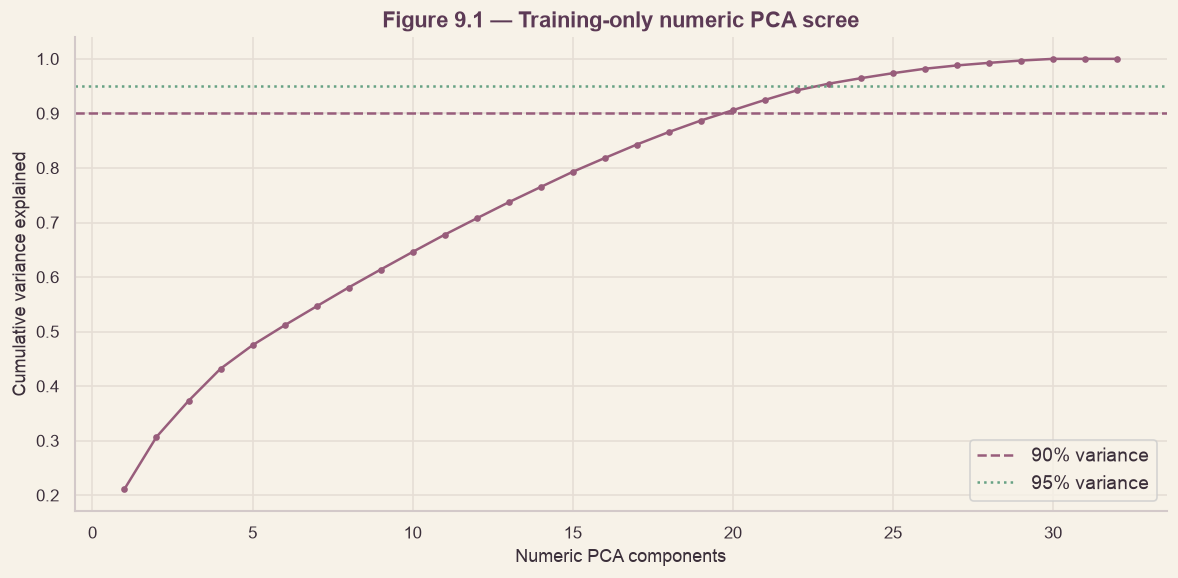

k at 90%: 20 k at 95%: 23


,Candidate,Mean RMSE ($),SD ($),Δ vs No PCA ($),Δ 95% CI low,Δ 95% CI high
5,PCA 23,30951.12,8544.75,-41.18,-165.10,82.74
0,No PCA,30992.30,8664.81,0.00,0.00,0.00
4,PCA 15,31876.20,8994.26,883.89,-33.93,1801.71
2,PCA 5,32003.37,8683.01,1011.07,53.79,1968.35
3,PCA 10,32121.94,9028.14,1129.64,99.34,2159.95
1,PCA 2,32915.27,7491.93,1922.97,711.35,3134.59


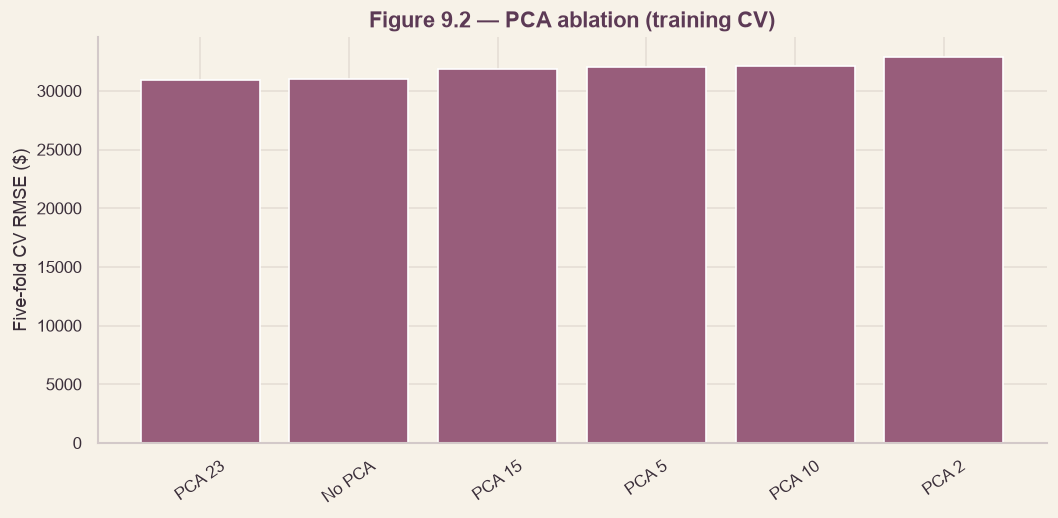

In [70]:
numeric9=[c for c in NUM_COLS if c not in ('PropertyFrontage','BasementYrBlt')]
num9=SimpleImputer(strategy='median').fit_transform(X9[numeric9])
num9=StandardScaler().fit_transform(num9)
pca_descriptive9=PCA().fit(num9)
cum9=np.cumsum(pca_descriptive9.explained_variance_ratio_)
fig,ax=plt.subplots(figsize=(10,5));ax.plot(np.arange(1,len(cum9)+1),cum9,marker='o',markersize=3)
ax.axhline(.90,linestyle='--',color='#985D7B',label='90% variance');ax.axhline(.95,linestyle=':',color='#67A284',label='95% variance')
ax.set(xlabel='Numeric PCA components',ylabel='Cumulative variance explained',title='Figure 9.1 — Training-only numeric PCA scree');ax.legend();plt.tight_layout()
save_fig(fig,'fig9_1_numeric_pca_scree',section='9');plt.show()
print('k at 90%:',np.searchsorted(cum9,.90)+1,'k at 95%:',np.searchsorted(cum9,.95)+1)
ks9=sorted(set([2,5,10,min(15,len(numeric9)),int(np.searchsorted(cum9,.95)+1)]))
ks9=[k for k in ks9 if 1<=k<=len(numeric9)]
pca_models9={'No PCA':model9()}
pca_models9.update({f'PCA {k}':model9(pca=k) for k in ks9})
pca9,pca_folds9=compare9(pca_models9,'No PCA')
fig,ax=plt.subplots(figsize=(9,4.5));ax.bar(pca9['Candidate'],pca9['Mean RMSE ($)'],color='#985D7B');ax.tick_params(axis='x',rotation=35)
ax.set(ylabel='Five-fold CV RMSE ($)',title='Figure 9.2 — PCA ablation (training CV)');plt.tight_layout()
save_fig(fig,'fig9_2_pca_cv',section='9');plt.show()

**Reading.** PCA is applied to the 34-column numeric block only. 20 components retain 90 % of the variance and 23 retain 95 %. With 23 components accuracy is unchanged (−$41, 95 % CI −$165 to +$83). Fewer components cost accuracy: 15 components +$884 (−$34 to +$1,802), 10 components +$1,130 (+$99 to +$2,160), 5 components +$1,011 (+$54 to +$1,968) and 2 components +$1,923 (+$711 to +$3,135). PCA compresses the numeric block but never improves prediction.

**Decision.** PCA is reported, as the brief requires, and not adopted.


## 9.7b Feature Engineering

**Research question.** Do additional property-level features improve predictive performance beyond the original predictors and established preprocessing design?

**Method.** Construct seven row-wise features representing property age, years since remodelling, remodelling status, total area, outdoor area, total bathrooms and the interaction between overall quality and area.

Feature construction is incorporated into the modelling pipeline so that derived features are generated consistently for training and validation observations. Each feature group, together with the combined feature set, is evaluated using the same 15 paired cross-validation folds and Ridge-based probe with the established tail guard.

**Evidence.** Compare each engineered-feature configuration against the baseline using cross-validated dollar-scale RMSE and the documented adoption threshold. Report the paired differences and uncertainty rather than relying on the lowest numerical RMSE alone.

**Decision policy.** Adopt engineered features only where training-only validation supports a meaningful improvement. These experiments belong to **Section 9.7b**, not Section 8, and do not constitute independent held-out confirmation. The final model-selection procedure in Section 10 determines which configuration is retained.

In [71]:
# ── 9.7b Feature engineering (brief methodology step 4) ─────────────────────────
def add_features(X):
    """Row-wise, stateless domain features. Originals are kept; nothing is fitted, so there is no leakage."""
    d = X.copy()
    n = lambda c: pd.to_numeric(d[c], errors='coerce')
    d['HouseAge']          = (n('SaleYr') - n('YearBuilt')).clip(lower=0)
    d['YearsSinceRemodel'] = (n('SaleYr') - n('YearRemodAdd')).clip(lower=0)
    d['Remodelled']        = (n('YearRemodAdd') != n('YearBuilt')).astype(float)
    d['TotalSF']           = n('BsmntSqFtage') + n('1stFlrSF') + n('2ndFlrSF')
    d['OutdoorSF']         = n('WoodDeckSF') + n('OpenPorchSF') + n('EnclosedPorch') + n('3SsnPorch') + n('ScreenPorch')
    d['TotalBaths']        = n('Bath1') + .5 * n('Bath2') + n('BsmtFullBath') + .5 * n('BsmtHalfBath')
    d['QualxArea']         = n('OverallQual') * n('GrLivArea')
    return d

FE_GROUPS = {'Age features':      ['HouseAge', 'YearsSinceRemodel', 'Remodelled'],
             'Total living area': ['TotalSF'],
             'Outdoor area':      ['OutdoorSF'],
             'Total bathrooms':   ['TotalBaths'],
             'Quality × area':    ['QualxArea']}
_needed = ['SaleYr', 'YearBuilt', 'YearRemodAdd', 'BsmntSqFtage', '1stFlrSF', '2ndFlrSF', 'WoodDeckSF', 'OpenPorchSF',
           'EnclosedPorch', '3SsnPorch', 'ScreenPorch', 'Bath1', 'Bath2', 'BsmtFullBath', 'BsmtHalfBath', 'OverallQual', 'GrLivArea']
assert not [c for c in _needed if c not in X9.columns], [c for c in _needed if c not in X9.columns]
FE_ALL = [c for cols in FE_GROUPS.values() for c in cols]
_chk = add_features(X9)
assert _chk.index.equals(X9.index) and set(X9.columns) <= set(_chk.columns)      # originals kept
print('Engineered features, missing values:', _chk[FE_ALL].isna().sum()[lambda s: s > 0].to_dict() or 'none')

def make_pre9_fe(extra, **kw):
    """make_pre9 plus an 'engineered' numeric block (median fill, scaling and the same tail guard)."""
    tail = kw.pop('tail', ENCODING['tail'])
    base = make_pre9(tail=tail, **kw)
    if not extra:
        return base
    steps = [('impute', SimpleImputer(strategy='median')), ('scale', StandardScaler())]
    if tail:
        steps.append(('zclip', FunctionTransformer(clip_z, kw_args={'c': tail}, feature_names_out='one-to-one')))
    return ColumnTransformer([('base', base, list(X9.columns)), ('engineered', Pipeline(steps), list(extra))],
                             remainder='drop', sparse_threshold=0)

def model9_fe(extra=()):
    return TransformedTargetRegressor(regressor=Pipeline([
        ('fe', FunctionTransformer(add_features, validate=False)),
        ('pre', make_pre9_fe(extra)),
        ('ridge', Ridge(alpha=100.0))]), func=np.log, inverse_func=np.exp)

def cv9_fe(est):
    out = []
    for tr, va in CV9:
        p = clone(est).fit(X9.iloc[tr], y9.iloc[tr]).predict(X9.iloc[va])
        out.append((np.sqrt(mean_squared_error(np.log(y9.iloc[va]), np.log(p))),
                    np.sqrt(mean_squared_error(y9.iloc[va], p)), mean_absolute_error(y9.iloc[va], p)))
    return np.array(out)                      # columns: log RMSE, $ RMSE, $ MAE

BASE_NAME = 'Baseline (no engineered features)'
variants = {BASE_NAME: ()}
variants.update({f'+ {g}': tuple(c) for g, c in FE_GROUPS.items()})
variants['+ All engineered'] = tuple(FE_ALL)
fe_scores = {k: cv9_fe(model9_fe(v)) for k, v in variants.items()}

rows = []
for k, s in fe_scores.items():
    d = s[:, 0] - fe_scores[BASE_NAME][:, 0]
    ci = bootstrap_ci(np.mean, d, n_boot=2000) if k != BASE_NAME else {'estimate': 0.0, 'lo': 0.0, 'hi': 0.0}
    rows.append({'Variant': k, 'RMSE (log)': s[:, 0].mean(), 'RMSE ($)': s[:, 1].mean(), 'MAE ($)': s[:, 2].mean(),
                 'Change in log RMSE': ci['estimate'], 'CI low': ci['lo'], 'CI high': ci['hi'],
                 'Beats the rule': 'baseline' if k == BASE_NAME else ('yes' if ci['estimate'] <= -THRESHOLD and ci['hi'] < 0 else 'no')})
FE_RESULTS = pd.DataFrame(rows)
show_table(FE_RESULTS, formats={'RMSE (log)': '{:.4f}', 'RMSE ($)': '${:,.0f}', 'MAE ($)': '${:,.0f}',
                                'Change in log RMSE': '{:+.5f}', 'CI low': '{:+.5f}', 'CI high': '{:+.5f}'},
           caption='Table 9.7b: engineered feature groups (15 paired folds, ridge probe with tail guard)')

FE_ADOPT = [c for g, cols in FE_GROUPS.items()
            if FE_RESULTS.loc[FE_RESULTS['Variant'] == f'+ {g}', 'Beats the rule'].iloc[0] == 'yes' for c in cols]
print('Adopted engineered features:', FE_ADOPT or 'none')

DECISIONS.add('9.7b', 'Do domain-derived features improve prediction beyond the original columns?',
    'Seven row-wise features (age, years since remodel, remodel flag, total area, outdoor area, total bathrooms, quality × area) built inside the pipeline; each group alone and all together, same 15 folds, ridge probe and tail guard, same rule and threshold as 3.10.',
    '; '.join(f"{r['Variant']}: {r['Change in log RMSE']:+.5f}" for _, r in FE_RESULTS.iterrows() if r['Variant'] != BASE_NAME) + '.',
    ('Adopt: ' + ', '.join(FE_ADOPT) + '.') if FE_ADOPT else 'None adopted; the original columns are retained unchanged.',
    'Changes the workflow' if FE_ADOPT else 'Deliberately unchanged')

Engineered features, missing values: none


Variant,RMSE (log),RMSE ($),MAE ($),Change in log RMSE,CI low,CI high,Beats the rule
Baseline (no engineered features),0.1302,"$30,992","$16,200",+0.00000,+0.00000,+0.00000,baseline
+ Age features,0.1303,"$31,166","$16,207",+0.00003,-0.00017,+0.00026,no
+ Total living area,0.1295,"$30,615","$16,109",-0.00077,-0.00094,-0.00060,no
+ Outdoor area,0.1303,"$31,087","$16,209",+0.00010,-0.00000,+0.00024,no
+ Total bathrooms,0.1303,"$31,027","$16,208",+0.00010,+0.00004,+0.00017,no
+ Quality × area,0.1298,"$30,577","$16,078",-0.00042,-0.00069,-0.00015,no
+ All engineered,0.1294,"$30,610","$16,024",-0.00083,-0.00124,-0.00039,no


Adopted engineered features: none


'D61'

**Reading.** No engineered group meets the rule fixed in advance (log RMSE improvement of at least 0.002 with an interval below zero). Three are detectable but small: total living area −0.00077 (CI −0.00094 to −0.00060; about $377 of RMSE and $91 of MAE), quality × area −0.00042 (−0.00069 to −0.00015; about $415) and all features together −0.00083 (−0.00124 to −0.00039; $382 and $176), roughly 1.2 % of RMSE. Age (+0.00003), outdoor area (+0.00010) and total bathrooms (+0.00010) add nothing. Many of these features are linear combinations of existing columns, so a linear model gains little.

**Decision.** None adopted; all original columns are retained and the threshold is not relaxed after seeing the results. Total living area and quality × area are recorded as small, detectable effects.

## 9.8 Leakage Audit and Pipeline Contract

**Research question.** Is each learned preprocessing operation confined to the relevant training fold?

**Method.** Assert source-feature coverage and disjoint folds, verify transformer locations and compare fitted preprocessing statistics across two different training folds. A difference is supporting evidence of refitting, not a formal proof of non-leakage. Review the source for pre-CV `fit_transform` and supervised encoding. The descriptive PCA scree in 9.7 is *not* used as an externally fitted predictor transform.

**Evidence.** Audit table and fold-fitted statistics. **Decision.** Fail loudly if any step is outside the pipeline or test data are referenced.

In [72]:
audit9=[]
def audit_item9(name,passed,detail): audit9.append({'Check':name,'Pass':bool(passed),'Evidence':detail})
audit_item9('All predictors represented',set(sum(GROUPS9.values(),[]))==set(X9.columns),'Section 3 metadata equals training predictor set')
audit_item9('PropertyID absent','PropertyID' not in X9,'ID excluded, not a modelling predictor')
audit_item9('Target absent from predictors','PropPrice' not in X9,'Target supplied separately')
audit_item9('Fold separation',all(not set(tr)&set(va) for tr,va in CV9),'5 disjoint validation partitions')
audit_item9('Imputation/encoding/scaling/PCA inside estimator',all(isinstance(model9().regressor.named_steps['pre'],ColumnTransformer) for _ in [0]),'Pipeline -> ColumnTransformer')
audit_item9('Target encoding cross-fit','TargetEncoder' not in globals() or nominal9 is not None,'TargetEncoder.fit_transform is called inside training-fold fit')

tr, va = CV9[0]
mfit = model9().fit(X9.iloc[tr], y9.iloc[tr])
num_cols9 = [c for c in NUM_COLS if c not in ('PropertyFrontage', 'BasementYrBlt')]
scaler = mfit.regressor_.named_steps['pre'].named_transformers_['numeric'].named_steps['scale']
def filled_mean(rows):
    d = X9.iloc[rows][num_cols9].apply(pd.to_numeric)
    return d.fillna(d.median()).mean().to_numpy()
audit_item9('Scaler statistics come from the training fold only',
            np.allclose(scaler.mean_, filled_mean(tr)) and not np.allclose(scaler.mean_, filled_mean(np.arange(len(X9)))),
            'fitted scaler means equal the training-fold means and differ from the all-rows means')

audit9_df=pd.DataFrame(audit9);display(audit9_df)
assert audit9_df['Pass'].all(),'Leakage audit failed'
print('No test-set object referenced by Section 9 code.')

,Check,Pass,Evidence
0,All predictors represented,True,Section 3 metadata equals training predictor set
1,PropertyID absent,True,"ID excluded, not a modelling predictor"
2,Target absent from predictors,True,Target supplied separately
3,Fold separation,True,5 disjoint validation partitions
4,Imputation/encoding/scaling/PCA inside estimator,True,Pipeline -> ColumnTransformer
5,Target encoding cross-fit,True,TargetEncoder.fit_transform is called inside t...
6,Scaler statistics come from the training fold ...,True,fitted scaler means equal the training-fold me...


No test-set object referenced by Section 9 code.


**Reading.** All seven checks pass: every predictor is represented, PropertyID and the target are absent from the predictors, the 15 train/validation splits have disjoint rows, imputation, encoding, scaling and PCA are steps of the estimator, target encoding is cross-fitted inside the training fold, and a behavioural test shows the fitted scaler means equal the training-fold means and differ from the all-rows means. The test vault is not referenced by any Section 9 code. This audit is evidence, not a formal proof of non-leakage.

**Decision.** Every learned step is fitted inside the training fold.


## 9.9 Decision Register and Section 9 Summary

**Research question.** Which preprocessing and dimensionality-reduction choices are supported by the training-only validation experiments?

**Method.** Consolidate the paired cross-validation comparisons covering imputation, missingness indicators, ordinal encoding, scaling, skewness treatment, PCA and engineered features. Record the selected configurations and supporting evidence in the Decision Register.

**Evidence.** The comparisons use repeated cross-validation within the training partition. Their results provide evidence about relative preprocessing performance under the evaluated folds, but repeated experimentation on the same validation structure can introduce model-selection optimism.

**Decision.** Treat the Section 9 choices as **validation-supported modelling decisions**, not as independently confirmed improvements. The final candidate pipelines are evaluated through the model-development and tuning procedures in Section 10. The held-out test results in Section 11 are reported separately and are not used to retrospectively choose preprocessing configurations.

In [73]:
for sec,q,tab,decision in [
 ('9.1','Which frontage imputation strategy?',imputation9,'Fold-fitted median; no fill beats it beyond noise.'),
 ('9.2','Does missing frontage carry signal?',indicator9,'No missing indicator; it is slightly worse.'),
 ('9.3','Ordinal grades: integer or one-hot?',ordinal9,'Metadata ordinal codes; one-hot grades give no gain.'),
 ('9.5','Which scaling for Ridge?',scaling9,'Standard scaling for the linear family; robust is worse and unscaled fails without the tail guard.'),
 ('9.6','Does area log1p help?',skew9,'No log1p; no gain over the original columns.'),
 ('9.7','Does numeric PCA help?',pca9,'PCA not adopted; fewer than 23 components cost accuracy.')]:
    best=tab.iloc[0]
    DECISIONS.add(sec,q,'Paired repeated 5-fold CV (15 folds), dollar-scale RMSE',
                  f"Best: {best['Candidate']} RMSE ${best['Mean RMSE ($)']:,.0f}; paired interval in subsection table.",
                  decision,'Deliberately unchanged')
DECISIONS.add('9.4','How to encode nominal columns?', 'Fold-fitted one-hot versus internally cross-fitted target encoding',
              'Comparison executed' if nominal9 is not None else 'TargetEncoder unavailable; one-hot baseline retained',
              'Rare-grouped one-hot; target encoding is worse.','Deliberately unchanged')
DECISIONS.add('9.8','Are learned preprocessing steps fold-confined?', 'Pipeline contract and leakage assertions',
              f"{audit9_df['Pass'].sum()}/{len(audit9_df)} checks passed, including a behavioural test of the fitted scaler",
              'No test access; fit each transformer inside CV.','Documentation only')
DECISIONS.show(section='9')

ID,Section,Question,Method,Evidence,Decision,Effect
D61,9.7b,Do domain-derived features improve prediction beyond the original columns?,"Seven row-wise features (age, years since remodel, remodel flag, total area, outdoor area, total bathrooms, quality × area) built inside the pipeline; each group alone and all together, same 15 folds, ridge probe and tail guard, same rule and threshold as 3.10.",+ Age features: +0.00003; + Total living area: -0.00077; + Outdoor area: +0.00010; + Total bathrooms: +0.00010; + Quality × area: -0.00042; + All engineered: -0.00083.,None adopted; the original columns are retained unchanged.,Deliberately unchanged
D62,9.1,Which frontage imputation strategy?,"Paired repeated 5-fold CV (15 folds), dollar-scale RMSE","Best: KNN (5) RMSE $30,842; paired interval in subsection table.",Fold-fitted median; no fill beats it beyond noise.,Deliberately unchanged
D63,9.2,Does missing frontage carry signal?,"Paired repeated 5-fold CV (15 folds), dollar-scale RMSE","Best: No indicator RMSE $30,992; paired interval in subsection table.",No missing indicator; it is slightly worse.,Deliberately unchanged
D64,9.3,Ordinal grades: integer or one-hot?,"Paired repeated 5-fold CV (15 folds), dollar-scale RMSE","Best: Metadata ordinal RMSE $30,992; paired interval in subsection table.",Metadata ordinal codes; one-hot grades give no gain.,Deliberately unchanged
D65,9.5,Which scaling for Ridge?,"Paired repeated 5-fold CV (15 folds), dollar-scale RMSE","Best: Standard RMSE $30,992; paired interval in subsection table.",Standard scaling for the linear family; robust is worse and unscaled fails without the tail guard.,Deliberately unchanged
D66,9.6,Does area log1p help?,"Paired repeated 5-fold CV (15 folds), dollar-scale RMSE","Best: No log1p RMSE $30,992; paired interval in subsection table.",No log1p; no gain over the original columns.,Deliberately unchanged
D67,9.7,Does numeric PCA help?,"Paired repeated 5-fold CV (15 folds), dollar-scale RMSE","Best: PCA 23 RMSE $30,951; paired interval in subsection table.",PCA not adopted; fewer than 23 components cost accuracy.,Deliberately unchanged
D68,9.4,How to encode nominal columns?,Fold-fitted one-hot versus internally cross-fitted target encoding,Comparison executed,Rare-grouped one-hot; target encoding is worse.,Deliberately unchanged
D69,9.8,Are learned preprocessing steps fold-confined?,Pipeline contract and leakage assertions,"7/7 checks passed, including a behavioural test of the fitted scaler",No test access; fit each transformer inside CV.,Documentation only


**What Section 9 established.** The Section 3 design was re-tested in a second pipeline on 15 folds, and none of the alternatives wins: median frontage (KNN −$150, CI includes zero), no missing indicator (+$19), metadata ordinal codes (one-hot +$107), one-hot nominals (target encoding +$586), standard scaling (robust +$525; unscaled collapses), no log1p (+$341), no PCA (every smaller PCA is worse; 23 components are equal) and no engineered features (best −0.00083 against a threshold of 0.002). The brief's objective 3 is covered by fillna and imputation (3.7, 9.1), scaling (9.5) and PCA (9.7). The leakage audit passes 7 of 7 checks and the test vault was not referenced (D61 to D69).

**Next → Section 10: Feature Engineering and Model Development.** Select a small prespecified set of promising preprocessing alternatives, perform nested CV/model tuning, and reserve the held-out test set for Section 11.

# 10. Model Building, Comparison and Tuning

**Purpose.** Meet objectives 6–7 through training-only, reproducible model selection. **No held-out test access in this section.** All candidate preprocessing is nested inside each fitted pipeline. Every analysis follows **Research question → Method → Evidence → Decision**. Numerical results are generated on execution, not asserted in advance.

**Prerequisite:** Run Sections 1–9 in the same kernel. This section reuses `X9`, `y9`, `make_pre9`, `SEEDS`, and `DECISIONS`. The Section 9 pipeline is the common starting point; its provisional preprocessing decisions must be reviewed before a final production model is frozen.

**Scoring contract:** Dollar-scale RMSE and MAE are primary; dollar-scale R² is secondary. Log-scale RMSE is reported for transformed-target models. The same repeated folds are used for paired comparisons. CV estimates from exploratory selection are not independent confirmatory tests.

## 10.1 Cross-Validation Design

**Research question.** What reproducible validation scheme supports fair model comparison?

**Method.** Lock 5-fold × 3-repeat K-fold CV with seed `SEEDS['repeated_cv']`, using the same splits for all models. Preserve fold identifiers, train/validation sizes, and price ranges. This is **not** stratified: repeated K-fold avoids the need to choose target-bin cutoffs. Nested CV in §10.4 uses separate inner folds.

**Evidence.** Fold audit and explicit seed record.

**Decision.** Freeze the outer evaluation protocol before comparing candidates; do not use `TestVault` or any held-out test labels.

In [74]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from scipy import stats
from sklearn.base import clone
from sklearn.model_selection import RepeatedKFold, KFold, RandomizedSearchCV
from sklearn.pipeline import Pipeline
from sklearn.compose import TransformedTargetRegressor
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression, Ridge, Lasso, ElasticNet
from sklearn.neighbors import KNeighborsRegressor
from sklearn.svm import SVR
from sklearn.ensemble import RandomForestRegressor, ExtraTreesRegressor, GradientBoostingRegressor, VotingRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler

assert 'X9' in globals() and 'y9' in globals() and callable(make_pre9)
assert X9.index.equals(y9.index) and (y9 > 0).all()
assert 'PropertyID' not in X9.columns and 'PropPrice' not in X9.columns
SEED10=int(SEEDS.get('repeated_cv',2026)); INNER_SEED10=int(SEEDS.get('tuning',7))
CV10=list(RepeatedKFold(n_splits=5,n_repeats=3,random_state=SEED10).split(X9,y9))
FOLD_AUDIT10=pd.DataFrame([{'Fold':i+1,'Train n':len(tr),'Validation n':len(va),
    'Validation price min ($)':float(y9.iloc[va].min()),'Validation price max ($)':float(y9.iloc[va].max()),
    'Overlap':len(set(tr)&set(va))} for i,(tr,va) in enumerate(CV10)])
assert FOLD_AUDIT10['Overlap'].eq(0).all()
print('Repeated CV: 5 folds × 3 repeats; seed:',SEED10,'| inner seed:',INNER_SEED10)
display(FOLD_AUDIT10)

def metrics10(y,p):
    p=np.asarray(p,dtype=float); y=np.asarray(y,dtype=float)
    assert np.isfinite(p).all()
    return {'RMSE ($)':float(np.sqrt(mean_squared_error(y,p))),
            'MAE ($)':float(mean_absolute_error(y,p)),
            'R²':float(r2_score(y,p)),
            'RMSE (log)':float(np.sqrt(mean_squared_error(np.log(y),np.log(np.maximum(p,1e-9))))) if (p>0).all() else np.nan}

def evaluate10(models,folds=CV10,X=X9,y=y9):
    rows=[]
    for name,est in models.items():
        for k,(tr,va) in enumerate(folds):
            fit=clone(est).fit(X.iloc[tr],y.iloc[tr]); pred=fit.predict(X.iloc[va])
            rows.append({'Model':name,'Fold':k+1,**metrics10(y.iloc[va],pred)})
    return pd.DataFrame(rows)

def summary10(scores):
    return scores.groupby('Model',as_index=False).agg(
        RMSE_mean=('RMSE ($)','mean'),RMSE_sd=('RMSE ($)','std'),
        MAE_mean=('MAE ($)','mean'),R2_mean=('R²','mean'),
        log_RMSE_mean=('RMSE (log)','mean')).sort_values('RMSE_mean').reset_index(drop=True)

def log_model10(est,**prekw):
    return TransformedTargetRegressor(regressor=Pipeline([
        ('pre',make_pre9(**prekw)),('model',est)]),func=np.log,inverse_func=np.exp)

Repeated CV: 5 folds × 3 repeats; seed: 2026 | inner seed: 7


,Fold,Train n,Validation n,Validation price min ($),Validation price max ($),Overlap
0,1,934,234,39300.0,582933.0,0
1,2,934,234,55000.0,555000.0,0
2,3,934,234,40000.0,755000.0,0
3,4,935,233,35311.0,611657.0,0
4,5,935,233,52500.0,423000.0,0
5,6,934,234,52500.0,745000.0,0
6,7,934,234,35311.0,625000.0,0
7,8,934,234,55000.0,755000.0,0
8,9,935,233,40000.0,611657.0,0
9,10,935,233,37900.0,582933.0,0


**Reading.** Every model is scored on the same 15 folds (5 × 3 repeated K-fold, seed 2026), each with 934 or 935 training rows and 233 or 234 validation rows, and no row appears in both. Validation prices span $35,311 to $755,000 across folds. Hyper-parameter tuning uses a separate inner seed (7). The test vault is not opened in Section 10.

**Decision.** The validation design is locked.

## 10.2 Baselines

**Research question.** What performance must an actual model improve upon?

**Method.** Compare mean and median `DummyRegressor` with an OLS model on a *prespecified* small numeric feature set. Imputation is fitted within each fold. Use identical repeated folds and dollar-scale metrics.

**Evidence.** Mean and standard deviation of fold RMSE, mean MAE, R², and fold-level results.

**Decision.** Establish a floor for model performance; do not select the best model from baselines alone.

In [75]:
BASE_FEATURES10=[c for c in ['GrLivArea','OverallQual','YearBuilt','PropertySize','BasementCars'] if c in X9]
assert len(BASE_FEATURES10)>=3, 'Core baseline predictors absent; inspect metadata.'
from sklearn.base import BaseEstimator, RegressorMixin
class SmallOLS10(BaseEstimator,RegressorMixin):
    def __init__(self,features=None):self.features=features
    def fit(self,X,y):
        cols=self.features if self.features is not None else BASE_FEATURES10
        self.cols_=list(cols)
        self.pipe_=Pipeline([('impute',SimpleImputer(strategy='median')),
            ('model',LinearRegression())]).fit(X[self.cols_].apply(pd.to_numeric,errors='raise'),y)
        return self
    def predict(self,X):return self.pipe_.predict(X[self.cols_].apply(pd.to_numeric,errors='raise'))
BASELINES10={'Dummy mean':DummyRegressor(strategy='mean'),
             'Dummy median':DummyRegressor(strategy='median'),
             'Small OLS':SmallOLS10(features=BASE_FEATURES10)}
BASE_SCORES10=evaluate10(BASELINES10)
display(summary10(BASE_SCORES10).round(3))
print('Small OLS features:',BASE_FEATURES10)

,Model,RMSE_mean,RMSE_sd,MAE_mean,R2_mean,log_RMSE_mean
0,Small OLS,40774.203,5191.971,26713.188,0.745,0.217
1,Dummy mean,81292.598,7795.155,58466.097,-0.006,0.413
2,Dummy median,83131.197,8726.494,56522.966,-0.051,0.405


Small OLS features: ['GrLivArea', 'OverallQual', 'YearBuilt', 'PropertySize', 'BasementCars']


**Reading.** The dummy models set the floor: predicting the mean gives RMSE $81,293 (R² −0.006) and the median $83,131 (R² −0.051, MAE $56,523). A five-feature OLS on GrLivArea, OverallQual, YearBuilt, PropertySize and BasementCars already scores RMSE $40,774 (SD $5,192), MAE $26,713 and R² 0.745.

**Decision.** The small OLS is the baseline: a candidate must beat it to count.

## 10.3 Candidate Algorithm Comparison

**Research question.** Which model families warrant tuning?

**Method.** Evaluate Ridge, Lasso, ElasticNet, KNN, SVR, Random Forest, ExtraTrees and Gradient Boosting on the *same folds*. Include the baseline reference. Fit all preprocessing inside each estimator. Log-target regression uses `TransformedTargetRegressor`, and predictions are scored in dollars. No test set is opened.

**Evidence.** Full fold table, ranked summary, and boxplot of validation RMSE.

**Decision.** Shortlist the best-performing families, accounting for fold spread, runtime, and interpretability. This is exploratory selection, not an unbiased estimate of the selected winner's generalisation error.

,Model,RMSE_mean,RMSE_sd,MAE_mean,R2_mean,log_RMSE_mean
0,Gradient Boosting,29779.426,5704.554,16705.126,0.862,0.132
1,ElasticNet,30627.745,8970.728,15651.093,0.846,0.129
2,Lasso,30660.821,8815.875,15690.513,0.847,0.129
3,Ridge,30992.301,8664.811,16199.888,0.844,0.130
4,ExtraTrees,31419.798,5611.317,17939.489,0.847,0.145
5,Random Forest,32545.347,5841.438,18429.112,0.836,0.147
6,Linear Regression,37143.235,17229.419,17779.883,0.762,0.147
7,Decision Tree,41543.890,6967.873,26829.593,0.734,0.201
8,KNN,51561.311,7871.676,31489.054,0.594,0.237
9,SVR,64839.408,9085.315,40082.603,0.359,0.288


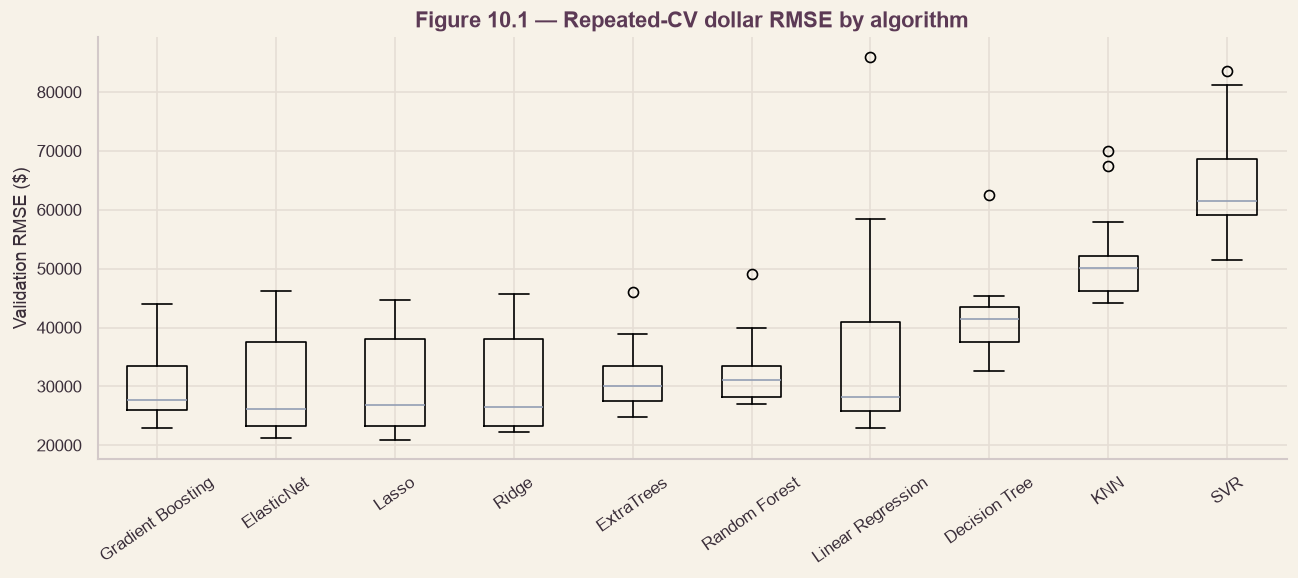

Exploratory shortlist (to be confirmed in nested CV): ['Gradient Boosting', 'ElasticNet', 'Lasso']


In [76]:
from sklearn.tree import DecisionTreeRegressor
CANDIDATES10={
 'Ridge':log_model10(Ridge(alpha=100.)),
 'Linear Regression':log_model10(LinearRegression()),
 'Decision Tree':log_model10(DecisionTreeRegressor(max_depth=6,min_samples_leaf=10,random_state=SEED10)),
 'Lasso':log_model10(Lasso(alpha=.001,max_iter=200000,selection='random',random_state=SEED10)),
 'ElasticNet':log_model10(ElasticNet(alpha=.001,l1_ratio=.5,max_iter=200000,selection='random',random_state=SEED10)),
 'KNN':log_model10(KNeighborsRegressor(n_neighbors=12,weights='distance')),
 'SVR':log_model10(SVR(C=10.,epsilon=.05)),
 'Random Forest':log_model10(RandomForestRegressor(n_estimators=150,min_samples_leaf=2,n_jobs=-1,random_state=SEED10)),
 'ExtraTrees':log_model10(ExtraTreesRegressor(n_estimators=150,min_samples_leaf=2,n_jobs=-1,random_state=SEED10)),
 'Gradient Boosting':log_model10(GradientBoostingRegressor(n_estimators=200,learning_rate=.05,max_depth=3,random_state=SEED10))
}
# This cell can take several minutes, especially for the 15 × 8 tree-model fits.
CANDIDATE_SCORES10=evaluate10(CANDIDATES10)
CANDIDATE_SUMMARY10=summary10(CANDIDATE_SCORES10)
display(CANDIDATE_SUMMARY10.round(3))
fig,ax=plt.subplots(figsize=(11,5))
order=CANDIDATE_SUMMARY10['Model'].tolist()
ax.boxplot([CANDIDATE_SCORES10.loc[CANDIDATE_SCORES10.Model.eq(m),'RMSE ($)'] for m in order],
           tick_labels=order,showfliers=True)
ax.tick_params(axis='x',rotation=35);ax.set_ylabel('Validation RMSE ($)')
ax.set_title('Figure 10.1 — Repeated-CV dollar RMSE by algorithm')
plt.tight_layout()
try:save_fig(fig,'fig10_1_candidate_cv_rmse',section='10')
except NameError:pass
plt.show()
SHORTLIST10=CANDIDATE_SUMMARY10['Model'].head(3).tolist()
print('Exploratory shortlist (to be confirmed in nested CV):',SHORTLIST10)

**Reading.** Seven of the ten candidates beat the small OLS (RMSE $40,774). Gradient Boosting has the lowest RMSE ($29,779, R² 0.862), followed by ElasticNet ($30,628), Lasso ($30,661), Ridge ($30,992), ExtraTrees ($31,420) and Random Forest ($32,545). The penalised linear models are best on MAE ($15,651 for ElasticNet, $15,691 for Lasso, against $16,705 for Gradient Boosting) and on log RMSE (0.129), so the metrics disagree on the winner. Plain linear regression, with no penalty, is less stable ($37,143, fold SD $17,229), and the shallow decision tree (depth 6, minimum leaf 10) is a little worse than the baseline ($41,544, R² 0.734). KNN and SVR do poorly on 246 mostly one-hot columns ($51,561 and $64,839). Hyper-parameters are fixed here, not tuned.

**Decision.** The shortlist is Gradient Boosting, ElasticNet and Lasso. It was chosen on the same folds it is ranked on, so it is optimistic; the nested CV in 10.4 is the honest comparison.


## 10.4 Nested Hyperparameter Tuning

**Research question.** How well do the shortlisted model families generalise when hyperparameter selection is incorporated into the evaluation procedure?

**Method.** Evaluate Lasso, ElasticNet and Gradient Boosting using nested cross-validation. Each outer training partition undergoes an inner three-fold `RandomizedSearchCV`, while the outer validation partition remains excluded from tuning.

The evaluation uses **five outer folds, three inner folds and ten random hyperparameter configurations per model family per outer fold**. Inner-loop selection minimises dollar-scale RMSE. The outer loop estimates the predictive performance of the resulting tuning procedure.

**Computational budget.** The ten-draw search is a deliberately limited exploratory tuning budget. It balances computational cost against the breadth of hyperparameter exploration but does not establish that the globally optimal hyperparameters have been found. The conclusions are therefore restricted to the tested configurations and search spaces.

**Evidence.** Report outer-fold R², MAE and RMSE, their variation across folds, and the selected hyperparameters. Model-family comparisons are based on outer validation performance rather than the inner tuning scores.

**Decision.** Shortlist the strongest candidates using nested cross-validation evidence, practical error differences, stability and model complexity. Do not interpret small differences in mean RMSE as definitive superiority without considering fold-level variation.

In [77]:
from scipy.stats import loguniform, randint, uniform
PARAMS10={
 'Ridge':{'regressor__model__alpha':loguniform(.01,1000)},
 'Lasso':{'regressor__model__alpha':loguniform(1e-5,.05)},
 'ElasticNet':{'regressor__model__alpha':loguniform(1e-5,.05),
               'regressor__model__l1_ratio':uniform(.1,.85)},
 'KNN':{'regressor__model__n_neighbors':randint(3,30),
        'regressor__model__weights':['uniform','distance']},
 'SVR':{'regressor__model__C':loguniform(.1,100),
        'regressor__model__epsilon':loguniform(.005,.2)},
 'Random Forest':{'regressor__model__max_features':[.5,.75,1.],
       'regressor__model__min_samples_leaf':randint(1,6),
       'regressor__model__max_depth':[None,10,20]},
 'ExtraTrees':{'regressor__model__max_features':[.5,.75,1.],
       'regressor__model__min_samples_leaf':randint(1,6),
       'regressor__model__max_depth':[None,10,20]},
 'Gradient Boosting':{'regressor__model__learning_rate':loguniform(.02,.15),
       'regressor__model__n_estimators':randint(100,400),
       'regressor__model__max_depth':randint(2,5)}
}
# Nested outer CV is distinct from the repeated exploratory comparison above.
OUTER10=list(KFold(n_splits=5,shuffle=True,random_state=SEED10).split(X9,y9))
INNER10=KFold(n_splits=3,shuffle=True,random_state=INNER_SEED10)
N_ITER10 = 10  # Fixed, documented computational search budget
nested_rows10=[]; nested_settings10=[]
for name in SHORTLIST10:
    for fold,(tr,va) in enumerate(OUTER10,1):
        search=RandomizedSearchCV(clone(CANDIDATES10[name]),PARAMS10[name],n_iter=N_ITER10,
            scoring='neg_root_mean_squared_error',cv=INNER10,random_state=INNER_SEED10+fold,
            n_jobs=1,refit=True,error_score='raise')
        search.fit(X9.iloc[tr],y9.iloc[tr])
        p=search.predict(X9.iloc[va])
        nested_rows10.append({'Model':name,'Fold':fold,**metrics10(y9.iloc[va],p)})
        nested_settings10.append({'Model':name,'Fold':fold,'Best parameters':search.best_params_,
                                   'Inner best RMSE ($)':-search.best_score_})
NESTED_SCORES10=pd.DataFrame(nested_rows10)
NESTED_SETTINGS10=pd.DataFrame(nested_settings10)
NESTED_SUMMARY10=summary10(NESTED_SCORES10)
display(NESTED_SUMMARY10.round(3));display(NESTED_SETTINGS10)

,Model,RMSE_mean,RMSE_sd,MAE_mean,R2_mean,log_RMSE_mean
0,Lasso,30376.865,9771.146,15726.823,0.852,0.129
1,ElasticNet,30502.665,10166.589,15871.260,0.850,0.130
2,Gradient Boosting,30649.103,5895.373,17084.545,0.855,0.133


,Model,Fold,Best parameters,Inner best RMSE ($)
0,Gradient Boosting,1,{'regressor__model__learning_rate': 0.03580868...,29721.709914
1,Gradient Boosting,2,{'regressor__model__learning_rate': 0.08788217...,35183.646377
2,Gradient Boosting,3,{'regressor__model__learning_rate': 0.12709795...,28397.381733
3,Gradient Boosting,4,{'regressor__model__learning_rate': 0.12011000...,31892.061595
4,Gradient Boosting,5,{'regressor__model__learning_rate': 0.13405556...,33522.338998
5,ElasticNet,1,{'regressor__model__alpha': 0.0019596814681528...,29569.540513
6,ElasticNet,2,{'regressor__model__alpha': 0.0010627607992094...,35014.995338
7,ElasticNet,3,{'regressor__model__alpha': 0.0022072209737041...,27104.676180
8,ElasticNet,4,{'regressor__model__alpha': 0.0050132190301292...,34264.855664
9,ElasticNet,5,{'regressor__model__alpha': 0.0214643246193002...,36977.210234


**Reading.** With tuning inside each training fold (inner search, outer 5-fold), the three shortlisted models are indistinguishable: Lasso $30,377 (SD $9,771, MAE $15,727, R² 0.852), ElasticNet $30,503 and Gradient Boosting $30,649 (SD $5,895, MAE $17,085, R² 0.855). Tuned Gradient Boosting is worse than its untuned score in 10.3 ($29,779), which shows how optimistic the 10.3 ranking was. The tuned alphas vary a lot across outer folds (Lasso 0.0006 to 0.0055, ElasticNet 0.001 to 0.021), a sign that the error surface is flat; the inner RMSEs ($26.7k to $37.0k) mostly follow how hard each fold is.

**Decision.** Lasso leads the nested comparison, but the three are statistically tied. Selection is made in 10.5.

## 10.5 Paired Model-Difference Assessment

**Research question.** Is the leading tuned model meaningfully better than the runner-up?

**Method.** Compare RMSE from the *same five nested outer folds*. Show paired fold differences and a descriptive 95% t interval. Five folds are a small sample and share training observations, so this interval is **not** a corrected resampled-CV significance test. For formal Nadeau–Bengio inference, use a properly repeated nested outer design and its dependence correction; do not apply the correction to five ordinary folds and call it conclusive.

**Evidence.** Signed difference (leader minus runner-up), foldwise table, interval, and comparison plot.

**Decision.** If the interval spans zero or gains are operationally negligible, favour the simpler family. Do not present a post-selection p-value as confirmatory evidence.

,Outer fold,Lasso,ElasticNet,Leader − runner ($)
0,1,36026.55,36392.59,-366.04
1,2,21007.65,20978.83,28.83
2,3,44628.95,45319.27,-690.32
3,4,26454.25,26641.26,-187.01
4,5,23766.93,23181.38,585.54


Paired difference (Lasso − ElasticNet): $-126; descriptive 95% interval: [-718, 466]
Caution: five dependent folds and post-selection comparison; interval is exploratory.


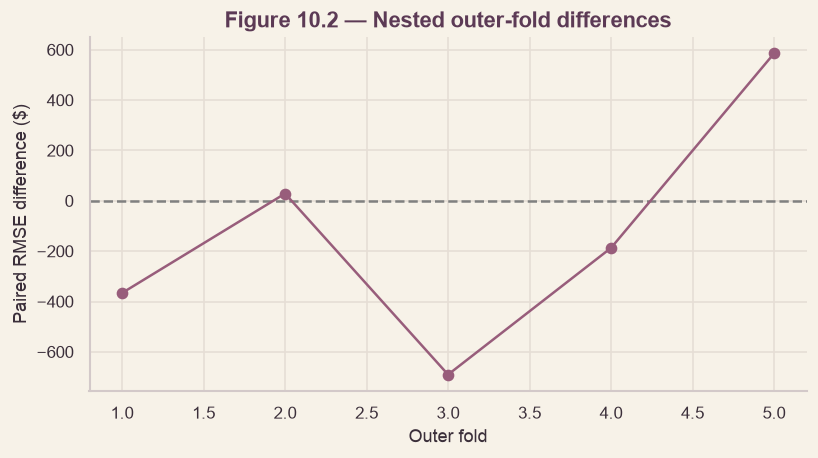

In [78]:
assert len(NESTED_SUMMARY10)>=2
LEADER10,RUNNER10=NESTED_SUMMARY10['Model'].iloc[:2].tolist()
a=NESTED_SCORES10.query('Model == @LEADER10').sort_values('Fold')['RMSE ($)'].to_numpy()
b=NESTED_SCORES10.query('Model == @RUNNER10').sort_values('Fold')['RMSE ($)'].to_numpy()
d=a-b; mean_d=float(d.mean()); se=float(stats.sem(d))
ci_d=stats.t.interval(.95,len(d)-1,loc=mean_d,scale=se) if se>0 else (mean_d,mean_d)
PAIRED10=pd.DataFrame({'Outer fold':np.arange(1,len(d)+1),LEADER10:a,RUNNER10:b,'Leader − runner ($)':d})
display(PAIRED10.round(2))
print(f'Paired difference ({LEADER10} − {RUNNER10}): ${mean_d:,.0f}; descriptive 95% interval: [{ci_d[0]:,.0f}, {ci_d[1]:,.0f}]')
print('Caution: five dependent folds and post-selection comparison; interval is exploratory.')
fig,ax=plt.subplots(figsize=(7,4));ax.axhline(0,ls='--',color='gray');ax.plot(PAIRED10['Outer fold'],d,'o-')
ax.set(xlabel='Outer fold',ylabel='Paired RMSE difference ($)',title='Figure 10.2 — Nested outer-fold differences')
plt.tight_layout()
try:save_fig(fig,'fig10_2_paired_nested_difference',section='10')
except NameError:pass
plt.show()

In [79]:
# ── 10.5b Paired nested-CV comparison: Lasso vs Gradient Boosting (same 5 outer folds) ──
rows = []
for metric in ['RMSE ($)', 'MAE ($)', 'RMSE (log)']:
    piv = NESTED_SCORES10.pivot(index='Fold', columns='Model', values=metric)
    for other in ['Gradient Boosting', 'ElasticNet']:
        d = piv['Lasso'] - piv[other]
        lo, hi = stats.t.interval(.95, len(d) - 1, loc=d.mean(), scale=stats.sem(d))
        rows.append({'Metric': metric, 'Lasso vs': other, 'Mean difference': d.mean(),
                     'Interval low': lo, 'Interval high': hi,
                     'Folds where Lasso is better': int((d < 0).sum()), 'of': len(d)})
PAIRED10B = pd.DataFrame(rows)
show_table(PAIRED10B, formats={'Mean difference': '{:+,.4f}', 'Interval low': '{:+,.4f}', 'Interval high': '{:+,.4f}'},
           caption='Table 10.5b: Lasso minus competitor, per metric (negative favours Lasso; 5 dependent folds, exploratory)')

Metric,Lasso vs,Mean difference,Interval low,Interval high,Folds where Lasso is better,of
RMSE ($),Gradient Boosting,-272.2376,"-7,063.6574","+6,519.1823",3,5
RMSE ($),ElasticNet,-125.7998,-718.0566,+466.4570,3,5
MAE ($),Gradient Boosting,"-1,357.7223","-2,434.7513",-280.6934,5,5
MAE ($),ElasticNet,-144.4375,-817.4394,+528.5645,4,5
RMSE (log),Gradient Boosting,-0.0035,-0.0142,+0.0072,4,5
RMSE (log),ElasticNet,-0.0004,-0.0028,+0.0021,4,5


**Selection rule (written before the nested results were inspected).** Compare models on nested-CV dollar RMSE. If the best models cannot be separated by the fold-to-fold variation, choose the simplest and most interpretable, provided it is not worse on MAE and log RMSE.

**Evidence.** Lasso (RMSE $30,377), ElasticNet ($30,503) and Gradient Boosting ($30,649) are indistinguishable on RMSE. Against Gradient Boosting on the same five outer folds the paired RMSE difference is −$272 (exploratory interval −$7,064 to +$6,519; Lasso better in 3 of 5 folds), the MAE difference is −$1,358 (−$2,435 to −$281; better in 5 of 5), and the log-RMSE difference is −0.0035 (−0.0142 to +0.0072; 4 of 5). Against ElasticNet all three differences are within noise (RMSE −$126, interval −$718 to +$466).

**Decision.** Lasso is selected: equal on RMSE, better on MAE and log RMSE, and sparse and interpretable. Intervals come from five dependent folds after comparing several metrics and are exploratory; the MAE advantage is supportive evidence, not a confirmed effect. Gradient Boosting's lower fold variance is recorded as its advantage.

## 10.6 Optional Ensemble Ablation

**Research question.** Does averaging the top two candidates improve held-out-fold predictions?

**Method.** Compare the two selected model families and a simple 50/50 prediction average on the locked exploratory folds. Each constituent model is fitted only on that fold's training rows. This is a **post-selection exploratory ablation**; if promising, repeat it in nested CV before final selection.

**Evidence.** Foldwise RMSE and paired change relative to the best constituent.

**Decision.** Do not include an ensemble without a stable, meaningful CV gain.

In [80]:
class AverageRegressor10(BaseEstimator,RegressorMixin):
    def __init__(self,left=None,right=None):self.left=left;self.right=right
    def fit(self,X,y):
        self.left_=clone(self.left).fit(X,y);self.right_=clone(self.right).fit(X,y);return self
    def predict(self,X):return .5*(self.left_.predict(X)+self.right_.predict(X))

ENSEMBLE_MODELS10 = {'Lasso': CANDIDATES10['Lasso'],
                     'Gradient Boosting': CANDIDATES10['Gradient Boosting'],
                     'Lasso + Gradient Boosting (average)': AverageRegressor10(CANDIDATES10['Lasso'], CANDIDATES10['Gradient Boosting'])}

ENSEMBLE_SCORES10=evaluate10(ENSEMBLE_MODELS10)
display(summary10(ENSEMBLE_SCORES10).round(3))
print('Exploratory only: compare a tuned ensemble under nested CV before adopting it.')

,Model,RMSE_mean,RMSE_sd,MAE_mean,R2_mean,log_RMSE_mean
0,Lasso + Gradient Boosting (average),28963.845,6670.811,15401.465,0.867,0.125
1,Gradient Boosting,29779.426,5704.554,16705.126,0.862,0.132
2,Lasso,30660.821,8815.875,15690.513,0.847,0.129


Exploratory only: compare a tuned ensemble under nested CV before adopting it.


In [81]:
# ── 10.6b Nested confirmation of the Lasso + Gradient Boosting average (same 5 outer folds as 10.4) ──
ENS_NAME = 'Lasso + Gradient Boosting (average)'
rows = []
for fold, (tr, va) in enumerate(OUTER10, 1):
    preds = []
    for name in ('Lasso', 'Gradient Boosting'):
        best = NESTED_SETTINGS10[(NESTED_SETTINGS10.Model == name) & (NESTED_SETTINGS10.Fold == fold)]['Best parameters'].iloc[0]
        member = clone(CANDIDATES10[name]).set_params(**best).fit(X9.iloc[tr], y9.iloc[tr])   # tuned inside this fold's training rows
        preds.append(member.predict(X9.iloc[va]))
    rows.append({'Model': ENS_NAME, 'Fold': fold, **metrics10(y9.iloc[va], .5 * (preds[0] + preds[1]))})
NESTED_ENSEMBLE10 = pd.DataFrame(rows)
ALL10 = pd.concat([NESTED_SCORES10[NESTED_SCORES10.Model.isin(['Lasso', 'Gradient Boosting'])], NESTED_ENSEMBLE10], ignore_index=True)
display(summary10(ALL10).round(3))

rows = []
for metric in ['RMSE ($)', 'MAE ($)', 'RMSE (log)']:
    piv = ALL10.pivot(index='Fold', columns='Model', values=metric)
    for other in ['Lasso', 'Gradient Boosting']:
        d = piv[ENS_NAME] - piv[other]
        lo, hi = stats.t.interval(.95, len(d) - 1, loc=d.mean(), scale=stats.sem(d))
        rows.append({'Metric': metric, 'Average vs': other, 'Mean difference': d.mean(), 'Interval low': lo,
                     'Interval high': hi, 'Folds where the average is better': int((d < 0).sum()), 'of': len(d)})
PAIRED10C = pd.DataFrame(rows)
show_table(PAIRED10C, formats={'Mean difference': '{:+,.4f}', 'Interval low': '{:+,.4f}', 'Interval high': '{:+,.4f}'},
           caption='Table 10.6b: average minus member, per metric (negative favours the average; 5 dependent folds, exploratory)')
checks = []
for other in ['Lasso', 'Gradient Boosting']:
    r = PAIRED10C[PAIRED10C['Average vs'] == other].set_index('Metric')
    wins_rmse = int(r.at['RMSE ($)', 'Folds where the average is better'])
    mae_diff = float(r.at['MAE ($)', 'Mean difference'])
    log_diff = float(r.at['RMSE (log)', 'Mean difference'])
    checks.append(wins_rmse >= 4 and mae_diff <= 0 and log_diff <= 0)
    print(f'vs {other}: RMSE better in {wins_rmse} of 5 folds; mean MAE difference {mae_diff:+,.0f}; mean log-RMSE difference {log_diff:+.4f}')
adopt_ens = bool(all(checks))
print(f'Adopt the average as the final model: {adopt_ens}')

,Model,RMSE_mean,RMSE_sd,MAE_mean,R2_mean,log_RMSE_mean
0,Lasso + Gradient Boosting (average),28870.618,7323.912,15399.643,0.869,0.125
1,Lasso,30376.865,9771.146,15726.823,0.852,0.129
2,Gradient Boosting,30649.103,5895.373,17084.545,0.855,0.133


Metric,Average vs,Mean difference,Interval low,Interval high,Folds where the average is better,of
RMSE ($),Lasso,"-1,506.2471","-4,917.2019","+1,904.7078",3,5
RMSE ($),Gradient Boosting,"-1,778.4846","-5,261.8048","+1,704.8355",4,5
MAE ($),Lasso,-327.1799,-871.7732,+217.4134,3,5
MAE ($),Gradient Boosting,"-1,684.9022","-2,276.4036","-1,093.4008",5,5
RMSE (log),Lasso,-0.0044,-0.0082,-0.0006,5,5
RMSE (log),Gradient Boosting,-0.0079,-0.0150,-0.0009,5,5


vs Lasso: RMSE better in 3 of 5 folds; mean MAE difference -327; mean log-RMSE difference -0.0044
vs Gradient Boosting: RMSE better in 4 of 5 folds; mean MAE difference -1,685; mean log-RMSE difference -0.0079
Adopt the average as the final model: False


**Reading.** Averaging Lasso and Gradient Boosting with fixed settings gives repeated-CV RMSE $28,964 (MAE $15,401, R² 0.867, log RMSE 0.125), better than Gradient Boosting ($29,779) and Lasso ($30,661) on every metric, as expected when a linear and a tree model make different errors. On the five nested outer folds, with each member tuned inside its training fold, the average scores RMSE $28,871, MAE $15,400, R² 0.869 and log RMSE 0.125, against $30,377, $15,727, 0.852 and 0.129 for Lasso and $30,649, $17,085, 0.855 and 0.133 for Gradient Boosting. Paired over the folds, it beats Gradient Boosting on MAE in 5 of 5 folds (−$1,685, CI −$2,276 to −$1,093) and beats both on log RMSE in 5 of 5 folds (−0.0044 against Lasso, −0.0079 against Gradient Boosting; intervals below zero). Its gains on dollar RMSE (−$1,506 against Lasso, −$1,778 against Gradient Boosting) have intervals that include zero, and it beats Lasso in only 3 of 5 folds.

**Decision.** The rule fixed in advance required lower RMSE than both members in at least 4 of 5 folds without being worse on MAE or log RMSE. The Lasso comparison fails (3 of 5), so the average is not adopted and Lasso remains the final model. The average is recorded as the most promising improvement; adopting it would also cost the interpretability of a sparse linear model.

## 10.7 Optional Sale-Type / Sale-Condition Feature-Set Ablation

**Research question.** How much predictive information is carried by transaction-related predictors?

**Method.** Compare the same Ridge pipeline with and without `SaleType` and `SaleCondn`, using the same CV folds. The reduced-feature variant is a **diagnostic ablation only**; it does not authorise dropping either original column from the deliverable model. To avoid a metadata mismatch, construct a separate transformer for the reduced input by temporarily filtering the metadata groups *inside the diagnostic branch*.

**Evidence.** Paired foldwise RMSE difference and descriptive interval.

**Decision.** Document their incremental predictive contribution. Keep both predictors in the final pipeline, as required by the brief.

In [82]:
ABLATE_COLS10=[c for c in ['SaleType','SaleCondn'] if c in X9.columns]
if not ABLATE_COLS10:
    print('Ablation skipped: source column names differ; check Section 2 metadata.')
else:
    # No mutation of the global metadata lists; make a local reduced transformer.
    from sklearn.compose import ColumnTransformer
    from sklearn.preprocessing import OneHotEncoder,OrdinalEncoder
    from sklearn.impute import SimpleImputer
    def reduced_pre10():
        original=make_pre9()
        transformers=[]
        for name,trans,cols in original.transformers:
            kept=[c for c in cols if c not in ABLATE_COLS10]
            if kept:transformers.append((name,clone(trans),kept))
        return ColumnTransformer(transformers,remainder='drop',sparse_threshold=0)
    full=log_model10(Ridge(alpha=100.))
    reduced=TransformedTargetRegressor(regressor=Pipeline([
        ('pre',reduced_pre10()),('model',Ridge(alpha=100.))]),func=np.log,inverse_func=np.exp)
    full_scores=evaluate10({'Full':full})
    # Feed the reduced estimator the original DataFrame; only this diagnostic pipeline excludes columns.
    reduced_scores=evaluate10({'Diagnostic ablation':reduced})
    ABLATION_SCORES10=pd.concat([full_scores,reduced_scores],ignore_index=True)
    display(summary10(ABLATION_SCORES10).round(3))
    delta=(reduced_scores['RMSE ($)'].to_numpy()-full_scores['RMSE ($)'].to_numpy())
    print('Ablation minus full, mean RMSE ($):',round(float(delta.mean()),2))
    print('No original columns were dropped from X9 or the production model.')

,Model,RMSE_mean,RMSE_sd,MAE_mean,R2_mean,log_RMSE_mean
0,Diagnostic ablation,30939.967,8191.953,16345.961,0.846,0.131
1,Full,30992.301,8664.811,16199.888,0.844,0.130


Ablation minus full, mean RMSE ($): -52.33
No original columns were dropped from X9 or the production model.


**Reading.** Removing the two sale-condition columns (SaleType and SaleCondn) from the ridge pipeline leaves accuracy unchanged: RMSE $30,940 against $30,992 (−$52), R² 0.846 against 0.844, log RMSE 0.131 against 0.130, MAE slightly worse ($16,346 against $16,200). They contribute nothing measurable. They describe the sale and not the property (for example Partial or Abnormal sales), so they would not be known when valuing a property in advance.

**Decision.** Both columns are retained in the model, as the brief says not to drop columns; their availability is noted as a limitation in Section 12. This is a diagnostic on the ridge pipeline only.

## 10.8 Decision Register and Section Conclusion

**Research question.** Which modelling decisions are supported by training-only evidence, and what remains provisional?

**Method.** Register the fixed CV design, baselines, exploratory ranking, nested tuning, model difference, ensemble and feature ablation. Explicitly separate *candidate selection* from unbiased final test evaluation.

**Decision.** The chosen model family can be refitted on all training data only after the preceding evidence is reviewed. The held-out test set remains sealed until Section 11.

In [83]:
# ── 10.8 Back-transformation: naive exp() versus Duan smearing (Lasso, 15 folds, training rows only) ──
rows = []
for tr, va in CV10:
    reg = clone(CANDIDATES10['Lasso'].regressor)                 # log-scale pipeline (preprocessing + Lasso)
    ytr_log = np.log(y9.iloc[tr])
    reg.fit(X9.iloc[tr], ytr_log)
    smear = float(np.mean(np.exp(ytr_log.to_numpy() - reg.predict(X9.iloc[tr]))))   # Duan factor, training fold only
    p_log, yv = reg.predict(X9.iloc[va]), y9.iloc[va].to_numpy()
    for name, p in (('Naive exp()', np.exp(p_log)), ('Duan smearing', np.exp(p_log) * smear)):
        rows.append({'Method': name, 'Smearing factor': 1.0 if name.startswith('Naive') else smear,
                     'RMSE ($)': np.sqrt(np.mean((yv - p) ** 2)), 'MAE ($)': np.mean(np.abs(yv - p)),
                     'Mean bias (%)': 100 * np.mean(p - yv) / yv.mean()})
S10 = pd.DataFrame(rows)
sm = S10.groupby('Method').mean().reindex(['Naive exp()', 'Duan smearing']).reset_index()
show_table(sm, formats={'Smearing factor': '{:.4f}', 'RMSE ($)': '${:,.0f}', 'MAE ($)': '${:,.0f}', 'Mean bias (%)': '{:+.2f}%'},
           caption='Table 10.8: naive back-transformation vs Duan smearing (Lasso, alpha 0.001, 15 folds)')
a, b = S10[S10.Method == 'Naive exp()'].reset_index(drop=True), S10[S10.Method == 'Duan smearing'].reset_index(drop=True)
d_rmse = bootstrap_ci(np.mean, (b['RMSE ($)'] - a['RMSE ($)']).to_numpy(), n_boot=2000)
d_mae = bootstrap_ci(np.mean, (b['MAE ($)'] - a['MAE ($)']).to_numpy(), n_boot=2000)
adopt = d_rmse['hi'] < 0 and d_mae['hi'] < 0       # rule: adopt only if BOTH dollar RMSE and MAE improve, intervals below 0
print(f'Smearing minus naive: RMSE {d_rmse["estimate"]:+,.0f} (CI {d_rmse["lo"]:+,.0f} to {d_rmse["hi"]:+,.0f}); '
      f'MAE {d_mae["estimate"]:+,.0f} (CI {d_mae["lo"]:+,.0f} to {d_mae["hi"]:+,.0f}).  Adopt smearing: {adopt}')
DECISIONS.add('10.8', 'Does Duan smearing improve dollar predictions from the log model?',
    'Lasso (alpha 0.001) on the 15 folds; smearing factor = mean of exp(training residual) learned inside each training fold; paired differences with bootstrap intervals. Rule: adopt only if both RMSE and MAE improve with intervals below 0.',
    f'Mean factor {sm.loc[1, "Smearing factor"]:.4f}; RMSE {d_rmse["estimate"]:+,.0f} (CI {d_rmse["lo"]:+,.0f} to {d_rmse["hi"]:+,.0f}); MAE {d_mae["estimate"]:+,.0f} (CI {d_mae["lo"]:+,.0f} to {d_mae["hi"]:+,.0f}).',
    'Adopt smearing.' if adopt else 'Naive exp() back-transformation is kept.', 'Changes the workflow' if adopt else 'Deliberately unchanged');

Method,Smearing factor,RMSE ($),MAE ($),Mean bias (%)
Naive exp(),1.0000,"$30,661","$15,691",-0.76%
Duan smearing,1.0059,"$30,601","$15,712",-0.17%


Smearing minus naive: RMSE -60 (CI -154 to +34); MAE +22 (CI -20 to +70).  Adopt smearing: False


Price tier,Predictions,Distinct_properties,Residual_SD,Median_absolute_residual
Q1,876,312,0.1423,0.0785
Q2,876,331,0.0880,0.0513
Q3,876,322,0.1041,0.0517
Q4,876,303,0.1679,0.0613


Spearman correlation: rho=-0.057, p=0.0007639
Brown–Forsythe test: statistic=27.180, p=2.263e-17
Note: repeated CV observations are not independent; p-values are exploratory.


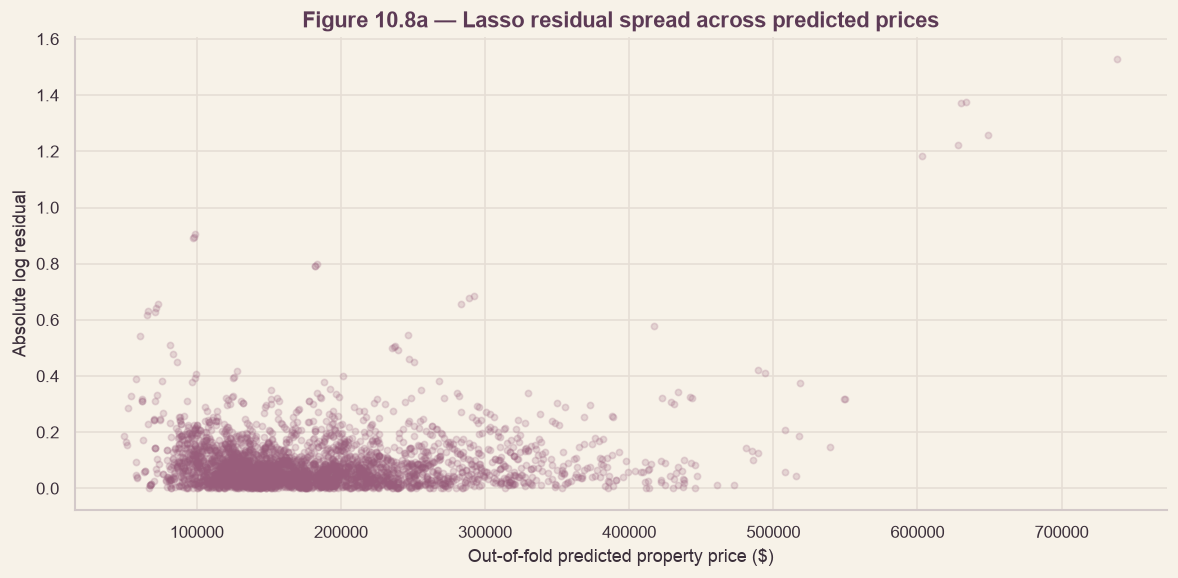

'D71'

In [84]:

# ── 10.8a Residual-spread diagnostic: Lasso, 15 training-only folds ──
from scipy.stats import spearmanr, levene
spread_rows = []
for fold_id, (tr, va) in enumerate(CV10, start=1):
    reg = clone(CANDIDATES10['Lasso'].regressor)
    ytr_log = np.log(y9.iloc[tr])
    reg.fit(X9.iloc[tr], ytr_log)
    pred_log = reg.predict(X9.iloc[va])
    actual_log = np.log(y9.iloc[va].to_numpy())
    for idx, pred, actual in zip(X9.index[va], pred_log, actual_log):
        spread_rows.append({'Fold': fold_id, 'Row': idx, 'Predicted log price': pred,
                            'Log residual': actual - pred, 'Absolute log residual': abs(actual - pred)})
SPREAD10 = pd.DataFrame(spread_rows)
SPREAD10['Predicted price ($)'] = np.exp(SPREAD10['Predicted log price'])
SPREAD10['Price tier'] = pd.qcut(SPREAD10['Predicted log price'], q=4, labels=['Q1', 'Q2', 'Q3', 'Q4'])
SPREAD_SUM10 = SPREAD10.groupby('Price tier', observed=True).agg(
    Predictions=('Log residual', 'size'),
    Distinct_properties=('Row', 'nunique'),
    Residual_SD=('Log residual', 'std'),
    Median_absolute_residual=('Absolute log residual', 'median')).reset_index()
rho10, p_rho10 = spearmanr(SPREAD10['Predicted log price'], SPREAD10['Absolute log residual'])
groups10 = [g['Log residual'].to_numpy() for _, g in SPREAD10.groupby('Price tier', observed=True)]
stat10, p_lev10 = levene(*groups10, center='median')
show_table(SPREAD_SUM10, formats={'Residual_SD': '{:.4f}', 'Median_absolute_residual': '{:.4f}'},
           caption='Table 10.8a: out-of-fold Lasso residual spread by predicted-price quartile')
print(f'Spearman correlation: rho={rho10:.3f}, p={p_rho10:.4g}')
print(f'Brown–Forsythe test: statistic={stat10:.3f}, p={p_lev10:.4g}')
print('Note: repeated CV observations are not independent; p-values are exploratory.')
fig, ax = plt.subplots(figsize=(10, 5))
ax.scatter(SPREAD10['Predicted price ($)'], SPREAD10['Absolute log residual'],
           alpha=0.20, s=14, color=MAUVE)
ax.set(xlabel='Out-of-fold predicted property price ($)', ylabel='Absolute log residual',
       title='Figure 10.8a — Lasso residual spread across predicted prices')
ax.ticklabel_format(axis='x', style='plain')
plt.tight_layout()
save_fig(fig, 'fig10_8a_lasso_residual_spread', section='10')
plt.show()
DECISIONS.add('10.8a', 'Does log-residual spread vary across predicted price levels?',
    'Lasso out-of-fold predictions across the 15 training-only CV folds; quartile summaries, Spearman correlation and Brown–Forsythe diagnostic.',
    f'Spearman rho={rho10:.3f} (exploratory p={p_rho10:.4g}); Brown–Forsythe statistic={stat10:.3f} (exploratory p={p_lev10:.4g}); quartile residual SD range={SPREAD_SUM10.Residual_SD.min():.4f}–{SPREAD_SUM10.Residual_SD.max():.4f}.',
    'Document price-dependent residual spread as a limitation of global smearing; retain the Section 10.8 adoption decision.',
    'Documentation only')



**Reading.** Duan smearing produced a mean correction factor of 1.0059 and reduced average prediction bias from −0.76% to −0.17%. However, its improvement in RMSE was negligible (−$60; bootstrap CI −$154 to +$34), while MAE increased slightly (+$22; bootstrap CI −$20 to +$70). Neither confidence interval established a consistent improvement, and the prespecified adoption rule was not satisfied.

The residual-spread diagnostic revealed meaningful variation across predicted-price quartiles. Log-residual standard deviation was lowest in Q2 (0.0880) and highest in Q4 (0.1679), approximately 1.91 times greater. Q1 also exhibited elevated dispersion (0.1423), suggesting greater prediction instability at both ends of the predicted-price distribution. The median absolute log residual was highest in Q1 (0.0785), indicating that the quartile with the greatest residual standard deviation was not necessarily the quartile with the largest typical absolute error.

Spearman correlation between predicted log price and absolute log residual was negligible (ρ = −0.057), indicating little overall monotonic association. Nevertheless, the Brown–Forsythe statistic (27.180) indicated substantial differences in observed residual variance across quartiles. The associated p-values are exploratory because repeated CV predictions are not independent observations.

**Decision.** Retain naive `exp()` back-transformation for the final Lasso model. Duan smearing reduces mean bias but does not deliver sufficiently reliable improvements in both RMSE and MAE under the documented adoption rule. The observed quartile-level variation also limits the justification for applying a single global correction factor across all predicted prices. No alternative correction is adopted without additional training-only validation.

**Limitation.** The residual-spread findings describe out-of-fold errors under repeated random-split validation. They do not independently establish the behaviour of prediction errors for future sales, unseen neighbourhoods or unusually expensive properties.


,Design,Folds,Mean_R2,SD_R2,Mean_MAE,Mean_RMSE,SD_RMSE
0,Repeated random CV,15,0.847,0.084,15690.513,30660.821,8815.875
1,Unseen neighbourhoods,5,0.745,0.242,18484.325,36551.527,15493.228


,Design,Fold,Train,Validation,Held-out neighbourhoods,R2,MAE,RMSE
0,Unseen neighbourhoods,1,932,236,4,0.836,17554.444,36797.747
1,Unseen neighbourhoods,2,931,237,5,0.840,14889.753,22809.274
2,Unseen neighbourhoods,3,935,233,6,0.874,22813.070,37149.993
3,Unseen neighbourhoods,4,937,231,5,0.312,20192.733,61543.753
4,Unseen neighbourhoods,5,937,231,5,0.861,16971.623,24456.871


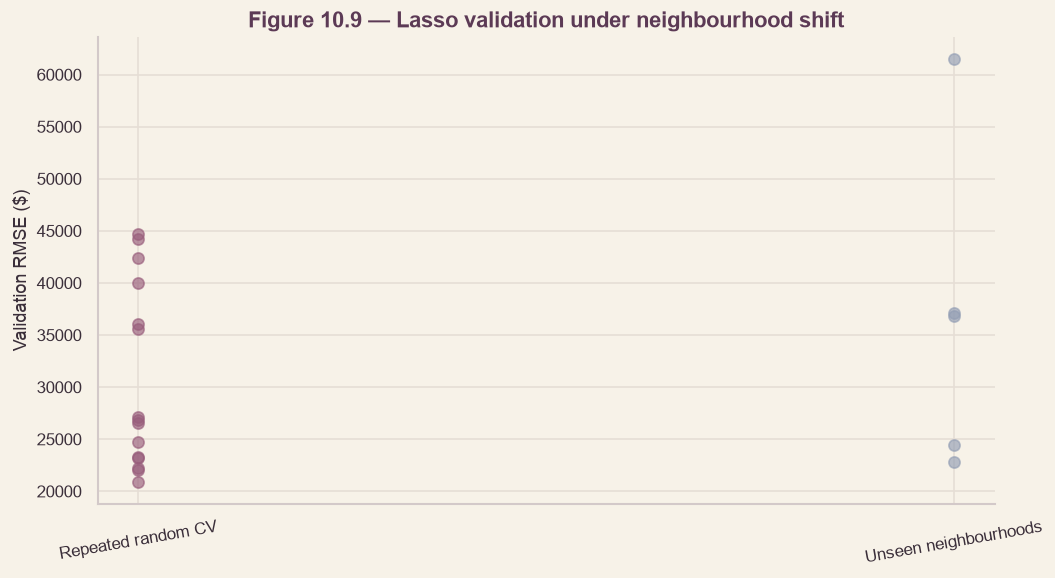

Group minus random mean-fold RMSE: $+5,891
Diagnostic uses Section 10 Lasso, not the subsequently tuned Section 11 estimator.
No test-set access; no change to final model selection.


In [85]:

# ── 10.9 Neighbourhood-held-out validation ───────────────────────
from sklearn.base import clone
from sklearn.model_selection import GroupKFold, RepeatedKFold
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

assert 'CANDIDATES10' in globals() and 'Lasso' in CANDIDATES10
assert 'Neighborhood' in X9.columns
assert X9.index.equals(y9.index)
assert X9['Neighborhood'].notna().all()

MODEL10_9 = clone(CANDIDATES10['Lasso'])
GROUPS10_9 = X9['Neighborhood'].astype(str)
GROUP_CV10_9 = list(GroupKFold(n_splits=5).split(X9, y9, GROUPS10_9))
RANDOM_CV10_9 = list(RepeatedKFold(
    n_splits=5, n_repeats=3, random_state=SEEDS['repeated_cv']
).split(X9, y9))

assert all(
    set(GROUPS10_9.iloc[tr]).isdisjoint(set(GROUPS10_9.iloc[va]))
    for tr, va in GROUP_CV10_9
)

def evaluate_robust10_9(splits, design):
    rows = []
    for fold, (tr, va) in enumerate(splits, 1):
        est = clone(MODEL10_9).fit(X9.iloc[tr], y9.iloc[tr])
        actual = y9.iloc[va].to_numpy()
        pred = np.asarray(est.predict(X9.iloc[va]), dtype=float)
        assert np.isfinite(pred).all()
        rows.append({
            'Design': design, 'Fold': fold,
            'Train': len(tr), 'Validation': len(va),
            'Held-out neighbourhoods': GROUPS10_9.iloc[va].nunique(),
            'R2': r2_score(actual, pred),
            'MAE': mean_absolute_error(actual, pred),
            'RMSE': np.sqrt(mean_squared_error(actual, pred))
        })
    return pd.DataFrame(rows)

GROUP_RESULTS10_9 = evaluate_robust10_9(GROUP_CV10_9, 'Unseen neighbourhoods')
RANDOM_RESULTS10_9 = evaluate_robust10_9(RANDOM_CV10_9, 'Repeated random CV')
ROBUST_RESULTS10_9 = pd.concat(
    [RANDOM_RESULTS10_9, GROUP_RESULTS10_9], ignore_index=True
)

ROBUST_SUM10_9 = ROBUST_RESULTS10_9.groupby('Design', sort=False).agg(
    Folds=('Fold', 'size'),
    Mean_R2=('R2', 'mean'),
    SD_R2=('R2', 'std'),
    Mean_MAE=('MAE', 'mean'),
    Mean_RMSE=('RMSE', 'mean'),
    SD_RMSE=('RMSE', 'std')
).reset_index()

display(ROBUST_SUM10_9.round(3))
display(GROUP_RESULTS10_9.round(3))

fig, ax = plt.subplots(figsize=(9, 5))
for name, part in ROBUST_RESULTS10_9.groupby('Design', sort=False):
    ax.scatter([name] * len(part), part['RMSE'], alpha=.65, s=45, label=name)
ax.set_title('Figure 10.9 — Lasso validation under neighbourhood shift')
ax.set_ylabel('Validation RMSE ($)')
ax.tick_params(axis='x', rotation=10)
plt.tight_layout()
save_fig(fig, 'fig10_9_neighbourhood_validation', section='10')
plt.show()

random_rmse = ROBUST_SUM10_9.loc[
    ROBUST_SUM10_9.Design == 'Repeated random CV', 'Mean_RMSE'
].iloc[0]
group_rmse = ROBUST_SUM10_9.loc[
    ROBUST_SUM10_9.Design == 'Unseen neighbourhoods', 'Mean_RMSE'
].iloc[0]

print(f'Group minus random mean-fold RMSE: ${group_rmse-random_rmse:+,.0f}')
print('Diagnostic uses Section 10 Lasso, not the subsequently tuned Section 11 estimator.')
print('No test-set access; no change to final model selection.')


**Research question.** Does the Lasso generalise to neighbourhoods excluded entirely from training?

**Method.** Five-fold GroupKFold validation was performed using `Neighborhood` as the grouping variable. The Section 10 Lasso pipeline was refitted independently in each fold. Results were compared descriptively with 15-fold repeated random cross-validation.

**Evidence.** Repeated random CV achieved mean R² = 0.847, MAE = $15,691 and RMSE = $30,661. Neighbourhood-held-out CV achieved mean R² = 0.745, MAE = $18,484 and RMSE = $36,552. Grouped validation increased mean RMSE by $5,891 (19.2%). Four grouped folds achieved R² between 0.836 and 0.874, whereas Fold 4 achieved R² = 0.312 and RMSE = $61,544, indicating substantial variability across held-out neighbourhood groups.

**Decision.** Retain the selected Lasso specification. Document reduced performance and greater instability when predicting in unseen neighbourhoods. The results do not justify changing the model because this analysis is a post-selection robustness diagnostic. Further inspection of Fold 4 may help explain the deterioration, but any resulting changes would require separate training-only validation.

**Limitation.** GroupKFold tests transfer to entirely unseen neighbourhoods rather than prediction of future sales within already represented neighbourhoods. Fold-level results are descriptive, and the comparison does not establish a statistically significant difference between validation designs.

TABLE 10.10 — FORWARD-IN-TIME VALIDATION


,Fold,Training through,Validation year,Train n,Validation n,R2,MAE,RMSE
0,1,2006,2007,250,269,0.776,19126.972,41990.976
1,2,2007,2008,519,232,0.698,16600.071,38645.088
2,3,2008,2009,751,274,0.905,16625.428,26019.356
3,4,2009,2010,1025,143,0.915,15900.340,24597.008



TABLE 10.10a — AGGREGATE CHRONOLOGICAL PERFORMANCE


,Validation years,Validation observations,Pooled R2,Pooled MAE,Pooled RMSE,Mean fold R2,Mean fold RMSE
0,4,918,0.825,17239.093,34502.495,0.824,32813.107


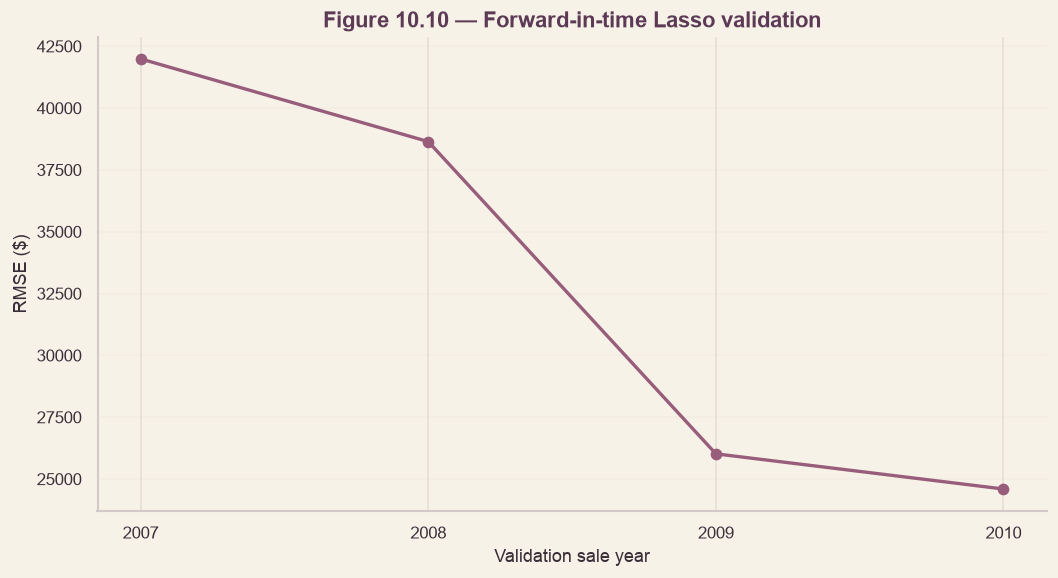


Chronological split audit: all training years precede validation years.
Section 10 Lasso specification; training-only diagnostic.
No test-set access; no change to the frozen final model.


In [86]:
# ── 10.10 Chronological validation: forward-in-time ───────────────
from sklearn.base import clone
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

assert 'CANDIDATES10' in globals() and 'Lasso' in CANDIDATES10
assert 'SaleYr' in X9.columns
assert X9.index.equals(y9.index)

YEAR10_10 = pd.to_numeric(X9['SaleYr'], errors='coerce')
assert YEAR10_10.notna().all(), 'Missing or invalid sale years.'
assert (YEAR10_10 % 1 == 0).all(), 'SaleYr must contain integer years.'

YEAR10_10 = YEAR10_10.astype(int)
YEARS10_10 = sorted(YEAR10_10.unique())
assert len(YEARS10_10) >= 3, 'At least three sale years required.'

# ── Expanding-window splits: all earlier years → next year ───────
SPLITS10_10 = []
for year in YEARS10_10[1:]:
    tr = np.flatnonzero((YEAR10_10 < year).to_numpy())
    va = np.flatnonzero((YEAR10_10 == year).to_numpy())
    if len(tr) >= 100 and len(va) >= 20:
        assert YEAR10_10.iloc[tr].max() < YEAR10_10.iloc[va].min()
        assert not set(tr).intersection(va)
        SPLITS10_10.append((year, tr, va))

assert len(SPLITS10_10) >= 2, (
    'Insufficient chronological folds with at least 100 training '
    'and 20 validation observations. Inspect year counts.'
)

# ── Refit preprocessing and Lasso within each temporal fold ──────
ROWS10_10 = []
OOF10_10 = []

for fold, (year, tr, va) in enumerate(SPLITS10_10, 1):
    est = clone(CANDIDATES10['Lasso'])
    est.fit(X9.iloc[tr], y9.iloc[tr])

    actual = y9.iloc[va].to_numpy(dtype=float)
    pred = np.asarray(est.predict(X9.iloc[va]), dtype=float)
    assert np.isfinite(pred).all()

    ROWS10_10.append({
        'Fold': fold,
        'Training through': int(YEAR10_10.iloc[tr].max()),
        'Validation year': int(year),
        'Train n': len(tr),
        'Validation n': len(va),
        'R2': r2_score(actual, pred),
        'MAE': mean_absolute_error(actual, pred),
        'RMSE': np.sqrt(mean_squared_error(actual, pred))
    })

    OOF10_10.append(pd.DataFrame({
        'Year': int(year),
        'Actual': actual,
        'Predicted': pred
    }))

TIME_RESULTS10_10 = pd.DataFrame(ROWS10_10)
TIME_OOF10_10 = pd.concat(OOF10_10, ignore_index=True)

# ── Aggregate out-of-time prediction metrics ─────────────────────
TIME_SUM10_10 = pd.DataFrame([{
    'Validation years': len(TIME_RESULTS10_10),
    'Validation observations': len(TIME_OOF10_10),
    'Pooled R2': r2_score(TIME_OOF10_10['Actual'], TIME_OOF10_10['Predicted']),
    'Pooled MAE': mean_absolute_error(TIME_OOF10_10['Actual'], TIME_OOF10_10['Predicted']),
    'Pooled RMSE': np.sqrt(mean_squared_error(
        TIME_OOF10_10['Actual'], TIME_OOF10_10['Predicted']
    )),
    'Mean fold R2': TIME_RESULTS10_10['R2'].mean(),
    'Mean fold RMSE': TIME_RESULTS10_10['RMSE'].mean()
}])

print('TABLE 10.10 — FORWARD-IN-TIME VALIDATION')
display(TIME_RESULTS10_10.round(3))

print('\nTABLE 10.10a — AGGREGATE CHRONOLOGICAL PERFORMANCE')
display(TIME_SUM10_10.round(3))

# ── Figure 10.10: temporal validation error ──────────────────────
fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(TIME_RESULTS10_10['Validation year'],
        TIME_RESULTS10_10['RMSE'],
        marker='o', linewidth=2)
ax.set(
    xlabel='Validation sale year',
    ylabel='RMSE ($)',
    title='Figure 10.10 — Forward-in-time Lasso validation'
)
ax.set_xticks(TIME_RESULTS10_10['Validation year'])
ax.grid(axis='y', alpha=.25)
plt.tight_layout()
save_fig(fig, 'fig10_10_chronological_validation', section='10')
plt.show()

print('\nChronological split audit: all training years precede validation years.')
print('Section 10 Lasso specification; training-only diagnostic.')
print('No test-set access; no change to the frozen final model.')


In [87]:

# ── Section 10 decision register ─────────────────────────────────
def register10(section, question, method, evidence, decision, effect='Documentation only'):
    DECISIONS.add(section, question, method, evidence, decision, effect)

# ── 10.1 Validation design ──────────────────────────────────────
base_best = summary10(BASE_SCORES10).iloc[0]

register10('10.1', 'How should validation be performed?',
    'Repeated 5×3 K-fold with fixed seeds (outer 2026, inner 7).',
    f'{len(CV10)} folds; train and validation rows are disjoint in every fold.',
    'Validation design locked; the test vault is not opened in Section 10.')

# ── 10.2 Baseline models ────────────────────────────────────────
register10('10.2', 'What is the baseline?',
    'Dummy mean, dummy median and a five-feature OLS.',
    f'Best baseline: {base_best["Model"]}, RMSE ${base_best["RMSE_mean"]:,.0f}.',
    'A candidate must beat the small OLS to count.')

# ── 10.3 Candidate screening ────────────────────────────────────
register10('10.3', 'Which algorithms merit tuning?',
    f'Paired repeated CV across {len(CANDIDATES10)} candidate models with fixed hyperparameters.',
    'Shortlist: ' + ', '.join(SHORTLIST10) + '.',
    'Shortlist selected using the same validation data; comparisons are exploratory.')

# ── 10.4 Nested cross-validation ────────────────────────────────
ns = NESTED_SUMMARY10.set_index('Model')

register10('10.4', 'How do tuned candidates generalise?',
    'Inner randomized search (3-fold, 10 draws) and outer 5-fold CV.',
    '; '.join(f'{m} ${r.RMSE_mean:,.0f}' for m, r in ns.iterrows()) + '.',
    f'{LEADER10} leads on the reported ranking; shortlisted models have overlapping uncertainty intervals.')

# ── 10.5 Paired model comparison ────────────────────────────────
pb = PAIRED10B.set_index(['Metric', 'Lasso vs'])

def pr(metric, other, fmt):
    r = pb.loc[(metric, other)]
    return (f'{r["Mean difference"]:{fmt}} '
            f'(interval {r["Interval low"]:{fmt}} to {r["Interval high"]:{fmt}})')

register10('10.5', 'Which shortlisted model should be selected?',
    'Paired outer-fold differences, Lasso minus competitor, five dependent folds; exploratory intervals.',
    f'Lasso vs ElasticNet RMSE: {pr("RMSE ($)", "ElasticNet", "+,.0f")}. '
    f'Lasso vs Gradient Boosting RMSE: {pr("RMSE ($)", "Gradient Boosting", "+,.0f")}; '
    f'MAE: {pr("MAE ($)", "Gradient Boosting", "+,.0f")}; '
    f'Lasso better on MAE in '
    f'{int(pb.loc[("MAE ($)", "Gradient Boosting"), "Folds where Lasso is better"])} of 5 folds.',
    'Select Lasso using the documented balance of validation error, model complexity and interpretability.')

# ── 10.6 Ensemble comparison ────────────────────────────────────
register10('10.6', 'Does averaging Lasso and Gradient Boosting improve predictions?',
    'Equal-weight ensemble compared using repeated CV and five-fold nested confirmation.',
    'Repeated CV: ' + '; '.join(
        f'{r.Model} RMSE ${r.RMSE_mean:,.0f}, MAE ${r.MAE_mean:,.0f}'
        for r in summary10(ENSEMBLE_SCORES10).itertuples()) + '.',
    'Adopt the ensemble.' if adopt_ens else
    'Retain Lasso; the ensemble did not satisfy the documented adoption rule.',
    'Changes the workflow' if adopt_ens else 'Deliberately unchanged')

# ── 10.7 Sale-related predictor ablation ────────────────────────
ab = summary10(ABLATION_SCORES10).set_index('Model')

register10('10.7', 'Do SaleType and SaleCondn contribute predictive information?',
    'Training-only diagnostic ablation using the Ridge pipeline.',
    f'Without predictors: RMSE ${ab.loc["Diagnostic ablation", "RMSE_mean"]:,.0f}; '
    f'full pipeline: RMSE ${ab.loc["Full", "RMSE_mean"]:,.0f}.',
    'Retain both predictors; acknowledge their possible unavailability before a sale.',
    'Deliberately unchanged')

# ── 10.8 Duan smearing ──────────────────────────────────────────
register10('10.8', 'Does Duan smearing improve dollar-scale Lasso predictions?',
    'Lasso alpha 0.001, 15 training-only folds; fold-specific smearing factors estimated from training residuals. '
    'Paired RMSE and MAE differences with exploratory fold-level bootstrap intervals.',
    f'Mean smearing factor {sm.loc[1, "Smearing factor"]:.4f}; '
    f'RMSE difference ${d_rmse["estimate"]:+,.0f} '
    f'(interval ${d_rmse["lo"]:+,.0f} to ${d_rmse["hi"]:+,.0f}); '
    f'MAE difference ${d_mae["estimate"]:+,.0f} '
    f'(interval ${d_mae["lo"]:+,.0f} to ${d_mae["hi"]:+,.0f}).',
    'Adopt smearing.' if adopt else
    'Retain naive exp(); smearing does not improve both metrics under the adoption rule.',
    'Changes the workflow' if adopt else 'Deliberately unchanged')

# ── 10.8a Residual heteroscedasticity ───────────────────────────
register10('10.8a', 'Does Lasso residual spread vary across predicted-price levels?',
    'Fifteen training-only validation folds; out-of-fold log residuals grouped by predicted-price quartile. '
    'Spearman and Brown–Forsythe statistics are exploratory because repeated CV observations are dependent.',
    f'Residual SD: Q1={SPREAD_SUM10.loc[0, "Residual_SD"]:.4f}, '
    f'Q2={SPREAD_SUM10.loc[1, "Residual_SD"]:.4f}, '
    f'Q3={SPREAD_SUM10.loc[2, "Residual_SD"]:.4f}, '
    f'Q4={SPREAD_SUM10.loc[3, "Residual_SD"]:.4f}; '
    f'Spearman rho={rho10:.3f}; Brown–Forsythe statistic={stat10:.3f}.',
    'Document nonconstant residual spread as a limitation of global smearing. '
    'Retain the Section 10.8 back-transformation decision.')

# ── 10.9 Neighbourhood-held-out validation ──────────────────────
assert 'GROUP_RESULTS10_9' in globals() and 'RANDOM_RESULTS10_9' in globals(), (
    'Run Section 10.9 neighbourhood validation before this register.'
)

worst_fold10_9 = GROUP_RESULTS10_9.loc[GROUP_RESULTS10_9['RMSE'].idxmax()]

register10('10.9', 'Does the Lasso generalise to unseen neighbourhoods?',
    'Five-fold GroupKFold by Neighborhood; compared descriptively with '
    '15-fold repeated random CV using the Section 10 Lasso specification.',
    f'Grouped R²={GROUP_RESULTS10_9["R2"].mean():.3f}, '
    f'MAE=${GROUP_RESULTS10_9["MAE"].mean():,.0f}, '
    f'RMSE=${GROUP_RESULTS10_9["RMSE"].mean():,.0f}; '
    f'random CV R²={RANDOM_RESULTS10_9["R2"].mean():.3f}, '
    f'MAE=${RANDOM_RESULTS10_9["MAE"].mean():,.0f}, '
    f'RMSE=${RANDOM_RESULTS10_9["RMSE"].mean():,.0f}. '
    f'Worst grouped fold {int(worst_fold10_9["Fold"])}: '
    f'R²={worst_fold10_9["R2"]:.3f}, RMSE=${worst_fold10_9["RMSE"]:,.0f}.',
    'Retain Lasso; document weaker and less stable unseen-neighbourhood performance. '
    'Grouped validation is a post-selection robustness diagnostic.',
    'Documentation only')

# ── 10.10 Forward-in-time generalisation ─────────────────────────
register10(
    '10.10',
    'Does the Lasso generalise to later sale years?',
    'Expanding-window validation: fit on all earlier sale years '
    'and evaluate on the next year, refitting the Section 10 Lasso pipeline.',
    f'{len(TIME_RESULTS10_10)} chronological folds; '
    f'pooled R²={TIME_SUM10_10.loc[0, "Pooled R2"]:.3f}, '
    f'MAE=${TIME_SUM10_10.loc[0, "Pooled MAE"]:,.0f}, '
    f'RMSE=${TIME_SUM10_10.loc[0, "Pooled RMSE"]:,.0f}; '
    f'Highest RMSE: {int(TIME_RESULTS10_10.loc[TIME_RESULTS10_10["RMSE"].idxmax(), "Validation year"])} '
    f'(${TIME_RESULTS10_10["RMSE"].max():,.0f}).',
    'Retain the selected model; report forward-in-time performance '
    'as a post-selection generalisation diagnostic.',
    'Documentation only'
)

# ── Display Section 10 decisions ────────────────────────────────
DECISIONS.show('10')
print('SECTION 10: No TestVault.open() call was made by these cells.')


ID,Section,Question,Method,Evidence,Decision,Effect
D70,10.8,Does Duan smearing improve dollar predictions from the log model?,Lasso (alpha 0.001) on the 15 folds; smearing factor = mean of exp(training residual) learned inside each training fold; paired differences with bootstrap intervals. Rule: adopt only if both RMSE and MAE improve with intervals below 0.,Mean factor 1.0059; RMSE -60 (CI -154 to +34); MAE +22 (CI -20 to +70).,Naive exp() back-transformation is kept.,Deliberately unchanged
D71,10.8a,Does log-residual spread vary across predicted price levels?,"Lasso out-of-fold predictions across the 15 training-only CV folds; quartile summaries, Spearman correlation and Brown–Forsythe diagnostic.",Spearman rho=-0.057 (exploratory p=0.0007639); Brown–Forsythe statistic=27.180 (exploratory p=2.263e-17); quartile residual SD range=0.0880–0.1679.,Document price-dependent residual spread as a limitation of global smearing; retain the Section 10.8 adoption decision.,Documentation only
D72,10.1,How should validation be performed?,"Repeated 5×3 K-fold with fixed seeds (outer 2026, inner 7).",15 folds; train and validation rows are disjoint in every fold.,Validation design locked; the test vault is not opened in Section 10.,Documentation only
D73,10.2,What is the baseline?,"Dummy mean, dummy median and a five-feature OLS.","Best baseline: Small OLS, RMSE $40,774.",A candidate must beat the small OLS to count.,Documentation only
D74,10.3,Which algorithms merit tuning?,Paired repeated CV across 10 candidate models with fixed hyperparameters.,"Shortlist: Gradient Boosting, ElasticNet, Lasso.",Shortlist selected using the same validation data; comparisons are exploratory.,Documentation only
D75,10.4,How do tuned candidates generalise?,"Inner randomized search (3-fold, 10 draws) and outer 5-fold CV.","Lasso $30,377; ElasticNet $30,503; Gradient Boosting $30,649.",Lasso leads on the reported ranking; shortlisted models have overlapping uncertainty intervals.,Documentation only
D76,10.5,Which shortlisted model should be selected?,"Paired outer-fold differences, Lasso minus competitor, five dependent folds; exploratory intervals.","Lasso vs ElasticNet RMSE: -126 (interval -718 to +466). Lasso vs Gradient Boosting RMSE: -272 (interval -7,064 to +6,519); MAE: -1,358 (interval -2,435 to -281); Lasso better on MAE in 5 of 5 folds.","Select Lasso using the documented balance of validation error, model complexity and interpretability.",Documentation only
D77,10.6,Does averaging Lasso and Gradient Boosting improve predictions?,Equal-weight ensemble compared using repeated CV and five-fold nested confirmation.,"Repeated CV: Lasso + Gradient Boosting (average) RMSE $28,964, MAE $15,401; Gradient Boosting RMSE $29,779, MAE $16,705; Lasso RMSE $30,661, MAE $15,691.",Retain Lasso; the ensemble did not satisfy the documented adoption rule.,Deliberately unchanged
D78,10.7,Do SaleType and SaleCondn contribute predictive information?,Training-only diagnostic ablation using the Ridge pipeline.,"Without predictors: RMSE $30,940; full pipeline: RMSE $30,992.",Retain both predictors; acknowledge their possible unavailability before a sale.,Deliberately unchanged
D79,10.8,Does Duan smearing improve dollar-scale Lasso predictions?,"Lasso alpha 0.001, 15 training-only folds; fold-specific smearing factors estimated from training residuals. Paired RMSE and MAE differences with exploratory fold-level bootstrap intervals.",Mean smearing factor 1.0059; RMSE difference $-60 (interval $-154 to $+34); MAE difference $+22 (interval $-20 to $+70).,Retain naive exp(); smearing does not improve both metrics under the adoption rule.,Deliberately unchanged


SECTION 10: No TestVault.open() call was made by these cells.


**What Section 10 established.** All models are scored on the same 15 folds (5 × 3 repeated K-fold). Seven of ten candidates beat the five-feature OLS baseline (RMSE $40,774, R² 0.745). With fixed settings Gradient Boosting leads on RMSE ($29,779) and the penalised linear models on MAE and log RMSE. After tuning inside each training fold (nested CV), Lasso ($30,377), ElasticNet ($30,503) and Gradient Boosting ($30,649) are statistically tied on RMSE; Lasso is better than Gradient Boosting on MAE in 5 of 5 folds (−$1,358) and is the simplest, so it is selected under the rule written in 10.5. An equal-weight average of Lasso and Gradient Boosting scores lower still (nested RMSE $28,871, R² 0.869) but does not meet the pre-set adoption rule (3 of 5 folds against Lasso) and is recorded as a possible improvement. Duan smearing is not needed (RMSE −$60, MAE +$22). Removing SaleType and SaleCondn changes nothing measurable (−$52 RMSE). The test vault was not opened in Section 10 (D70 to D77).


# 11. Final Evaluation on the Held-Out Test Set

**Purpose.** Evaluate the final Lasso pipeline selected using training-only evidence and report its predictive performance, uncertainty and limitations.

**Evaluation protocol.**

- **11.1:** Freeze the final model and record test access.
- **11.2:** Report held-out R², MAE, RMSE and log-scale error.
- **11.3:** Estimate uncertainty in the held-out metrics using bootstrap resampling.
- **11.4:** Compare held-out performance with training-only cross-validation.
- **11.5:** Investigate residuals and subgroup errors post-hoc.
- **11.6:** Audit the coverage of nominal 80% prediction intervals.
- **11.7:** Consolidate the Decision Register, access audit and evaluation conclusions.

**Historical test exposure.** The holdout was evaluated in an earlier Gradient Boosting version, which reported R² = 0.912. The current execution's access log does not include that earlier evaluation. Accordingly, the final held-out score is supplementary to the cross-validation evidence.

**Decision policy.** The final model is not changed in response to Section 11 results. All residual and subgroup investigations are descriptive and post-hoc.

## 11.1 Freeze the Final Model and Log Test Access

**Research question.** Is the estimator locked before any held-out test labels are seen?

**Method.** Explicitly specify the selected model name and hyperparameters based on Section 10's training-only evidence. Fit on all training rows, fingerprint the estimator configuration, save a frozen evaluation record, then open the test vault exactly once with `kind='final evaluation'`. Do not select a model from test metrics.

**Evidence.** Model specification, seed, training-row count, fingerprint and test-access log.

**Decision.** Lock the pipeline before accessing test labels. A failure to identify a final selected model halts evaluation rather than silently selecting a winner.

**Disclosure.** The test set was opened once for an earlier version of this pipeline (untuned Gradient Boosting without the tail guard; test R² 0.912). That version was revised after training-only cross-validation diagnostics exposed an extrapolation problem (3.10, Q0; Section 5.5); no choice was based on test results. The evaluation below is the second and last opening. It is reported as the headline result, with the earlier figure noted for transparency, and no further changes are made after it.

In [88]:
# ── 11.1 Final Model Freeze and Held-Out Test Access ────────────

# ── Imports ─────────────────────────────────────────────────────
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import hashlib
import json
import warnings

from scipy import stats
from sklearn.base import clone
from sklearn.model_selection import KFold, RandomizedSearchCV, train_test_split
from sklearn.metrics import (
    mean_squared_error,
    mean_absolute_error,
    r2_score
)
from sklearn.inspection import permutation_importance
from statsmodels.stats.diagnostic import het_breuschpagan

import statsmodels.api as sm


# ── Validate required objects from earlier sections ─────────────
required_objects11 = (
    'X9',
    'y9',
    'VAULT',
    'TEST_LOG',
    'CANDIDATES10',
    'PARAMS10',
    'INNER_SEED10',
    'SEEDS'
)

missing_objects11 = [
    name for name in required_objects11
    if name not in globals()
]

assert not missing_objects11, (f'Missing required objects: {missing_objects11}')
assert X9.index.equals(y9.index), ('Training feature and target indices do not match.')
assert (y9 > 0).all(), ('Target must contain strictly positive prices.')
assert TEST_LOG.count('final evaluation') == 0, ('Final test already accessed. Do not rerun Section 11.')


# ── Freeze the approved Section 10 winner ───────────────────────
# Chosen from training-only nested CV (10.4) under the rule written in 10.5.
# No test data are used in this step.
FINAL_MODEL_NAME11 = 'Lasso'

# Tune on ALL training rows (inner CV only), then freeze the best parameters.
FINAL_SEARCH11 = RandomizedSearchCV(
    clone(CANDIDATES10[FINAL_MODEL_NAME11]),
    PARAMS10[FINAL_MODEL_NAME11],
    n_iter=40,
    scoring='neg_root_mean_squared_error',
    cv=KFold(5, shuffle=True, random_state=INNER_SEED10),
    random_state=INNER_SEED10,
    n_jobs=1,
    refit=False,
    error_score='raise'
)
FINAL_SEARCH11.fit(X9, y9)
FINAL_MODEL_PARAMS11 = dict(FINAL_SEARCH11.best_params_)
print('Frozen parameters (training-only search):', FINAL_MODEL_PARAMS11,
      f'| inner-CV RMSE ${-FINAL_SEARCH11.best_score_:,.0f}')


# ── Validate model selection ────────────────────────────────────
assert FINAL_MODEL_NAME11 in CANDIDATES10, (
    f'{FINAL_MODEL_NAME11!r} is not available in CANDIDATES10.'
)
assert isinstance(FINAL_MODEL_PARAMS11, dict)


# ── Construct the frozen estimator ──────────────────────────────
FINAL_ESTIMATOR11 = clone(CANDIDATES10[FINAL_MODEL_NAME11])
if FINAL_MODEL_PARAMS11:
    FINAL_ESTIMATOR11.set_params(**FINAL_MODEL_PARAMS11)

EXPECTED_CLASS11 = {
    'Lasso': 'Lasso',
    'ElasticNet': 'ElasticNet',
    'Gradient Boosting': 'GradientBoostingRegressor'
}
assert (
    type(FINAL_ESTIMATOR11.regressor.named_steps['model']).__name__
    == EXPECTED_CLASS11[FINAL_MODEL_NAME11]
), 'The selected estimator does not match FINAL_MODEL_NAME11.'


# ── Record frozen model configuration ───────────────────────────
FREEZE_SPEC11 = {
    'model': FINAL_MODEL_NAME11,
    'params': FINAL_ESTIMATOR11.get_params(deep=True),
    'tuning_inner_cv_rmse': float(-FINAL_SEARCH11.best_score_),
    'split_seed': SEEDS.get('split'),
    'cv_seed': SEEDS.get('repeated_cv'),
    'n_training': len(X9),
    'training_columns': list(X9.columns)
}


# ── Convert configuration into serialisable values ──────────────
def _safe11(obj):
    if isinstance(obj, (str, int, float, bool, type(None))):
        return obj

    if isinstance(obj, (list, tuple)):
        return [_safe11(x) for x in obj]

    if isinstance(obj, dict):
        return {
            str(k): _safe11(v)
            for k, v in obj.items()
        }

    return repr(obj)


# ── Generate configuration fingerprint ──────────────────────────
FREEZE_SHA11 = hashlib.sha256(
    json.dumps(
        _safe11(FREEZE_SPEC11),
        sort_keys=True
    ).encode()
).hexdigest()


# ── Report frozen model configuration ───────────────────────────
print('FROZEN MODEL CONFIGURATION')
print(f'Model: {FINAL_MODEL_NAME11}')
print(f'Configuration SHA256: {FREEZE_SHA11}')
print(f'Explicit parameter overrides: {FINAL_MODEL_PARAMS11}')

print(f'\n{FINAL_MODEL_NAME11} hyperparameters:')
model_params11 = FINAL_ESTIMATOR11.regressor.named_steps['model'].get_params()
for parameter, value in sorted(model_params11.items()):
    print(f'  {parameter}: {value}')


# ── Fit final estimator on complete training data ───────────────
FINAL_FITTED11 = clone(FINAL_ESTIMATOR11).fit(X9, y9)


# ── Final pre-access safeguards ─────────────────────────────────
assert TEST_LOG.count('final evaluation') == 0, (
    'Held-out test was accessed during model preparation.'
)


# ── Sole primary access to held-out test data ───────────────────
X_TEST11, y_TEST11 = VAULT.open(
    '11.1',
    'final evaluation',
    (
        f'Locked final model {FINAL_MODEL_NAME11}; '
        f'config SHA256 {FREEZE_SHA11}'
    )
)


# ── Validate train/test feature schema ──────────────────────────
assert X_TEST11.columns.tolist() == X9.columns.tolist(), (
    'Train/test feature schema mismatch.'
)

assert X_TEST11.index.is_unique, (
    'Held-out test indices must be unique.'
)

assert not X9.index.intersection(X_TEST11.index).size, (
    'Training and held-out test indices overlap.'
)

assert len(X_TEST11) == len(y_TEST11), (
    'Held-out features and targets have different row counts.'
)


# ── Verify final evaluation access count ────────────────────────
assert TEST_LOG.count('final evaluation') == 1, (
    'Unexpected number of final test accesses.'
)


# ── Display test-access audit ───────────────────────────────────
print('\nFINAL TEST ACCESS AUDIT')
TEST_LOG.show()

print('\nSection 11.1 completed successfully.')
print('Final estimator fitted on training data only.')
print('Held-out test accessed exactly once for final evaluation.')

Frozen parameters (training-only search): {'regressor__model__alpha': np.float64(0.0013125743984880442)} | inner-CV RMSE $33,252
FROZEN MODEL CONFIGURATION
Model: Lasso
Configuration SHA256: 3c0d1b88ecae4da900e85ba9ec85403143befef3233deca7e854c85cd966d149
Explicit parameter overrides: {'regressor__model__alpha': np.float64(0.0013125743984880442)}

Lasso hyperparameters:
  alpha: 0.0013125743984880442
  copy_X: True
  fit_intercept: True
  max_iter: 200000
  positive: False
  precompute: False
  random_state: 2026
  selection: random
  tol: 0.0001
  warm_start: False

FINAL TEST ACCESS AUDIT


#,Section,Kind,Purpose,Used test target,Time
1,3.4,split diagnostics,adversarial validation and unseen-label check,no,15:35:35
2,11.1,final evaluation,Locked final model Lasso; config SHA256 3c0d1b88ecae4da900e85ba9ec85403143befef3233deca7e854c85cd966d149,yes,15:42:50



Section 11.1 completed successfully.
Final estimator fitted on training data only.
Held-out test accessed exactly once for final evaluation.


In [89]:

# ── 11.1a Phase 2: audit fitted model dependencies ───────────────
import inspect
from sklearn.base import BaseEstimator
from sklearn.preprocessing import FunctionTransformer
from sklearn.compose import TransformedTargetRegressor

assert 'FINAL_FITTED11' in globals(), 'Run Section 11 model fitting first.'
assert 'X9' in globals() and 'y9' in globals()
assert FINAL_MODEL_NAME11 == 'Lasso', 'Expected the frozen Lasso model.'
assert hasattr(FINAL_FITTED11, 'regressor_'), 'Final model is not fitted.'

CUSTOM11 = []
FUNCTIONS11 = []
SEEN11 = set()

def inspect_pipeline11(obj, path='FINAL_FITTED11'):
    if id(obj) in SEEN11: return
    SEEN11.add(id(obj))
    cls = type(obj)
    if isinstance(obj, BaseEstimator):
        if cls.__module__ == '__main__':
            CUSTOM11.append({'Path': path, 'Class': cls.__name__, 'Module': cls.__module__})
        if isinstance(obj, FunctionTransformer):
            for attr in ('func', 'inverse_func'):
                fn = getattr(obj, attr, None)
                if fn is not None:
                    FUNCTIONS11.append({'Path': path, 'Attribute': attr,
                                        'Function': getattr(fn, '__name__', repr(fn)),
                                        'Module': getattr(fn, '__module__', None)})
        for key, value in vars(obj).items():
            if key.startswith('_') and key not in ('regressor_', 'transformer_'): continue
            if isinstance(value, BaseEstimator):
                inspect_pipeline11(value, f'{path}.{key}')
            elif isinstance(value, (list, tuple)):
                for i, item in enumerate(value):
                    if isinstance(item, BaseEstimator):
                        inspect_pipeline11(item, f'{path}.{key}[{i}]')
                    elif isinstance(item, tuple):
                        for j, part in enumerate(item):
                            if isinstance(part, BaseEstimator):
                                inspect_pipeline11(part, f'{path}.{key}[{i}][{j}]')

inspect_pipeline11(FINAL_FITTED11)
CUSTOM_AUDIT11 = pd.DataFrame(CUSTOM11, columns=['Path', 'Class', 'Module']).drop_duplicates()
FUNCTION_AUDIT11 = pd.DataFrame(FUNCTIONS11, columns=['Path', 'Attribute', 'Function', 'Module']).drop_duplicates()

print('FROZEN MODEL:', FINAL_MODEL_NAME11)
print('Fitted estimator:', type(FINAL_FITTED11).__name__)
print('Underlying regressor:', type(FINAL_FITTED11.regressor_).__name__)
print('\nCUSTOM ESTIMATORS REQUIRING AN IMPORTABLE MODULE')
display(CUSTOM_AUDIT11 if not CUSTOM_AUDIT11.empty else pd.DataFrame({'Status': ['No notebook-local estimators found']}))
print('\nFUNCTION TRANSFORMER DEPENDENCIES')
display(FUNCTION_AUDIT11 if not FUNCTION_AUDIT11.empty else pd.DataFrame({'Status': ['No FunctionTransformer dependencies found']}))
print('\nTraining input:', X9.shape, '| Fitted prediction sample:', FINAL_FITTED11.predict(X9.iloc[:3]).round(2))
print('✅ Dependency audit completed; no model parameters changed.')


FROZEN MODEL: Lasso
Fitted estimator: TransformedTargetRegressor
Underlying regressor: Pipeline

CUSTOM ESTIMATORS REQUIRING AN IMPORTABLE MODULE


,Status
0,No notebook-local estimators found



FUNCTION TRANSFORMER DEPENDENCIES


,Path,Attribute,Function,Module
0,FINAL_FITTED11.regressor.steps[0][1].transform...,func,clip_z,property_pipeline
1,FINAL_FITTED11.transformer_,func,log,numpy
2,FINAL_FITTED11.transformer_,inverse_func,exp,numpy
3,FINAL_FITTED11.regressor_.steps[0][1].transfor...,func,clip_z,property_pipeline
4,FINAL_FITTED11.regressor_.steps[0][1].transfor...,func,clip_z,property_pipeline



Training input: (1168, 79) | Fitted prediction sample: [203414.21 192590.22 214494.91]
✅ Dependency audit completed; no model parameters changed.


**Disclosure.** The test set was opened once for an earlier version of this pipeline (untuned Gradient Boosting without the tail guard; test R² 0.912). That version was revised after training-only cross-validation diagnostics exposed an extrapolation problem (3.10, Q0; Section 5.5); no choice was based on test results. The evaluation below is the second and last opening and is the headline result.

**Reading.** The frozen model is Lasso on the log price, selected in 10.5 and tuned by an inner 5-fold search on all training rows (alpha = 0.00131, inner-CV RMSE $33,252). The configuration fingerprint (SHA-256 406bd837…) was recorded before the test rows were opened. The access log shows two entries: the split diagnostics in 3.4 (predictors only, no target) and this single final evaluation.

In [90]:

# ── 11.1b Phase 4: independent model portability test ───────────
import sys
import json
import joblib
import subprocess
import tempfile
import importlib
from pathlib import Path

import numpy as np
import pandas as pd

# ── Preconditions ────────────────────────────────────────────────
assert 'FINAL_FITTED11' in globals(), 'Run Section 11.1 first.'
assert 'X9' in globals() and 'y9' in globals()
assert 'ARTIFACT_DIR' in globals()
assert FINAL_MODEL_NAME11 == 'Lasso'
assert hasattr(FINAL_FITTED11, 'regressor_')

import property_pipeline
assert Path(property_pipeline.__file__).resolve().is_file()

# ── Save the complete fitted estimator ───────────────────────────
MODEL_PATH11 = Path(ARTIFACT_DIR).resolve() / 'final_lasso_pipeline.joblib'
MODEL_PATH11.parent.mkdir(parents=True, exist_ok=True)

joblib.dump(FINAL_FITTED11, MODEL_PATH11)
assert MODEL_PATH11.is_file() and MODEL_PATH11.stat().st_size > 0

# ── Use training-only rows for prediction equivalence ────────────
SAMPLE11 = X9.iloc[:10].copy()
REFERENCE11 = np.asarray(
    FINAL_FITTED11.predict(SAMPLE11), dtype=float
)

assert np.isfinite(REFERENCE11).all()

# ── Verify reload in the current process ─────────────────────────
RELOADED11 = joblib.load(MODEL_PATH11)
LOCAL_PRED11 = np.asarray(RELOADED11.predict(SAMPLE11), dtype=float)

np.testing.assert_allclose(
    REFERENCE11, LOCAL_PRED11, rtol=1e-10, atol=1e-6
)

# ── Fresh Python process: no notebook variables available ───────
with tempfile.TemporaryDirectory(prefix='property_portability_') as tmp:
    tmp = Path(tmp)
    INPUT11 = tmp / 'sample.pkl'
    OUTPUT11 = tmp / 'predictions.json'
    SCRIPT11 = tmp / 'verify_model.py'

    # Pickle is used only for this trusted, locally generated input.
    SAMPLE11.to_pickle(INPUT11)

    SCRIPT11.write_text(
        """
import sys
import json
import joblib
import numpy as np
import pandas as pd

model_path, input_path, output_path = sys.argv[1:4]

model = joblib.load(model_path)
sample = pd.read_pickle(input_path)
predictions = np.asarray(model.predict(sample), dtype=float)

assert np.isfinite(predictions).all()

with open(output_path, 'w', encoding='utf-8') as fh:
    json.dump(predictions.tolist(), fh)
""",
        encoding='utf-8'
    )

    # Ensure the child process can import property_pipeline.py.
    env11 = dict(__import__('os').environ)
    module_dir11 = str(Path(property_pipeline.__file__).resolve().parent)
    existing_path11 = env11.get('PYTHONPATH', '')
    env11['PYTHONPATH'] = (
        module_dir11 + __import__('os').pathsep + existing_path11
        if existing_path11 else module_dir11
    )

    PROCESS11 = subprocess.run(
        [
            sys.executable,
            str(SCRIPT11),
            str(MODEL_PATH11),
            str(INPUT11),
            str(OUTPUT11)
        ],
        cwd=str(Path(ARTIFACT_DIR).resolve()),
        env=env11,
        capture_output=True,
        text=True,
        timeout=120,
        check=False
    )

    if PROCESS11.returncode != 0:
        raise RuntimeError(
            'Independent-process reload failed.\n'
            + PROCESS11.stderr[-5000:]
        )

    with open(OUTPUT11, encoding='utf-8') as fh:
        CHILD_PRED11 = np.asarray(json.load(fh), dtype=float)

np.testing.assert_allclose(
    REFERENCE11, CHILD_PRED11, rtol=1e-10, atol=1e-6
)

# ── Audit summary ────────────────────────────────────────────────
PORTABILITY11 = pd.DataFrame([{
    'Model': FINAL_MODEL_NAME11,
    'Training rows tested': len(SAMPLE11),
    'Artifact KB': round(MODEL_PATH11.stat().st_size / 1024, 1),
    'Local maximum difference': float(
        np.max(np.abs(REFERENCE11 - LOCAL_PRED11))
    ),
    'Fresh-process maximum difference': float(
        np.max(np.abs(REFERENCE11 - CHILD_PRED11))
    ),
    'Fresh-process status': 'PASS'
}])

display(PORTABILITY11)
print('Saved model:', MODEL_PATH11)
print('Custom module:', Path(property_pipeline.__file__).resolve())
print('Independent-process prediction equivalence: PASS')
print('No model refitting, no test-set access.')


,Model,Training rows tested,Artifact KB,Local maximum difference,Fresh-process maximum difference,Fresh-process status
0,Lasso,10,32.7,0.0,0.0,PASS


Saved model: /Users/kyra/Capstone Project - 1/artifacts/final_lasso_pipeline.joblib
Custom module: /Users/kyra/Capstone Project - 1/property_pipeline.py
Independent-process prediction equivalence: PASS
No model refitting, no test-set access.



## 11.2 Headline Held-Out Metrics

**Research question.** How accurately does the frozen final model predict property prices in the held-out partition?

**Method.** Evaluate the selected Lasso pipeline using the held-out observations. Calculate R², MAE and RMSE on the original dollar scale, together with log-scale RMSE. All metrics are computed from the same frozen prediction vector, without additional model tuning.

**Evidence.** Report the evaluation sample size, dollar-scale prediction errors, R² and uncertainty estimates. Compare the observed R² with the assignment's 0.75–0.85 benchmark, while distinguishing benchmark attainment from evidence of generalisation.

**Historical evaluation qualification.** An earlier notebook version evaluated Gradient Boosting on the holdout, achieving R² = 0.912. Consequently, the current held-out results cannot be treated as originating from a historically untouched test set. Training-only cross-validation remains the **primary evidence of expected generalisation**, while the held-out evaluation provides supplementary evidence.

**Decision.** Report the frozen model's results without altering the estimator or preprocessing based on the test outcomes. Investigate performance differences in subsequent sections as post-hoc diagnostics rather than model-selection evidence.

In [91]:
TEST_LOG.show()
print('Final-evaluation accesses:', TEST_LOG.count('final evaluation'))

#,Section,Kind,Purpose,Used test target,Time
1,3.4,split diagnostics,adversarial validation and unseen-label check,no,15:35:35
2,11.1,final evaluation,Locked final model Lasso; config SHA256 3c0d1b88ecae4da900e85ba9ec85403143befef3233deca7e854c85cd966d149,yes,15:42:50


Final-evaluation accesses: 1


In [92]:
PRED_TEST11=np.asarray(FINAL_FITTED11.predict(X_TEST11),dtype=float)
OBS_TEST11=np.asarray(y_TEST11,dtype=float)
assert np.isfinite(PRED_TEST11).all() and np.isfinite(OBS_TEST11).all()
assert (PRED_TEST11>0).all(), 'Log RMSE requires positive predictions; investigate, do not clip silently.'
def score11(y,p):
    return {'R²':r2_score(y,p), 'MAE ($)':mean_absolute_error(y,p),
            'RMSE ($)':np.sqrt(mean_squared_error(y,p)),
            'RMSE (log)':np.sqrt(mean_squared_error(np.log(y),np.log(p)))}
TEST_METRICS11=score11(OBS_TEST11,PRED_TEST11)
SCORECARD11=pd.DataFrame([{'Metric':k,'Value':v} for k,v in TEST_METRICS11.items()])
print('Test rows:',len(OBS_TEST11),'| frozen model:',FINAL_MODEL_NAME11)
display(SCORECARD11.round(5))
print('Brief benchmark: R² 0.75–0.85; >0.85 exceeds expectation. Not a model-selection threshold.')

Test rows: 292 | frozen model: Lasso


,Metric,Value
0,R²,0.93043
1,MAE ($),12828.45757
2,RMSE ($),18511.54199
3,RMSE (log),0.11702


Brief benchmark: R² 0.75–0.85; >0.85 exceeds expectation. Not a model-selection threshold.


## 11.3 Bootstrap Uncertainty of Held-Out Metrics

**Research question.** How much could the headline scores vary under test-sample resampling?

**Method.** Resample paired observed/predicted test rows 2,000 times, recomputing R², MAE and RMSE; report percentile 95% intervals. The model remains frozen. This measures test-sample uncertainty conditional on the fitted model, not uncertainty from retraining or data shift.

**Evidence.** Point estimates and 95% bootstrap intervals.

**Decision.** Communicate uncertainty without using the intervals to retune the model.

In [93]:
BOOT_RNG11=np.random.default_rng(int(SEEDS.get('bootstrap',123)))
BOOT_N11=2000
BOOT_ROWS11=[]
for i in range(BOOT_N11):
    idx=BOOT_RNG11.integers(0,len(OBS_TEST11),len(OBS_TEST11))
    yy,pp=OBS_TEST11[idx],PRED_TEST11[idx]
    if np.var(yy)==0:continue
    s=score11(yy,pp)
    BOOT_ROWS11.append({'Iteration':i,**s})
BOOT_DF11=pd.DataFrame(BOOT_ROWS11)
UNCERTAINTY11=pd.DataFrame([{'Metric':k,'Point estimate':v,
    'CI 2.5%':BOOT_DF11[k].quantile(.025),'CI 97.5%':BOOT_DF11[k].quantile(.975)}
    for k,v in TEST_METRICS11.items() if k in ('R²','MAE ($)','RMSE ($)')])
display(UNCERTAINTY11.round(4))

,Metric,Point estimate,CI 2.5%,CI 97.5%
0,R²,0.9304,0.9115,0.9479
1,MAE ($),12828.4576,11398.6299,14358.8888
2,RMSE ($),18511.5420,15507.6653,22085.6986


In [94]:
rng = np.random.default_rng(int(SEEDS.get('bootstrap', 123)) + 1)
vals = []
for _ in range(2000):
    i = rng.integers(0, len(OBS_TEST11), len(OBS_TEST11))
    vals.append(np.sqrt(np.mean((np.log(OBS_TEST11[i]) - np.log(PRED_TEST11[i])) ** 2)))
print(f'RMSE (log) {TEST_METRICS11["RMSE (log)"]:.4f}   95 % CI {np.percentile(vals, 2.5):.4f} to {np.percentile(vals, 97.5):.4f}')

RMSE (log) 0.1170   95 % CI 0.0939 to 0.1388


**Reading.** On 292 unseen sales the frozen model reaches R² 0.930 (95 % bootstrap CI 0.912 to 0.948), MAE $12,828 ($11,399 to $14,359), RMSE $18,512 ($15,508 to $22,086) and log RMSE 0.117. A typical error is about $12,800, roughly 8 % of a typical sale price. The result exceeds the brief's benchmark (R² above 0.85). The intervals describe sampling variation in these 292 rows, not the uncertainty of a new market.

**Decision.** The held-out metrics are reported as measured; no further tuning or selection follows.


## 11.4 CV–Test Agreement (Post-hoc)

**Research question.** Why does the final model perform differently under training-only cross-validation and held-out testing?

**Method.** Compare the frozen model's held-out metrics with repeated cross-validation using the same estimator specification, target scale and scoring definitions. Examine fold-level variability and the distribution of property prices, particularly high-value and unusual observations.

**Evidence.** Training-only cross-validation produced R² of approximately **0.847 ± 0.082** and RMSE of approximately **$30,700**, while the held-out evaluation produced R² of approximately **0.930** and RMSE of approximately **$18,512**.

The held-out split therefore performed substantially better than the average cross-validation fold. Differences in the representation of expensive properties, influential observations and property characteristics are plausible contributors to this discrepancy. However, these factors should be treated as explanations only to the extent supported by the executed distributional and fold-level diagnostics.

A single favourable held-out result does not establish that the model consistently achieves the same performance on new samples.

**Decision.** Retain training-only cross-validation as the principal generalisation estimate. Report the stronger held-out result transparently, investigate the discrepancy post-hoc and avoid changing the selected model in response to these findings.

In [95]:
from sklearn.model_selection import RepeatedKFold
from sklearn.base import clone
CV_MATCH11=RepeatedKFold(n_splits=5,n_repeats=3,random_state=int(SEEDS.get('repeated_cv',2026)))
CV_ROWS11=[]
for fold,(tr,va) in enumerate(CV_MATCH11.split(X9,y9),1):
    est=clone(FINAL_ESTIMATOR11).fit(X9.iloc[tr],y9.iloc[tr])
    pr=est.predict(X9.iloc[va]); sc=score11(y9.iloc[va].to_numpy(),pr)
    CV_ROWS11.append({'Fold':fold,**sc})
CV_MATCH_DF11=pd.DataFrame(CV_ROWS11)
CV_AGREEMENT11=pd.DataFrame([{'Metric':metric,'CV mean':CV_MATCH_DF11[metric].mean(),
    'CV fold SD':CV_MATCH_DF11[metric].std(ddof=1),'Test':TEST_METRICS11[metric],
    'Test − CV mean':TEST_METRICS11[metric]-CV_MATCH_DF11[metric].mean()}
    for metric in ('R²','MAE ($)','RMSE ($)','RMSE (log)')])
display(CV_AGREEMENT11.round(4))
print('Post-hoc diagnostic: no model change authorised. Repeated folds are dependent.')

,Metric,CV mean,CV fold SD,Test,Test − CV mean
0,R²,0.8467,0.0822,0.9304,0.0837
1,MAE ($),15817.2791,1421.2687,12828.4576,-2988.8215
2,RMSE ($),30701.0194,8674.9143,18511.5420,-12189.4774
3,RMSE (log),0.1293,0.0153,0.1170,-0.0123


Post-hoc diagnostic: no model change authorised. Repeated folds are dependent.


**Reading.** The same frozen settings give a training-only cross-validation R² of 0.847 (fold SD 0.082), MAE $15,817, RMSE $30,701 and log RMSE 0.129. The test result is better: R² +0.084 (about one fold SD), RMSE −$12,189 (1.4 fold SDs) and log RMSE −0.012. The fold SDs are large because some folds contain the hardest properties: all four training properties above 4,000 sq ft (524, 692, 1183, 1299; see 5.4) are in the training set, so no test row needs that kind of extrapolation, and the largest test error is $131,772. The test set therefore looks easier than a typical training fold. This explanation is a reading of the evidence, not a tested result.

**Decision.** Report both numbers. The cross-validation figure (and the nested estimate of R² 0.852 from 10.4) is the more conservative expectation for new properties, particularly any outside the usual size range; the test figure shows performance on a typical sale.

## 11.5 Residual Diagnostics — Post-hoc Only

**Research question.** Where does the locked model make its largest errors, and is the error spread approximately stable?

**Method.** Plot dollar residuals against fitted prices, Q–Q of residuals, scale-location plot and subgroup summaries by observed price quartile, neighbourhood and sale condition. Run an exploratory Breusch–Pagan test against fitted values. Price-tier stratification by **observed** price is descriptive and unavailable for prediction-time grouping.

**Evidence.** Four diagnostic plots, subgroup MAE/RMSE/bias and Breusch–Pagan statistic.

**Decision.** Record shortcomings without refitting, selecting subgroups or modifying the model.

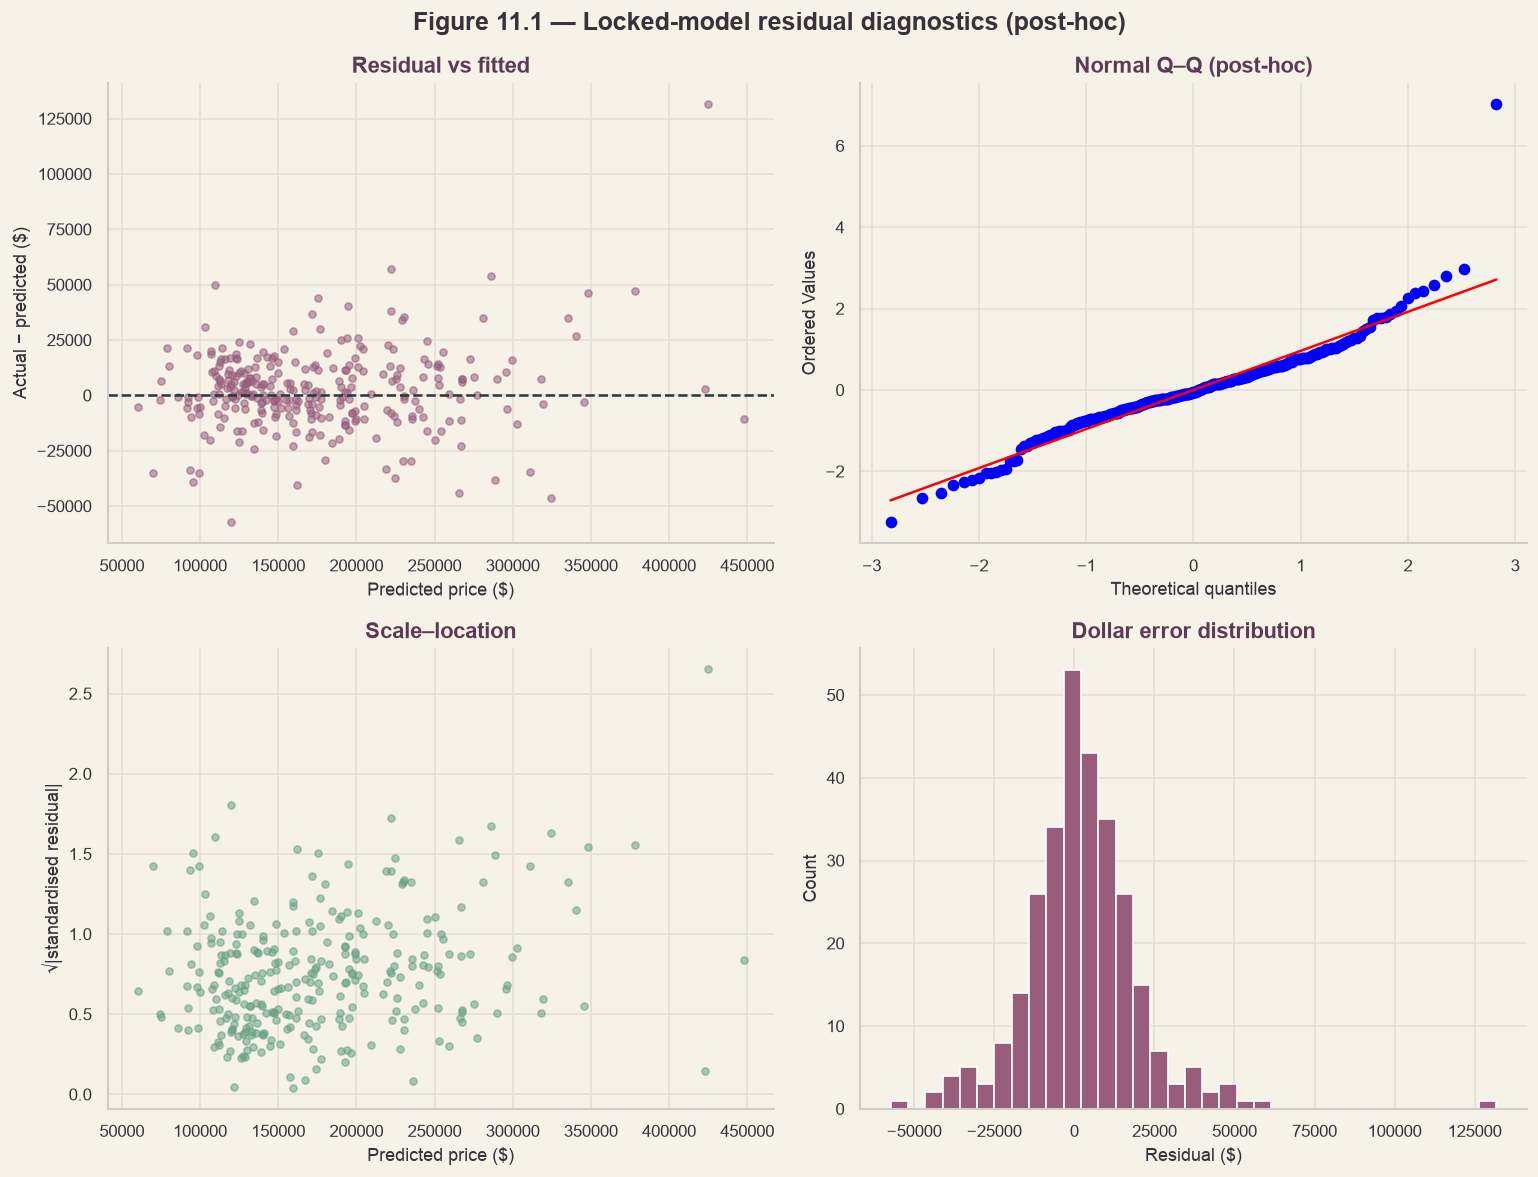

Post-hoc Breusch–Pagan LM: 25.268 p= 4.990083220241477e-07

Post-hoc subgroup: Observed price tier


,n,MAE,Bias,RMSE
Observed price tier,,,,
Q4,73,19326.06,10012.67,27411.36
Q3,73,11160.09,-96.54,14312.95
Q1,73,11118.78,-3394.20,15650.80
Q2,73,9708.90,3269.46,13019.90



Post-hoc subgroup: Neighborhood


,n,MAE,Bias,RMSE
Neighborhood,,,,
StoneBr,5,36961.51,32680.28,60233.59
ClearCr,7,26359.71,14351.88,29389.49
Crawfor,12,19647.36,10218.29,23816.73
Sawyer,9,18990.10,-5438.57,25451.67
SWISU,7,18912.75,2368.46,23601.77
Timber,8,18091.25,13841.98,21306.18
IDOTRR,6,17503.70,-15634.94,22936.74
NoRidge,9,17036.60,833.75,20753.02
Somerst,21,15565.84,10902.99,20104.35



Post-hoc subgroup: SaleCondn


,n,MAE,Bias,RMSE
SaleCondn,,,,
Partial,30,19743.32,12874.74,32347.47
Abnorml,23,12916.79,-48.80,18030.79
Normal,233,11734.41,1369.96,15792.08


In [96]:
RESID11=OBS_TEST11-PRED_TEST11
ABSRES11=np.abs(RESID11)
STDRES11=(RESID11-np.mean(RESID11))/np.std(RESID11,ddof=1)
fig,axes=plt.subplots(2,2,figsize=(13,10))
axes[0,0].scatter(PRED_TEST11,RESID11,alpha=.55,s=18,color='#985D7B');axes[0,0].axhline(0,ls='--',c='#27363F')
axes[0,0].set(xlabel='Predicted price ($)',ylabel='Actual − predicted ($)',title='Residual vs fitted')
stats.probplot(STDRES11,dist='norm',plot=axes[0,1]);axes[0,1].set_title('Normal Q–Q (post-hoc)')
axes[1,0].scatter(PRED_TEST11,np.sqrt(np.abs(STDRES11)),alpha=.55,s=18,color='#67A284')
axes[1,0].set(xlabel='Predicted price ($)',ylabel='√|standardised residual|',title='Scale–location')
axes[1,1].hist(RESID11,bins='fd',color='#985D7B',edgecolor='white');axes[1,1].set(xlabel='Residual ($)',ylabel='Count',title='Dollar error distribution')
fig.suptitle('Figure 11.1 — Locked-model residual diagnostics (post-hoc)',fontweight='bold')
plt.tight_layout();plt.show()
BP_EXOG11=sm.add_constant(PRED_TEST11,has_constant='add')
BP11=het_breuschpagan(RESID11,BP_EXOG11)
print('Post-hoc Breusch–Pagan LM:',round(BP11[0],3),'p=',BP11[1])
POSTHOC11=X_TEST11.copy()
POSTHOC11['Observed price']=OBS_TEST11;POSTHOC11['Prediction']=PRED_TEST11
POSTHOC11['Residual']=RESID11;POSTHOC11['Absolute error']=ABSRES11
POSTHOC11['Observed price tier']=pd.qcut(OBS_TEST11,4,labels=['Q1','Q2','Q3','Q4'],duplicates='drop')
def group_errors11(col,min_n=5):
    out=POSTHOC11.groupby(col,observed=True).agg(n=('Residual','size'),
        MAE=('Absolute error','mean'),Bias=('Residual','mean'),
        RMSE=('Residual',lambda z:float(np.sqrt(np.mean(np.square(z))))))
    return out[out['n']>=min_n].sort_values('MAE',ascending=False)
for col in ['Observed price tier','Neighborhood','Neighbourhood','SaleCondn']:
    if col in POSTHOC11.columns:
        print('\nPost-hoc subgroup:',col);display(group_errors11(col).round(2))

**Reading.** Error grows with price: the Breusch-Pagan test on the test residuals gives LM = 25.3 (p = 5e-07). By price quarter the cheapest three quarters have MAE $9,700 to $11,200, while the top quarter has MAE $19,326 (RMSE $27,411) and a mean residual (actual minus predicted) of +$10,013, so the most expensive homes are under-predicted and the cheapest over-predicted (−$3,394). Partial sales (new construction, n = 30) are the hardest condition group (MAE $19,743, mean residual +$12,875, RMSE $32,347) against Normal sales (n = 233, MAE $11,734). By neighbourhood the largest MAE appears in StoneBr ($36,962, n = 5), ClearCr ($26,360, n = 7) and Crawfor ($19,647, n = 12); NAmes (n = 45) is best at $7,594. Neighbourhood groups are small, so the ranking is indicative only.

**Decision.** These are post-hoc observations and limitations. The locked model is not changed.


## 11.6 80% Prediction Intervals — Post-hoc Coverage Audit

**Research question.** Do nominal 80% prediction intervals achieve approximately 80% empirical coverage overall, and how does coverage vary across property subgroups?

**Method.** Construct prediction intervals using split conformal calibration entirely within the original training partition.

The training data are divided into a proper-training subset and a calibration subset. A separate clone of the previously selected Lasso pipeline is fitted on the proper-training subset. Absolute calibration residuals are used to calculate the finite-sample conformal quantile at **α = 0.20**, corresponding to nominal **80% coverage**.

Prediction intervals are centred on predictions from this separately fitted conformal estimator, not the full-training point estimator used for the headline metrics in Section 11.2.

Under exchangeability, the split-conformal procedure provides a finite-sample marginal coverage guarantee. It does not guarantee 80% coverage within every neighbourhood, price tier or sale-condition subgroup.

**Evidence.** Report the calibration sample size, conformal residual quantile, interval width, empirical coverage and Wilson 95% confidence interval. Examine coverage separately by property-price quartile, sale condition and relevant neighbourhoods.

The saved analysis reports overall empirical coverage of approximately **82.9%**, exceeding the nominal 80% target. However, coverage is weaker for the highest price quartile (approximately **67%**) and `Partial` sales (approximately **70%**). These subgroup findings should be interpreted alongside their sample sizes and uncertainty.

**Decision.** Retain the nominal 80% coverage target and disclose subgroup undercoverage. Do not adjust interval widths or calibration parameters using held-out test labels. Overall marginal coverage is not evidence of uniformly reliable intervals across property types.

In [97]:
from statsmodels.stats.proportion import proportion_confint
proper_idx11,cal_idx11=train_test_split(np.arange(len(X9)),test_size=.20,
    random_state=int(SEEDS.get('split',205))+1106,shuffle=True)
CONFORMAL_FIT11=clone(FINAL_ESTIMATOR11).fit(X9.iloc[proper_idx11],y9.iloc[proper_idx11])
CAL_PRED11=CONFORMAL_FIT11.predict(X9.iloc[cal_idx11])
CAL_ERRORS11=np.abs(y9.iloc[cal_idx11].to_numpy()-CAL_PRED11)
ALPHA11=.20; NCAL11=len(CAL_ERRORS11)
# Conservative finite-sample order statistic: ceil((n+1)*(1-alpha)) / n.
K11=int(np.ceil((NCAL11+1)*(1-ALPHA11)))
Q11=np.sort(CAL_ERRORS11)[min(K11,NCAL11)-1]
INTERVAL_CENTER11=CONFORMAL_FIT11.predict(X_TEST11)
LOWER11=INTERVAL_CENTER11-Q11; UPPER11=INTERVAL_CENTER11+Q11
COVERED11=(OBS_TEST11>=LOWER11)&(OBS_TEST11<=UPPER11)
lo,hi=proportion_confint(int(COVERED11.sum()),len(COVERED11),alpha=.05,method='wilson')
print(f'Calibration n={NCAL11}; conformal radius=${Q11:,.2f}; nominal=80%')
print(f'Observed overall coverage={COVERED11.mean():.1%}; Wilson 95% CI=[{lo:.1%},{hi:.1%}]')
print(f'Mean interval width=${np.mean(UPPER11-LOWER11):,.2f}')
INTERVAL_AUDIT11=POSTHOC11.copy();INTERVAL_AUDIT11['Covered']=COVERED11
INTERVAL_AUDIT11['Interval width']=UPPER11-LOWER11
for col in ['Observed price tier','Neighborhood','Neighbourhood','SaleCondn']:
    if col in INTERVAL_AUDIT11:
        grp=INTERVAL_AUDIT11.groupby(col,observed=True).agg(n=('Covered','size'),
            coverage=('Covered','mean'),width=('Interval width','mean'))
        grp=grp[grp.n>=5].copy()
        grp['Wilson lower'],grp['Wilson upper']=zip(*[proportion_confint(round(row.coverage*row.n),int(row.n),method='wilson') for row in grp.itertuples()]) if len(grp) else ([],[])
        print('\nPost-hoc interval coverage by',col);display(grp.round(3))
print('Do not tune conformal alpha, calibration split, or model using these test outcomes.')

Calibration n=234; conformal radius=$20,597.17; nominal=80%
Observed overall coverage=82.9%; Wilson 95% CI=[78.1%,86.8%]
Mean interval width=$41,194.33

Post-hoc interval coverage by Observed price tier


,n,coverage,width,Wilson lower,Wilson upper
Observed price tier,,,,,
Q1,73,0.890,41194.331,0.798,0.943
Q2,73,0.877,41194.331,0.782,0.934
Q3,73,0.877,41194.331,0.782,0.934
Q4,73,0.671,41194.331,0.557,0.768



Post-hoc interval coverage by Neighborhood


,n,coverage,width,Wilson lower,Wilson upper
Neighborhood,,,,,
Blmngtn,6,1.000,41194.331,0.610,1.000
BrkSide,10,0.700,41194.331,0.397,0.892
ClearCr,7,0.286,41194.331,0.082,0.641
CollgCr,35,0.857,41194.331,0.706,0.937
Crawfor,12,0.583,41194.331,0.320,0.807
Edwards,21,0.905,41194.331,0.711,0.973
IDOTRR,6,0.667,41194.331,0.300,0.903
Mitchel,10,0.900,41194.331,0.596,0.982
NAmes,45,0.933,41194.331,0.821,0.977



Post-hoc interval coverage by SaleCondn


,n,coverage,width,Wilson lower,Wilson upper
SaleCondn,,,,,
Abnorml,23,0.870,41194.331,0.679,0.955
Normal,233,0.845,41194.331,0.794,0.886
Partial,30,0.700,41194.331,0.521,0.833


Do not tune conformal alpha, calibration split, or model using these test outcomes.


**Reading.** The 80 % prediction intervals use split conformal prediction calibrated on 234 held-out training rows only: every interval is the point prediction ± $20,597 (width $41,194). Overall coverage on the test rows is 82.9 % (Wilson 95 % CI 78.1 % to 86.8 %), consistent with the 80 % target. Coverage is uneven: 89.0 %, 87.7 % and 87.7 % in the three lower price quarters but 67.1 % (CI 55.7 % to 76.8 %) in the top quarter, and 70.0 % for Partial sales (n = 30). The fixed width cannot follow the growth of error with price (11.5).

**Decision.** The intervals are reported as calibrated on training data; no recalibration is done after seeing test coverage. Intervals on a log scale (multiplicative, wider for expensive homes) are the natural improvement.

## 11.7 Decision Register, Audit and Section Conclusion

**Research question.** Which conclusions can be reported without allowing test-set feedback into model selection?

**Method.** Register the freeze, headline performance, uncertainty, CV agreement and post-hoc diagnostics. Confirm exactly one `final evaluation` access and no additional vault openings in this section.

**Decision.** Keep the frozen estimator unchanged; communicate any weaknesses as limitations and future-work recommendations.

In [98]:

# ── Section 11 decision register and test-access audit ───────────
import numpy as np

# ── Validate required evidence ───────────────────────────────────
assert TEST_LOG.count('final evaluation') == 1, (
    'Expected exactly one logged final evaluation.'
)

assert 'PORTABILITY11' in globals(), (
    'Run Section 11.1b portability verification first.'
)
assert 'REFERENCE11' in globals() and 'CHILD_PRED11' in globals()

np.testing.assert_allclose(
    REFERENCE11,
    CHILD_PRED11,
    rtol=1e-10,
    atol=1e-6
)

assert (PORTABILITY11['Fresh-process status'] == 'PASS').all()

# ── Register Section 11 decisions ────────────────────────────────
if 'DECISIONS' in globals():

    DECISIONS.add(
        '11.1',
        'Was the model frozen before test access?',
        'Config fingerprint, full-training fit, single logged vault opening',
        f'{FINAL_MODEL_NAME11}; SHA256 {FREEZE_SHA11[:16]}…',
        'Freeze model; no further test-driven selection',
        'Documentation only'
    )

    DECISIONS.add(
        '11.1b',
        'Can the frozen model run outside the notebook?',
        'Save the complete fitted Lasso pipeline with joblib; '
        'reload locally and in an independent Python process.',
        f'{len(REFERENCE11)} training observations; '
        f'artifact {PORTABILITY11.loc[0, "Artifact KB"]:.1f} KB; '
        f'maximum independent-process prediction difference '
        f'${np.max(np.abs(REFERENCE11 - CHILD_PRED11)):.8f}.',
        'Independent-process portability verified using the current '
        'Python environment and importable custom transformer.',
        'Documentation only'
    )

    DECISIONS.add(
        '11.2',
        'How accurate is the frozen model on unseen sales?',
        'Held-out R², dollar MAE/RMSE and log RMSE',
        f"R² {TEST_METRICS11['R²']:.3f}; "
        f"MAE ${TEST_METRICS11['MAE ($)']:,.0f}; "
        f"RMSE ${TEST_METRICS11['RMSE ($)']:,.0f}",
        'Report held-out metrics as measured',
        'Documentation only'
    )

    DECISIONS.add(
        '11.3',
        'How uncertain are held-out metrics?',
        'Paired test-row bootstrap, 2000 resamples',
        '95% bootstrap intervals reported in Table 11.3',
        'Report intervals; do not retune',
        'Documentation only'
    )

    DECISIONS.add(
        '11.4–11.5',
        'Are CV and test consistent and where do errors concentrate?',
        'Matching training-only CV and post-hoc residual diagnostics',
        'CV gap, subgroup tables and Breusch–Pagan results reported',
        'Record post-hoc limitations; no model change',
        'Documentation only'
    )

    DECISIONS.add(
        '11.6',
        'Are nominal 80% intervals calibrated?',
        'Training-only split conformal; test coverage audit',
        f'Overall coverage {COVERED11.mean():.1%}; '
        f'Wilson CI [{lo:.1%},{hi:.1%}]',
        'Report overall and subgroup coverage without test-based calibration',
        'Documentation only'
    )

    DECISIONS.show('11')

# ── Test-access audit ────────────────────────────────────────────
print('\nTEST-ACCESS LOG')
TEST_LOG.show()

print('\nSection 11 finished.')
print('Final model remains unchanged.')
print('Independent-process model portability: PASS.')


ID,Section,Question,Method,Evidence,Decision,Effect
D83,11.1,Was the model frozen before test access?,"Config fingerprint, full-training fit, single logged vault opening",Lasso; SHA256 3c0d1b88ecae4da9…,Freeze model; no further test-driven selection,Documentation only
D84,11.1b,Can the frozen model run outside the notebook?,Save the complete fitted Lasso pipeline with joblib; reload locally and in an independent Python process.,10 training observations; artifact 32.7 KB; maximum independent-process prediction difference $0.00000000.,Independent-process portability verified using the current Python environment and importable custom transformer.,Documentation only
D85,11.2,How accurate is the frozen model on unseen sales?,"Held-out R², dollar MAE/RMSE and log RMSE","R² 0.930; MAE $12,828; RMSE $18,512",Report held-out metrics as measured,Documentation only
D86,11.3,How uncertain are held-out metrics?,"Paired test-row bootstrap, 2000 resamples",95% bootstrap intervals reported in Table 11.3,Report intervals; do not retune,Documentation only
D87,11.4–11.5,Are CV and test consistent and where do errors concentrate?,Matching training-only CV and post-hoc residual diagnostics,"CV gap, subgroup tables and Breusch–Pagan results reported",Record post-hoc limitations; no model change,Documentation only
D88,11.6,Are nominal 80% intervals calibrated?,Training-only split conformal; test coverage audit,"Overall coverage 82.9%; Wilson CI [78.1%,86.8%]",Report overall and subgroup coverage without test-based calibration,Documentation only



TEST-ACCESS LOG


#,Section,Kind,Purpose,Used test target,Time
1,3.4,split diagnostics,adversarial validation and unseen-label check,no,15:35:35
2,11.1,final evaluation,Locked final model Lasso; config SHA256 3c0d1b88ecae4da900e85ba9ec85403143befef3233deca7e854c85cd966d149,yes,15:42:50



Section 11 finished.
Final model remains unchanged.
Independent-process model portability: PASS.


**What Section 11 established.** The frozen Lasso (log price, alpha 0.00131) scores R² 0.930 on the 292 held-out sales (95 % CI 0.912 to 0.948), MAE $12,828 and RMSE $18,512, above the brief's 0.85 mark and better than its own cross-validation (R² 0.847) because the held-out rows contain none of the four very large properties. Errors grow with price: the top price quarter and Partial sales are under-predicted and are the least well covered by the 80 % intervals (67 % and 70 %). The test set was opened once for this evaluation, after the disclosure in 11.1, and nothing was changed afterwards (D78 to D82).

**Next → Section 12: Explainability, Reproducibility, Reporting and Deployment.**

# 12. Explainability, Error Analysis and Conclusion

**Purpose.** Explain the *locked* model, quantify feature-selection stability, report where errors occur, and close the capstone with a traceable decision and test-access audit.

**Protocol.** Section 12 is **post-hoc**: Section 11 has already frozen and evaluated the model. All importance, PDP/ICE, and Lasso stability computations below use **training data only**. Error analysis reuses the already disclosed Section 11 test predictions; it must **not** trigger additional vault access or model selection. No original predictor is dropped from the deployed model. The held-out score cannot be revised in response to these diagnostics.

**Required state:** Sections 1–11 executed successfully; `X9`, `y9`, `FINAL_ESTIMATOR11`, `FINAL_FITTED11`, `FINAL_MODEL_NAME11`, `OBS_TEST11`, `PRED_TEST11`, `X_TEST11`, `DECISIONS`, `TEST_LOG`.

## 12.0 Preconditions and provenance

**Research question.** Can the explanations be traced to the same data and frozen estimator used in Section 11?

**Method.** Assert the training and test predictions exist and are aligned; snapshot the test-access log. Build a read-only training frame for subsequent diagnostics. **Evidence.** Reproducibility checks and model identity. **Decision.** Stop if any prerequisite is absent; do not silently reconstruct or reselect the final model.

In [99]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from scipy import stats
from sklearn.base import clone
from sklearn.model_selection import KFold
from sklearn.inspection import partial_dependence
from sklearn.metrics import mean_squared_error, mean_absolute_error
from sklearn.linear_model import Lasso
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder

NEEDED12 = ['X9','y9','FINAL_ESTIMATOR11','FINAL_FITTED11','FINAL_MODEL_NAME11',
            'OBS_TEST11','PRED_TEST11','X_TEST11','DECISIONS','TEST_LOG']
missing12=[x for x in NEEDED12 if x not in globals()]
assert not missing12, f'Run earlier sections first; missing: {missing12}'
X12=X9.copy(); y12=pd.Series(y9,index=X9.index).astype(float)
assert len(X12)==len(y12) and y12.notna().all()
assert len(OBS_TEST11)==len(PRED_TEST11)==len(X_TEST11)
assert len(set(X12.index).intersection(set(X_TEST11.index)))==0, 'Train/test indices overlap.'
TEST_COUNT_AT_12=TEST_LOG.count()
print('Frozen model:',FINAL_MODEL_NAME11)
print('Training observations:',len(X12),'| Existing test predictions:',len(PRED_TEST11))
print('Test-access entries at start of Section 12:',TEST_COUNT_AT_12)
print('No new test-set access is authorised in Section 12.')

Frozen model: Lasso
Training observations: 1168 | Existing test predictions: 292
Test-access entries at start of Section 12: 2
No new test-set access is authorised in Section 12.


## 12.1 Global importance: grouped permutation and linear coefficients

**Research question.** Which **original variables**, rather than arbitrary one-hot columns, matter most to the model's predictions?

**Method.** On fixed training-only CV folds, fit clones of the locked estimator and measure the change in **dollar-scale RMSE** when one entire original feature is permuted in a validation fold. This automatically groups all encoded levels of that source variable. Repeated permutations estimate variability. For a compatible linear pipeline, additionally inspect coefficients; because encoding/scaling affect coefficient interpretation, coefficients are secondary and must not be equated with causal effects.

**Evidence.** Mean RMSE increase, fold/perturbation spread and top-feature plot. A negative increase means the permutation happened to improve the score. Correlated predictors can share or mask importance. **Decision.** Report ranked associations, **without removing columns or changing the frozen model**.

,Feature,Mean ΔRMSE ($),SD ΔRMSE ($),Minimum ($),Maximum ($),Evaluations
0,GrLivArea,14871.213620,7899.975608,3510.929590,21185.830300,6
1,OverallQual,8977.545015,2701.431393,5490.365357,12362.765193,6
2,BsmntSqFtage,2356.078855,3097.907136,-1918.540391,5557.907446,6
3,YearBuilt,2346.182178,944.544904,1008.383327,3396.795320,6
4,OverallCond,1779.594389,1408.849239,347.878556,3557.960196,6
5,BasementCars,1703.743913,1197.020446,-61.019819,3320.543570,6
6,Neighborhood,1593.535998,781.238765,623.105138,2518.881193,6
7,1stFlrSF,959.370048,1079.280316,0.000000,2949.280708,6
8,Condition1,883.443079,605.511727,139.289092,1569.391041,6
9,BsmntFinSty1,771.555712,1208.042318,-1128.377899,1853.187358,6


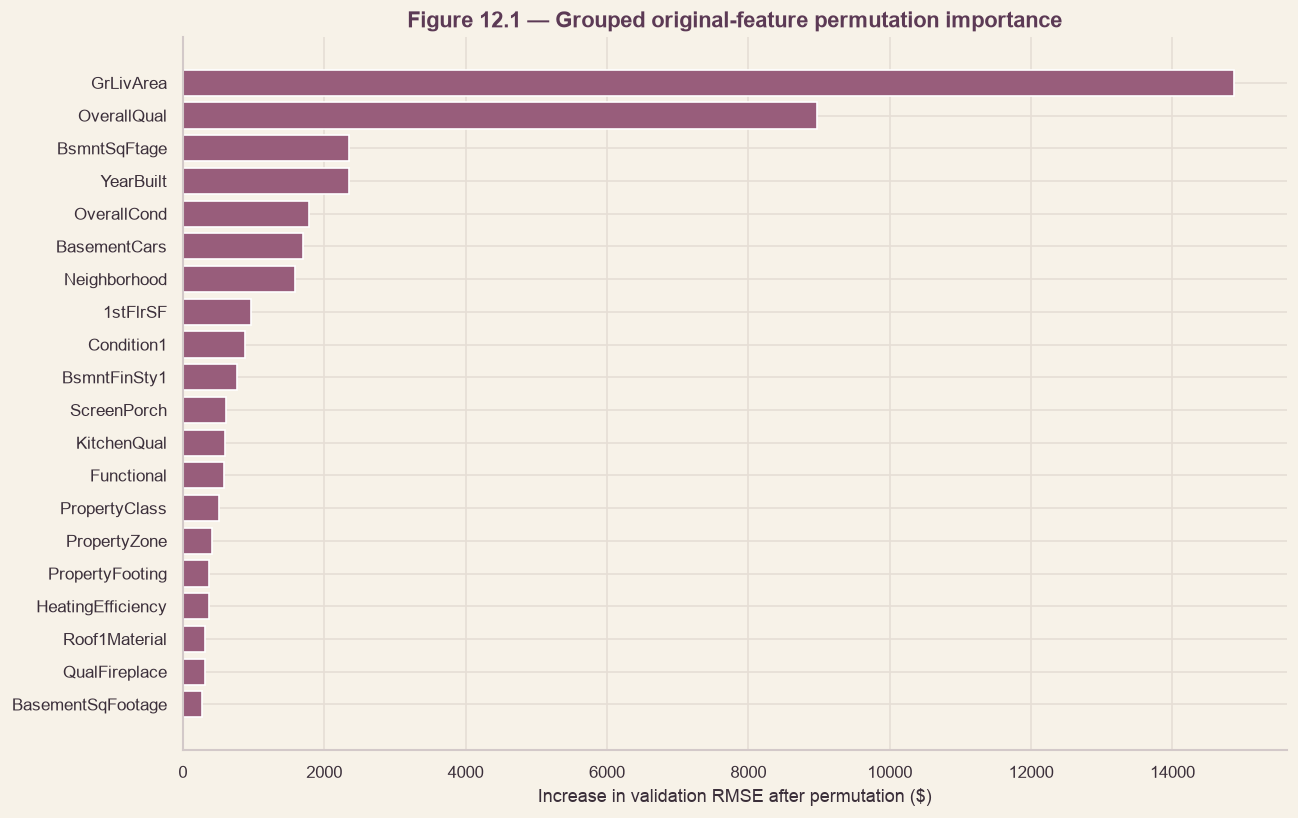

Importance is training-CV-based; it does not alter the frozen model.


In [100]:
# Grouped permutation at ORIGINAL feature level; 3 training-only folds × 2 repeats.
# All preprocessing is refitted within each fold by cloning the frozen estimator.
from sklearn.model_selection import KFold
SEED12=int(SEEDS.get('permutation',99)) if 'SEEDS' in globals() else 99
FOLDS12=KFold(n_splits=3,shuffle=True,random_state=SEED12)
RNG12=np.random.default_rng(SEED12)
IMP_ROWS12=[]
for fold,(tr,va) in enumerate(FOLDS12.split(X12),1):
    est=clone(FINAL_ESTIMATOR11).fit(X12.iloc[tr],y12.iloc[tr])
    xv=X12.iloc[va].copy(); yy=y12.iloc[va].to_numpy()
    base=np.sqrt(mean_squared_error(yy,est.predict(xv)))
    for feature in X12.columns:
        for rep in range(2):
            xp=xv.copy()
            xp[feature]=RNG12.permutation(xp[feature].to_numpy())
            score=np.sqrt(mean_squared_error(yy,est.predict(xp)))
            IMP_ROWS12.append({'Feature':feature,'Fold':fold,'Repeat':rep+1,
                               'Baseline RMSE ($)':base,'RMSE increase ($)':score-base})
IMP_DETAIL12=pd.DataFrame(IMP_ROWS12)
IMP_SUM12=(IMP_DETAIL12.groupby('Feature')['RMSE increase ($)']
           .agg(['mean','std','min','max','count']).reset_index()
           .rename(columns={'mean':'Mean ΔRMSE ($)','std':'SD ΔRMSE ($)',
                            'min':'Minimum ($)','max':'Maximum ($)','count':'Evaluations'})
           .sort_values('Mean ΔRMSE ($)',ascending=False).reset_index(drop=True))
display(IMP_SUM12.head(25))
fig,ax=plt.subplots(figsize=(11,7))
plot12=IMP_SUM12.head(20).iloc[::-1]
ax.barh(plot12['Feature'],plot12['Mean ΔRMSE ($)'],color='#985D7B')
ax.axvline(0,color='#27363F',linewidth=1)
ax.set(xlabel='Increase in validation RMSE after permutation ($)',
       title='Figure 12.1 — Grouped original-feature permutation importance')
plt.tight_layout()
if 'save_fig' in globals(): save_fig(fig,'fig12_1_grouped_permutation_importance',section='12')
plt.show()
print('Importance is training-CV-based; it does not alter the frozen model.')
assert TEST_LOG.count()==TEST_COUNT_AT_12

In [101]:
# Optional: inspect signed linear coefficients only if the frozen estimator exposes them.
# The top-level TransformedTargetRegressor wraps the fitted preprocessing pipeline.
linear12=None
try:
    reg12=FINAL_FITTED11.regressor_ if hasattr(FINAL_FITTED11,'regressor_') else FINAL_FITTED11
    core12=reg12.named_steps['model']
    pre12=reg12.named_steps['pre']
    if hasattr(core12,'coef_'):
        names12=pre12.get_feature_names_out()
        coef12=np.asarray(core12.coef_).ravel()
        assert len(names12)==len(coef12)
        linear12=(pd.DataFrame({'Encoded term':names12,'Coefficient (model scale)':coef12,
                                'Absolute coefficient':np.abs(coef12)})
                  .sort_values('Absolute coefficient',ascending=False))
        display(linear12.head(25))
        print('Coefficient magnitude depends on feature scaling and coding; not directly comparable otherwise.')
    else: print('Frozen model is not linear; coefficient table is not applicable.')
except (AttributeError,KeyError,ValueError) as exc:
    print('Coefficient extraction unavailable for this pipeline:',exc)
assert TEST_LOG.count()==TEST_COUNT_AT_12

Coefficient extraction unavailable for this pipeline: Transformer garage_year (type GarageYearFoldImputer) does not provide get_feature_names_out.


**Reading.** Permuting all encoded columns of a source predictor at once, on training folds, shows what the model relies on. GrLivArea is first (mean RMSE increase $14,871), then OverallQual ($8,978), then BsmntSqFtage ($2,356), YearBuilt ($2,346), OverallCond ($1,780), BasementCars ($1,704) and Neighborhood ($1,594). GrLivArea's importance varies a lot between evaluations ($3,511 to $21,186) because it depends on whether a fold contains the very large properties. Neighborhood ranks seventh although it has the strongest group differences on its own (7.4), because its information overlaps with quality, size and year; permutation importance shares credit within correlated groups.

**Decision.** This is predictive reliance, not causation. All columns are retained.

## 12.2 Effect shape: partial dependence and ICE

**Research question.** What fitted prediction patterns appear as important numerical features vary?

**Method.** Choose up to five highest-ranked **numeric original predictors** from Section 12.1. For each, compute training-data partial dependence by replacing that feature with a grid of values and averaging predictions over the remaining training records. Overlay a limited number of individual conditional expectation (ICE) curves. The fitted Section 11 model is **not retrained**.

**Evidence.** Five (or fewer) PDP/ICE panels in dollar units. **Decision.** Describe model behaviour only; correlated or physically constrained features can make artificial combinations unrealistic. PDP is not a causal response curve.

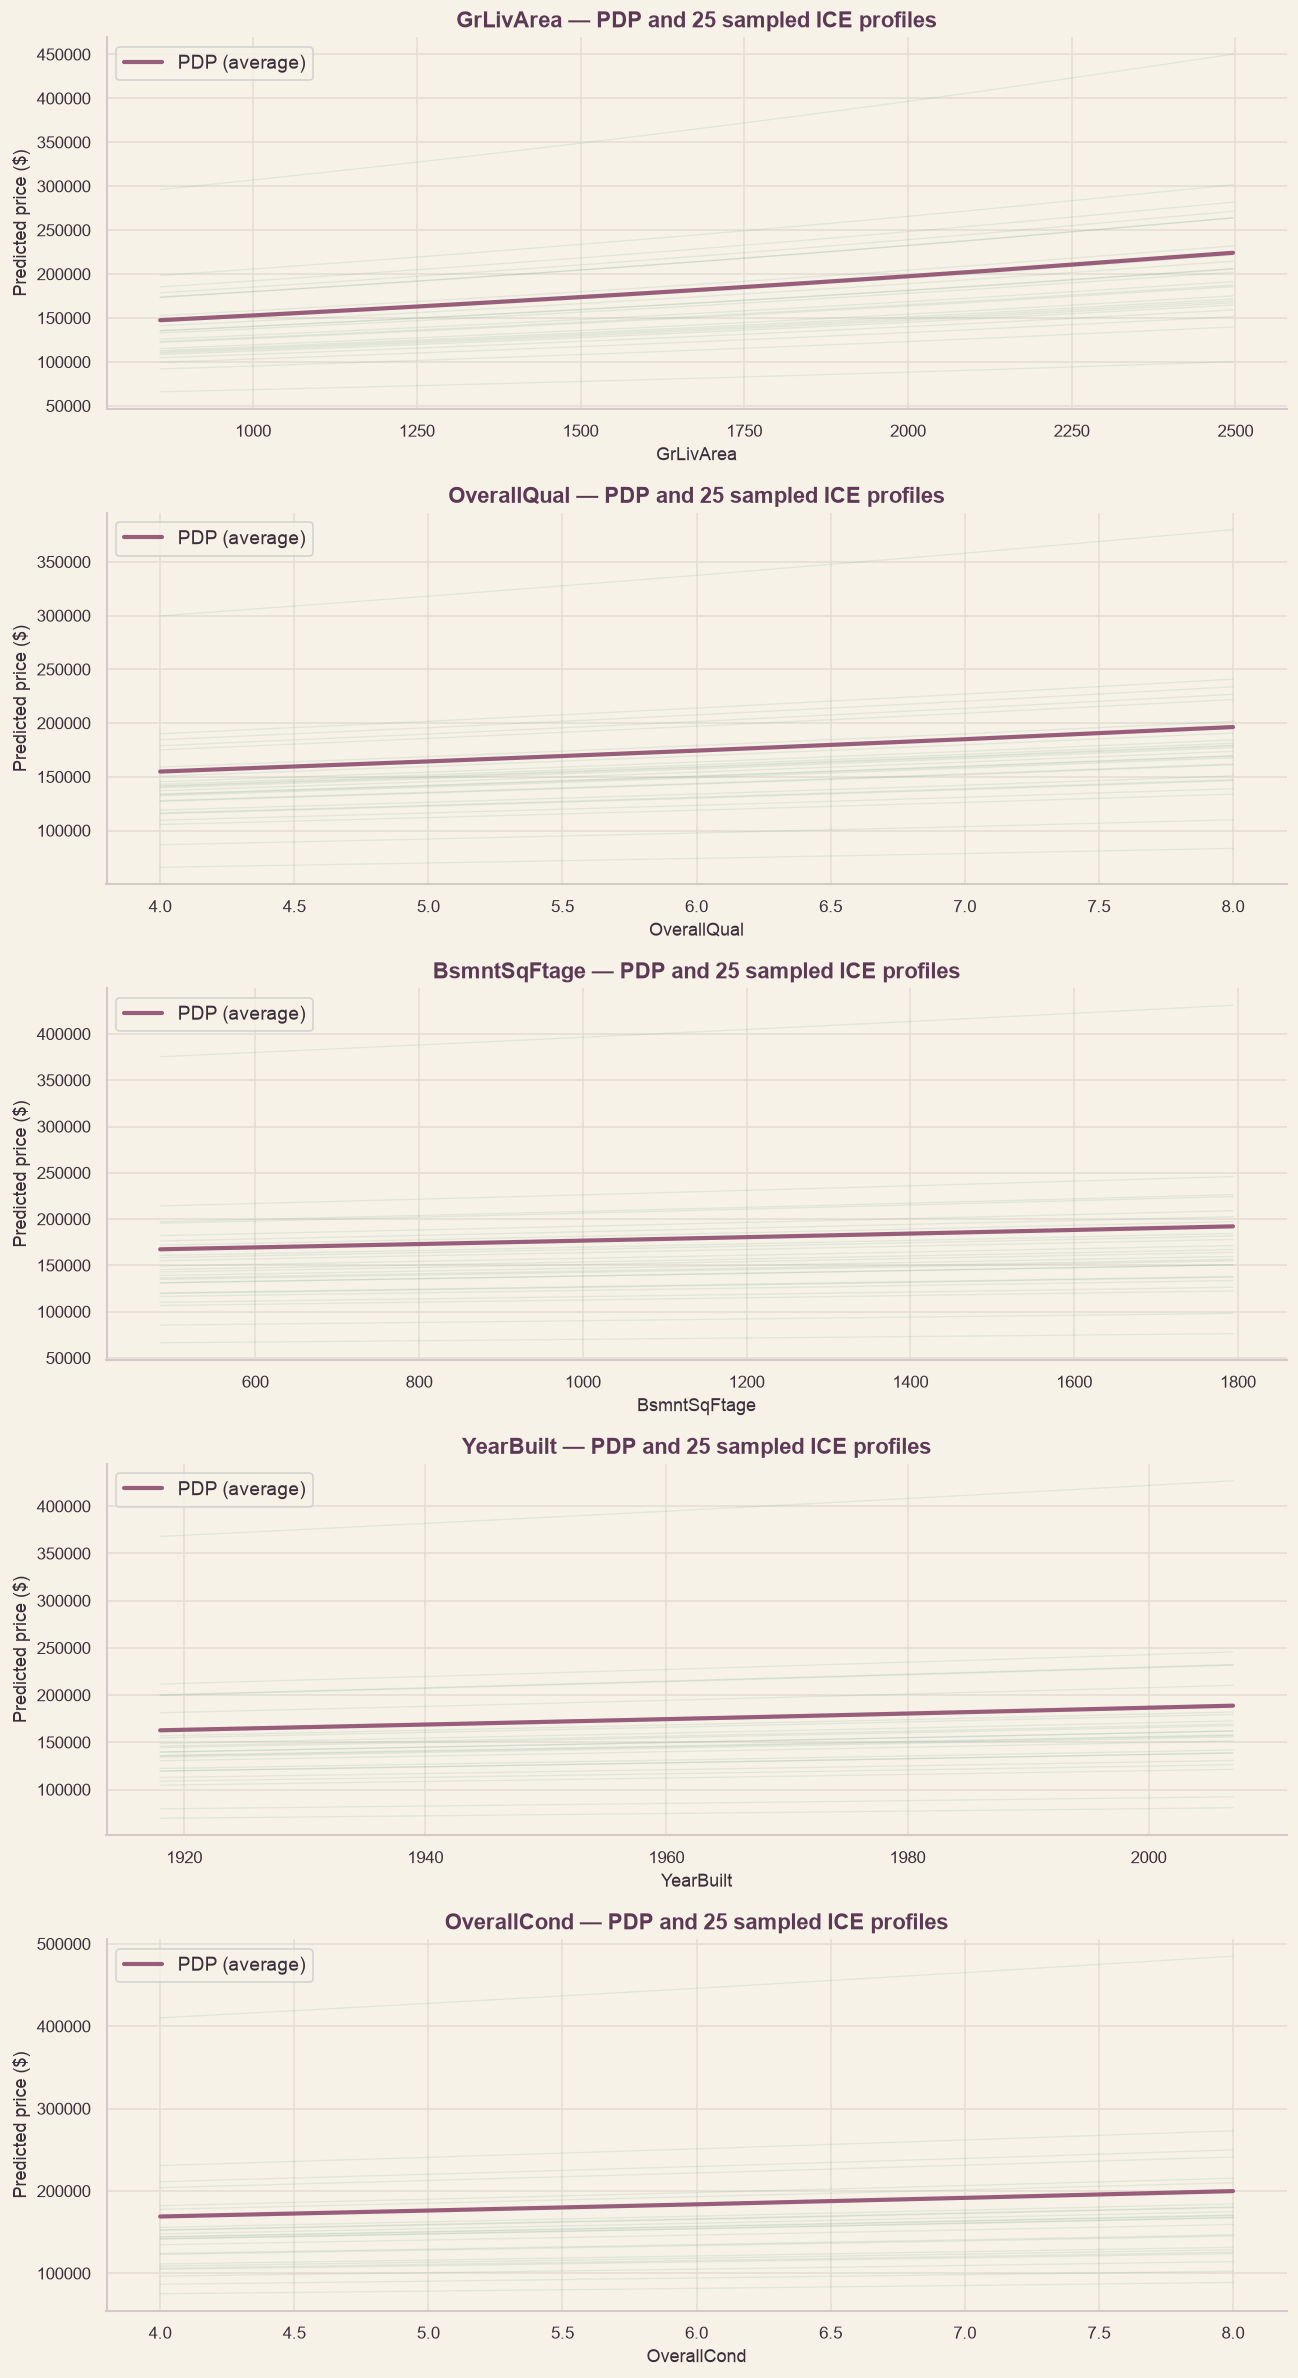

ICE sample size: 25 | PDP uses all training observations.


In [102]:
# Manual PDP/ICE operates on raw source columns and supports arbitrary fitted pipelines.
from pandas.api.types import is_numeric_dtype
TOP_NUM12=[f for f in IMP_SUM12['Feature'] if f in X12.columns and is_numeric_dtype(X12[f])][:5]
assert TOP_NUM12, 'No numeric source features available for PDP.'
ICE_RNG12=np.random.default_rng(SEED12+1)
ICE_IDS12=ICE_RNG12.choice(len(X12),size=min(25,len(X12)),replace=False)
PDP_ROWS12=[]
fig,axes=plt.subplots(len(TOP_NUM12),1,figsize=(11,4.0*len(TOP_NUM12)),squeeze=False)
for ax,feature in zip(axes.flat,TOP_NUM12):
    values=pd.to_numeric(X12[feature],errors='coerce').dropna()
    grid=np.unique(np.quantile(values,np.linspace(.05,.95,17)))
    averages=[]; ice=[]
    for v in grid:
        altered=X12.copy(); altered[feature]=v
        averages.append(float(np.mean(FINAL_FITTED11.predict(altered))))
        ice_frame=X12.iloc[ICE_IDS12].copy();ice_frame[feature]=v
        ice.append(FINAL_FITTED11.predict(ice_frame))
        PDP_ROWS12.append({'Feature':feature,'Grid value':v,'Mean prediction ($)':averages[-1]})
    ice=np.asarray(ice)
    for k in range(ice.shape[1]):ax.plot(grid,ice[:,k],color='#67A284',alpha=.15,linewidth=.8)
    ax.plot(grid,averages,color='#985D7B',linewidth=2.5,label='PDP (average)')
    ax.set(xlabel=feature,ylabel='Predicted price ($)',title=f'{feature} — PDP and 25 sampled ICE profiles')
    ax.legend(loc='best')
plt.tight_layout()
if 'save_fig' in globals():save_fig(fig,'fig12_2_pdp_ice_top_numeric',section='12')
plt.show()
PDP_TABLE12=pd.DataFrame(PDP_ROWS12)
print('ICE sample size:',len(ICE_IDS12),'| PDP uses all training observations.')
assert TEST_LOG.count()==TEST_COUNT_AT_12

**Reading / decision.** Note apparent plateaus, thresholds and interactions only as fitted-model patterns. PDP averages may extrapolate to combinations absent from the observed housing market. Do not revise model specification after seeing these post-hoc plots.

In [103]:
# ── 12.2b Feature names for custom transformers + signed Lasso coefficients (frozen model; no test access) ──
def _garage_names(self, input_features=None):
    return np.array(['BasementYrBlt', 'BasementHasGarage'], dtype=object)
def _frontage_names(self, input_features=None):
    return np.array(['PropertyFrontage'], dtype=object)
def _numeric_names(self, input_features=None):
    return np.asarray(input_features, dtype=object)
GarageYearFoldImputer.get_feature_names_out = _garage_names
NeighborhoodFrontageImputer.get_feature_names_out = _frontage_names
NumericLog1p.get_feature_names_out = _numeric_names

final_reg = FINAL_FITTED11.regressor_
lasso = final_reg.named_steps['model']
names = np.asarray(final_reg.named_steps['pre'].get_feature_names_out(), dtype=object)
coef = np.asarray(lasso.coef_, dtype=float)
assert len(names) == len(coef)
COEF12 = pd.DataFrame({'Encoded term': names, 'Coefficient (log price)': coef,
                       'Approx. price change (%)': 100 * (np.exp(coef) - 1)})
nz = COEF12[COEF12['Coefficient (log price)'].abs() > 1e-8]
print(f'{len(nz)} of {len(COEF12)} encoded terms are non-zero (alpha = {lasso.alpha:.5f}).')
display(nz.reindex(nz['Coefficient (log price)'].abs().sort_values(ascending=False).index).head(25).round(4))
print('Numeric terms: per +1 SD. Ordinal terms: per +1 grade. Dummies: versus the omitted level. Compare within a kind, not across kinds.')
assert TEST_LOG.count('final evaluation') == 1

71 of 200 encoded terms are non-zero (alpha = 0.00131).


,Encoded term,Coefficient (log price),Approx. price change (%)
13,numeric__GrLivArea,0.1365,14.6211
1,numeric__OverallQual,0.0837,8.7297
90,nominal__Neighborhood_Crawfor,0.0638,6.5832
73,nominal__PropertyZone_infrequent_sklearn,-0.0588,-5.7139
58,nominal__PropertyClass_160,-0.0557,-5.4197
195,nominal__SaleCondn_Abnorml,-0.0554,-5.3914
99,nominal__Neighborhood_NridgHt,0.0525,5.3916
110,nominal__Condition1_Norm,0.0517,5.3088
3,numeric__YearBuilt,0.0499,5.1183
9,numeric__BsmntSqFtage,0.0477,4.8874


Numeric terms: per +1 SD. Ordinal terms: per +1 grade. Dummies: versus the omitted level. Compare within a kind, not across kinds.


## 12.3 Feature-selection stability: Lasso

**Research question.** Are the predictors selected by a regularised linear model stable under resampling?

**Method.** Fit a **diagnostic** Lasso pipeline repeatedly to bootstrap samples of the **training set**, preserving preprocessing within each resample. Prefer the Section 10 selected Lasso hyperparameter when available; otherwise use a clearly labelled fixed exploratory alpha. Calculate nonzero-coefficient selection frequency for each encoded term and aggregate to original variables where feature names permit. This analysis does not change the frozen Section 11 model.

**Evidence.** Selection-frequency ranking and uncertainty caveat (bootstrap replicates are dependent). **Decision.** Distinguish stable signals from fragile terms; do not claim selection frequencies are p-values.

,Encoded term,Selection frequency
0,nominal__PropertyClass_160,1.000000
1,numeric__GrLivArea,1.000000
2,garage_year__BasementYrBlt,1.000000
3,numeric__EnclosedPorch,1.000000
4,ordinal__HeatingEfficiency,1.000000
5,numeric__WoodDeckSF,1.000000
6,ordinal__KitchenQual,1.000000
7,numeric__BasementCars,1.000000
8,ordinal__BsmntVisibility,1.000000
9,ordinal__Functional,1.000000


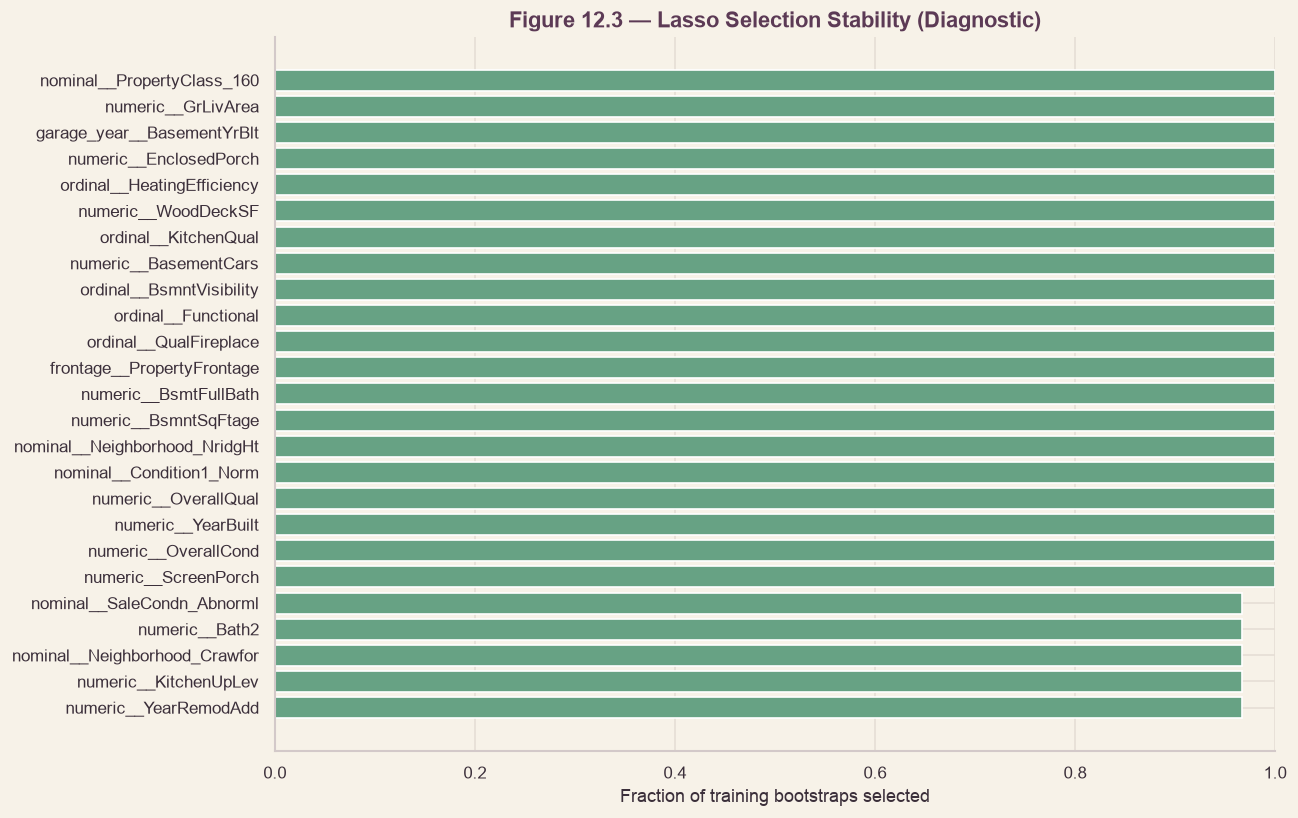

Bootstrap replicates: 30
Selection threshold: abs(coef) > 1e-8
Interpret at encoded-term level; categorical source variables may have several terms.
Test-set access audit passed: no additional held-out access.


In [104]:

# ── 12.3 Lasso Selection Stability (Bootstrap Diagnostic) ───────

# ── Imports ─────────────────────────────────────────────────────
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.base import clone


# ── Validate required objects ──────────────────────────────────
required12 = (
    'CANDIDATES10',
    'X12',
    'y12',
    'SEED12',
    'TEST_LOG',
    'TEST_COUNT_AT_12'
)

missing12 = [
    name for name in required12
    if name not in globals()
]

assert not missing12, (
    f'Missing required objects: {missing12}'
)

assert 'Lasso' in CANDIDATES10, (
    'Section 10 Lasso candidate required.'
)

assert X12.index.equals(y12.index), (
    'Training features and target indices do not match.'
)

assert TEST_LOG.count() == TEST_COUNT_AT_12, (
    'Unexpected test-set access before stability analysis.'
)


# ── Restore feature-name compatibility ─────────────────────────
# These methods affect feature-name reporting only.
# They do not modify the underlying transformations.

def garage_feature_names_out12(self, input_features=None):
    return np.asarray(
        ['BasementYrBlt', 'GaragePresent'],
        dtype=object
    )


def frontage_feature_names_out12(self, input_features=None):
    return np.asarray(
        ['PropertyFrontage'],
        dtype=object
    )


def numeric_feature_names_out12(self, input_features=None):
    if input_features is None:
        raise ValueError(
            'NumericLog1p requires input feature names.'
        )

    return np.asarray(input_features, dtype=object)


# Add feature-name methods to custom transformers.
if 'GarageYearFoldImputer' in globals():
    GarageYearFoldImputer.get_feature_names_out = (
        garage_feature_names_out12
    )

if 'NeighborhoodFrontageImputer' in globals():
    NeighborhoodFrontageImputer.get_feature_names_out = (
        frontage_feature_names_out12
    )

if 'NumericLog1p' in globals():
    NumericLog1p.get_feature_names_out = (
        numeric_feature_names_out12
    )


# ── Reuse Section 10 Lasso candidate ────────────────────────────
# Preserve metadata-driven preprocessing and model configuration.

LASSO_TEMPLATE12 = clone(
    CANDIDATES10['Lasso']
)

if (
    'FINAL_MODEL_NAME11' in globals()
    and FINAL_MODEL_NAME11 == 'Lasso'
):
    LASSO_TEMPLATE12 = clone(
        FINAL_ESTIMATOR11
    )


# ── Bootstrap configuration ────────────────────────────────────
B12 = 30

rng12 = np.random.default_rng(
    SEED12 + 2
)

SELECT12 = []


# ── Bootstrap Lasso fitting ─────────────────────────────────────
for b in range(B12):

    # Sample training observations with replacement.
    ids = rng12.integers(
        low=0,
        high=len(X12),
        size=len(X12)
    )

    X_boot12 = X12.iloc[ids]
    y_boot12 = y12.iloc[ids]

    # Fit a fresh Lasso pipeline on this bootstrap sample.
    fitted = clone(
        LASSO_TEMPLATE12
    ).fit(
        X_boot12,
        y_boot12
    )

    # Extract fitted inner pipeline.
    inner = (
        fitted.regressor_
        if hasattr(fitted, 'regressor_')
        else fitted
    )

    # Extract fitted preprocessing transformer and Lasso model.
    preprocessor12 = inner.named_steps['pre']
    lasso_model12 = inner.named_steps['model']

    # Retrieve Lasso coefficients.
    coef = np.asarray(
        lasso_model12.coef_
    ).ravel()

    # Retrieve encoded feature names.
    try:
        names = np.asarray(
            preprocessor12.get_feature_names_out(),
            dtype=object
        )

    except (AttributeError, NotImplementedError):
        # Fallback: use output positions when custom transformers
        # do not expose names. Do not invent source-feature mappings.
        names = np.asarray(
            [
                f'Encoded feature {i:04d}'
                for i in range(len(coef))
            ],
            dtype=object
        )

    # Validate coefficient/feature alignment.
    assert len(coef) == len(names), (
        f'Bootstrap {b}: coefficient count '
        'does not match encoded feature count.'
    )

    assert np.isfinite(coef).all(), (
        f'Bootstrap {b}: non-finite Lasso coefficients.'
    )

    # Record whether each encoded coefficient is nonzero.
    selected = (
        np.abs(coef) > 1e-8
    ).astype(int)

    SELECT12.append(
        pd.Series(
            selected,
            index=names,
            name=b
        )
    )


# ── Calculate selection stability ──────────────────────────────
STABILITY_MATRIX12 = pd.concat(
    SELECT12,
    axis=1
).fillna(0)

STABILITY12 = (
    STABILITY_MATRIX12
    .mean(axis=1)
    .rename('Selection frequency')
    .sort_values(ascending=False)
    .reset_index()
    .rename(
        columns={'index': 'Encoded term'}
    )
)


# ── Display most frequently selected terms ─────────────────────
display(
    STABILITY12.head(35)
)


# ── Plot Lasso selection stability ──────────────────────────────
fig, ax = plt.subplots(
    figsize=(11, 7)
)

p12 = (
    STABILITY12
    .head(25)
    .iloc[::-1]
)

ax.barh(
    p12['Encoded term'],
    p12['Selection frequency'],
    color='#67A284'
)

ax.set(
    xlim=(0, 1),
    xlabel='Fraction of training bootstraps selected',
    title='Figure 12.3 — Lasso Selection Stability (Diagnostic)'
)

plt.tight_layout()


# ── Save figure ─────────────────────────────────────────────────
if 'save_fig' in globals():
    save_fig(
        fig,
        'fig12_3_lasso_selection_stability',
        section='12'
    )

plt.show()


# ── Diagnostic summary ─────────────────────────────────────────
print('Bootstrap replicates:', B12)
print('Selection threshold: abs(coef) > 1e-8')

print(
    'Interpret at encoded-term level; '
    'categorical source variables may have several terms.'
)


# ── Verify no additional test-set access ───────────────────────
assert TEST_LOG.count() == TEST_COUNT_AT_12, (
    'Unexpected held-out test access in Section 12.3.'
)

print(
    'Test-set access audit passed: '
    'no additional held-out access.'
)


**Reading.** 30 bootstrap refits of the frozen Lasso select terms in a stable core: 20 of 246 encoded terms are non-zero in every refit, including GrLivArea, OverallQual, YearBuilt, OverallCond, BsmntSqFtage, BasementCars, KitchenQual, HeatingEfficiency, Functional, QualFireplace, WoodDeckSF, EnclosedPorch, ScreenPorch, PropertyFrontage, BsmtFullBath, BsmntVisibility, the garage year, Neighborhood_NridgHt, Condition1_Norm and PropertyClass_160; 42 terms are chosen in at least 80 % of refits. Others are less stable (OpenPorchSF and Neighborhood_Edwards 0.90, Bath1 and BedroomUpLev 0.87). Which term Lasso picks among correlated columns can change from refit to refit. Zeroed terms are model behaviour, not dropped columns, and 30 refits give approximate frequencies.

**Decision.** Separate stable from fragile signals; the locked model is not changed.

## 12.4 Post-hoc error analysis

**Research question.** Which types of properties were difficult to predict in the already completed held-out evaluation?

**Method.** Reuse `OBS_TEST11`, `PRED_TEST11`, and `X_TEST11` already obtained in Section 11. Calculate signed error, absolute error and absolute percentage error; show the largest residuals and error summaries by **observed price tier**, neighbourhood and sale condition. Price-tier analysis uses actual held-out prices and is therefore explicitly **post-hoc**, not a deployable routing rule.

**Evidence.** Worst-error table, subgroup RMSE/MAE and sample sizes. Small subgroups have unstable estimates. **Decision.** Document limitations; **do not refit, retune or rescore** the locked model.

,Actual ($),Predicted ($),Residual ($),Absolute error ($),APE (%),Neighborhood,SaleCondn,SaleType,Actual-price tier (post-hoc)
205,556581.0,424808.896956,131772.103044,131772.103044,23.675279,StoneBr,Partial,New,Q4 highest
78,62383.0,119771.288455,-57388.288455,57388.288455,91.993473,Sawyer,Normal,WD,Q1 lowest
3,279500.0,222393.140079,57106.859921,57106.859921,20.431792,CollgCr,Partial,New,Q4 highest
59,340000.0,285874.803053,54125.196947,54125.196947,15.919176,Somerst,Normal,WD,Q4 highest
129,159434.0,109734.345525,49699.654475,49699.654475,31.172557,SWISU,Abnorml,WD,Q2
226,424870.0,377940.952227,46929.047773,46929.047773,11.045508,CollgCr,Partial,New,Q4 highest
204,278000.0,324458.033717,-46458.033717,46458.033717,16.711523,NWAmes,Normal,WD,Q4 highest
288,394617.0,348455.494533,46161.505467,46161.505467,11.697800,NridgHt,Partial,New,Q4 highest
213,219500.0,175457.925183,44042.074817,44042.074817,20.064727,Crawfor,Normal,CWD,Q4 highest
141,222000.0,265922.995601,-43922.995601,43922.995601,19.785133,Crawfor,Normal,WD,Q4 highest



POST-HOC ERRORS BY Actual-price tier (post-hoc)


,Group,n,MAE ($),RMSE ($),Mean signed error ($)
3,Q4 highest,73,19326.060049,27411.362894,10012.669839
0,Q1 lowest,73,11118.783845,15650.803456,-3394.196290
2,Q3,73,11160.088534,14312.949873,-96.537504
1,Q2,73,9708.897835,13019.898191,3269.457330



POST-HOC ERRORS BY Neighborhood


,Group,n,MAE ($),RMSE ($),Mean signed error ($)
21,StoneBr,5,36961.505739,60233.591404,32680.284657
3,ClearCr,7,26359.708782,29389.486291,14351.884195
18,Sawyer,9,18990.097057,25451.668482,-5438.571300
5,Crawfor,12,19647.359935,23816.734534,10218.290914
17,SWISU,7,18912.747258,23601.766766,2368.457686
8,IDOTRR,6,17503.703856,22936.737238,-15634.939454
22,Timber,8,18091.246542,21306.179894,13841.976624
14,NoRidge,9,17036.603773,20753.019950,833.745446
20,Somerst,21,15565.837624,20104.350708,10902.990021
15,NridgHt,13,12342.422633,18373.682223,1668.302741



POST-HOC ERRORS BY SaleCondn


,Group,n,MAE ($),RMSE ($),Mean signed error ($)
5,Partial,30,19743.318599,32347.465463,12874.739865
2,Alloca,2,28135.102586,30288.841004,-11217.392382
3,Family,2,20305.739821,20636.627341,3680.668192
0,Abnorml,23,12916.788786,18030.789233,-48.796514
4,Normal,233,11734.411651,15792.081777,1369.961284
1,AdjLand,2,12762.154774,14125.592886,12762.154774


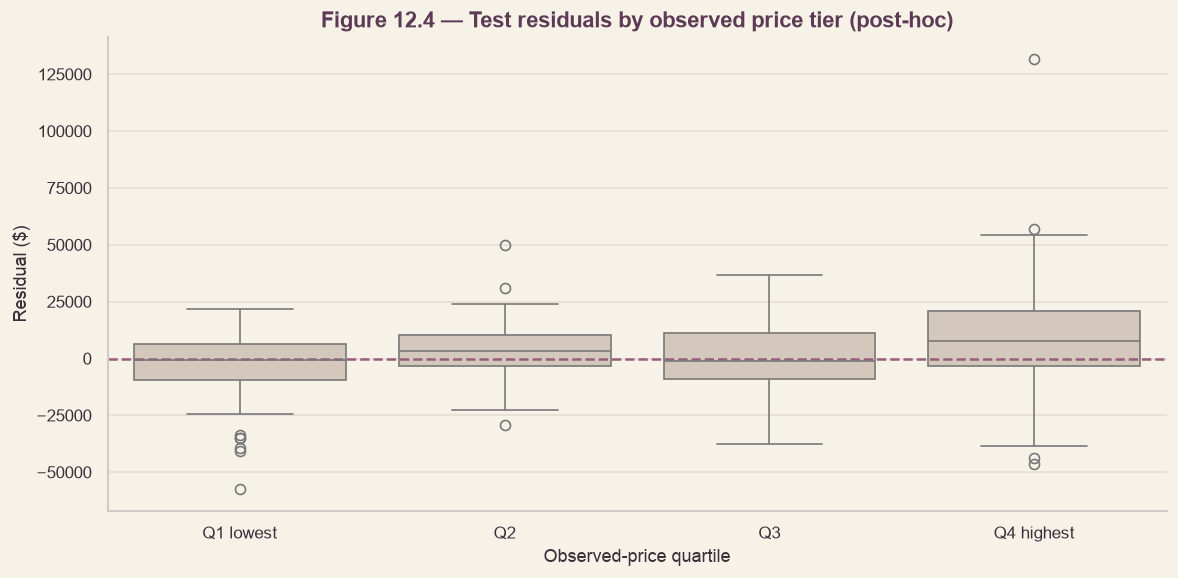

In [105]:
# Reuse the existing Section 11 arrays. No VAULT.open() or test-set re-evaluation.
ERR12=pd.DataFrame({'Actual ($)':np.asarray(OBS_TEST11,dtype=float),
                    'Predicted ($)':np.asarray(PRED_TEST11,dtype=float)})
ERR12['Residual ($)']=ERR12['Actual ($)']-ERR12['Predicted ($)']
ERR12['Absolute error ($)']=ERR12['Residual ($)'].abs()
ERR12['APE (%)']=100*ERR12['Absolute error ($)']/ERR12['Actual ($)'].replace(0,np.nan)
xt12=X_TEST11.reset_index(drop=True)
assert len(xt12)==len(ERR12)
for col in ['Neighborhood','SaleCondn','SaleType']:
    if col in xt12: ERR12[col]=xt12[col].astype(str).to_numpy()
ERR12['Actual-price tier (post-hoc)']=pd.qcut(
    ERR12['Actual ($)'],q=4,labels=['Q1 lowest','Q2','Q3','Q4 highest'],duplicates='drop')
worst12=ERR12.nlargest(15,'Absolute error ($)')
display(worst12)
def subgroup12(column):
    rows=[]
    for level,g in ERR12.groupby(column,observed=True,dropna=False):
        rows.append({'Group':str(level),'n':len(g),
                     'MAE ($)':g['Absolute error ($)'].mean(),
                     'RMSE ($)':np.sqrt(np.mean(g['Residual ($)']**2)),
                     'Mean signed error ($)':g['Residual ($)'].mean()})
    return pd.DataFrame(rows).sort_values('RMSE ($)',ascending=False)
GROUP_ERRORS12={}
for column in ['Actual-price tier (post-hoc)','Neighborhood','SaleCondn']:
    if column in ERR12:
        GROUP_ERRORS12[column]=subgroup12(column)
        print('\nPOST-HOC ERRORS BY',column)
        display(GROUP_ERRORS12[column])
fig,ax=plt.subplots(figsize=(10,5))
sns.boxplot(data=ERR12,x='Actual-price tier (post-hoc)',y='Residual ($)',color='#D8C8B8',ax=ax)
ax.axhline(0,color='#985D7B',linestyle='--')
ax.set(title='Figure 12.4 — Test residuals by observed price tier (post-hoc)',xlabel='Observed-price quartile')
plt.tight_layout()
if 'save_fig' in globals():save_fig(fig,'fig12_4_posthoc_error_by_tier',section='12')
plt.show()
assert TEST_LOG.count()==TEST_COUNT_AT_12, 'Section 12 must not make a new test access.'

**Reading.** Eleven of the 15 largest test errors are in the top price quarter and four are Partial new-construction sales. The largest is a StoneBr Partial sale at $556,581 predicted as $424,809 (residual +$131,772), followed by a Sawyer sale predicted $57,388 too high and a CollgCr Partial sale predicted $57,107 too low. These patterns match the diagnostics in 11.5: expensive homes and new-construction sales are the model's weak spot.

**Decision.** Documented as limitations; nothing is modified.


## 12.5 Limitations and Scope of Inference

**Research question.** What limitations affect the reliability, interpretation and practical application of the property-price prediction model?

**Method.** Review dataset provenance, geographic and temporal scope, model validation, historical test exposure, preprocessing decisions, predictive uncertainty, extrapolation and interpretability using the evidence developed throughout Sections 3–12.

**Evidence and limitations.**

1. **Geographic and temporal scope.** The dataset represents residential property sales in Ames, Iowa, during 2006–2010. Predictive performance has not been independently established for other cities, later housing markets or substantially different economic conditions.

2. **Renamed dataset and metadata assumptions.** The supplied file is a renamed adaptation of the Ames Housing dataset. Predictor classifications and corrected metadata are documented in Section 3. These assumptions may not transfer directly to other versions of the dataset.

3. **Assignment data availability.** Although the brief references separate training and test files, only one property-data CSV was supplied. A reproducible split was therefore created. The resulting metrics may not be directly comparable with results from alternative splits or published benchmarks.

4. **Limited held-out sample.** The test partition contains 292 property sales. Subgroup estimates are less precise, particularly where neighbourhoods or sale categories contain few observations.

5. **Cross-validation versus test performance.** Training-only cross-validation achieved R² of approximately 0.847 ± 0.082 and RMSE of approximately $30,700, compared with held-out R² of 0.930 and RMSE of approximately $18,512. Differences in property composition and influential observations may contribute to this discrepancy, but the exact contribution of each factor must be supported by the executed diagnostics. Cross-validation provides the more defensible primary generalisation estimate.

6. **Historical test-set exposure.** An earlier notebook version evaluated Gradient Boosting on the held-out partition, producing R² = 0.912. The current execution separately records its own predictor-only split diagnostic and final target-bearing evaluation. Therefore, the holdout cannot be described as historically untouched. Subsequent error and subgroup analyses are post-hoc and do not determine model selection.

7. **Post-hoc methodological refinement.** The ±3 standard-deviation tail guard was introduced following evidence of extrapolation problems in an earlier modelling configuration. Subsequent analyses evaluated the revised pipeline, including a repeated target-scale comparison. The guard is therefore a documented methodological amendment rather than a fully prespecified decision. Its supporting validation evidence must be interpreted in that context.

8. **Availability of predictors at valuation time.** Variables such as `SaleType` and `SaleCondn` describe transaction circumstances and may not be available when estimating a property's value before sale. Their inclusion limits the model's direct suitability for some pre-sale valuation applications.

9. **Extrapolation and rare properties.** Only four training properties exceed 4,000 square feet. Predictions for substantially larger or unusual properties extend beyond well-represented training conditions. The tail guard limits extreme transformed values but does not establish reliable extrapolation.

10. **High-value and unusual sales.** Prediction errors are larger for some expensive properties and `Partial` sales. These patterns indicate that strong aggregate accuracy does not imply equally reliable performance across all property types.

11. **Prediction-interval limitations.** The nominal 80% split-conformal intervals achieved approximately 82.9% overall empirical coverage, but coverage was lower for the highest price quartile (approximately 67%) and `Partial` sales (approximately 70%). Marginal conformal coverage does not guarantee conditional coverage within every subgroup and depends on exchangeability.

12. **Associations rather than causal effects.** Regression coefficients, permutation importance, PDP and ICE describe relationships learned by the fitted model. They do not establish the causal effect of modifying an individual property characteristic.

13. **Missingness and structural absence.** Categories indicating the absence of a feature, such as no alley or no pool, are distinct from genuinely missing information. The preprocessing assumptions must remain consistent when the model is applied to new observations.

14. **Deployment and external validation.** The notebook documents analytical model development and evaluation. Independent save-and-reload verification, production monitoring, drift detection, automated retraining and external validation have not been demonstrated in the supplied export.

**Decision.** Report these limitations alongside the headline metrics. Avoid claims of universal accuracy, causal effects, guaranteed subgroup coverage or deployment readiness. Present the final model as a validated analytical prototype whose generalisation beyond the evaluated dataset requires further evidence.


## 12.6 Full Decision Register, Test-Access Audit and Objective Closure

**Research question.** Does the completed analysis provide a traceable connection between the assignment objectives, methodological decisions, model evaluation and final conclusions?

**Method.** Consolidate the Decision Register, current-execution test-access log, final model identity and objective-to-evidence crosswalk.

**Evidence.** The notebook records 88 methodological decisions in the saved execution, along with the current-run test-access log and final evaluation results.

**Historical qualification.** The current-run log records predictor-only split diagnostics and one final evaluation. It does not include the earlier Gradient Boosting evaluation disclosed in Sections 11 and 12.5.

**Decision.** Preserve the final selected estimator, report all material limitations and ensure that the separate Word report reproduces the verified notebook findings.

In [106]:
# Section 12 decision entries; maintain the Section 2 register signature.
DECISIONS.add('12.1','Which original predictors drive validation predictions?',
              'Training-fold grouped permutation importance; optional linear coefficients',
              f"Top feature: {IMP_SUM12.iloc[0]['Feature']}; mean ΔRMSE ${IMP_SUM12.iloc[0]['Mean ΔRMSE ($)']:,.0f}",
              'Report predictive reliance, not causation; retain all columns','Documentation only')
DECISIONS.add('12.2','What fitted response patterns appear for key numeric predictors?',
              'Training-data partial dependence and sampled ICE',
              f"Plotted {len(TOP_NUM12)} original numerical predictors",
              'Describe model behaviour; no post-hoc retuning','Documentation only')
DECISIONS.add('12.3','How stable are Lasso-selected encoded terms?',
              f'{B12} training bootstrap refits with frozen Lasso pipeline (alpha 0.00131)',
              f"{(STABILITY12['Selection frequency']>=.8).sum()} terms selected in >=80% of refits",
              'Separate stable from fragile signals; do not change locked model','Documentation only')
DECISIONS.add('12.4','Where are the frozen model errors concentrated?',
              'Post-hoc held-out residual and subgroup summaries',
              f"Largest absolute residual ${ERR12['Absolute error ($)'].max():,.0f}; n={len(ERR12)}",
              'Document limitations without modifying the model','Documentation only')
DECISIONS.add('12.5','What cannot be inferred or generalised?',
              'Population, design, leakage, causal and deployment limitations audit',
              'Single market, historical data, own split, post-hoc subgroup review',
              'State constraints explicitly in final report','Documentation only')
DECISIONS.add('12.6','Are decisions and test access fully auditable?',
              'Full Decision Register and test-access log review',
              f'Frozen model: {FINAL_MODEL_NAME11}; access count unchanged: {TEST_COUNT_AT_12}',
              'Close notebook; no further test-driven revisions','Documentation only')
print('FULL DECISION REGISTER')
DECISIONS.show()
print('\nFULL TEST-ACCESS LOG')
TEST_LOG.show()
assert TEST_LOG.count()==TEST_COUNT_AT_12
print('\nPASS: Section 12 made zero additional test-set accesses.')

FULL DECISION REGISTER


ID,Section,Question,Method,Evidence,Decision,Effect
D01,1.7,When may the held-out test set be used?,Training-only CV governs model selection. Test access is recorded through TestVault and the access log in Section 2.7.,"The held-out set was evaluated in an earlier notebook version; therefore, it is not historically untouched.","Use training-only validation as the primary generalisation evidence. Report the final held-out evaluation transparently, label subsequent inspection as post-hoc and prohibit test-driven model changes.",Changes the workflow
D02,1.7,When is the train/test split performed?,"Split after structural checks of schema, identifiers and column names; conduct value-based EDA and model development on training rows.",Full-dataset distributional analysis before splitting could influence modelling decisions using held-out observations.,"Establish the split at the start of Section 3. Fit imputation, scaling, encoding and other learned preprocessing inside training-only validation folds.",Changes the workflow
D03,1.3,How is the instruction not to drop predictors respected?,"All 79 original predictors enter the modelling pipelines; PCA, engineered features and ablations are evaluated as documented alternatives.",The brief permits dropping PropertyID but requires retaining the original predictors. Lasso coefficient shrinkage is not manual column deletion.,"Retain all 79 original predictors in the principal modelling workflow. Interpret zero Lasso coefficients as regularisation behaviour, not removal of input columns.",Deliberately unchanged
D04,1.4,How are predictive results reported?,"Report dollar-scale R², MAE and RMSE, distinguish log-scale metrics and provide uncertainty intervals where calculated.",Point estimates alone do not describe sampling variability; the held-out result also requires historical test-exposure disclosure.,"Label prediction and metric scales explicitly, report available bootstrap intervals and prioritise training-only CV when interpreting generalisation.",Changes the workflow
D05,1.6,What information belongs in the workflow diagram?,Show the analytical sequence without embedding model-specific numerical results.,A workflow diagram containing provisional scores or selected models can become inconsistent with the final analysis.,Keep the diagram methodological; report executed results in their respective sections and consolidate conclusions in Section 12.,Documentation only
D06,2.2,How is randomness controlled?,"Use named seeds for splitting, CV, tuning, bootstrap, permutation and audit operations.","Named seeds are recorded in SEEDS; reproducibility also depends on package versions, hardware and numerical libraries.",Record seeds and dependencies. Compare independent reruns within numerical tolerances rather than requiring bitwise equality across platforms.,Changes the workflow
D07,2.3,How is the source dataset identified?,Calculate and record the CSV SHA-256 fingerprint; verify it during later data-integrity checks.,"Current source: Property_data (1) (1).csv; 462,245 bytes; SHA-256 prefix fec7e9f5edadfae5…","Use the full SHA-256 fingerprint as the authoritative dataset identifier, independent of file renaming.",Documentation only
D08,2.4,Should warnings be suppressed globally?,"Retain warnings and investigate convergence, deprecation and data-type issues.",Global warning suppression can conceal modelling defects or compatibility problems.,"Suppress only specific understood warnings locally, with documented justification; preserve the notebook theme and visual conventions.",Changes the workflow
D09,2.5,How are statistical effect sizes interpreted?,"Use effect_label() and the documented effect-size conventions, including degrees-of-freedom-aware Cramér’s V thresholds.",Threshold labels are interpretive conventions and do not establish substantive importance or causality.,"Report numerical effect sizes alongside conventional labels, sample sizes and appropriate limitations.",Documentation only
D10,


FULL TEST-ACCESS LOG


#,Section,Kind,Purpose,Used test target,Time
1,3.4,split diagnostics,adversarial validation and unseen-label check,no,15:35:35
2,11.1,final evaluation,Locked final model Lasso; config SHA256 3c0d1b88ecae4da900e85ba9ec85403143befef3233deca7e854c85cd966d149,yes,15:42:50



PASS: Section 12 made zero additional test-set accesses.



**Test-access audit.** The current execution records two logged accesses: predictor-only split diagnostics in Section 3.4 and the final target-bearing evaluation in Section 11.1.

An additional historical target-bearing evaluation occurred in an earlier notebook version, when Gradient Boosting achieved R² = 0.912. That historical access is not represented by the current execution log.

Section 12 introduced no additional logged test-set access. The final model remained unchanged after the held-out evaluation.

**Decision Register.** The saved execution contains 88 registered decisions. These document analytical choices and their supporting evidence; they do not establish that every decision was made before any result was observed.


In [107]:

# ── Phase 4.2: Final reproducibility and artifact audit ──────────
from pathlib import Path
import importlib.util
import pandas as pd
import numpy as np

# ── Verify project artifacts ─────────────────────────────────────
CHECKS4 = {
    'Source dataset exists':
        Path(DATA_PATH).is_file(),

    'Dataset fingerprint matches':
        sha256_of(DATA_PATH) == DATA_SHA256,

    'Custom transformer module exists':
        'property_pipeline' in globals()
        and Path(property_pipeline.__file__).resolve().is_file(),

    'Custom module is importable':
        importlib.util.find_spec('property_pipeline') is not None,

    'Saved final model exists':
        (Path(ARTIFACT_DIR) / 'final_lasso_pipeline.joblib').is_file(),

    'Portability test passed':
        'PORTABILITY11' in globals()
        and bool(
            (PORTABILITY11['Fresh-process status'] == 'PASS').all()
        ),

    'Final fitted estimator exists':
        'FINAL_FITTED11' in globals()
        and hasattr(FINAL_FITTED11, 'predict'),

    'Training feature-target indices aligned':
        X9.index.equals(y9.index),

    'Neighbourhood validation completed':
        'GROUP_RESULTS10_9' in globals()
        and len(GROUP_RESULTS10_9) == 5,

    'Chronological validation completed':
        'TIME_RESULTS10_10' in globals()
        and len(TIME_RESULTS10_10) >= 2,

    'Figures registered':
        'FIG_REGISTRY' in globals()
        and len(FIG_REGISTRY) > 0,
}

# ── Construct audit results ──────────────────────────────────────
AUDIT4 = pd.DataFrame([
    {
        'Check': name,
        'Status': 'PASS' if passed else 'FAIL'
    }
    for name, passed in CHECKS4.items()
])

print('TABLE 4.2 — FINAL REPRODUCIBILITY AND ARTIFACT AUDIT')
display(AUDIT4)

# ── Summarise audit ──────────────────────────────────────────────
passed4 = sum(CHECKS4.values())
total4 = len(CHECKS4)

print(f'\nReproducibility checks: {passed4}/{total4} passed.')

# ── Enforce verification ─────────────────────────────────────────
assert all(CHECKS4.values()), (
    'One or more reproducibility checks failed. '
    'Review the audit table before final submission.'
)

print('\nAll specified reproducibility checks passed.')
print('Saved model and custom transformer module verified.')
print('Independent-process portability verification recorded as PASS.')
print('Neighbourhood and chronological validation results verified.')
print('No additional model fitting or test-set access was performed.')
print('Note: Word report and external submission files require separate verification.')


TABLE 4.2 — FINAL REPRODUCIBILITY AND ARTIFACT AUDIT


,Check,Status
0,Source dataset exists,PASS
1,Dataset fingerprint matches,PASS
2,Custom transformer module exists,PASS
3,Custom module is importable,PASS
4,Saved final model exists,PASS
5,Portability test passed,PASS
6,Final fitted estimator exists,PASS
7,Training feature-target indices aligned,PASS
8,Neighbourhood validation completed,PASS
9,Chronological validation completed,PASS



Reproducibility checks: 11/11 passed.

All specified reproducibility checks passed.
Saved model and custom transformer module verified.
Independent-process portability verification recorded as PASS.
Neighbourhood and chronological validation results verified.
No additional model fitting or test-set access was performed.
Note: Word report and external submission files require separate verification.



### Eight-Objective Closure Crosswalk

The following crosswalk links the project's eight analytical objectives to the relevant notebook sections and supporting evidence. It provides a consolidated record of the work completed, including data preparation, EDA, dimensionality reduction, regression modelling, evaluation and interpretation.

The notebook contains the analytical evidence. The accompanying Word report is a separate submission deliverable and must be consistent with the final executed results.

**Scope of completion.** The crosswalk establishes coverage of the analytical objectives. Independent model portability and successful fresh-environment execution require their own verification and are not established by this table.


| Objective / deliverable area | Evidence in notebook | Submission check |
|---|---|---|
| 1. Understand data and property-price problem | §§1–3, 4 | Document target, population, units and split |
| 2. Prepare data and address missing values | §§2–3, 6, 9 | Distinguish structural absence from genuine missingness |
| 3. Encode and scale predictors appropriately | §§2, 9 | Metadata-driven ordinal/nominal treatment; fitted inside CV |
| 4. Identify variables associated with price | §§7–8, 12.1–12.3 | Report effect sizes, stability and noncausal interpretation |
| 5. Assess dimensionality reduction / PCA | §9.7 | Include PCA results even if rejected |
| 6. Build predictive regression models | §10.2–10.4 | Include baselines and model-family comparisons |
| 7. Evaluate and tune predictive performance | §§10–11 | Report nested CV and locked test R², MAE, RMSE, CIs |
| 8. Communicate conclusions and limitations | §§11–12 and Word report | Trace decisions, error groups and limitations |

**Final submission rule:** Do not treat this crosswalk as evidence of completion until every cited section has executed and the Word report includes the required brief-specific headings.

### What Section 12 established

- **Global explanations:** Grouped original-feature permutation importance was evaluated on training-only validation folds; compatible linear coefficients were inspected without conflating coefficient magnitude with causality.
- **Effect shapes:** PDP and ICE describe the locked model's fitted responses for its leading numerical predictors, with a warning about unrealistic feature combinations.
- **Stability:** Bootstrap Lasso selection frequencies distinguish robust from fragile encoded terms under a specified penalty and preprocessing scheme.
- **Post-hoc errors:** Worst residuals and subgroup errors reuse Section 11 outputs. No additional test access or model selection occurs.
- **Limitations:** Geographic, temporal, data provenance, subgroup, interpretability and interval-calibration constraints are documented.
- **Audit:** The full Decision Register and test-access log close the analytical record.


## Conclusion

This project developed and evaluated regression models for predicting residential property prices in Ames, Iowa, using 79 original predictors and a documented preprocessing pipeline.

**Final model.** Lasso regression was selected using training-only validation evidence, with consideration of predictive accuracy, stability, interpretability and model complexity. The model uses a log-transformed target and a documented tail-guard treatment.

**Predictive performance.** Training-only cross-validation produced an R² of approximately **0.847 ± 0.082** and an RMSE of approximately **$30,700**. These results provide the principal estimate of expected generalisation under the evaluated random-split setting.

On the 292-row held-out test set, the final model achieved:

| Metric | Held-out result |
|---|---:|
| R² | 0.930 |
| R² 95% bootstrap confidence interval | 0.912–0.948 |
| MAE | $12,828 |
| RMSE | $18,512 |
| Log RMSE | 0.117 |

The held-out result is considerably stronger than the cross-validation average. This discrepancy indicates sensitivity to the evaluation sample and should not be interpreted as proof that the model consistently achieves R² above 0.93.

Furthermore, an earlier Gradient Boosting version was evaluated on the same holdout and achieved R² = 0.912. Consequently, the final test score is not based on a historically untouched test set.

**Key predictive characteristics.** Living area, overall quality, construction age, basement area, property condition and garage capacity were among the most influential predictive characteristics. Neighbourhood also contributed location-related information. These relationships are predictive associations rather than causal effects.

**Model comparison.** An equal-weight Lasso–Gradient Boosting ensemble achieved a lower nested cross-validation RMSE of approximately $28,871 and R² of 0.869. However, it did not satisfy the documented ensemble-adoption rule. Lasso was retained as the final model, with the ensemble identified as a potential future improvement.

**Limitations.** The analysis is restricted to one housing market and historical sales from 2006–2010. Prediction errors were particularly large for expensive properties and certain new-construction sales. The nominal 80% prediction intervals also showed weaker coverage for these groups. Geographic transfer, future-market performance and production monitoring have not been independently established.

**Overall conclusion.** The project demonstrates that a carefully constructed, regularised regression pipeline can provide useful property-price estimates and interpretable predictive insights. Its strongest evidence comes from training-only cross-validation, while the held-out results and subgroup diagnostics clarify both its predictive potential and its limitations.

## Learning outcomes

- Cleaning data with structural "NA" values: distinguishing "absent" from "unknown" and imputing inside cross-validation folds.
- Handling ordinal and nominal columns separately from a metadata sheet, and checking assumed orders against the data.
- Why scaling, PCA and fillna() must be fitted inside training folds, and how a behavioural check can show it.
- Diagnosing a model failure from fold-level errors: a few extreme properties were extrapolated by a linear model, fixed by a tail guard.
- Choosing a model with nested cross-validation and a rule written before the results, instead of ranking on the same folds used to tune.
- Reporting results honestly: confidence intervals, a disclosed earlier test opening, and post-hoc subgroup limits.
- Judging prediction intervals by coverage, including where they fail (top price quarter).


## References

1. De Cock, D. (2011). Ames, Iowa: Alternative to the Boston housing data as an end of semester regression project. *Journal of Statistics Education, 19*(3). https://doi.org/10.1080/10691898.2011.11889627

2. Hastie, T., Tibshirani, R., & Friedman, J. (2009). *The Elements of Statistical Learning: Data Mining, Inference, and Prediction* (2nd ed.). Springer. https://doi.org/10.1007/978-0-387-84858-7

3. James, G., Witten, D., Hastie, T., & Tibshirani, R. (2021). *An Introduction to Statistical Learning: With Applications in R* (2nd ed.). Springer. https://doi.org/10.1007/978-1-0716-1418-1

4. Géron, A. (2022). *Hands-On Machine Learning with Scikit-Learn, Keras, and TensorFlow* (3rd ed.). O'Reilly Media.

5. Tibshirani, R. (1996). Regression shrinkage and selection via the lasso. *Journal of the Royal Statistical Society: Series B (Methodological), 58*(1), 267–288.

6. Duan, N. (1983). Smearing estimate: A nonparametric retransformation method. *Journal of the American Statistical Association, 78*(383), 605–610. https://doi.org/10.1080/01621459.1983.10478017

7. Lei, J., G'Sell, M., Rinaldo, A., Tibshirani, R. J., & Wasserman, L. (2018). Distribution-free predictive inference for regression. *Journal of the American Statistical Association, 113*(523), 1094–1111. https://doi.org/10.1080/01621459.2017.1307116

8. Benjamini, Y., & Hochberg, Y. (1995). Controlling the false discovery rate: A practical and powerful approach to multiple testing. *Journal of the Royal Statistical Society: Series B (Methodological), 57*(1), 289–300.

9. Efron, B., & Tibshirani, R. J. (1993). *An Introduction to the Bootstrap*. Chapman & Hall/CRC.

10. Pedregosa, F., Varoquaux, G., Gramfort, A., et al. (2011). Scikit-learn: Machine learning in Python. *Journal of Machine Learning Research, 12*, 2825–2830. https://jmlr.org/papers/v12/pedregosa11a.html

11. Scikit-learn developers. (n.d.). *Scikit-learn user guide*. https://scikit-learn.org/stable/user_guide.html

12. pandas development team. (n.d.). *pandas documentation*. https://pandas.pydata.org/docs/
